In [1]:
# import packages

import os
import time as tt
import math
import re
from collections import Counter
import glob

import numpy as np
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec

import cmcrameri.cm as cmc

import roboarmanalysis as ra
import trackpy as tp

from scipy.stats import circmean, skew
from scipy.signal import correlate
from scipy.optimize import curve_fit
from statsmodels import robust


import numpy as np
from scipy.stats import circmean, circstd, skew, kurtosis
from scipy.signal import argrelextrema
from scipy.ndimage import gaussian_filter1d


# Helper: compute energy landscape
def compute_energy(data, bins):
    p, edges = np.histogram(data, bins=bins, density=True)
    E = np.where(p == 0, np.nan, -np.log(p + 1e-12))
    centers = 0.5 * (edges[:-1] + edges[1:])
    return centers, E



def multiple_formatter(denominator=2, number=np.pi, latex='\pi'):
    def gcd(a, b):
        while b:
            a, b = b, a%b
        return a
    def _multiple_formatter(x, pos):
        den = denominator
        num = int(np.rint(den*x/number))
        com = gcd(num,den)
        (num,den) = (int(num/com),int(den/com))
        if den==1:
            if num==0:
                return r'$0$'
            if num==1:
                return r'$%s$'%latex
            elif num==-1:
                return r'$-%s$'%latex
            else:
                return r'$%s%s$'%(num,latex)
        else:
            if num==1:
                return r'$\frac{%s}{%s}$'%(latex,den)
            elif num==-1:
                return r'$\frac{-%s}{%s}$'%(latex,den)
            else:
                return r'$\frac{%s%s}{%s}$'%(num,latex,den)
    return _multiple_formatter

trimmed_cmap = lambda name, n, lo=0.2, hi=0.8: \
    plt.colormaps[name](np.linspace(lo, hi, n))
colormap = plt.colormaps.get_cmap('cmc.vik').resampled(14)

import matplotlib as mpl
import matplotlib.pyplot as plt

# --- General figure scaling for Jupyter ---
mpl.rcParams.update({
    "figure.dpi": 150,          # lower DPI → smaller figures on screen
    "figure.figsize": (5, 3),   # default size in inches (width, height)
    "font.size": 10,            # base font size
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})

import numpy as np
import matplotlib.pyplot as plt
import types

# ---------- helpers ----------
def _set_pi_ticks(ax):
    ax.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax.set_xticklabels([r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$'])

def _energy_amp_and_curve(phi, bins):
    centers, E = compute_energy(phi, bins=bins)
    f = np.isfinite(E)
    if not f.any():
        return np.nan, centers, E, 0
    amp = float(np.nanmax(E[f]) - np.nanmin(E[f]))
    return amp, centers, E, int(f.sum())

def _radius_ok(m, pid, min_R=400.0):
    if not hasattr(m, "particle_data") or m.particle_data is None:
        return False
    R = None
    df = m.particle_data
    if "R" not in getattr(df, "columns", []):
        return False
    # try index first
    if pid in getattr(df, "index", []):
        R = df.loc[pid, "R"]
    # fallback: a 'group' column
    elif "group" in df.columns:
        row = df.loc[df["group"] == pid]
        if not row.empty:
            R = row.iloc[0]["R"]
    try:
        return float(R) > float(min_R)
    except Exception:
        return False

def _rot_end_ok(m, pid, rot_phase='rot-both', tol=2*np.pi):
    """
    Accept if |Δφ| ≤ tol over the rot_phase. Prefer m.trajectories[rot_phase][pid],
    else fall back to locs within protocol window.
    """
    # A) try precomputed trajectory
    try:
        s = m.trajectories[rot_phase][pid].dropna()
        v = np.asarray(s.values, float)
        if v.size >= 2:
            dv = np.unwrap(v)[-1] - np.unwrap(v)[0]
            return np.isfinite(dv) and (abs(dv) <= float(tol))
    except Exception:
        pass

    # B) fallback via locs
    if not hasattr(m, "locs") or "phi" not in m.locs.columns or rot_phase not in m.protocol:
        return False
    locs = m.locs
    if "t" not in locs.columns:
        if not hasattr(m, "_average_tpf"):
            return False
        locs = locs.copy()
        locs["t"] = locs["frame"] * float(m._average_tpf)
    t0, t1 = m.protocol[rot_phase][:2]
    df = locs[(locs["group"] == pid) & (locs["t"] >= t0) & (locs["t"] < t1)]
    if df.empty:
        return False
    v = np.asarray(df["phi"], float)
    if v.size < 2:
        return False
    dv = np.unwrap(v)[-1] - np.unwrap(v)[0]
    return np.isfinite(dv) and (abs(dv) <= float(tol))

# ---------- main method (binds to each m): whitelist only + ALL three filters ----------
def _get_flat_particles(self,
                        threshold_kbt=2.5,
                        phase='umbrella',
                        bins=None,
                        rot_phase='rot-both',
                        rot_end_tol=2*np.pi,
                        radius_min=400.0):
    """
    Return and store m.flat_particles consisting ONLY of whitelist particles that satisfy:
      1) flat umbrella energy: max(E)-min(E) <= threshold_kbt (kBT units),
      2) rot-both end constraint: |Δφ| <= rot_end_tol (default 2π) over rot_phase,
      3) radius filter: R > radius_min from m.particle_data['R'].
    No other fields on m are modified.
    """
    # strict whitelist requirement
    if not hasattr(self, "whitelist") or self.whitelist is None or len(self.whitelist) == 0:
        raise AttributeError("m.whitelist must be set and non-empty.")

    if not hasattr(self, "locs") or "group" not in self.locs.columns or "phi" not in self.locs.columns:
        raise AttributeError("m.locs must exist with columns ['group','phi','frame'].")
    if not hasattr(self, "protocol") or phase not in self.protocol:
        raise AttributeError(f"m.protocol['{phase}'] is required.")
    if not hasattr(self, "_average_tpf"):
        raise AttributeError("m._average_tpf is required to derive time from frames.")

    # time column for phase slicing
    locs = self.locs.copy()
    if "t" not in locs.columns:
        locs["t"] = locs["frame"] * float(self._average_tpf)

    # bins exactly like your plots
    if bins is None:
        bins = np.deg2rad(np.arange(-180, 185, 5))

    # umbrella phase window
    t0, t1 = self.protocol[phase][:2]
    mask_phase = (locs["t"] >= t0) & (locs["t"] < t1)

    selected = []
    whitelist = sorted({int(p) for p in self.whitelist})
    present = set(int(g) for g in np.unique(locs["group"]))

    for pid in whitelist:
        if pid not in present:
            continue
        # radius check first (cheap)
        if not _radius_ok(self, pid, min_R=radius_min):
            continue
        # umbrella energy amplitude on whitelist particle
        df = locs[(locs["group"] == pid) & mask_phase]
        if df.empty:
            continue
        amp, _, E, nbin = _energy_amp_and_curve(df["phi"].to_numpy(), bins=bins)
        if not (np.isfinite(amp) and nbin >= 6 and amp <= float(threshold_kbt)):
            continue
        # trajectory end constraint on rot-both
        if not _rot_end_ok(self, pid, rot_phase=rot_phase, tol=rot_end_tol):
            continue
        selected.append(pid)

    self.flat_particles = selected
    return selected

# ---------- bind (idempotent) ----------
def bind_get_flat_particles(m_list):
    for _m in m_list:
        _m.get_flat_particles = types.MethodType(_get_flat_particles, _m)

# # ---------- overview plot: one subplot per m, overlay only the accepted flats ----------
def plot_flat_energy_overview(m_list,
                              threshold_kbt=2.5,
                              phase='umbrella',
                              rot_phase='rot-both',
                              rot_end_tol=2*np.pi,
                              radius_min=400.0):
    """
    Detects flat particles with ALL calibration filters per m (whitelist only),
    then draws one subplot per m with all accepted min-shifted energy landscapes.
    """
    bind_get_flat_particles(m_list)

    n = len(m_list)
    ncols = int(np.ceil(np.sqrt(n)))
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4*ncols, 3.2*nrows))
    axes = np.atleast_1d(axes).ravel()

    bins = np.deg2rad(np.arange(-180, 185, 5))

    for ax, m in zip(axes, m_list):
        try:
            flats = m.get_flat_particles(threshold_kbt=threshold_kbt,
                                         phase=phase,
                                         bins=bins,
                                         rot_phase=rot_phase,
                                         rot_end_tol=rot_end_tol,
                                         radius_min=radius_min)
        except Exception as e:
            ax.text(0.5, 0.5, f"Error:\n{e}", ha='center', va='center', fontsize=7)
            ax.set_axis_off()
            continue

        if len(flats) == 0:
            ax.text(0.5, 0.5, "no eligible particles", ha='center', va='center', fontsize=9)
            ax.set_title(getattr(m, "name", "m"), fontsize=10)
            ax.set_xlim(-np.pi, np.pi)
            _set_pi_ticks(ax)
            continue

        # umbrella window for curves
        locs = m.locs.copy()
        if "t" not in locs.columns:
            locs["t"] = locs["frame"] * float(m._average_tpf)
        t0, t1 = m.protocol[phase][:2]
        mask_phase = (locs["t"] >= t0) & (locs["t"] < t1)

        # overlay min-shifted energies
        for pid in flats:
            df = locs[(locs["group"] == pid) & mask_phase]
            if df.empty:
                continue
            _, centers, E, _ = _energy_amp_and_curve(df["phi"].to_numpy(), bins=bins)
            if not np.isfinite(E).any():
                continue
            Es = E - np.nanmin(E)
            ax.plot(centers, Es, lw=1.2, color='k', alpha = 0.5)

        ax.set_title(getattr(m, "name", "m"), fontsize=10)
        ax.set_xlim(-np.pi, np.pi); _set_pi_ticks(ax)
        ax.set_xlabel(r'$\varphi$  / rad'); ax.set_ylabel(r'$V$ / $k_BT$')


    for j in range(len(m_list), len(axes)):
        axes[j].set_axis_off()

    plt.tight_layout()
    plt.show()




In [2]:
# import packages

import os
import time as tt
import math
import re
from collections import Counter
import glob

import numpy as np
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec
from pathlib import Path
import cmcrameri.cm as cmc

import roboarmanalysis as ra
import trackpy as tp

from scipy.stats import circmean, skew
from scipy.signal import correlate
from scipy.optimize import curve_fit
from statsmodels import robust


import numpy as np
from scipy.stats import circmean, circstd, skew, kurtosis
from scipy.signal import argrelextrema
from scipy.ndimage import gaussian_filter1d

import os
import time as tt
import math
import re
from collections import Counter
import glob

import numpy as np
import pandas as pd
from tqdm.auto import tqdm 

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec

import cmcrameri.cm as cmc


import trackpy as tp

from scipy.stats import circmean, skew
from scipy.signal import correlate
from scipy.optimize import curve_fit
from statsmodels import robust

import numpy as np
from scipy.stats import circmean, circstd, skew, kurtosis
from scipy.signal import argrelextrema
from scipy.ndimage import gaussian_filter1d

import importlib
%load_ext autoreload
%autoreload 2

import roboarmanalysis as ra
from tqdm.auto import tqdm
from contextlib import contextmanager


# Helper: compute energy landscape
def compute_energy(data, bins):
    p, edges = np.histogram(data, bins=bins, density=True)
    E = np.where(p == 0, np.nan, -np.log(p + 1e-12))
    centers = 0.5 * (edges[:-1] + edges[1:])
    return centers, E



def multiple_formatter(denominator=2, number=np.pi, latex='\pi'):
    def gcd(a, b):
        while b:
            a, b = b, a%b
        return a
    def _multiple_formatter(x, pos):
        den = denominator
        num = int(np.rint(den*x/number))
        com = gcd(num,den)
        (num,den) = (int(num/com),int(den/com))
        if den==1:
            if num==0:
                return r'$0$'
            if num==1:
                return r'$%s$'%latex
            elif num==-1:
                return r'$-%s$'%latex
            else:
                return r'$%s%s$'%(num,latex)
        else:
            if num==1:
                return r'$\frac{%s}{%s}$'%(latex,den)
            elif num==-1:
                return r'$\frac{-%s}{%s}$'%(latex,den)
            else:
                return r'$\frac{%s%s}{%s}$'%(num,latex,den)
    return _multiple_formatter

trimmed_cmap = lambda name, n, lo=0.2, hi=0.8: \
    plt.colormaps[name](np.linspace(lo, hi, n))
colormap = plt.colormaps.get_cmap('cmc.vik').resampled(14)

import matplotlib as mpl
import matplotlib.pyplot as plt

# --- General figure scaling for Jupyter ---
mpl.rcParams.update({
    "figure.dpi": 50,          # lower DPI → smaller figures on screen
    "figure.figsize": (5, 3),   # default size in inches (width, height)
    "font.size": 10,            # base font size
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})

import numpy as np
import matplotlib.pyplot as plt
import types

# ---------- helpers ----------
def _set_pi_ticks(ax):
    ax.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax.set_xticklabels([r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$'])

def _energy_amp_and_curve(phi, bins):
    centers, E = compute_energy(phi, bins=bins)
    f = np.isfinite(E)
    if not f.any():
        return np.nan, centers, E, 0
    amp = float(np.nanmax(E[f]) - np.nanmin(E[f]))
    return amp, centers, E, int(f.sum())

def _radius_ok(m, pid, min_R=400.0):
    if not hasattr(m, "particle_data") or m.particle_data is None:
        return False
    R = None
    df = m.particle_data
    if "R" not in getattr(df, "columns", []):
        return False
    # try index first
    if pid in getattr(df, "index", []):
        R = df.loc[pid, "R"]
    # fallback: a 'group' column
    elif "group" in df.columns:
        row = df.loc[df["group"] == pid]
        if not row.empty:
            R = row.iloc[0]["R"]
    try:
        return float(R) > float(min_R)
    except Exception:
        return False

def _rot_end_ok(m, pid, rot_phase='rot-both', tol=2*np.pi):
    """
    Accept if |Δφ| ≤ tol over the rot_phase. Prefer m.trajectories[rot_phase][pid],
    else fall back to locs within protocol window.
    """
    # A) try precomputed trajectory
    try:
        s = m.trajectories[rot_phase][pid].dropna()
        v = np.asarray(s.values, float)
        if v.size >= 2:
            dv = np.unwrap(v)[-1] - np.unwrap(v)[0]
            return np.isfinite(dv) and (abs(dv) <= float(tol))
    except Exception:
        pass

    # B) fallback via locs
    if not hasattr(m, "locs") or "phi" not in m.locs.columns or rot_phase not in m.protocol:
        return False
    locs = m.locs
    if "t" not in locs.columns:
        if not hasattr(m, "_average_tpf"):
            return False
        locs = locs.copy()
        locs["t"] = locs["frame"] * float(m._average_tpf)
    t0, t1 = m.protocol[rot_phase][:2]
    df = locs[(locs["group"] == pid) & (locs["t"] >= t0) & (locs["t"] < t1)]
    if df.empty:
        return False
    v = np.asarray(df["phi"], float)
    if v.size < 2:
        return False
    dv = np.unwrap(v)[-1] - np.unwrap(v)[0]
    return np.isfinite(dv) and (abs(dv) <= float(tol))

# ---------- main method (binds to each m): whitelist only + ALL three filters ----------
def _get_flat_particles(self,
                        threshold_kbt=2.5,
                        phase='umbrella',
                        bins=None,
                        rot_phase='rot-both',
                        rot_end_tol=2*np.pi,
                        radius_min=400.0):
    """
    Return and store m.flat_particles consisting ONLY of whitelist particles that satisfy:
      1) flat umbrella energy: max(E)-min(E) <= threshold_kbt (kBT units),
      2) rot-both end constraint: |Δφ| <= rot_end_tol (default 2π) over rot_phase,
      3) radius filter: R > radius_min from m.particle_data['R'].
    No other fields on m are modified.
    """
    # strict whitelist requirement
    if not hasattr(self, "whitelist") or self.whitelist is None or len(self.whitelist) == 0:
        raise AttributeError("m.whitelist must be set and non-empty.")

    if not hasattr(self, "locs") or "group" not in self.locs.columns or "phi" not in self.locs.columns:
        raise AttributeError("m.locs must exist with columns ['group','phi','frame'].")
    if not hasattr(self, "protocol") or phase not in self.protocol:
        raise AttributeError(f"m.protocol['{phase}'] is required.")
    if not hasattr(self, "_average_tpf"):
        raise AttributeError("m._average_tpf is required to derive time from frames.")

    # time column for phase slicing
    locs = self.locs.copy()
    if "t" not in locs.columns:
        locs["t"] = locs["frame"] * float(self._average_tpf)

    # bins exactly like your plots
    if bins is None:
        bins = np.deg2rad(np.arange(-180, 185, 5))

    # umbrella phase window
    t0, t1 = self.protocol[phase][:2]
    mask_phase = (locs["t"] >= t0) & (locs["t"] < t1)

    selected = []
    whitelist = sorted({int(p) for p in self.whitelist})
    present = set(int(g) for g in np.unique(locs["group"]))

    for pid in whitelist:
        if pid not in present:
            continue
        # radius check first (cheap)
        if not _radius_ok(self, pid, min_R=radius_min):
            continue
        # umbrella energy amplitude on whitelist particle
        df = locs[(locs["group"] == pid) & mask_phase]
        if df.empty:
            continue
        amp, _, E, nbin = _energy_amp_and_curve(df["phi"].to_numpy(), bins=bins)
        if not (np.isfinite(amp) and nbin >= 6 and amp <= float(threshold_kbt)):
            continue
        # trajectory end constraint on rot-both
        if not _rot_end_ok(self, pid, rot_phase=rot_phase, tol=rot_end_tol):
            continue
        selected.append(pid)

    self.flat_particles = selected
    return selected

# ---------- bind (idempotent) ----------
def bind_get_flat_particles(m_list):
    for _m in m_list:
        _m.get_flat_particles = types.MethodType(_get_flat_particles, _m)

# ---------- overview plot: one subplot per m, overlay only the accepted flats ----------
def plot_flat_energy_overview(m_list,
                              threshold_kbt=2.5,
                              phase='umbrella',
                              rot_phase='rot-both',
                              rot_end_tol=2*np.pi,
                              radius_min=400.0):
    """
    Detects flat particles with ALL calibration filters per m (whitelist only),
    then draws one subplot per m with all accepted min-shifted energy landscapes.
    """
    bind_get_flat_particles(m_list)

    n = len(m_list)
    ncols = int(np.ceil(np.sqrt(n)))
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4*ncols, 3.2*nrows))
    axes = np.atleast_1d(axes).ravel()

    bins = np.deg2rad(np.arange(-180, 185, 5))

    for ax, m in zip(axes, m_list):
        try:
            flats = m.get_flat_particles(threshold_kbt=threshold_kbt,
                                         phase=phase,
                                         bins=bins,
                                         rot_phase=rot_phase,
                                         rot_end_tol=rot_end_tol,
                                         radius_min=radius_min)
        except Exception as e:
            ax.text(0.5, 0.5, f"Error:\n{e}", ha='center', va='center', fontsize=7)
            ax.set_axis_off()
            continue

        if len(flats) == 0:
            ax.text(0.5, 0.5, "no eligible particles", ha='center', va='center', fontsize=9)
            ax.set_title(getattr(m, "name", "m"), fontsize=10)
            ax.set_xlim(-np.pi, np.pi)
            _set_pi_ticks(ax)
            continue

        # umbrella window for curves
        locs = m.locs.copy()
        if "t" not in locs.columns:
            locs["t"] = locs["frame"] * float(m._average_tpf)
        t0, t1 = m.protocol[phase][:2]
        mask_phase = (locs["t"] >= t0) & (locs["t"] < t1)

        # overlay min-shifted energies
        for pid in flats:
            df = locs[(locs["group"] == pid) & mask_phase]
            if df.empty:
                continue
            _, centers, E, _ = _energy_amp_and_curve(df["phi"].to_numpy(), bins=bins)
            if not np.isfinite(E).any():
                continue
            Es = E - np.nanmin(E)
            ax.plot(centers, Es, lw=1.2, color='k', alpha = 0.5)

        ax.set_title(getattr(m, "name", "m"), fontsize=10)
        ax.set_xlim(-np.pi, np.pi); _set_pi_ticks(ax)
        ax.set_xlabel(r'$\varphi$  / rad'); ax.set_ylabel(r'$V$ / $k_BT$')


    for j in range(len(m_list), len(axes)):
        axes[j].set_axis_off()

    plt.tight_layout()
    plt.show()



import re
from math import inf
from typing import Iterable

# Variant order for sorting (unknowns last)
_VARIANT_ORDER = {'A':0, 'B':1, 'C':2, 'D':3, 'E':4}

def assign_conditions(m) -> None:
    """
    Parse m's path/filename and write:
      m.stator_variant ∈ {'A','B','C','D','E'} (or None)
      m.bias_voltage_V : float (or None)
      m.time_halfcycle_s : float seconds (or None)
      m.source_path : str (best-guess source path/filename)
      m._detect_notes : str (human-readable summary)
    Side effects only. Returns None.

    All helpers are defined locally to keep the API surface minimal.
    """

    # -------- helpers (local only) --------
    def _path_of(obj) -> str:
        for a in ("path","filepath","file","filename","source","source_file",
                  "hdf5_path","hdf5","directory","dirpath"):
            v = getattr(obj, a, None)
            if isinstance(v, str) and v:
                return v
        for a in ("meta","info","attrs","props"):
            d = getattr(obj, a, None)
            if isinstance(d, dict):
                for k in ("path","filepath","file","filename","source","source_file",
                          "hdf5_path","hdf5","directory","dirpath"):
                    v = d.get(k)
                    if isinstance(v, str) and v:
                        return v
        return str(obj)

    # Precedence: more specific first; restricted to A..E as requested
    _VARIANT_RULES = [
        (re.compile(r'[/\\]ratchet2_eds([/\\]|_|$)', re.I), 'F'),  # map EDS → E (change if you need 'F')
        (re.compile(r'[/\\]ratchet2_e([/\\]|_|$)',   re.I), 'C'),
        (re.compile(r'[/\\]ratchet2_8ds([/\\]|_|$)', re.I), 'E'),
        (re.compile(r'[/\\]ratchet2_8([/\\]|_|$)',   re.I), 'D'),
        (re.compile(r'[/\\]ratchet2_0([/\\]|_|$)',   re.I), 'B'),
        (re.compile(r'[/\\]ratchet1_0([/\\]|_|$)',   re.I), 'A'),
    ]
    def _detect_variant(s: str):
        for rgx, lab in _VARIANT_RULES:
            if rgx.search(s):
                return lab
        # defensive second pass with separators flattened
        snk = s.replace('\\', '_').replace('/', '_')
        for rgx, lab in _VARIANT_RULES:
            if rgx.search(snk):
                return lab
        return None

    # -------- /helpers --------

    s = _path_of(m)
    notes = []

    v = _detect_variant(s)
    try: setattr(m, "stator_variant", v)
    except Exception: notes.append("warn: cannot set stator_variant")
    notes.append(f"variant: {v}" if v else "variant: not found")


    try: setattr(m, "source_path", s)
    except Exception: pass
    try: setattr(m, "_detect_notes", "; ".join(notes))
    except Exception: pass


def reorder_by_variant(m_list: Iterable, annotate: bool = True):
    """
    Return a NEW list ordered by:
      1) stator_variant (A<B<C<D<E<Unknown),
      2) bias_voltage_V ascending (unknowns last),
      3) time_halfcycle_s ascending (unknowns last),
      4) original index (stable).
    If annotate=True, runs assign_conditions(m) for each m first.
    """
    packed = []
    for i, m in enumerate(m_list):
        if annotate:
            assign_conditions(m)

        v = getattr(m, "stator_variant", None)
        vkey = _VARIANT_ORDER.get(v, 10**6)

        packed.append((vkey, i, m))

    packed.sort(key=lambda t: (t[0], t[1]))
    return [t[-1] for t in packed]




def purge_locscolumns(m, cols=None):
    LOC_COLUMNS_TO_DROP = ['photosm', 'photons', 'sx', 'sy', 'bg', 'lpx', 'lpy', 'ellipticity', 'net_gradient']    
    if cols is None:
        cols = LOC_COLUMNS_TO_DROP
    if hasattr(m, 'locs') and isinstance(m.locs, pd.DataFrame):
        drop = [c for c in cols if c in m.locs.columns]
        if drop:
            m.locs = m.locs.drop(columns=drop)



# -------- optional vik colormap (fallback to coolwarm) --------
try:
    import cmcrameri.cm as cmc
    _vik = cmc.vik
except Exception:
    _vik = plt.cm.get_cmap("coolwarm")
    cmc = None

# -------- style --------
PAPER_RC = {
    "text.usetex": False, "font.family": "DejaVu Sans", "mathtext.fontset": "dejavusans",
    "font.size": 8, "axes.labelsize": 7, "axes.titlesize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "figure.dpi": 180,
    "axes.linewidth": 0.6, "xtick.direction": "out", "ytick.direction": "out",
    "xtick.major.size": 2.0, "ytick.major.size": 2.0, "svg.fonttype": "none",
}
def _style_ax(ax, grey="0.25"):
    for s in ax.spines.values():
        s.set_color(grey); s.set_linewidth(0.6)
    ax.tick_params(length=2.0, width=0.6, colors=grey)
    ax.xaxis.label.set_color(grey); ax.yaxis.label.set_color(grey)
    ax.title.set_color(grey); ax.grid(False)

In [3]:
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap, to_rgba
mpl.rcParams["figure.dpi"] = 150
mpl.rcParams["savefig.dpi"] = 300
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "mathtext.fontset": "dejavusans",
    "mathtext.default": "regular",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

CK_colors = {
    "orange":    (215/255, 131/255,  41/255),
    "beige":     (225/255, 209/255, 180/255),
    "gold":      (226/255, 172/255,  72/255),
    "olive":     (140/255, 135/255,  59/255),
    "offwhite":  (222/255, 224/255, 213/255),
    "palecyan":  (167/255, 197/255, 197/255),
    "darkcyan":  (105/255, 155/255, 155/255),
    "lightblue": ( 73/255, 139/255, 167/255),
    "darkblue":  ( 46/255,  89/255, 108/255),
    "darkred":   (102/255,  27/255,  35/255),
    "grey":      (0.25, 0.25, 0.25),
    "midgrey":   (0.45, 0.45, 0.45),
    "lightgrey": (0.72, 0.72, 0.72),
    "black":      (0, 0, 0),
    "white":      (1, 1, 1),
    "warmgold":   (198/255, 161/255,  91/255),
    "target_teal": (111/255, 166/255, 166/255),
    "free_grey":      (201/255, 201/255, 201/255),  # #C9C9C9
    "fit_darkgrey":   ( 46/255,  46/255,  46/255),  # #2E2E2E
}


calibration_exposure_time_colors = {
    5.0: (244 / 255, 222 / 255, 166 / 255),
    7.0: (235 / 255, 197 / 255, 113 / 255),
    10.0: (218 / 255, 161 / 255, 61 / 255),
    20.0: (170 / 255, 105 / 255, 20 / 255),
}

target_exposure_time_colors = {
    5.0: (218 / 255, 235 / 255, 234 / 255),
    7.0: (159 / 255, 201 / 255, 199 / 255),
    10.0: (91 / 255, 153 / 255, 158 / 255),
    20.0: (46 / 255, 89 / 255, 108 / 255),
}

## Load and trim dataset

In [4]:
save_dir = Path(r"R:\_06_Umbrella_Sampling\01_Dataset\260707_L2ss")
keywords = ["fov07"]

exclude_keywords = []


stator_variant = None
full_execution = False

t_UMB = 5
t_DIFF = 60
dt_s = 0.005
t_diff = 1


allowed_missed_percentage = 20



m_list_loaded = ra.load_multiple_measurements(
    save_dir,
    keywords=keywords,
    exclude_keywords=exclude_keywords,
)

save_dir = Path(r"R:\_06_Umbrella_Sampling\02_Figures\Figure_3\effect_exposure_time")
save_dir_SI = Path(r"R:\_06_Umbrella_Sampling\02_Figures\Supplementary_Information\to_Figure_3\effect_exposure_time")


 >>> y-coordinates are flipped to account for TIRFM geometry (now aligns with micromanager and picasso).
Filtered localizations for a fit uncertainty less than 100nm.
...protocol.txt file not found in R:\_06_Umbrella_Sampling\01_Dataset\260707_L2ss\260707-fov07_23_UMB_20ms_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1.
Import the file with .get_protocol(path_to_your_txt_file)
Adding file: R:\_06_Umbrella_Sampling\01_Dataset\260707_L2ss\260707-fov07_23_UMB_20ms_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1\260707-fov07_23_UMB_20ms_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_picked.hdf5

 >>> y-coordinates are flipped to account for TIRFM geometry (now aligns with micromanager and picasso).
Filtered localizations for a fit uncertainty less than 100nm.
...protocol.txt file not found in R:\_06_Umbrella_Sampling\01_Dataset\260707_L2ss\260707-fov07_24_UMB_10ms_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1.
Import the file with .get_protocol(path_to

In [5]:
m_list = m_list_loaded

## Process dataset - assign phases, compute polar coordinates, trajectories

In [6]:
def flag_radial_outliers_by_std(
    m,
    *,
    group_col='group',
    rho_col='rho',
    R_col='R',
    flag_col='radial_outlier',
    n_sigma_inner=3.0,
    n_sigma_outer=3.0,
    min_points_sigma=50,
    verbose=True,
):
    """
    Per-particle radial outlier flagger, based on deviations from the per-particle
    radius R_i and per-particle σ(rho)_i.

        R_i      = m.particle_data.loc[i, R_col]
        σ_i      = std of rho over all locs of particle i (finite values only)
        keep if  R_i - n_sigma_inner * σ_i <= rho <= R_i + n_sigma_outer * σ_i

    ALWAYS overwrites `flag_col` completely on each call.
    """

    if not hasattr(m, "locs"):
        raise AttributeError("m has no attribute 'locs'.")
    if not hasattr(m, "particle_data"):
        raise AttributeError("m has no attribute 'particle_data'.")

    L = m.locs
    if group_col not in L.columns:
        raise KeyError(f"Column '{group_col}' not found in m.locs.")
    if rho_col not in L.columns:
        raise KeyError(f"Column '{rho_col}' not found in m.locs.")
    if R_col not in m.particle_data.columns:
        raise KeyError(f"Column '{R_col}' not found in m.particle_data.")

    # particle IDs and rho as arrays (no copy of sub-DataFrame)
    pid = L[group_col].astype("Int64")          # nullable ints
    rho = L[rho_col].to_numpy(float)

    # ------------------------------------------------------------------
    # 1) per-particle σ(rho) using a single groupby
    # ------------------------------------------------------------------
    # rows with a defined particle id and finite rho
    mask_valid = pid.notna().to_numpy() & np.isfinite(rho)
    if not np.any(mask_valid):
        if verbose:
            print("RadialOutliers(std): no finite rho values; nothing flagged.")
        L[flag_col] = False
        m.locs = L
        return dict(total_flagged_points=0,
                    n_particles_with_flags=0,
                    n_particles_with_sigma=0)

    df_valid = L.loc[mask_valid, [group_col, rho_col]]
    # one groupby pass: count + std
    stats = df_valid.groupby(group_col)[rho_col].agg(['count', 'std'])
    # require enough points and finite positive sigma
    good = (stats['count'] >= min_points_sigma) & np.isfinite(stats['std']) & (stats['std'] > 0)
    sigmas_rho = stats.loc[good, 'std']
    n_particles_sigma = int(sigmas_rho.shape[0])

    if n_particles_sigma == 0:
        if verbose:
            print("RadialOutliers(std): no particle met the min_points_sigma criterion; nothing flagged.")
        L[flag_col] = False
        m.locs = L
        return dict(total_flagged_points=0,
                    n_particles_with_flags=0,
                    n_particles_with_sigma=0)

    # ------------------------------------------------------------------
    # 2) map R_i and σ_i to each row (vectorised)
    # ------------------------------------------------------------------
    R_series = m.particle_data[R_col].astype(float)

    # pandas Int64 -> normal int index series for fast .map
    pid_int = pid.astype("Int64")   # already Int64, but ensures dtype
    R_for_row     = pid_int.map(R_series).to_numpy(float)
    sigma_for_row = pid_int.map(sigmas_rho).to_numpy(float)

    ok = (np.isfinite(rho) &
          np.isfinite(R_for_row) &
          np.isfinite(sigma_for_row) &
          (sigma_for_row > 0))

    lo = R_for_row - n_sigma_inner * sigma_for_row
    hi = R_for_row + n_sigma_outer * sigma_for_row

    mask_out = ok & ((rho < lo) | (rho > hi))

    # ALWAYS overwrite flag column
    L[flag_col] = mask_out
    m.locs = L

    total_flagged = int(mask_out.sum())
    if total_flagged > 0:
        # pid_int is nullable; dropna() then numpy(int)
        pids_flagged = np.unique(pid_int[mask_out].dropna().to_numpy(int))
        n_particles_with_flags = int(pids_flagged.size)
    else:
        n_particles_with_flags = 0

    summary = dict(
        total_flagged_points=total_flagged,
        n_particles_with_flags=n_particles_with_flags,
        n_particles_with_sigma=n_particles_sigma,
    )

    if verbose:
        print(
            f"RadialOutliers(std): σ(rho) estimated for {summary['n_particles_with_sigma']} particles; "
            f"flagged {summary['total_flagged_points']} points "
            f"in {summary['n_particles_with_flags']} particles."
        )

    return summary


import numpy as np

def purge_outlier_rows(
    m,
    flag_cols=('radial_outlier',),
    *,
    verbose=True,
):
    """
    Remove all rows from m.locs where ANY of the given flag columns is True,
    and then drop those flag columns from m.locs.

    Parameters
    ----------
    m : measurement object with .locs DataFrame
    flag_cols : str or iterable of str
        Boolean columns in m.locs that mark rows to remove.
    verbose : bool
        If True, print a short summary.

    Returns
    -------
    n_dropped : int
        Number of rows removed.
    """

    if not hasattr(m, "locs"):
        raise AttributeError("m has no attribute 'locs'.")

    L = m.locs
    if isinstance(flag_cols, str):
        flag_cols = [flag_cols]
    else:
        flag_cols = list(flag_cols)

    # sanity: all must exist
    for c in flag_cols:
        if c not in L.columns:
            raise KeyError(f"Column '{c}' not found in m.locs.")

    n0 = len(L)

    # build combined mask of rows to drop
    drop_mask = np.zeros(n0, dtype=bool)
    for c in flag_cols:
        col = L[c]
        if col.dtype != bool:
            flags = col.astype(bool).to_numpy()
        else:
            flags = col.to_numpy()
        drop_mask |= flags

    n_drop = int(drop_mask.sum())

    # keep unflagged rows only
    if n_drop > 0:
        L = L.loc[~drop_mask].copy()
    else:
        L = L.copy()

    # write back
    m.locs = L

def heal_trajectories_nan_sequences(
    m,
    *,
    phases=('ratch-y', 'ratch-x'),
    max_interp_gap=3,
    snapshot_attr='trajectories_raw',
    verbose=True
):
    """
    Heal short NaN runs in m.trajectories[phase] (DataFrames) and flag long runs.

    Assumptions
    -----------
    - m.trajectories[phase][pid] contains UNWRAPPED, cumulative angles
      (can run over many multiples of 2π).
    - No angular wrapping or modulo logic is applied here; we just interpolate
      in the numeric space already present.

    Behaviour
    ---------
    - For each phase and each particle (column):
        * Detect contiguous NaN runs in the 1D series.
        * If run length <= max_interp_gap and both endpoints are finite:
              linearly interpolate between endpoints.
              These points are marked True in nan_interp_mask[phase].
        * Otherwise:
              keep NaNs; mark them as long in nan_long_mask[phase].
    - A one-time snapshot of the original trajectories is stored as:
          getattr(m, snapshot_attr)
      if that attribute does not yet exist.
    - Masks are stored as DataFrames with same index/columns:
          m.nan_long_mask[phase]
          m.nan_interp_mask[phase]
    - A per-phase summary is stored as:
          m.nan_healing_summary[phase] = dict(...)
    - If verbose=True, prints:
          "HealNaN: healed <total_runs> NaN-sequences in <n_rotors> rotors."
      aggregated over all requested phases.
    """

    # ----------------------- one-time snapshot ------------------------
    if not hasattr(m, snapshot_attr):
        traj = getattr(m, 'trajectories', {})
        setattr(m, snapshot_attr, {ph: df.copy() for ph, df in traj.items()})

    # ensure containers on m
    if not hasattr(m, 'nan_long_mask'):
        m.nan_long_mask = {}
    if not hasattr(m, 'nan_interp_mask'):
        m.nan_interp_mask = {}
    if not hasattr(m, 'nan_healing_summary'):
        m.nan_healing_summary = {}

    nan_long_dict = {}
    nan_interp_dict = {}
    summary_per_phase = {}

    # -------------------- main per-phase loop -------------------------
    for phase in phases:
        if not hasattr(m, 'trajectories') or phase not in m.trajectories:
            continue

        df = m.trajectories[phase]
        if not isinstance(df, pd.DataFrame) or df.empty:
            continue

        healed = df.copy()
        long_mask = pd.DataFrame(False, index=df.index, columns=df.columns)
        interp_mask = pd.DataFrame(False, index=df.index, columns=df.columns)

        n_rotors = len(df.columns)
        n_rotors_with_interp = 0
        n_rotors_with_long = 0
        n_runs_short = 0
        n_runs_long = 0

        for col in df.columns:
            s = df[col].to_numpy()
            isnan = np.isnan(s)
            if not isnan.any():
                continue

            n = len(s)
            i = 0
            col_interp = interp_mask[col].to_numpy()
            col_long = long_mask[col].to_numpy()

            has_interp_here = False
            has_long_here = False

            while i < n:
                if not isnan[i]:
                    i += 1
                    continue

                # start of NaN run
                start = i
                while i < n and isnan[i]:
                    i += 1
                end = i  # NaN run is [start, end)

                run_len = end - start
                before = start - 1
                after = end

                has_before = (before >= 0) and np.isfinite(s[before])
                has_after = (after < n) and np.isfinite(s[after])

                if run_len <= max_interp_gap and has_before and has_after:
                    # short, bridgeable gap → plain linear interpolation
                    y0 = s[before]
                    y1 = s[after]
                    t = np.arange(1, run_len + 1, dtype=float) / (run_len + 1)
                    vals = (1.0 - t) * y0 + t * y1

                    healed[col].iloc[start:end] = vals
                    col_interp[start:end] = True
                    has_interp_here = True
                    n_runs_short += 1
                else:
                    # long gap or missing endpoints → keep NaNs, mark as long
                    col_long[start:end] = True
                    has_long_here = True
                    n_runs_long += 1

            interp_mask[col] = col_interp
            long_mask[col] = col_long

            if has_interp_here:
                n_rotors_with_interp += 1
            if has_long_here:
                n_rotors_with_long += 1

        # write back per phase
        m.trajectories[phase] = healed
        m.nan_long_mask[phase] = long_mask
        m.nan_interp_mask[phase] = interp_mask

        summary = dict(
            n_rotors=n_rotors,
            n_rotors_with_interp=n_rotors_with_interp,
            n_rotors_with_long=n_rotors_with_long,
            n_runs_short=n_runs_short,
            n_runs_long=n_runs_long,
            max_interp_gap=max_interp_gap,
        )
        m.nan_healing_summary[phase] = summary

        nan_long_dict[phase] = long_mask
        nan_interp_dict[phase] = interp_mask
        summary_per_phase[phase] = summary

    # ------------------------- minimal verbose output -------------------------
    if verbose and summary_per_phase:
        # total number of healed NaN-runs over all phases
        total_healed_runs = sum(s["n_runs_short"] for s in summary_per_phase.values())

        # set of rotors that had at least one healed point in any phase
        healed_rotors = set()
        for df_interp in nan_interp_dict.values():
            cols = df_interp.columns[(df_interp.sum(axis=0) > 0).to_numpy()]
            for c in cols:
                try:
                    healed_rotors.add(int(c))
                except Exception:
                    healed_rotors.add(c)

        print(
            f"HealNaN: healed {total_healed_runs} NaN-sequences "
            f"in {len(healed_rotors)} rotors."
        )


In [7]:
# Assign phases, convert to polar coordinates, compute trajectories
columns_to_drop = ['photosm', 'photons', 'sx', 'sy', 'bg', 'lpx', 'lpy', 'ellipticity', 'net_gradient']
allowed_missed_percentage = 30



for idx, m in enumerate(m_list):
    name = Path(m.path).name
    print(name)
    

    if "UMB" in name:
        dt_match = re.search(r"_(\d+(?:\.\d+)?)ms(?:_|-)", name, flags=re.IGNORECASE)
        if dt_match is None:
            raise ValueError(f"Could not extract sampling time from filename:\n{name}")
    
        dt_s = float(dt_match.group(1)) / 1000.0
        m._average_tpf = dt_s
        print(dt_s)
       
        m.protocol = {}
        m.protocol["diff"] = (0, t_diff)
        umbrella_step_deg = int(re.search(r"_(\d+)deg", name).group(1))

        n_windows = int(round(360 / umbrella_step_deg))
        if abs(n_windows * umbrella_step_deg - 360) > 1e-9:
            raise ValueError(
                f"umbrella_step_deg={umbrella_step_deg} does not divide 360 cleanly."
            )

        # Important:
        # Check "ccw" before "cw", because "ccw" contains the substring "cw".
        if "ccw" in name:
            direction = "ccw"
        elif "cw" in name:
            direction = "cw"
        else:
            direction = "ccw"

        if direction == "cw":
            umbrella_degs = [(360 - i * umbrella_step_deg) % 360 for i in range(n_windows)]
        else:
            umbrella_degs = [(i * umbrella_step_deg) % 360 for i in range(n_windows)]

        for i, deg in enumerate(umbrella_degs):
            start = t_diff + t_UMB * i
            m.protocol[f"deg-{deg}"] = (start, start + t_UMB)

        umbrella_end = t_diff + t_UMB * n_windows

        m.protocol["umbrella"] = (t_diff, umbrella_end)
        m.protocol["all"] = (0, umbrella_end)

    if "DIFF" in name:
        m.protocol = {"diff": (0, t_DIFF)}

    m._has_protocol = True
    m._num_phases = len(m.protocol)


260707-fov07_23_UMB_20ms_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_picked.hdf5
0.02
260707-fov07_24_UMB_10ms_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_picked.hdf5
0.01
260707-fov07_25_UMB_7ms_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_picked.hdf5
0.007
260707-fov07_26_UMB_5ms_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_picked.hdf5
0.005
260707-fov07_22_DIFF_60s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_picked.hdf5


In [8]:
ra.fit_circles_with_reference_measurement(m_list, m_list, particles=None)


for idx, m in enumerate(m_list):
    
    if hasattr(m, "protocol") and "all" in m.protocol:
        t0, t1 = m.protocol["all"][:2]
        duration_s = t1 - t0
    else:
        duration_s = (m.locs["frame"].max() - m.locs["frame"].min() + 1) * m._average_tpf

    expected_frames = duration_s / m._average_tpf
    frame_threshold = (1 - allowed_missed_percentage / 100) * expected_frames


    counts = m.locs.groupby("group")["frame"].nunique()
    bl = counts[counts < frame_threshold].index.tolist()
    m.add_to_blacklist(bl, silent=True)
    purge_locscolumns(m, cols = columns_to_drop)
    
    print(str(idx) + ': ' + Path(m.path).name + ' ' + str(len(m.whitelist)) + ' particles.')


for idx, m in enumerate(m_list):
    flag_radial_outliers_by_std(m, n_sigma_inner=4, n_sigma_outer=4)
    purge_outlier_rows(m)
    m.calc_trajectories()
    heal_trajectories_nan_sequences(m,phases=('umbrella'),max_interp_gap=3,verbose=True)


Fitting circles for whitelist:


  0%|          | 0/182 [00:00<?, ?it/s]

Compute polar coordinates for all measurements.
0: 260707-fov07_23_UMB_20ms_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_picked.hdf5 182 particles.
1: 260707-fov07_24_UMB_10ms_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_picked.hdf5 180 particles.
2: 260707-fov07_25_UMB_7ms_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_picked.hdf5 160 particles.
3: 260707-fov07_26_UMB_5ms_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_picked.hdf5 137 particles.
4: 260707-fov07_22_DIFF_60s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_picked.hdf5 160 particles.
RadialOutliers(std): σ(rho) estimated for 182 particles; flagged 1218 points in 168 particles.


Phases:   0%|          | 0/21 [00:00<?, ?it/s]

  diff:   0%|          | 0/182 [00:00<?, ?it/s]

  deg-0:   0%|          | 0/182 [00:00<?, ?it/s]

... (87 outputs left out)

  all:   0%|          | 0/135 [00:00<?, ?it/s]

RadialOutliers(std): σ(rho) estimated for 182 particles; flagged 6308 points in 179 particles.


Phases:   0%|          | 0/1 [00:00<?, ?it/s]

  diff:   0%|          | 0/160 [00:00<?, ?it/s]

### _[Inspect individual particle behavior]_

In [9]:
from pathlib import Path
import re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps


try:
    import cmcrameri.cm as cmc
    _vik = cmc.vik
except Exception:
    _vik = colormaps.get_cmap("coolwarm")


def plot_diff_multi_umb_quickcheck(
    m_list,
    particles=None,
    diff_phase="diff",
    umb_phase="umbrella",
    flat_threshold_kbt=1.0,
    polar_rmax=500,
    bins=np.deg2rad(np.arange(-180, 185, 5)),
    max_particles=None,
    show_only_flat=False,

    # filters
    min_radius_nm=None,
    max_radius_nm=None,
    min_diff_barrier_kbt=None,
    max_diff_barrier_kbt=None,

    # lightweight controls
    figsize=None,
    dpi=80,
    scatter_max_points_diff=3500,
    scatter_max_points_umb_per_window=700,
    trajectory_max_points=3000,
    close_after_show=True,
    random_seed=1,

    # compact layout
    width_ratios=(0.95, 1.45, 0.95, 1.45, 1.35),
    left=0.04,
    right=0.99,
    bottom=0.11,
    top=0.86,
    wspace=0.28,
    hspace=0.42,

    # appearance
    diff_marker_size=5,
    umb_marker_size=4,
    diff_alpha=0.20,
    umb_alpha=0.28,
    traj_lw=0.8,
    energy_lw_diff=1.7,
    energy_lw_umb=1.4,
    circle_lw=1.15,
    circle_color="#D99A00",
):
    """
    Lightweight quickcheck plot:
      - one figure per rotor
      - all scatter clouds rasterized
      - compact default figure size
      - no umbrella shading
      - chronological umbrella window order
      - circle overlay
      - radius / barrier filters
      - figures closed after display
    """

    rng = np.random.default_rng(random_seed)

    c_diff = _vik(0.22)
    c_flat = "#AA752F"
    c_grey = "0.25"
    umb_cmap = colormaps.get_cmap("tab10")
    reds = colormaps.get_cmap("Reds")

    def is_umb(m):
        return "umb" in Path(str(m.path)).name.lower()

    def is_diff(m):
        name = Path(str(m.path)).name.lower()
        return ("diff" in name) and ("umb" not in name)

    def short_name(m):
        name = Path(str(m.path)).name
        m_step = re.search(r"_(\d+)deg_", name)
        m_volt = re.search(r"_(\d+)V_", name)
        step = f"{m_step.group(1)}deg" if m_step else "UMB"
        volt = f"{m_volt.group(1)}V" if m_volt else ""
        return f"{volt} {step}".strip()

    def locs_with_time(m):
        locs = m.locs.copy()
        if "t" not in locs.columns:
            if "frame" not in locs.columns:
                raise ValueError(f"{Path(str(m.path)).name}: neither 't' nor 'frame' found in m.locs.")
            locs["t"] = locs["frame"] * float(m._average_tpf)
        return locs

    def phase_df(m, particle, phase):
        if not hasattr(m, "protocol") or phase not in m.protocol:
            return locs_with_time(m).iloc[0:0].copy()
        locs = locs_with_time(m)
        t0, t1 = m.protocol[phase][:2]
        return locs[
            (locs["group"].astype(int) == int(particle))
            & (locs["t"] >= t0)
            & (locs["t"] < t1)
        ].copy()

    def downsample_df(df, nmax):
        if nmax is None or len(df) <= nmax:
            return df
        idx = rng.choice(df.index.to_numpy(), size=int(nmax), replace=False)
        idx = np.sort(idx)
        return df.loc[idx]

    def downsample_xy(x, y, nmax):
        x = np.asarray(x)
        y = np.asarray(y)
        if nmax is None or len(x) <= nmax:
            return x, y
        idx = rng.choice(np.arange(len(x)), size=int(nmax), replace=False)
        idx = np.sort(idx)
        return x[idx], y[idx]

    def energy_from_phi(phi):
        phi = np.asarray(phi, dtype=float)
        phi = ((phi + np.pi) % (2 * np.pi)) - np.pi
        phi = phi[np.isfinite(phi)]

        counts, edges = np.histogram(phi, bins=bins, density=False)
        centers = 0.5 * (edges[:-1] + edges[1:])

        p = counts.astype(float)
        if p.sum() > 0:
            p /= p.sum()

        E = np.full_like(p, np.nan, dtype=float)
        mask = p > 0
        E[mask] = -np.log(p[mask])

        if np.isfinite(E).any():
            E -= np.nanmin(E)
            amp = float(np.nanmax(E) - np.nanmin(E))
        else:
            amp = np.nan

        return centers, E, amp

    def style_ax(ax):
        for s in ax.spines.values():
            s.set_linewidth(0.6)
            s.set_color(c_grey)
        ax.tick_params(length=2.0, width=0.6, colors=c_grey, labelsize=7)
        ax.xaxis.label.set_color(c_grey)
        ax.yaxis.label.set_color(c_grey)
        ax.title.set_color(c_grey)
        ax.grid(False)

    def pi_axis(ax):
        ax.set_xlim(-np.pi, np.pi)
        ax.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
        ax.set_xticklabels([r"$-\pi$", r"$-\pi/2$", r"$0$", r"$\pi/2$", r"$\pi$"], fontsize=7)

    def get_particle_circle(m, particle):
        xc = yc = R = np.nan

        if not hasattr(m, "particle_data"):
            return xc, yc, R

        pd = m.particle_data

        try:
            row = None

            if hasattr(pd, "index") and int(particle) in pd.index:
                row = pd.loc[int(particle)]
            else:
                for col in ["particle", "particle_id", "pid", "group", "track", "trajectory"]:
                    if hasattr(pd, "columns") and col in pd.columns:
                        hit = pd[pd[col].astype(int) == int(particle)]
                        if len(hit):
                            row = hit.iloc[0]
                            break

            if row is None:
                return xc, yc, R

            for key in ["xc", "x0", "center_x", "cx"]:
                if key in row:
                    xc = float(row[key])
                    break
            for key in ["yc", "y0", "center_y", "cy"]:
                if key in row:
                    yc = float(row[key])
                    break
            for key in ["R", "r", "radius", "radius_nm"]:
                if key in row:
                    R = float(row[key])
                    break

        except Exception:
            pass

        return xc, yc, R

    def chronological_umb_windows(m_umb):
        if not hasattr(m_umb, "protocol"):
            return []

        windows = []
        for name, val in m_umb.protocol.items():
            if not str(name).startswith("deg-"):
                continue
            try:
                t0 = float(val[0])
                deg = float(str(name).replace("deg-", ""))
                windows.append((t0, deg, name))
            except Exception:
                continue

        windows = sorted(windows, key=lambda x: (x[0], x[1]))
        return [w[2] for w in windows]

    def draw_xy_or_polar_scatter(ax, df, m, particle, color, title, marker_size, alpha, open_marker=False, nmax=1000):
        xc, yc, R = get_particle_circle(m, particle)
        has_xy = ("x" in df.columns) and ("y" in df.columns)
        has_phi_rho = ("phi" in df.columns) and ("rho" in df.columns)

        d = downsample_df(df, nmax)

        if has_xy:
            if open_marker:
                ax.scatter(
                    d["x"], d["y"],
                    s=marker_size,
                    facecolors="none",
                    edgecolors=color,
                    linewidths=0.40,
                    alpha=alpha,
                    rasterized=True,
                )
            else:
                ax.scatter(
                    d["x"], d["y"],
                    s=marker_size,
                    color=color,
                    alpha=alpha,
                    linewidths=0,
                    rasterized=True,
                )

            if np.isfinite(xc) and np.isfinite(yc) and np.isfinite(R) and R > 0:
                th = np.linspace(0, 2 * np.pi, 361)
                ax.plot(
                    xc + R * np.cos(th),
                    yc + R * np.sin(th),
                    color=circle_color,
                    lw=circle_lw,
                    zorder=10,
                )
                ax.plot([xc], [yc], marker="+", ms=4.5, mew=0.8, color=circle_color, zorder=11)

                rr = max(float(polar_rmax), float(R * 1.15))
                ax.set_xlim(xc - rr, xc + rr)
                ax.set_ylim(yc - rr, yc + rr)

            ax.set_aspect("equal", adjustable="box")
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_title(title, fontsize=8)
            style_ax(ax)

        elif has_phi_rho:
            if open_marker:
                ax.scatter(
                    d["phi"], d["rho"],
                    s=marker_size,
                    facecolors="none",
                    edgecolors=color,
                    linewidths=0.40,
                    alpha=alpha,
                    rasterized=True,
                )
            else:
                ax.scatter(
                    d["phi"], d["rho"],
                    s=marker_size,
                    color=color,
                    alpha=alpha,
                    linewidths=0,
                    rasterized=True,
                )

            if np.isfinite(R) and R > 0:
                th = np.linspace(-np.pi, np.pi, 361)
                ax.plot(th, np.full_like(th, R), color=circle_color, lw=circle_lw, zorder=10)

            ax.set_rlim(0, polar_rmax)
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(True, lw=0.35, alpha=0.30)
            ax.set_title(title, fontsize=8)

        else:
            ax.text(
                0.5, 0.5, "no x/y or phi/rho",
                ha="center", va="center",
                transform=ax.transAxes,
                fontsize=8, color=c_grey,
            )
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_title(title, fontsize=8)
            style_ax(ax)

    m_diff = next((m for m in m_list if is_diff(m)), None)
    m_umbs = [m for m in m_list if is_umb(m)]

    if m_diff is None:
        raise ValueError("No standalone DIFF dataset found from m.path.")
    if len(m_umbs) == 0:
        raise ValueError("No UMB datasets found from m.path.")

    if particles is None:
        if hasattr(m_diff, "whitelist"):
            particles = sorted(map(int, m_diff.whitelist))
        else:
            particles = sorted(map(int, m_diff.locs["group"].unique()))
    else:
        particles = list(map(int, particles))

    present_diff = set(map(int, m_diff.locs["group"].unique()))
    present_umbs = [set(map(int, m.locs["group"].unique())) for m in m_umbs]

    particles = [
        p for p in particles
        if p in present_diff and any(p in present for present in present_umbs)
    ]

    particle_records = []
    for particle in particles:
        df_diff = phase_df(m_diff, particle, diff_phase)
        if df_diff.empty or "phi" not in df_diff.columns:
            continue

        _, _, amp_diff = energy_from_phi(df_diff["phi"].to_numpy())
        _, _, R = get_particle_circle(m_diff, particle)

        if min_radius_nm is not None and (not np.isfinite(R) or R < min_radius_nm):
            continue
        if max_radius_nm is not None and (not np.isfinite(R) or R > max_radius_nm):
            continue
        if min_diff_barrier_kbt is not None and (not np.isfinite(amp_diff) or amp_diff < min_diff_barrier_kbt):
            continue
        if max_diff_barrier_kbt is not None and (not np.isfinite(amp_diff) or amp_diff > max_diff_barrier_kbt):
            continue

        particle_records.append((particle, amp_diff, R))

    if max_particles is not None:
        particle_records = particle_records[:int(max_particles)]

    flat_particles = []

    n_umbs = len(m_umbs)
    if figsize is None:
        figsize = (13.2, 2.8 + 1.55 * max(0, n_umbs - 1))

    for particle, amp_diff, R_particle in particle_records:
        df_diff = phase_df(m_diff, particle, diff_phase)
        is_flat_particle = np.isfinite(amp_diff) and amp_diff <= flat_threshold_kbt

        if show_only_flat and not is_flat_particle:
            continue

        if is_flat_particle:
            flat_particles.append(int(particle))

        has_xy_diff = ("x" in df_diff.columns) and ("y" in df_diff.columns)

        fig = plt.figure(figsize=figsize, dpi=dpi)

        gs = fig.add_gridspec(
            n_umbs,
            5,
            width_ratios=width_ratios,
            left=left,
            right=right,
            bottom=bottom,
            top=top,
            wspace=wspace,
            hspace=hspace,
        )

        if has_xy_diff:
            ax_diff_scatter = fig.add_subplot(gs[:, 0])
        else:
            ax_diff_scatter = fig.add_subplot(gs[:, 0], projection="polar")

        ax_diff_traj = fig.add_subplot(gs[:, 1])
        ax_energy = fig.add_subplot(gs[:, 4])

        draw_xy_or_polar_scatter(
            ax=ax_diff_scatter,
            df=df_diff,
            m=m_diff,
            particle=particle,
            color=c_diff,
            title="free diffusion scatter",
            marker_size=diff_marker_size,
            alpha=diff_alpha,
            open_marker=False,
            nmax=scatter_max_points_diff,
        )

        t = df_diff["t"].to_numpy() - df_diff["t"].iloc[0]
        phi_u = np.unwrap(df_diff["phi"].to_numpy()) / (2 * np.pi)
        t_ds, phi_ds = downsample_xy(t, phi_u, trajectory_max_points)
        ax_diff_traj.plot(t_ds, phi_ds, color=c_diff, lw=traj_lw)
        ax_diff_traj.set_title("free diffusion trajectory", fontsize=8)
        ax_diff_traj.set_xlabel("time / s", fontsize=7)
        ax_diff_traj.set_ylabel(r"$\varphi/(2\pi)$", fontsize=7)
        style_ax(ax_diff_traj)

        c, E, amp = energy_from_phi(df_diff["phi"].to_numpy())
        ax_energy.plot(c, E, color=c_diff, lw=energy_lw_diff, label=f"free diff, ΔE={amp:.2f}")

        for umb_idx, m_umb in enumerate(m_umbs):
            umb_color = umb_cmap(umb_idx % 10)
            umb_label = short_name(m_umb)
            umb_windows = chronological_umb_windows(m_umb)

            window_colors = [
                reds(v) for v in np.linspace(0.25, 1.0, max(len(umb_windows), 1))
            ]

            df_umb = phase_df(m_umb, particle, umb_phase)
            has_xy_umb = ("x" in df_umb.columns) and ("y" in df_umb.columns)

            if has_xy_umb:
                ax_umb_scatter = fig.add_subplot(gs[umb_idx, 2])
            else:
                ax_umb_scatter = fig.add_subplot(gs[umb_idx, 2], projection="polar")

            ax_umb_traj = fig.add_subplot(gs[umb_idx, 3])

            any_window_data = False
            for phase_name, window_color in zip(umb_windows, window_colors):
                dfw = phase_df(m_umb, particle, phase_name)
                if dfw.empty:
                    continue
                any_window_data = True

                draw_xy_or_polar_scatter(
                    ax=ax_umb_scatter,
                    df=dfw,
                    m=m_umb,
                    particle=particle,
                    color=window_color,
                    title=f"umbrella windows: {umb_label}",
                    marker_size=umb_marker_size,
                    alpha=umb_alpha,
                    open_marker=True,
                    nmax=scatter_max_points_umb_per_window,
                )

            if not any_window_data:
                ax_umb_scatter.text(
                    0.5, 0.5, "no window localizations",
                    ha="center", va="center",
                    transform=ax_umb_scatter.transAxes,
                    fontsize=8, color=c_grey,
                )
                ax_umb_scatter.set_xticks([])
                ax_umb_scatter.set_yticks([])
                ax_umb_scatter.set_title(f"umbrella windows: {umb_label}", fontsize=8)

            if not df_umb.empty and "phi" in df_umb.columns:
                t = df_umb["t"].to_numpy() - df_umb["t"].iloc[0]
                phi_u = np.unwrap(df_umb["phi"].to_numpy()) / (2 * np.pi)
                t_ds, phi_ds = downsample_xy(t, phi_u, trajectory_max_points)
                ax_umb_traj.plot(t_ds, phi_ds, color=umb_color, lw=traj_lw)

                c, E, amp = energy_from_phi(df_umb["phi"].to_numpy())
                ax_energy.plot(c, E, color=umb_color, lw=energy_lw_umb, label=f"{umb_label}, raw ΔE={amp:.2f}")
            else:
                ax_umb_traj.text(
                    0.5, 0.5, "no localizations",
                    ha="center", va="center",
                    transform=ax_umb_traj.transAxes,
                    fontsize=8, color=c_grey,
                )

            ax_umb_traj.set_title(f"umbrella trajectory: {umb_label}", fontsize=8)
            ax_umb_traj.set_xlabel("time / s", fontsize=7)
            ax_umb_traj.set_ylabel(r"$\varphi/(2\pi)$", fontsize=7)
            style_ax(ax_umb_traj)

        ax_energy.axhline(
            flat_threshold_kbt,
            color=c_flat,
            lw=0.8,
            ls="--",
            alpha=0.8,
            label=f"flat threshold {flat_threshold_kbt:.1f} kBT",
        )
        ax_energy.set_title("Boltzmann inversion consistency", fontsize=8)
        ax_energy.set_xlabel(r"$\varphi$", fontsize=7)
        ax_energy.set_ylabel(r"$E-E_\mathrm{min}$ / $k_BT$", fontsize=7)
        pi_axis(ax_energy)
        style_ax(ax_energy)
        ax_energy.legend(frameon=False, fontsize=6, loc="best")

        title_color = c_flat if is_flat_particle else c_grey
        flat_txt = " | FLAT" if is_flat_particle else ""
        radius_txt = f"   R = {R_particle:.1f} nm" if np.isfinite(R_particle) else ""

        fig.suptitle(
            f"Particle {particle}{flat_txt}   ΔE_diff = {amp_diff:.2f} kBT{radius_txt}",
            x=0.04,
            y=0.965,
            ha="left",
            fontsize=10,
            fontweight="bold",
            color=title_color,
        )

        plt.show()
        plt.close(fig)

    m_diff.flat_particles = flat_particles

    for m_umb in m_umbs:
        present_umb = set(map(int, m_umb.locs["group"].unique()))
        m_umb.flat_particles = [p for p in flat_particles if p in present_umb]

    return flat_particles

In [10]:
# %matplotlib inline

# flat_particles = plot_diff_multi_umb_quickcheck(
#     m_list,
#     particles=None,
#     flat_threshold_kbt=1.5,
#     max_particles=None,
#     show_only_flat=False,
#     min_radius_nm=None,
#     max_radius_nm=None,
#     min_diff_barrier_kbt=None,
#     max_diff_barrier_kbt=None,
#     figsize=(11.2, 3.8),
#     scatter_max_points_diff=2500,
#     scatter_max_points_umb_per_window=500,
#     trajectory_max_points=2000,
# )

# stop

## Identify calibration rotors and compute in situ bias strength

####  i. Identify calibration rotors based on radii and flat energy landscape

In [11]:
def identify_calibration_target_rotors(
    m_list,
    radius_mu_nm=300.0,
    radius_sigma_nm=5.0,
    radius_n_sigma=1.0,
    threshold_kBT=1.0,
    min_diff_locs=100,
    min_umb_window_locs=20,
    nbins=72,
    smooth_bins=5,
    fig_width_mm=180,
    fig_height_mm=64,
    save_dir=None,
    save_prefix="SI_flat_calibration_rotors",
    stator_variant=None,
    show_marginals=True,
    show_target_rotors=False,
    nbins_radius_marginal=36,
    nbins_energy_marginal=36,
    energy_lw=1.15,
    energy_alpha=0.72,
    scatter_s_other=11,
    scatter_s_selected=15,
    C=None,
    radius_selection_mode="gmm2",      # "gmm2" or "fixed"
    radius_filter_source="gmm",        # "manual" or "gmm"
    gmm_n_init=12,
    gmm_max_iter=300,
    gmm_tol=1e-6,
    gmm_min_sigma_nm=1.0,
    print_radius_fit=True,
    overlay_radius_fit=True,
    store_rotors_to_m=True,
    target_radius_n_sigma=1.0,
    target_min_dG_kBT=None,            # None -> use threshold_kBT
):
    """
    Identify rotor candidates from radius, DIFF landscape, and UMB-window coverage.

    Stores only:
        m.flat_rotors
        m.target_rotors

    Does not return anything.
    Does not create:
        m.flat_particles
        m.target_particles
        m.flat_particles_reliable
        m.calibration_rotors

    flat_rotors:
        small-radius GMM/manual component
        low DIFF energy landscape
        sufficient UMB-window coverage

    target_rotors:
        large-radius GMM component
        high DIFF energy landscape
        sufficient UMB-window coverage

    Figure behavior:
        always shows flat/calibration candidates in the scatter and energy panels
        optionally highlights target candidates in the scatter panel only
        never shows target energy landscapes
    """

    from pathlib import Path
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    if C is None:
        raise ValueError("Pass C=CK_colors.")

    required_colors = [
        "orange", "gold", "olive", "lightblue", "darkblue", "darkcyan",
        "darkred", "grey", "lightgrey", "black",
    ]
    missing = [k for k in required_colors if k not in C]
    if missing:
        raise ValueError(f"C is missing required color keys: {missing}")

    C = dict(C)

    nbins = int(nbins)
    smooth_bins = int(smooth_bins)

    if target_min_dG_kBT is None:
        target_min_dG_kBT = float(threshold_kBT)

    if nbins < 4:
        raise ValueError("nbins must be >= 4.")
    if smooth_bins < 1:
        raise ValueError("smooth_bins must be >= 1.")
    if smooth_bins % 2 == 0:
        raise ValueError("smooth_bins must be odd, e.g. 1, 3, 5, 7.")
    if radius_selection_mode not in ("gmm2", "fixed"):
        raise ValueError("radius_selection_mode must be 'gmm2' or 'fixed'.")
    if radius_filter_source not in ("manual", "gmm"):
        raise ValueError("radius_filter_source must be 'manual' or 'gmm'.")
    if radius_selection_mode == "fixed" and radius_filter_source == "gmm":
        raise ValueError("radius_filter_source='gmm' requires radius_selection_mode='gmm2'.")
    if float(radius_sigma_nm) <= 0:
        raise ValueError("radius_sigma_nm must be > 0.")
    if float(radius_n_sigma) <= 0:
        raise ValueError("radius_n_sigma must be > 0.")
    if float(target_radius_n_sigma) <= 0:
        raise ValueError("target_radius_n_sigma must be > 0.")

    bins = np.linspace(-np.pi, np.pi, nbins + 1)
    phi_centers = 0.5 * (bins[:-1] + bins[1:])

    def is_standalone_diff(m):
        name = Path(str(getattr(m, "path", ""))).name.lower()
        return ("diff" in name) and ("umb" not in name)

    def is_umb(m):
        name = Path(str(getattr(m, "path", ""))).name.lower()
        if "diff" in name:
            return False
        if "umb" in name:
            return True
        return hasattr(m, "protocol") and isinstance(m.protocol, dict) and any(
            isinstance(k, str) and k.startswith("deg-") for k in m.protocol.keys()
        )

    def mm_to_inch(x):
        return float(x) / 25.4

    def wrap_pi(phi):
        return (np.asarray(phi, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def get_group_array(m):
        if "group" not in m.locs.columns:
            raise ValueError("m.locs must contain 'group'.")
        return m.locs["group"].to_numpy(dtype=int)

    def get_phi_array(m):
        if "phi" not in m.locs.columns:
            raise ValueError("m.locs must contain 'phi'. Run polar_coordinates() first.")
        return m.locs["phi"].to_numpy(dtype=float)

    def get_time_array(m):
        if "t" in m.locs.columns:
            return m.locs["t"].to_numpy(dtype=float)
        if "averagetime" in m.locs.columns:
            return m.locs["averagetime"].to_numpy(dtype=float)
        if "time" in m.locs.columns:
            return m.locs["time"].to_numpy(dtype=float)
        if "time_s" in m.locs.columns:
            return m.locs["time_s"].to_numpy(dtype=float)
        if hasattr(m, "_average_tpf") and "frame" in m.locs.columns:
            return m.locs["frame"].to_numpy(dtype=float) * float(m._average_tpf)
        if hasattr(m, "average_tpf") and "frame" in m.locs.columns:
            return m.locs["frame"].to_numpy(dtype=float) * float(m.average_tpf)
        if hasattr(m, "fps") and "frame" in m.locs.columns:
            return m.locs["frame"].to_numpy(dtype=float) / float(m.fps)

        raise ValueError(
            f"UMB file {Path(str(getattr(m, 'path', ''))).name} needs time information."
        )

    def get_particles(m):
        return set(get_group_array(m))

    def get_R_nm(m, p):
        if not hasattr(m, "particle_data"):
            return np.nan

        pd_ = m.particle_data
        p = int(p)

        if hasattr(pd_, "loc"):
            if p in pd_.index and "R" in pd_.columns:
                return float(pd_.loc[p, "R"])
            if "group" in pd_.columns and "R" in pd_.columns:
                d = pd_[pd_["group"].astype(int) == p]
                if len(d):
                    return float(d["R"].iloc[0])
            return np.nan

        if isinstance(pd_, dict):
            try:
                if "R" in pd_:
                    R = pd_["R"]
                    if isinstance(R, dict):
                        return float(R[p])
                    return float(np.asarray(R, dtype=float)[p])
                if p in pd_ and isinstance(pd_[p], dict) and "R" in pd_[p]:
                    return float(pd_[p]["R"])
            except Exception:
                return np.nan

        try:
            return float(pd_[p]["R"])
        except Exception:
            return np.nan

    def get_deg_windows(m):
        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            return []

        windows = []

        for key, value in m.protocol.items():
            match = re.match(r"^deg-(\d+(?:\.\d+)?)$", str(key))
            if not match:
                continue

            while (
                isinstance(value, (tuple, list))
                and len(value) == 1
                and isinstance(value[0], (tuple, list))
            ):
                value = value[0]

            deg = float(match.group(1))
            t0 = float(value[0])
            t1 = float(value[1])
            windows.append((t0, deg, str(key), t0, t1))

        return [(deg, key, t0, t1) for _, deg, key, t0, t1 in sorted(windows, key=lambda x: (x[0], x[1]))]

    def circular_fill_nan(y):
        y = np.asarray(y, dtype=float)
        out = y.copy()
        finite = np.isfinite(out)

        if finite.all():
            return out
        if finite.sum() == 0:
            return out
        if finite.sum() == 1:
            out[~finite] = out[finite][0]
            return out

        idx = np.arange(len(out))
        valid_idx = idx[finite]
        valid_y = out[finite]

        idx_ext = np.concatenate([valid_idx - len(out), valid_idx, valid_idx + len(out)])
        y_ext = np.concatenate([valid_y, valid_y, valid_y])

        out[~finite] = np.interp(idx[~finite], idx_ext, y_ext)
        return out

    def circular_moving_mean(y, window_bins):
        y = np.asarray(y, dtype=float)

        if window_bins <= 1:
            return y.copy()

        y_filled = circular_fill_nan(y)
        half = window_bins // 2
        padded = np.concatenate([y_filled[-half:], y_filled, y_filled[:half]])
        kernel = np.ones(window_bins, dtype=float) / float(window_bins)

        return np.convolve(padded, kernel, mode="valid")

    def boltzmann_inverse_from_phi(phi):
        phi = wrap_pi(phi)
        phi = phi[np.isfinite(phi)]

        n_phi = int(len(phi))
        E_raw = np.full(nbins, np.nan, dtype=float)
        E = np.full(nbins, np.nan, dtype=float)

        if n_phi < int(min_diff_locs):
            return E_raw, E, np.nan, n_phi

        counts, _ = np.histogram(phi, bins=bins)
        p = counts.astype(float)

        if p.sum() <= 0:
            return E_raw, E, np.nan, n_phi

        p /= p.sum()
        occupied = p > 0
        E_raw[occupied] = -np.log(p[occupied])

        if not np.isfinite(E_raw).any():
            return E_raw, E, np.nan, n_phi

        E_raw -= np.nanmin(E_raw)
        E = circular_moving_mean(E_raw, smooth_bins)
        E -= np.nanmin(E)

        dG = float(np.nanmax(E) - np.nanmin(E))
        return E_raw, E, dG, n_phi

    def normal_pdf(x, mu, sigma):
        x = np.asarray(x, dtype=float)
        sigma = max(float(sigma), float(gmm_min_sigma_nm))
        return np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (np.sqrt(2.0 * np.pi) * sigma)

    def fit_two_gaussian_mixture_1d(x, n_init=12, max_iter=300, tol=1e-6, min_sigma=1.0):
        x = np.asarray(x, dtype=float)
        x = x[np.isfinite(x)]

        if len(x) < 6:
            return None

        best = None
        eps = 1e-12

        spread = np.std(x)
        if not np.isfinite(spread) or spread < min_sigma:
            spread = max(min_sigma, 1.0)

        qs = np.quantile(x, [0.2, 0.35, 0.65, 0.8])
        init_pairs = [
            (qs[0], qs[3]),
            (qs[1], qs[2]),
            (np.min(x), np.max(x)),
        ]

        rng = np.random.default_rng(12345)
        while len(init_pairs) < int(n_init):
            q1 = rng.uniform(0.10, 0.40)
            q2 = rng.uniform(0.60, 0.90)
            init_pairs.append(tuple(np.quantile(x, [q1, q2])))

        for mu1_init, mu2_init in init_pairs[:int(n_init)]:
            mu1 = float(mu1_init)
            mu2 = float(mu2_init)
            s1 = float(max(spread * 0.5, min_sigma))
            s2 = float(max(spread * 0.5, min_sigma))
            w1 = 0.5
            w2 = 0.5
            prev_ll = -np.inf

            for _ in range(int(max_iter)):
                p1 = w1 * normal_pdf(x, mu1, s1)
                p2 = w2 * normal_pdf(x, mu2, s2)
                denom = p1 + p2 + eps

                r1 = p1 / denom
                r2 = p2 / denom

                N1 = np.sum(r1)
                N2 = np.sum(r2)

                if N1 < eps or N2 < eps:
                    break

                w1 = float(N1 / len(x))
                w2 = float(N2 / len(x))

                mu1 = float(np.sum(r1 * x) / N1)
                mu2 = float(np.sum(r2 * x) / N2)

                s1 = float(np.sqrt(np.sum(r1 * (x - mu1) ** 2) / N1))
                s2 = float(np.sqrt(np.sum(r2 * (x - mu2) ** 2) / N2))

                s1 = max(s1, min_sigma)
                s2 = max(s2, min_sigma)

                ll = float(np.sum(np.log(denom)))

                if abs(ll - prev_ll) < tol:
                    break

                prev_ll = ll

            p1 = w1 * normal_pdf(x, mu1, s1)
            p2 = w2 * normal_pdf(x, mu2, s2)
            ll = float(np.sum(np.log(p1 + p2 + eps)))

            cand = {
                "weights": np.array([w1, w2], dtype=float),
                "mus": np.array([mu1, mu2], dtype=float),
                "sigmas": np.array([s1, s2], dtype=float),
                "loglik": ll,
            }

            if best is None or cand["loglik"] > best["loglik"]:
                best = cand

        if best is None:
            return None

        order = np.argsort(best["mus"])
        w = best["weights"][order]
        mu = best["mus"][order]
        sigma = best["sigmas"][order]

        return {
            "mode": "gmm2",
            "small": {
                "weight": float(w[0]),
                "mu": float(mu[0]),
                "sigma": float(sigma[0]),
            },
            "large": {
                "weight": float(w[1]),
                "mu": float(mu[1]),
                "sigma": float(sigma[1]),
            },
            "loglik": float(best["loglik"]),
        }

    def get_radius_table():
        radius_values = {}

        for m in m_list:
            for p in get_particles(m):
                R = get_R_nm(m, p)
                if np.isfinite(R):
                    radius_values.setdefault(int(p), []).append(float(R))

        rows = []

        for p, values in radius_values.items():
            values = np.asarray(values, dtype=float)
            values = values[np.isfinite(values)]

            if len(values):
                rows.append({
                    "particle": int(p),
                    "R_nm": float(np.median(values)),
                    "R_std_nm": float(np.std(values)),
                })

        return pd.DataFrame(rows)

    def get_radius_fit_and_filter(radius_df):
        x = radius_df["R_nm"].to_numpy(float)
        x = x[np.isfinite(x)]

        radius_fit = None

        if radius_selection_mode == "gmm2":
            radius_fit = fit_two_gaussian_mixture_1d(
                x,
                n_init=gmm_n_init,
                max_iter=gmm_max_iter,
                tol=gmm_tol,
                min_sigma=gmm_min_sigma_nm,
            )

        if radius_fit is None:
            radius_fit = {
                "mode": "fixed",
                "small": {
                    "weight": np.nan,
                    "mu": float(radius_mu_nm),
                    "sigma": float(max(radius_sigma_nm, gmm_min_sigma_nm)),
                },
                "large": {
                    "weight": np.nan,
                    "mu": np.nan,
                    "sigma": np.nan,
                },
                "loglik": np.nan,
            }

        if radius_filter_source == "gmm":
            mu_filter = float(radius_fit["small"]["mu"])
            sigma_filter = float(max(radius_fit["small"]["sigma"], gmm_min_sigma_nm))
        else:
            mu_filter = float(radius_mu_nm)
            sigma_filter = float(radius_sigma_nm)

        r_low = mu_filter - float(radius_n_sigma) * sigma_filter
        r_high = mu_filter + float(radius_n_sigma) * sigma_filter

        radius_fit["filter"] = {
            "source": str(radius_filter_source),
            "mu": float(mu_filter),
            "sigma": float(sigma_filter),
            "n_sigma": float(radius_n_sigma),
            "low": float(r_low),
            "high": float(r_high),
        }

        if radius_fit["mode"] == "gmm2" and np.isfinite(radius_fit["large"]["mu"]):
            target_mu = float(radius_fit["large"]["mu"])
            target_sigma = float(max(radius_fit["large"]["sigma"], gmm_min_sigma_nm))
            target_low = target_mu - float(target_radius_n_sigma) * target_sigma
            target_high = target_mu + float(target_radius_n_sigma) * target_sigma
        else:
            target_mu = np.nan
            target_sigma = np.nan
            target_low = r_high
            target_high = np.inf

        radius_fit["target_filter"] = {
            "source": "large_radius_gmm_component" if np.isfinite(target_mu) else "above_flat_filter",
            "mu": float(target_mu) if np.isfinite(target_mu) else np.nan,
            "sigma": float(target_sigma) if np.isfinite(target_sigma) else np.nan,
            "n_sigma": float(target_radius_n_sigma),
            "low": float(target_low),
            "high": float(target_high) if np.isfinite(target_high) else np.inf,
            "target_min_dG_kBT": float(target_min_dG_kBT),
        }

        return radius_fit

    def get_umb_coverage_table(m_umbs):
        all_particles = set()
        min_counts_by_particle = {}
        ok_by_particle = {}

        for m in m_umbs:
            windows = get_deg_windows(m)

            if len(windows) == 0:
                raise ValueError(
                    f"UMB file {Path(str(getattr(m, 'path', ''))).name} has no deg-* windows."
                )

            group = get_group_array(m)
            frame = m.locs["frame"].to_numpy() if "frame" in m.locs.columns else np.arange(len(group))
            time = get_time_array(m)

            particles_here = set(group)
            all_particles |= particles_here

            starts = np.array([w[2] for w in windows], dtype=float)
            ends = np.array([w[3] for w in windows], dtype=float)

            idx = np.searchsorted(starts, time, side="right") - 1
            valid = (idx >= 0) & (idx < len(windows))
            valid &= time < ends[np.clip(idx, 0, len(windows) - 1)]

            if not np.any(valid):
                for p in particles_here:
                    p = int(p)
                    min_counts_by_particle[p] = min(min_counts_by_particle.get(p, np.inf), 0)
                    ok_by_particle[p] = False
                continue

            tmp = pd.DataFrame({
                "particle": group[valid].astype(int),
                "window": idx[valid].astype(int),
                "frame": frame[valid],
            })

            counts = (
                tmp.groupby(["particle", "window"], observed=True)["frame"]
                .nunique()
                .unstack(fill_value=0)
            )

            counts = counts.reindex(columns=np.arange(len(windows)), fill_value=0)

            for p in particles_here:
                p = int(p)

                if p in counts.index:
                    mc = int(counts.loc[p].min())
                else:
                    mc = 0

                min_counts_by_particle[p] = min(min_counts_by_particle.get(p, np.inf), mc)
                ok_by_particle[p] = bool(ok_by_particle.get(p, True) and (mc >= int(min_umb_window_locs)))

        rows = []

        for p in sorted(all_particles):
            p = int(p)
            rows.append({
                "particle": p,
                "has_UMB": True,
                "min_umb_window_locs": int(min_counts_by_particle.get(p, 0)),
                "umb_window_ok": bool(ok_by_particle.get(p, False)),
            })

        return pd.DataFrame(rows)

    def style_ax(ax, labelsize=7):
        for spine in ax.spines.values():
            spine.set_linewidth(0.55)
            spine.set_color("black")
        ax.tick_params(
            axis="both",
            which="major",
            length=2.0,
            width=0.55,
            labelsize=labelsize,
            color="black",
            labelcolor="black",
            pad=1.4,
        )

    def style_marginal_ax(ax):
        for side in ["top", "right"]:
            ax.spines[side].set_visible(False)
        for side in ["left", "bottom"]:
            ax.spines[side].set_linewidth(0.55)
            ax.spines[side].set_color("black")
        ax.tick_params(
            axis="both",
            which="major",
            length=1.8,
            width=0.5,
            labelsize=6,
            color="black",
            labelcolor="black",
            pad=1.2,
        )

    def pi_axis(ax):
        ax.set_xlim(-np.pi, np.pi)
        ax.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
        ax.set_xticklabels(["−π", "−π/2", "0", "π/2", "π"])

    if store_rotors_to_m:
        for m in m_list:
            m.flat_rotors = []
            m.target_rotors = []

    m_diffs = [m for m in m_list if is_standalone_diff(m)]
    m_umbs = [m for m in m_list if is_umb(m)]

    if len(m_diffs) == 0:
        raise ValueError("No standalone DIFF file found. UMB-internal diff is not used.")
    if len(m_umbs) == 0:
        raise ValueError("No UMB file found. UMB files are needed for deg-* window coverage.")

    radius_df = get_radius_table()
    radius_fit = get_radius_fit_and_filter(radius_df)
    umb_df = get_umb_coverage_table(m_umbs)

    r_low = float(radius_fit["filter"]["low"])
    r_high = float(radius_fit["filter"]["high"])
    target_low = float(radius_fit["target_filter"]["low"])
    target_high = float(radius_fit["target_filter"]["high"])

    if print_radius_fit:
        print(
            f"GMM/fitted small-radius component: "
            f"mu = {radius_fit['small']['mu']:.2f} nm, "
            f"sigma = {radius_fit['small']['sigma']:.2f} nm"
            + (
                f", weight = {radius_fit['small']['weight']:.3f}"
                if np.isfinite(radius_fit["small"]["weight"])
                else ""
            )
        )

        if radius_fit["mode"] == "gmm2":
            print(
                f"GMM/fitted large-radius component: "
                f"mu = {radius_fit['large']['mu']:.2f} nm, "
                f"sigma = {radius_fit['large']['sigma']:.2f} nm, "
                f"weight = {radius_fit['large']['weight']:.3f}"
            )

        print(
            f"flat radius filter source: {radius_fit['filter']['source']}; "
            f"interval = [{r_low:.2f}, {r_high:.2f}] nm"
        )

        target_high_text = f"{target_high:.2f}" if np.isfinite(target_high) else "inf"
        print(
            f"target radius filter source: {radius_fit['target_filter']['source']}; "
            f"interval = [{target_low:.2f}, {target_high_text}] nm"
        )
        print(f"target ΔG filter: ΔG >= {float(target_min_dG_kBT):.2f} kBT")

    phi_chunks = {}

    for m in m_diffs:
        group = get_group_array(m)
        phi = get_phi_array(m)
        good = np.isfinite(phi)

        for p in np.unique(group[good]):
            p = int(p)
            phi_chunks.setdefault(p, []).append(phi[good & (group == p)])

    all_rotors = sorted(
        set(radius_df["particle"].astype(int).tolist())
        | set(umb_df["particle"].astype(int).tolist())
        | set(phi_chunks.keys())
    )

    radius_map = dict(zip(radius_df["particle"].astype(int), radius_df["R_nm"].astype(float)))
    radius_std_map = dict(zip(radius_df["particle"].astype(int), radius_df["R_std_nm"].astype(float)))
    umb_min_map = dict(zip(umb_df["particle"].astype(int), umb_df["min_umb_window_locs"].astype(int)))
    umb_ok_map = dict(zip(umb_df["particle"].astype(int), umb_df["umb_window_ok"].astype(bool)))
    has_umb_set = set(umb_df["particle"].astype(int).tolist())

    rows = []
    flat_energy_curves = []

    for p in all_rotors:
        p = int(p)

        if p in phi_chunks:
            phi_p = phi_chunks[p][0] if len(phi_chunks[p]) == 1 else np.concatenate(phi_chunks[p])
        else:
            phi_p = np.array([], dtype=float)

        _, E, dG, n_diff_locs = boltzmann_inverse_from_phi(phi_p)

        R_nm = float(radius_map.get(p, np.nan))
        has_diff = bool(p in phi_chunks)
        has_umb = bool(p in has_umb_set)
        umb_ok = bool(umb_ok_map.get(p, False))

        common_ok = bool(
            has_diff
            and has_umb
            and n_diff_locs >= int(min_diff_locs)
            and umb_ok
            and np.isfinite(R_nm)
            and np.isfinite(dG)
        )

        flat_radius_ok = bool(np.isfinite(R_nm) and (r_low <= R_nm <= r_high))
        flat_energy_ok = bool(np.isfinite(dG) and dG <= float(threshold_kBT))

        if np.isfinite(target_high):
            target_radius_ok = bool(np.isfinite(R_nm) and (target_low <= R_nm <= target_high))
        else:
            target_radius_ok = bool(np.isfinite(R_nm) and R_nm >= target_low)

        target_energy_ok = bool(np.isfinite(dG) and dG >= float(target_min_dG_kBT))

        is_flat_rotor = bool(common_ok and flat_radius_ok and flat_energy_ok)
        is_target_rotor = bool(common_ok and target_radius_ok and target_energy_ok and not is_flat_rotor)

        rows.append({
            "rotor": p,
            "R_nm": R_nm,
            "R_std_nm": float(radius_std_map.get(p, np.nan)),
            "dG": float(dG) if np.isfinite(dG) else np.nan,
            "n_diff_locs": int(n_diff_locs),
            "min_umb_window_locs": int(umb_min_map.get(p, 0)),
            "has_DIFF": has_diff,
            "has_UMB": has_umb,
            "umb_window_ok": umb_ok,
            "flat_radius_ok": flat_radius_ok,
            "flat_energy_ok": flat_energy_ok,
            "target_radius_ok": target_radius_ok,
            "target_energy_ok": target_energy_ok,
            "flat_rotors": is_flat_rotor,
            "target_rotors": is_target_rotor,
        })

        if is_flat_rotor and np.isfinite(E).any():
            flat_energy_curves.append((p, E.copy()))

    info = pd.DataFrame(rows)

    flat_rotors = info.loc[info["flat_rotors"], "rotor"].astype(int).tolist()
    target_rotors = info.loc[info["target_rotors"], "rotor"].astype(int).tolist()

    flat_set = set(flat_rotors)
    target_set = set(target_rotors)

    for m in m_list:
        present = get_particles(m)
        m.flat_rotors = sorted([int(p) for p in present if int(p) in flat_set])
        m.target_rotors = sorted([int(p) for p in present if int(p) in target_set])

    if print_radius_fit:
        print(f"selected flat rotor candidates: {len(flat_rotors)}")
        if len(flat_rotors):
            print("flat rotor IDs:", flat_rotors)

        print(f"selected target rotor candidates: {len(target_rotors)}")
        if len(target_rotors):
            print("target rotor IDs:", target_rotors)

    if save_dir is not None:
        plt.rcParams.update({
            "font.family": "sans-serif",
            "font.sans-serif": ["Arial", "DejaVu Sans"],
            "mathtext.fontset": "custom",
            "mathtext.rm": "Arial",
            "mathtext.it": "Arial:italic",
            "mathtext.bf": "Arial:bold",
            "axes.linewidth": 0.55,
            "svg.fonttype": "none",
            "pdf.fonttype": 42,
            "ps.fonttype": 42,
        })

        fig = plt.figure(figsize=(mm_to_inch(fig_width_mm), mm_to_inch(fig_height_mm)))

        outer = fig.add_gridspec(
            1,
            2,
            width_ratios=[1.18 if show_marginals else 1.0, 1.0],
            left=0.075,
            right=0.985,
            bottom=0.20,
            top=0.90,
            wspace=0.30,
        )

        if show_marginals:
            gs_left = outer[0, 0].subgridspec(
                2,
                2,
                height_ratios=[0.28, 1.0],
                width_ratios=[1.0, 0.25],
                hspace=0.06,
                wspace=0.06,
            )
            ax_histx = fig.add_subplot(gs_left[0, 0])
            ax0 = fig.add_subplot(gs_left[1, 0])
            ax_histy = fig.add_subplot(gs_left[1, 1], sharey=ax0)
        else:
            ax0 = fig.add_subplot(outer[0, 0])
            ax_histx = None
            ax_histy = None

        ax1 = fig.add_subplot(outer[0, 1])

        finite = np.isfinite(info["R_nm"]) & np.isfinite(info["dG"])

        if finite.any():
            x = info.loc[finite, "R_nm"].to_numpy(float)
            y = info.loc[finite, "dG"].to_numpy(float)

            x_pad = 0.07 * max(np.nanmax(x) - np.nanmin(x), 1)
            y_pad = 0.08 * max(np.nanmax(y) - np.nanmin(y), 1)

            xlim = (np.nanmin(x) - x_pad, np.nanmax(x) + x_pad)
            ylim = (max(0, np.nanmin(y) - y_pad), np.nanmax(y) + y_pad)
        else:
            xlim = (r_low - 20, r_high + 20)
            ylim = (0, max(3, threshold_kBT * 1.8))

        mu_sel = float(radius_fit["filter"]["mu"])

        ax0.axvspan(r_low, r_high, color=C["orange"], alpha=0.08, lw=0)
        ax0.axhspan(ylim[0], threshold_kBT, color=C["orange"], alpha=0.04, lw=0)
        ax0.axvline(mu_sel, color=C["orange"], lw=0.8, ls="-")
        ax0.axvline(r_low, color=C["orange"], lw=0.7, ls="--")
        ax0.axvline(r_high, color=C["orange"], lw=0.7, ls="--")
        ax0.axhline(threshold_kBT, color=C["orange"], lw=0.7, ls="--")

        selected = finite & info["flat_rotors"].astype(bool)
        target_selected = finite & info["target_rotors"].astype(bool)

        coverage_fail = finite & (
            ~info["has_UMB"].astype(bool)
            | ~info["umb_window_ok"].astype(bool)
            | (info["n_diff_locs"] < int(min_diff_locs))
        )

        hidden_target = target_selected if show_target_rotors else np.zeros(len(info), dtype=bool)

        other = finite & ~selected & ~hidden_target & ~coverage_fail
        radius_only = other & info["flat_radius_ok"].astype(bool) & ~info["flat_energy_ok"].astype(bool)
        flat_only = other & ~info["flat_radius_ok"].astype(bool) & info["flat_energy_ok"].astype(bool)
        neither = other & ~radius_only & ~flat_only

        ax0.scatter(
            info.loc[neither, "R_nm"],
            info.loc[neither, "dG"],
            s=scatter_s_other,
            color=C["darkblue"],
            alpha=0.30,
            linewidths=0,
            rasterized=True,
        )

        ax0.scatter(
            info.loc[coverage_fail, "R_nm"],
            info.loc[coverage_fail, "dG"],
            s=scatter_s_other,
            facecolors="none",
            edgecolors=C["lightgrey"],
            linewidths=0.45,
            alpha=0.8,
            rasterized=True,
        )

        ax0.scatter(
            info.loc[radius_only, "R_nm"],
            info.loc[radius_only, "dG"],
            s=scatter_s_other + 4,
            color=C["gold"],
            alpha=0.80,
            linewidths=0,
            rasterized=True,
        )

        ax0.scatter(
            info.loc[flat_only, "R_nm"],
            info.loc[flat_only, "dG"],
            s=scatter_s_other + 4,
            color=C["lightblue"],
            alpha=0.80,
            linewidths=0,
            rasterized=True,
        )

        if show_target_rotors:
            ax0.scatter(
                info.loc[target_selected, "R_nm"],
                info.loc[target_selected, "dG"],
                s=scatter_s_selected + 3,
                color=C["lightblue"],
                edgecolors=C["black"],
                linewidths=0.45,
                alpha=0.98,
                zorder=5,
                rasterized=True,
                label="target cand.",
            )

        ax0.scatter(
            info.loc[selected, "R_nm"],
            info.loc[selected, "dG"],
            s=scatter_s_selected,
            color=C["orange"],
            edgecolors=C["black"],
            linewidths=0.45,
            alpha=0.98,
            zorder=6,
            rasterized=True,
            label="flat cand." if show_target_rotors else None,
        )

        if show_target_rotors:
            ax0.legend(frameon=False, fontsize=6, loc="upper left", handlelength=1.0)

        ax0.set_xlim(*xlim)
        ax0.set_ylim(*ylim)
        ax0.set_xlabel(r"$r$ / nm", fontsize=7)
        ax0.set_ylabel(r"$\Delta G_\mathrm{max}$ / $k_\mathrm{B}T$", fontsize=7)
        style_ax(ax0)

        if show_marginals:
            x_all = info.loc[finite, "R_nm"].to_numpy(float)
            x_sel = info.loc[selected, "R_nm"].to_numpy(float)
            y_all = info.loc[finite, "dG"].to_numpy(float)
            y_sel = info.loc[selected, "dG"].to_numpy(float)

            x_bins = np.linspace(xlim[0], xlim[1], int(nbins_radius_marginal) + 1)
            y_bins = np.linspace(ylim[0], ylim[1], int(nbins_energy_marginal) + 1)

            ax_histx.hist(
                x_all,
                bins=x_bins,
                color=C["lightgrey"],
                alpha=0.55,
                linewidth=0,
            )

            if len(x_sel):
                ax_histx.hist(
                    x_sel,
                    bins=x_bins,
                    color=C["orange"],
                    alpha=0.80,
                    linewidth=0,
                )

            ax_histx.axvline(mu_sel, color=C["orange"], lw=0.8, ls="-")
            ax_histx.axvline(r_low, color=C["orange"], lw=0.7, ls="--")
            ax_histx.axvline(r_high, color=C["orange"], lw=0.7, ls="--")

            if overlay_radius_fit and radius_fit["mode"] == "gmm2" and np.isfinite(x_all).sum() > 2:
                xg = np.linspace(xlim[0], xlim[1], 600)
                bw = float(np.mean(np.diff(x_bins)))
                N = len(x_all)

                y_small = N * bw * radius_fit["small"]["weight"] * normal_pdf(
                    xg,
                    radius_fit["small"]["mu"],
                    radius_fit["small"]["sigma"],
                )

                y_large = N * bw * radius_fit["large"]["weight"] * normal_pdf(
                    xg,
                    radius_fit["large"]["mu"],
                    radius_fit["large"]["sigma"],
                )

                ax_histx.plot(xg, y_small, color=C["orange"], lw=1.0)
                ax_histx.plot(xg, y_large, color=C["darkblue"], lw=1.0)
                ax_histx.plot(xg, y_small + y_large, color=C["grey"], lw=0.9, ls="--")

            ax_histx.set_xlim(*xlim)
            ax_histx.set_ylabel("count", fontsize=6)
            ax_histx.tick_params(labelbottom=False)
            style_marginal_ax(ax_histx)

            ax_histy.hist(
                y_all,
                bins=y_bins,
                orientation="horizontal",
                color=C["lightgrey"],
                alpha=0.55,
                linewidth=0,
            )

            if len(y_sel):
                ax_histy.hist(
                    y_sel,
                    bins=y_bins,
                    orientation="horizontal",
                    color=C["orange"],
                    alpha=0.80,
                    linewidth=0,
                )

            ax_histy.axhline(threshold_kBT, color=C["orange"], lw=0.7, ls="--")
            ax_histy.set_ylim(*ylim)
            ax_histy.set_xlabel("count", fontsize=6)
            ax_histy.tick_params(labelleft=False)
            style_marginal_ax(ax_histy)

        energy_colors = [
            C["darkblue"],
            C["lightblue"],
            C.get("darkcyan", C["darkblue"]),
            C["olive"],
            C["gold"],
            C["orange"],
            C["darkred"],
        ]

        for idx, (_, E) in enumerate(flat_energy_curves):
            if not np.isfinite(E).any():
                continue

            ax1.plot(
                phi_centers,
                E,
                color=energy_colors[idx % len(energy_colors)],
                lw=energy_lw,
                alpha=energy_alpha,
                zorder=2,
            )

        ax1.axhline(threshold_kBT, color=C["orange"], lw=0.75, ls="--", zorder=1)
        ax1.set_ylim(0, threshold_kBT * 1.2)

        yticks = np.arange(0, threshold_kBT * 1.21, 0.5)
        ax1.set_yticks(yticks)
        ax1.set_yticklabels([f"{v:g}" for v in yticks])

        ax1.set_xlabel(r"$\mathrm{\varphi}$ / rad", fontsize=7)
        ax1.set_ylabel(r"$\Delta G(\mathrm{\varphi})$ / $k_\mathrm{B}T$", fontsize=7)

        pi_axis(ax1)
        style_ax(ax1)

        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        save_prefix_final = f"{stator_variant}__{save_prefix}" if stator_variant is not None else save_prefix

        fig.savefig(save_dir / f"{save_prefix_final}.png", dpi=300, bbox_inches="tight")
        fig.savefig(save_dir / f"{save_prefix_final}.svg", bbox_inches="tight")

        plt.show()
        plt.close(fig)

    return None

In [12]:
identify_calibration_target_rotors(
    m_list=m_list,
    radius_mu_nm=300.0,
    radius_sigma_nm=5.0,
    radius_n_sigma=1.5,
    threshold_kBT=1,
    min_diff_locs=100,
    min_umb_window_locs=20,
    nbins=72,
    smooth_bins=5,
    fig_width_mm=180,
    fig_height_mm=64,
    save_dir=None,
    save_prefix="SI_flat_calibration_rotors",
    stator_variant=stator_variant if "stator_variant" in globals() else None,
    C=CK_colors,
    radius_selection_mode="gmm2",
    radius_filter_source="gmm",
    target_radius_n_sigma=4.0,
    target_min_dG_kBT=3.0,
    show_target_rotors=True,
)

GMM/fitted small-radius component: mu = 328.08 nm, sigma = 9.41 nm, weight = 0.526
GMM/fitted large-radius component: mu = 363.49 nm, sigma = 7.98 nm, weight = 0.474
flat radius filter source: gmm; interval = [313.96, 342.20] nm
target radius filter source: large_radius_gmm_component; interval = [331.58, 395.40] nm
target ΔG filter: ΔG >= 3.00 kBT
selected flat rotor candidates: 60
flat rotor IDs: [10, 14, 18, 22, 24, 36, 38, 43, 46, 51, 53, 66, 69, 72, 75, 77, 78, 82, 84, 85, 86, 90, 94, 98, 102, 103, 104, 105, 106, 111, 112, 116, 117, 118, 121, 122, 124, 126, 129, 131, 139, 143, 145, 146, 147, 149, 150, 152, 154, 159, 161, 162, 163, 165, 166, 168, 169, 170, 171, 174]
selected target rotor candidates: 82
target rotor IDs: [0, 1, 2, 4, 5, 6, 7, 11, 12, 13, 15, 16, 17, 19, 20, 21, 23, 25, 27, 28, 30, 32, 34, 35, 37, 39, 40, 41, 42, 44, 45, 47, 48, 49, 50, 52, 55, 56, 58, 61, 62, 63, 67, 68, 70, 73, 74, 76, 83, 87, 88, 89, 91, 93, 95, 96, 101, 108, 109, 110, 113, 119, 127, 130, 133, 134,

#### ii. Filter calibration rotors based on umbrella measurements

In [13]:
def filter_calibration_rotors_frame_time(
    m_list,
    calibration_frame_time_colors,
    target_frame_time_colors,
    frame_time_markers=None,
    selection_frame_time_ms=5,
    min_locs_per_window=20,
    min_valid_window_fraction=0.80,
    min_Rbar=0.55,
    min_kappa=0.50,
    max_kappa=25.0,
    max_kappa_std=3.0,
    max_kappa_cv=0.25,
    max_kappa_fold=1.80,
    max_center_error_deg=15.0,
    max_center_rmse_deg=12.0,
    max_center_error_range_deg=25.0,
    min_tracking_corr=0.97,
    min_tracking_slope=0.90,
    max_tracking_slope=1.10,
    max_cross_kappa_cv=None,
    max_cross_window_kappa_cv=None,
    max_cross_mu_rmse_deg=8.0,
    ensemble_center_mad=3.5,
    ensemble_kappa_mad=3.5,
    max_mean_abs_steering_error_deg=None,
    make_rawfigure=True,
    make_summaryfigure=True,
    max_raw_particles=12,
    raw_particle_sort='best',
    raw_hist_bins=90,
    rolling_mean_n=3,
    potential_psi_max=None,
    store_candidate_diagnostics=False,
    save_dir=None,
    raw_fig_name='SI_calibration_rotors_frame_time_rawdata',
    summary_fig_name='SI_calibration_rotors_frame_time_summary',
    stator_variant=None,
    raw_fig_width_mm=180,
    raw_panel_height_mm=25,
    summary_fig_width_mm=172,
    summary_fig_height_mm=86,
    fontsize=7,
    axis_label_size=7,
    tick_label_size=6,
    box_point_size=10,
    box_point_alpha=0.35,
    box_width_frame_time=0.55,
    box_jitter_frame_time=0.08,
    box_face_alpha=0.24,
    max_points_per_box=None,
    random_seed=1,
    summary_panel_labels=('a', 'b', 'c', 'd'),
    summary_panel_label_fontsize=10,
    summary_panel_label_fontfamily='Arial',
    summary_panel_label_fontweight='bold',
    summary_panel_label_x_rel=-0.18,
    summary_panel_label_y_rel=0.05,
    C=CK_colors,
):
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path

    if C is None:
        raise ValueError('Pass C=CK_colors.')
    if potential_psi_max is None:
        potential_psi_max = np.pi / 2
    if not isinstance(calibration_frame_time_colors, dict) or not calibration_frame_time_colors:
        raise ValueError('calibration_frame_time_colors must be a non-empty dictionary.')
    if not isinstance(target_frame_time_colors, dict) or not target_frame_time_colors:
        raise ValueError('target_frame_time_colors must be a non-empty dictionary.')
    if frame_time_markers is None:
        frame_time_markers = {5: 'o', 7: 's', 10: '^', 20: 'D'}
    frame_time_markers = {int(round(float(key))): value for key, value in dict(frame_time_markers).items()}

    selection_frame_time_ms = int(round(selection_frame_time_ms))
    min_locs_per_window = int(np.ceil(min_locs_per_window))
    min_valid_window_fraction = float(min_valid_window_fraction)
    rolling_mean_n = max(1, int(rolling_mean_n))
    command_shift_rad = np.deg2rad(-90)

    def mm(x):
        return float(x) / 25.4

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def finite(x):
        x = np.asarray(x, dtype=float)
        return x[np.isfinite(x)]

    def flatten(x):
        if x is None:
            return []
        if isinstance(x, (list, tuple)):
            return [item for sub in x for item in flatten(sub)]
        return [x]

    def m_name(m, i=None):
        try:
            return Path(str(m.path)).name
        except Exception:
            return f'm_list[{i}]' if i is not None else 'unknown'

    def parse_frame_time_ms(m):
        match = re.search(r'_(\d+(?:\.\d+)?)ms(?:_|-)', m_name(m), flags=re.IGNORECASE)
        return int(round(float(match.group(1)))) if match else None

    def is_umb(m):
        text = str(getattr(m, 'path', m_name(m))).upper()
        return 'UMB' in text and 'DIFF' not in text and hasattr(m, 'protocol')

    def ensure_columns(m):
        if not hasattr(m, 'locs') or m.locs is None:
            raise ValueError(f'{m_name(m)} has no m.locs.')

        if 'group_int' not in m.locs.columns:
            if 'group' not in m.locs.columns:
                raise ValueError(f"{m_name(m)}: m.locs requires 'group'.")
            m.locs['group_int'] = m.locs['group'].astype(int)

        if 't' not in m.locs.columns:
            if 'averagetime' in m.locs.columns:
                m.locs['t'] = m.locs['averagetime'].astype(float)
            elif 'time' in m.locs.columns:
                m.locs['t'] = m.locs['time'].astype(float)
            elif 'time_s' in m.locs.columns:
                m.locs['t'] = m.locs['time_s'].astype(float)
            elif hasattr(m, '_average_tpf'):
                m.locs['t'] = m.locs['frame'].astype(float) * float(m._average_tpf)
            elif hasattr(m, 'average_tpf'):
                m.locs['t'] = m.locs['frame'].astype(float) * float(m.average_tpf)
            elif hasattr(m, 'fps'):
                m.locs['t'] = m.locs['frame'].astype(float) / float(m.fps)
            else:
                raise ValueError(f'{m_name(m)} needs time information.')

        if 'phi' not in m.locs.columns:
            raise ValueError(f"{m_name(m)}: m.locs requires 'phi'.")

    def phase_angle_deg(key):
        text = str(key).lower()
        if any(word in text for word in ['diff', 'umbrella', 'all', 'drift', 'dark', 'pause']):
            return np.nan

        patterns = [
            r'^deg[-_]?(-?\d+(?:\.\d+)?)$',
            r'(-?\d+(?:\.\d+)?)\s*deg',
            r'pos[-_]?(-?\d+(?:\.\d+)?)',
            r'angle[-_]?(-?\d+(?:\.\d+)?)',
            r'phi[-_]?(-?\d+(?:\.\d+)?)',
            r'cmd[-_]?(-?\d+(?:\.\d+)?)',
        ]

        for pattern in patterns:
            match = re.search(pattern, text)
            if match:
                return float(match.group(1)) % 360

        return np.nan

    def phase_bounds(m, phase):
        value = m.protocol[phase]

        while isinstance(value, (list, tuple)) and len(value) == 1 and isinstance(value[0], (list, tuple, dict)):
            value = value[0]

        if isinstance(value, dict):
            t0 = next((value[k] for k in ['start', 'start_time', 't_start', 'begin'] if k in value), None)
            t1 = next((value[k] for k in ['end', 'end_time', 't_end', 'stop'] if k in value), None)
            if t0 is None or t1 is None:
                raise ValueError(f'Cannot parse protocol entry {phase}: {value}')
            return float(t0), float(t1)

        if isinstance(value, (list, tuple)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f'Cannot parse protocol entry {phase}: {value}')

    def deg_phases(m):
        phases = []

        for phase in m.protocol:
            angle = phase_angle_deg(phase)
            if not np.isfinite(angle):
                continue

            t0, t1 = phase_bounds(m, phase)
            phases.append((t0, t1, angle, phase))

        return [phase for _, _, _, phase in sorted(phases, key=lambda x: (x[0], x[1]))]

    def circ_mean(phi):
        phi = finite(phi)
        return float(np.angle(np.mean(np.exp(1j * phi)))) if len(phi) else np.nan

    def resultant_length(phi):
        phi = finite(phi)
        return float(np.abs(np.mean(np.exp(1j * phi)))) if len(phi) else np.nan

    def circ_std(phi):
        R = resultant_length(phi)
        return float(np.sqrt(-2 * np.log(R))) if np.isfinite(R) and 0 < R <= 1 else np.nan

    def kappa_from_R(R, n=None):
        if not np.isfinite(R) or R <= 0:
            return np.nan

        R = min(float(R), 0.999999)

        if R < 0.53:
            kappa = 2 * R + R ** 3 + 5 * R ** 5 / 6
        elif R < 0.85:
            kappa = -0.4 + 1.39 * R + 0.43 / (1 - R)
        else:
            kappa = 1 / (R ** 3 - 4 * R ** 2 + 3 * R)

        if n is not None and 0 < n < 15:
            if 0 < kappa < 2:
                kappa = max(kappa - 2 / (n * kappa), 0)
            elif kappa >= 2:
                kappa = (n - 1) ** 3 * kappa / (n ** 3 + n)
            else:
                return np.nan

        return float(kappa) if np.isfinite(kappa) else np.nan

    def vonmises_pdf(x, mu, kappa):
        x = np.asarray(x, dtype=float)
        if not np.isfinite(mu) or not np.isfinite(kappa) or kappa <= 0:
            return np.full_like(x, np.nan)
        return np.exp(kappa * np.cos(wrap_pi(x - mu))) / (2 * np.pi * np.i0(kappa))

    def periodic_rolling_mean(y, n):
        y = np.asarray(y, dtype=float)
        if n <= 1:
            return y.copy()

        out = np.full_like(y, np.nan)
        left = n // 2
        right = n - left - 1

        for i in range(len(y)):
            idx = [(i + j) % len(y) for j in range(-left, right + 1)]
            values = finite(y[idx])
            if len(values):
                out[i] = np.nanmean(values)

        return out

    def robust_mad_z(x):
        x = np.asarray(x, dtype=float)
        median = np.nanmedian(x)
        mad = np.nanmedian(np.abs(x - median))
        if not np.isfinite(mad) or mad <= 0:
            return np.zeros_like(x)
        return 0.6745 * (x - median) / mad

    def get_radius(m, particle):
        data = getattr(m, 'particle_data', None)

        try:
            if hasattr(data, 'loc'):
                if particle in data.index and 'R' in data.columns:
                    return float(data.loc[particle, 'R'])
                if 'group' in data.columns and 'R' in data.columns:
                    row = data[data['group'].astype(int) == int(particle)]
                    return float(row.iloc[0]['R']) if len(row) else np.nan

            if isinstance(data, dict):
                if 'R' in data:
                    return float(data['R'][particle])
                if particle in data and isinstance(data[particle], dict):
                    return float(data[particle].get('R', np.nan))
        except Exception:
            pass

        return np.nan

    def measurement_color(frame_time_ms):
        return calibration_frame_time_colors.get(int(frame_time_ms), C['grey'])

    def measurement_marker(frame_time_ms):
        return frame_time_markers.get(int(frame_time_ms), 'o')

    def blend(c1, c2, t):
        c1 = np.asarray(c1[:3], dtype=float)
        c2 = np.asarray(c2[:3], dtype=float)
        return tuple((1.0 - float(t)) * c1 + float(t) * c2)

    rng = np.random.default_rng(int(random_seed))

    def window_colors(n):
        anchors = np.array([
            C['darkblue'],
            C['lightblue'],
            C['palecyan'],
            C['olive'],
            C['gold'],
            C['orange'],
            C['darkred'],
            C['gold'],
            C['olive'],
            C['palecyan'],
            C['lightblue'],
            C['darkblue'],
        ], dtype=float)

        if n <= 1:
            return np.array([C['darkblue']], dtype=float)

        x0 = np.linspace(0, 1, len(anchors))
        x = np.linspace(0, 1, n)
        return np.column_stack([np.interp(x, x0, anchors[:, i]) for i in range(3)])

    def style_axis(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.55)
            spine.set_color(C['black'])

        ax.tick_params(width=0.55, length=2.2, labelsize=tick_label_size, color=C['black'], labelcolor=C['black'], pad=1.4)

    def set_pi_ticks(ax, half=False):
        if half:
            ax.set_xlim(-np.pi / 2, np.pi / 2)
            ax.set_xticks([-np.pi / 2, 0, np.pi / 2])
            ax.set_xticklabels(['$-\\mathrm{\\pi}/2$', '0', '$\\mathrm{\\pi}/2$'])
        else:
            ax.set_xlim(-np.pi, np.pi)
            ax.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
            ax.set_xticklabels(['$-\\mathrm{\\pi}$', '$-\\mathrm{\\pi}/2$', '0', '$\\mathrm{\\pi}/2$', '$\\mathrm{\\pi}$'])

    def to_roman(n):
        values = [(1000, 'm'), (900, 'cm'), (500, 'd'), (400, 'cd'), (100, 'c'), (90, 'xc'), (50, 'l'), (40, 'xl'), (10, 'x'), (9, 'ix'), (5, 'v'), (4, 'iv'), (1, 'i')]
        n = int(n)
        if n <= 0:
            return str(n)
        out = []
        for value, symbol in values:
            while n >= value:
                out.append(symbol)
                n -= value
        return ''.join(out)

    def expand_values(x, n):
        if np.isscalar(x):
            return [float(x)] * n
        values = list(x)
        if len(values) == n:
            return [float(value) for value in values]
        if len(values) == 1:
            return [float(values[0])] * n
        raise ValueError(f'Expected scalar or length-{n} value, got {len(values)}.')

    def add_summary_panel_labels(fig, axes, labels, x_rel=-0.18, y_rel=0.05, fontsize=10, fontfamily='Arial', fontweight='bold'):
        if labels is None:
            return

        axes = list(axes)
        n = len(axes)
        labels = [str(value) for value in labels]

        if len(labels) < n:
            labels = labels + [chr(97 + i) for i in range(len(labels), n)]

        x_rel = expand_values(x_rel, n)
        y_rel = expand_values(y_rel, 2 if n >= 2 else 1)
        fig.canvas.draw_idle()

        positions = [ax.get_position() for ax in axes]
        top_row = positions[:3]
        bottom_row = positions[3:6] if n >= 6 else positions[3:]
        row_specs = []

        if top_row:
            y_top = max(position.y1 for position in top_row) + y_rel[0] * np.mean([position.height for position in top_row])
            row_specs.append((0, len(top_row), y_top))

        if bottom_row:
            y_bottom = max(position.y1 for position in bottom_row) + y_rel[min(1, len(y_rel) - 1)] * np.mean([position.height for position in bottom_row])
            row_specs.append((3, 3 + len(bottom_row), y_bottom))

        for start, stop, y in row_specs:
            for i in range(start, min(stop, n)):
                position = positions[i]
                fig.text(position.x0 + x_rel[i] * position.width, y, labels[i], ha='left', va='bottom', fontsize=fontsize, fontfamily=fontfamily, fontweight=fontweight, color='black')

    def build_measurement_cache(m, particles):
        ensure_columns(m)

        phases = deg_phases(m)
        frame_time_ms = parse_frame_time_ms(m)
        phase_rows = []

        for window_index, phase in enumerate(phases):
            t0, t1 = phase_bounds(m, phase)
            angle = (phase_angle_deg(phase) + 180) % 360 - 180
            phase_rows.append({
                'window_index': int(window_index),
                'phase': str(phase),
                't0': float(t0),
                't1': float(t1),
                'deg_display': float(angle),
                'phi_cmd_rad': float(wrap_pi(np.deg2rad(angle))),
            })

        phase_df = pd.DataFrame(phase_rows)
        particle_array = np.asarray(sorted({int(p) for p in particles}), dtype=int)
        groups = m.locs['group_int'].to_numpy(dtype=int, copy=False)
        times = m.locs['t'].to_numpy(dtype=float, copy=False)
        phi_all = m.locs['phi'].to_numpy(dtype=float, copy=False)

        keep = np.isin(groups, particle_array) & np.isfinite(times) & np.isfinite(phi_all)
        groups = groups[keep]
        times = times[keep]
        phi_all = wrap_pi(phi_all[keep])

        window_index = np.full(len(times), -1, dtype=np.int16)
        for row in phase_rows:
            mask = (times >= row['t0']) & (times < row['t1'])
            window_index[mask] = int(row['window_index'])

        keep = window_index >= 0
        compact = pd.DataFrame({
            'particle': groups[keep].astype(np.int32, copy=False),
            'window_index': window_index[keep].astype(np.int16, copy=False),
            'phi': phi_all[keep].astype(np.float32, copy=False),
        })

        return {'m': m, 'frame_time_ms': int(frame_time_ms), 'phases': phases, 'phase_df': phase_df, 'compact': compact}

    def build_window_dataframe_from_caches(caches, particles):
        particles = np.asarray(sorted({int(p) for p in particles}), dtype=int)
        rows = []

        for measurement_index, cache in enumerate(caches):
            compact = cache['compact']
            phase_df = cache['phase_df']
            n_windows = len(phase_df)

            if len(compact):
                work = compact.copy()
                phi = work['phi'].to_numpy(dtype=float, copy=False)
                work['cos_phi'] = np.cos(phi)
                work['sin_phi'] = np.sin(phi)
                grouped = work.groupby(['particle', 'window_index'], sort=False, observed=True).agg(n_locs=('phi', 'size'), sum_cos=('cos_phi', 'sum'), sum_sin=('sin_phi', 'sum'))
            else:
                grouped = pd.DataFrame(columns=['n_locs', 'sum_cos', 'sum_sin'])
                grouped.index = pd.MultiIndex.from_arrays([[], []], names=['particle', 'window_index'])

            full_index = pd.MultiIndex.from_product([particles, np.arange(n_windows, dtype=int)], names=['particle', 'window_index'])
            grouped = grouped.reindex(full_index, fill_value=0).reset_index()

            n_locs = grouped['n_locs'].to_numpy(dtype=int)
            sum_cos = grouped['sum_cos'].to_numpy(dtype=float)
            sum_sin = grouped['sum_sin'].to_numpy(dtype=float)

            mu_fit = np.full(len(grouped), np.nan, dtype=float)
            Rbar = np.full(len(grouped), np.nan, dtype=float)
            valid_n = n_locs >= int(min_locs_per_window)
            mu_fit[valid_n] = np.arctan2(sum_sin[valid_n], sum_cos[valid_n])
            Rbar[valid_n] = np.sqrt(sum_cos[valid_n] ** 2 + sum_sin[valid_n] ** 2) / n_locs[valid_n]

            kappa = np.full(len(grouped), np.nan, dtype=float)
            valid_R = valid_n & np.isfinite(Rbar) & (Rbar > 0)
            kappa[valid_R] = np.fromiter((kappa_from_R(r, n=int(n)) for r, n in zip(Rbar[valid_R], n_locs[valid_R])), dtype=float, count=int(np.sum(valid_R)))

            mu_display = wrap_pi(mu_fit - command_shift_rad)
            phase_lookup = phase_df.set_index('window_index')
            phi_cmd = grouped['window_index'].map(phase_lookup['phi_cmd_rad']).to_numpy(dtype=float)
            deg_display = grouped['window_index'].map(phase_lookup['deg_display']).to_numpy(dtype=float)
            phase_name = grouped['window_index'].map(phase_lookup['phase']).astype(str).to_numpy()
            center_error = np.rad2deg(wrap_pi(mu_display - phi_cmd))
            center_error[~valid_n] = np.nan

            radius_map = {int(p): get_radius(cache['m'], int(p)) for p in particles}
            r_nm = grouped['particle'].map(radius_map).to_numpy(dtype=float)

            window_ok = valid_n & np.isfinite(Rbar) & (Rbar >= float(min_Rbar)) & np.isfinite(kappa) & (kappa >= float(min_kappa)) & (kappa <= float(max_kappa)) & np.isfinite(center_error) & (np.abs(center_error) <= float(max_center_error_deg))

            out = pd.DataFrame({
                'measurement_index': int(measurement_index),
                'measurement_name': m_name(cache['m']),
                'frame_time_ms': int(cache['frame_time_ms']),
                'frame_time_label': f"{int(cache['frame_time_ms'])} ms",
                'particle': grouped['particle'].to_numpy(dtype=int),
                'phase': phase_name,
                'window_index': grouped['window_index'].to_numpy(dtype=int),
                'n_windows': int(n_windows),
                'deg_display': deg_display,
                'phi_cmd_rad': phi_cmd,
                'r_nm': r_nm,
                'n_locs': n_locs,
                'mu_fit_rad': mu_fit,
                'mu_display_rad': mu_display,
                'Rbar': Rbar,
                'kappa': kappa,
                'center_error_deg': center_error,
                'abs_center_error_deg': np.abs(center_error),
                'window_ok': window_ok,
            })
            rows.append(out)

        return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

    def cached_phi(cache, particle, window_index):
        compact = cache['compact']
        if len(compact) == 0:
            return np.array([], dtype=float)

        mask = (compact['particle'].to_numpy(dtype=int, copy=False) == int(particle)) & (compact['window_index'].to_numpy(dtype=int, copy=False) == int(window_index))
        return compact.loc[mask, 'phi'].to_numpy(dtype=float, copy=False)

    def make_particle_summary(df):
        rows = []
        group_columns = ['measurement_index', 'measurement_name', 'frame_time_ms', 'frame_time_label', 'particle']

        for keys, group in df.groupby(group_columns, sort=True, observed=True):
            measurement_index, measurement_name, frame_time_ms, frame_time_label, particle = keys

            valid = group[np.isfinite(group['kappa']) & np.isfinite(group['center_error_deg']) & np.isfinite(group['mu_display_rad'])].copy()
            kappa = valid['kappa'].to_numpy(float)
            errors = valid['center_error_deg'].to_numpy(float)
            x = valid['phi_cmd_rad'].to_numpy(float)
            y = valid['mu_display_rad'].to_numpy(float)

            kappa_mean = float(np.nanmean(kappa)) if len(kappa) else np.nan
            kappa_std = float(np.nanstd(kappa, ddof=1)) if len(kappa) > 1 else 0.0
            kappa_cv = kappa_std / kappa_mean if np.isfinite(kappa_mean) and kappa_mean > 0 else np.nan

            kappa_median = float(np.nanmedian(kappa)) if len(kappa) else np.nan
            kappa_fold = float(np.nanmax(np.maximum(kappa / kappa_median, kappa_median / kappa))) if len(kappa) and np.isfinite(kappa_median) and kappa_median > 0 else np.nan

            tracking_corr = np.nan
            tracking_slope = np.nan

            if len(valid) >= 4:
                order = np.argsort(x)
                xu = np.unwrap(x[order])
                yu = np.unwrap(y[order])
                yu -= 2 * np.pi * np.round(np.nanmedian(yu - xu) / (2 * np.pi))

                if np.nanstd(xu) > 0 and np.nanstd(yu) > 0:
                    tracking_corr = float(np.corrcoef(xu, yu)[0, 1])

                try:
                    tracking_slope = float(np.polyfit(xu, yu, 1)[0])
                except Exception:
                    pass

            n_windows = int(len(group))
            n_valid = int(len(valid))
            n_ok = int(np.sum(group['window_ok'].to_numpy(bool)))
            center_rmse = float(np.sqrt(np.nanmean(errors ** 2))) if len(errors) else np.nan

            passes_measurement = (
                n_windows > 0
                and n_valid / n_windows >= float(min_valid_window_fraction)
                and n_ok / n_windows >= float(min_valid_window_fraction)
                and np.isfinite(kappa_mean)
                and float(min_kappa) <= kappa_mean <= float(max_kappa)
                and np.isfinite(kappa_std)
                and kappa_std <= float(max_kappa_std)
                and np.isfinite(kappa_cv)
                and kappa_cv <= float(max_kappa_cv)
                and np.isfinite(kappa_fold)
                and kappa_fold <= float(max_kappa_fold)
                and np.isfinite(center_rmse)
                and center_rmse <= float(max_center_rmse_deg)
                and len(errors) > 0
                and float(np.nanmax(np.abs(errors))) <= float(max_center_error_deg)
                and float(np.nanmax(errors) - np.nanmin(errors)) <= float(max_center_error_range_deg)
                and np.isfinite(tracking_corr)
                and tracking_corr >= float(min_tracking_corr)
                and np.isfinite(tracking_slope)
                and float(min_tracking_slope) <= tracking_slope <= float(max_tracking_slope)
                and len(valid) > 0
                and float(np.nanmean(valid['Rbar'])) >= float(min_Rbar)
            )

            mean_abs_error = float(np.nanmean(np.abs(errors))) if len(errors) else np.nan
            if max_mean_abs_steering_error_deg is not None:
                passes_measurement &= np.isfinite(mean_abs_error) and mean_abs_error <= float(max_mean_abs_steering_error_deg)

            rows.append({
                'measurement_index': int(measurement_index),
                'measurement_name': str(measurement_name),
                'frame_time_ms': int(frame_time_ms),
                'frame_time_label': str(frame_time_label),
                'particle': int(particle),
                'r_nm': float(np.nanmedian(group['r_nm'].to_numpy(float))),
                'n_windows': n_windows,
                'n_valid_windows': n_valid,
                'n_ok_windows': n_ok,
                'valid_window_fraction': n_valid / n_windows if n_windows else 0.0,
                'Rbar_mean': float(np.nanmean(valid['Rbar'])) if len(valid) else np.nan,
                'kappa_mean': kappa_mean,
                'kappa_std': kappa_std,
                'kappa_cv': kappa_cv,
                'kappa_fold': kappa_fold,
                'mean_steering_error_deg': float(np.nanmean(errors)) if len(errors) else np.nan,
                'mean_abs_steering_error_deg': mean_abs_error,
                'center_error_rmse_deg': center_rmse,
                'max_center_error_deg': float(np.nanmax(np.abs(errors))) if len(errors) else np.nan,
                'center_error_range_deg': float(np.nanmax(errors) - np.nanmin(errors)) if len(errors) else np.nan,
                'tracking_corr': tracking_corr,
                'tracking_slope': tracking_slope,
                'passes_measurement': bool(passes_measurement),
            })

        return pd.DataFrame(rows)

    def make_cross_frame_time_summary(window_df, particle_summary, n_measurements):
        rows = []

        for particle, group in window_df.groupby('particle', sort=True, observed=True):
            particle = int(particle)
            pm = particle_summary[particle_summary['particle'].astype(int) == particle].copy()

            kappa_by_frame_time = pm['kappa_mean'].to_numpy(float)
            kappa_by_frame_time = kappa_by_frame_time[np.isfinite(kappa_by_frame_time) & (kappa_by_frame_time > 0)]

            if len(kappa_by_frame_time) >= 2 and np.nanmean(kappa_by_frame_time) > 0:
                cross_kappa_cv = float(np.nanstd(kappa_by_frame_time, ddof=1) / np.nanmean(kappa_by_frame_time))
            elif len(kappa_by_frame_time) == 1:
                cross_kappa_cv = 0.0
            else:
                cross_kappa_cv = np.nan

            cross_window_cvs = []
            center_residuals_deg = []

            for _, window_group in group.groupby('phi_cmd_rad', sort=True, observed=True):
                kappa_window = window_group['kappa'].to_numpy(float)
                kappa_window = kappa_window[np.isfinite(kappa_window) & (kappa_window > 0)]

                if len(kappa_window) >= 2 and np.nanmean(kappa_window) > 0:
                    cross_window_cvs.append(float(np.nanstd(kappa_window, ddof=1) / np.nanmean(kappa_window)))

                mu = window_group['mu_display_rad'].to_numpy(float)
                mu = mu[np.isfinite(mu)]

                if len(mu) >= 2:
                    mu0 = circ_mean(mu)
                    center_residuals_deg.extend(np.rad2deg(wrap_pi(mu - mu0)).tolist())

            cross_window_kappa_cv = float(np.nanmedian(cross_window_cvs)) if cross_window_cvs else np.nan
            cross_mu_rmse = float(np.sqrt(np.nanmean(np.asarray(center_residuals_deg, dtype=float) ** 2))) if center_residuals_deg else np.nan

            all_measurements_pass = len(pm) == int(n_measurements) and bool(pm['passes_measurement'].all())

            cross_kappa_ok = True if max_cross_kappa_cv is None else (np.isfinite(cross_kappa_cv) and cross_kappa_cv <= float(max_cross_kappa_cv))
            cross_window_kappa_ok = True if max_cross_window_kappa_cv is None else (np.isfinite(cross_window_kappa_cv) and cross_window_kappa_cv <= float(max_cross_window_kappa_cv))
            cross_mu_ok = True if max_cross_mu_rmse_deg is None else (np.isfinite(cross_mu_rmse) and cross_mu_rmse <= float(max_cross_mu_rmse_deg))

            pre_reliable = all_measurements_pass and cross_kappa_ok and cross_window_kappa_ok and cross_mu_ok

            rows.append({
                'particle': particle,
                'r_nm': float(np.nanmedian(group['r_nm'].to_numpy(float))),
                'cross_kappa_cv': cross_kappa_cv,
                'cross_window_kappa_cv': cross_window_kappa_cv,
                'cross_mu_rmse_deg': cross_mu_rmse,
                'n_measurements_passed': int(np.sum(pm['passes_measurement'].to_numpy(bool))),
                'n_measurements_expected': int(n_measurements),
                'pre_reliable': bool(pre_reliable),
            })

        return pd.DataFrame(rows)

    def apply_ensemble_filter(window_df, cross_summary):
        out = cross_summary.copy()
        pre_particles = set(out.loc[out['pre_reliable'], 'particle'].astype(int))

        if len(pre_particles) < 5:
            out['is_reliable'] = out['pre_reliable'].astype(bool)
            return out

        bad_particles = set()
        subset = window_df[window_df['particle'].astype(int).isin(pre_particles)].copy()

        for _, group in subset.groupby(['measurement_index', 'phi_cmd_rad'], sort=False, observed=True):
            center_z = robust_mad_z(group['center_error_deg'].to_numpy(float))
            kappa_z = robust_mad_z(group['kappa'].to_numpy(float))

            for particle, z_center, z_kappa in zip(group['particle'].astype(int), center_z, kappa_z):
                bad_center = np.isfinite(z_center) and abs(z_center) > float(ensemble_center_mad)
                bad_kappa = np.isfinite(z_kappa) and abs(z_kappa) > float(ensemble_kappa_mad)
                if bad_center or bad_kappa:
                    bad_particles.add(int(particle))

        out['is_reliable'] = out['pre_reliable'] & ~out['particle'].astype(int).isin(bad_particles)
        return out

    def make_frame_time_summary(df):
        columns = ['measurement_index', 'measurement_name', 'frame_time_ms', 'frame_time_label', 'window_index', 'phi_cmd_rad', 'kappa_mean', 'kappa_std', 'center_error_mean_deg', 'center_error_std_deg', 'mu_mean_rad', 'mu_std_rad', 'kappa_roll']
        rows = []
        group_columns = ['measurement_index', 'measurement_name', 'frame_time_ms', 'frame_time_label', 'window_index', 'phi_cmd_rad']

        for keys, group in df.groupby(group_columns, sort=True, observed=True):
            measurement_index, measurement_name, frame_time_ms, frame_time_label, window_index, phi_cmd = keys
            kappa = finite(group['kappa'])
            errors = finite(group['center_error_deg'])
            mu = finite(group['mu_display_rad'])

            rows.append({
                'measurement_index': int(measurement_index),
                'measurement_name': str(measurement_name),
                'frame_time_ms': int(frame_time_ms),
                'frame_time_label': str(frame_time_label),
                'window_index': int(window_index),
                'phi_cmd_rad': float(phi_cmd),
                'kappa_mean': float(np.nanmean(kappa)) if len(kappa) else np.nan,
                'kappa_std': float(np.nanstd(kappa, ddof=1)) if len(kappa) > 1 else np.nan,
                'center_error_mean_deg': float(np.nanmean(errors)) if len(errors) else np.nan,
                'center_error_std_deg': float(np.nanstd(errors, ddof=1)) if len(errors) > 1 else np.nan,
                'mu_mean_rad': circ_mean(mu),
                'mu_std_rad': circ_std(mu),
            })

        if not rows:
            return pd.DataFrame(columns=columns)

        out = pd.DataFrame(rows).sort_values(['measurement_index', 'window_index']).reset_index(drop=True)
        out['kappa_roll'] = np.nan

        for _, indices in out.groupby('measurement_index').groups.items():
            indices = list(indices)
            out.loc[indices, 'kappa_roll'] = periodic_rolling_mean(out.loc[indices, 'kappa_mean'].to_numpy(float), rolling_mean_n)

        return out[columns]

    all_measurements = flatten(m_list)
    all_umb = [m for m in all_measurements if is_umb(m) and len(deg_phases(m))]
    if not all_umb:
        raise ValueError('No valid UMB measurements found.')

    by_frame_time = {}
    for m in all_umb:
        frame_time_ms = parse_frame_time_ms(m)
        if frame_time_ms is not None:
            by_frame_time.setdefault(frame_time_ms, []).append(m)

    for frame_time_ms in by_frame_time:
        by_frame_time[frame_time_ms] = sorted(by_frame_time[frame_time_ms], key=m_name)

    if selection_frame_time_ms not in by_frame_time:
        raise ValueError(f'No {selection_frame_time_ms} ms UMB found. Available UMB frame_times: {sorted(by_frame_time)}')

    selection_candidates = [m for m in by_frame_time[selection_frame_time_ms] if len(getattr(m, 'flat_rotors', []))]
    if not selection_candidates:
        names = '\n'.join(f'  {m_name(m)}' for m in by_frame_time[selection_frame_time_ms])
        raise ValueError(f'No {selection_frame_time_ms} ms UMB contains a non-empty m.flat_rotors.\nAvailable runs:\n{names}')

    selection_m = selection_candidates[0]

    comparison_measurements = [
        selection_m if frame_time_ms == selection_frame_time_ms else by_frame_time[frame_time_ms][0]
        for frame_time_ms in sorted(by_frame_time)
    ]

    candidates = sorted({int(p) for p in getattr(selection_m, 'flat_rotors', [])})
    caches = [build_measurement_cache(m, candidates) for m in comparison_measurements]
    calibration_df = build_window_dataframe_from_caches(caches, candidates)
    particle_summary = make_particle_summary(calibration_df)
    cross_summary = make_cross_frame_time_summary(calibration_df, particle_summary, len(comparison_measurements))
    cross_summary = apply_ensemble_filter(calibration_df, cross_summary)

    calibration_rotors = sorted(cross_summary.loc[cross_summary['is_reliable'], 'particle'].astype(int))
    calibration_set = set(calibration_rotors)

    calibration_df['is_reliable'] = calibration_df['particle'].astype(int).isin(calibration_set)
    particle_summary['is_reliable'] = particle_summary['particle'].astype(int).isin(calibration_set)

    selection_summary = particle_summary[particle_summary['measurement_index'] == comparison_measurements.index(selection_m)].copy()
    selection_summary = selection_summary.merge(
        cross_summary[['particle', 'cross_kappa_cv', 'cross_window_kappa_cv', 'cross_mu_rmse_deg', 'pre_reliable', 'is_reliable']],
        on='particle',
        how='left',
        suffixes=('', '_cross'),
    )
    selection_summary['is_reliable'] = selection_summary['particle'].astype(int).isin(calibration_set)

    reliable_df = calibration_df[calibration_df['is_reliable']].copy()
    reliable_particle_summary = particle_summary[particle_summary['is_reliable']].copy()
    frame_time_summary = make_frame_time_summary(reliable_df)

    if len(calibration_rotors) == 0:
        print('WARNING: no calibration rotor passed the full criteria.')
        print('Empty result tables will still be stored.')

    for measurement_index, m in enumerate(comparison_measurements):
        present = set(m.locs['group_int'].astype(int).unique())
        selected_here = sorted(calibration_set & present)

        m.calibration_rotors = selected_here
        m.kappa_calibration_by_window = reliable_df[reliable_df['measurement_index'] == measurement_index].reset_index(drop=True).copy()
        m.kappa_calibration_particle_summary = reliable_particle_summary[reliable_particle_summary['measurement_index'] == measurement_index].reset_index(drop=True).copy()
        m.kappa_calibration_frame_time_summary = frame_time_summary.copy()
        m.calibration_frame_time_colors = dict(calibration_frame_time_colors)
        m.target_frame_time_colors = dict(target_frame_time_colors)
        m.frame_time_markers = dict(frame_time_markers)

    if store_candidate_diagnostics:
        selection_m.calibration_candidate_window_diagnostics = calibration_df.reset_index(drop=True).copy()
        selection_m.calibration_candidate_particle_diagnostics = particle_summary.reset_index(drop=True).copy()
        selection_m.calibration_candidate_cross_frame_time_diagnostics = cross_summary.reset_index(drop=True).copy()

    for m in all_measurements:
        if not hasattr(m, 'locs') or m.locs is None:
            continue

        if 'group_int' in m.locs.columns:
            present = set(m.locs['group_int'].astype(int).unique())
        elif 'group' in m.locs.columns:
            present = set(m.locs['group'].astype(int).unique())
        else:
            continue

        m.calibration_rotors = sorted(calibration_set & present)
        m.calibration_frame_time_colors = dict(calibration_frame_time_colors)
        m.target_frame_time_colors = dict(target_frame_time_colors)
        m.frame_time_markers = dict(frame_time_markers)

    print(f'selection camera frame time: {selection_frame_time_ms} ms')
    print(f'  {m_name(selection_m)}')
    print(f'candidate m.flat_rotors from selected UMB: n = {len(candidates)}')
    print(f'm.calibration_rotors: n = {len(calibration_rotors)}: {calibration_rotors}')
    print('criteria evaluated across all comparison frame times:')

    for index, m in enumerate(comparison_measurements):
        marker = '  <- candidate source' if m is selection_m else ''
        print(f'  {index:02d} | {parse_frame_time_ms(m)} ms | {m_name(m)}{marker}')

    plt.rcParams.update({
        'font.size': fontsize,
        'font.family': 'sans-serif',
        'font.sans-serif': ['Arial', 'DejaVu Sans'],
        'mathtext.fontset': 'custom',
        'mathtext.rm': 'Arial',
        'mathtext.it': 'Arial:italic',
        'mathtext.bf': 'Arial:bold',
        'axes.linewidth': 0.55,
        'axes.labelsize': axis_label_size,
        'xtick.labelsize': tick_label_size,
        'ytick.labelsize': tick_label_size,
        'svg.fonttype': 'none',
        'pdf.fonttype': 42,
        'ps.fonttype': 42,
    })

    prefix = f'{stator_variant}__' if stator_variant is not None and str(stator_variant).strip() else ''

    if make_rawfigure:
        if raw_particle_sort == 'best':
            order = selection_summary[selection_summary['particle'].isin(calibration_rotors)].sort_values(['mean_abs_steering_error_deg', 'kappa_cv', 'particle'])['particle'].astype(int).tolist()
        else:
            order = sorted(calibration_rotors)

        if not order:
            order = candidates.copy()

        if max_raw_particles is not None:
            order = order[:int(max_raw_particles)]

        nrows = max(1, len(order))
        ncols = len(comparison_measurements)

        fig, axes = plt.subplots(
            nrows,
            ncols,
            figsize=(mm(max(raw_fig_width_mm, 48 * ncols)), mm(max(45, 18 + raw_panel_height_mm * nrows))),
            squeeze=False,
        )

        bins = np.linspace(-np.pi, np.pi, raw_hist_bins + 1)
        xfit = np.linspace(-np.pi, np.pi, 1200)

        for row_index, particle in enumerate(order):
            rotor_label = f'rotor {to_roman(row_index + 1)}'

            for measurement_index, m in enumerate(comparison_measurements):
                ax = axes[row_index, measurement_index]
                cache = caches[measurement_index]
                phases = cache['phases']
                colors = window_colors(len(phases))

                for window_index, (phase, color) in enumerate(zip(phases, colors)):
                    phi = cached_phi(cache, particle, window_index)
                    if len(phi) < min_locs_per_window:
                        continue

                    histogram, edges = np.histogram(phi, bins=bins, density=True)
                    centers = 0.5 * (edges[:-1] + edges[1:])

                    row = calibration_df[
                        (calibration_df['measurement_index'] == measurement_index)
                        & (calibration_df['particle'] == int(particle))
                        & (calibration_df['window_index'] == int(window_index))
                    ]

                    mu = float(row['mu_fit_rad'].iloc[0]) if len(row) else np.nan
                    kappa = float(row['kappa'].iloc[0]) if len(row) else np.nan

                    ax.plot(centers, histogram, color=color, lw=0.55, alpha=0.45)

                    if np.isfinite(mu) and np.isfinite(kappa):
                        ax.plot(xfit, vonmises_pdf(xfit, mu, kappa), color=color, lw=1.0, alpha=0.95)

                frame_time_ms = parse_frame_time_ms(m)

                if row_index == 0:
                    ax.set_title(f'{frame_time_ms} ms', color=C['black'], fontsize=axis_label_size)

                if measurement_index == 0:
                    ax.set_ylabel(f'{rotor_label}\ndensity', fontsize=axis_label_size)
                else:
                    ax.set_yticklabels([])

                if row_index == nrows - 1:
                    ax.set_xlabel('$\\mathrm{\\varphi}$ / rad', fontsize=axis_label_size)
                else:
                    ax.tick_params(axis='x', which='both', bottom=False, labelbottom=False)

                set_pi_ticks(ax)
                style_axis(ax)

        fig.tight_layout()

        if save_dir is not None:
            save_path = Path(save_dir)
            save_path.mkdir(parents=True, exist_ok=True)
            fig.savefig(save_path / f'{prefix}{raw_fig_name}.png', dpi=300, bbox_inches='tight')
            fig.savefig(save_path / f'{prefix}{raw_fig_name}.svg', bbox_inches='tight')

        plt.show()
        plt.close(fig)

    if make_summaryfigure:
        from mpl_toolkits.axes_grid1.inset_locator import inset_axes

        fig, axes = plt.subplots(2, 2, figsize=(mm(summary_fig_width_mm), mm(summary_fig_height_mm)))

        axA = axes[0, 0]
        axB = axes[0, 1]
        axC = axes[1, 0]
        axE = axes[1, 1]
        frame_times = sorted(frame_time_summary['frame_time_ms'].unique())

        for frame_time_ms in frame_times:
            color = measurement_color(frame_time_ms)
            group = frame_time_summary[frame_time_summary['frame_time_ms'] == frame_time_ms].sort_values('phi_cmd_rad')
            x = group['phi_cmd_rad'].to_numpy(float)

            axA.errorbar(
                x,
                group['center_error_mean_deg'],
                yerr=group['center_error_std_deg'],
                fmt=measurement_marker(frame_time_ms) + '-',
                color=color,
                ecolor=color,
                lw=1.0,
                elinewidth=0.55,
                ms=2.6,
                capsize=1.3,
                label=f'{int(frame_time_ms)} ms',
            )

            axC.errorbar(
                x,
                group['kappa_mean'],
                yerr=group['kappa_std'],
                fmt=measurement_marker(frame_time_ms),
                color=color,
                ecolor=color,
                lw=0,
                elinewidth=0.55,
                ms=2.6,
                capsize=1.3,
            )
            axC.plot(x, group['kappa_roll'], '-', color=color, lw=1.2)

        axA.axhline(0, color=C['grey'], lw=0.6, ls='--')
        axA.set_ylabel(r'$\Delta\varphi_i$ / $^\circ$', fontsize=axis_label_size)
        axC.set_ylabel(r'$\kappa_i$ / $k_\mathrm{B}T$ rad$^{-2}$', fontsize=axis_label_size)

        for ax in [axA, axC]:
            set_pi_ticks(ax)
            ax.set_xlabel(r'$\varphi_\mathrm{cmd}$ / rad', fontsize=axis_label_size)
            style_axis(ax)

        if frame_times:
            legend = axA.legend(frameon=True, fontsize=tick_label_size, facecolor='white', framealpha=0.65)
            legend.get_frame().set_edgecolor('none')
            legend.get_frame().set_linewidth(0.0)

        reliable_particles = particle_summary[particle_summary['is_reliable']].copy()
        frame_time_ticks = sorted(reliable_particles['frame_time_ms'].unique())
        frame_time_labels = [f'{int(s)}' for s in frame_time_ticks]
        frame_time_positions = np.arange(len(frame_time_ticks), dtype=float)
        frame_time_pos_map = {int(s): float(p) for s, p in zip(frame_time_ticks, frame_time_positions)}
        fit_darkgrey = C.get('fit_darkgrey', (46 / 255, 46 / 255, 46 / 255))

        def add_frame_time_boxplot(ax, column):
            box_data = []
            box_positions = []
            box_colors = []

            for frame_time_ms in frame_time_ticks:
                color = measurement_color(frame_time_ms)
                pos = frame_time_pos_map[int(frame_time_ms)]
                values = reliable_particles.loc[reliable_particles['frame_time_ms'] == frame_time_ms, column].to_numpy(float)
                values = values[np.isfinite(values)]

                if max_points_per_box is not None and len(values) > int(max_points_per_box):
                    values_scatter = values[rng.choice(len(values), size=int(max_points_per_box), replace=False)]
                else:
                    values_scatter = values

                if len(values_scatter):
                    jitter = rng.normal(0.0, float(box_jitter_frame_time), size=len(values_scatter))
                    jitter = np.clip(jitter, -0.5 * float(box_jitter_frame_time), 0.5 * float(box_jitter_frame_time))
                    ax.scatter(
                        np.full(len(values_scatter), pos) + jitter,
                        values_scatter,
                        s=float(box_point_size),
                        marker=measurement_marker(frame_time_ms),
                        facecolor=color,
                        edgecolor=blend(color, fit_darkgrey, 0.18),
                        linewidth=0.18,
                        alpha=float(box_point_alpha),
                        rasterized=True,
                        zorder=2,
                    )

                box_data.append(values)
                box_positions.append(pos)
                box_colors.append(color)

            if not box_data:
                return

            bp = ax.boxplot(box_data, positions=box_positions, widths=float(box_width_frame_time), patch_artist=True, showfliers=False, whis=(5, 95), zorder=4)

            for patch, color in zip(bp['boxes'], box_colors):
                patch.set_facecolor((*color[:3], float(box_face_alpha)))
                patch.set_edgecolor(blend(color, fit_darkgrey, 0.14))
                patch.set_linewidth(0.85)

            expanded_colors = [color for color in box_colors for _ in range(2)]

            for whisker, color in zip(bp['whiskers'], expanded_colors):
                whisker.set_color(blend(color, fit_darkgrey, 0.14))
                whisker.set_linewidth(0.75)

            for cap, color in zip(bp['caps'], expanded_colors):
                cap.set_color(blend(color, fit_darkgrey, 0.14))
                cap.set_linewidth(0.75)

            for median in bp['medians']:
                median.set_color(fit_darkgrey)
                median.set_linewidth(1.15)

            ax.set_xlim(-0.5, len(frame_time_positions) - 0.5)
            ax.set_xticks(frame_time_positions)
            ax.set_xticklabels(frame_time_labels)

        add_frame_time_boxplot(axB, 'mean_abs_steering_error_deg')
        add_frame_time_boxplot(axE, 'kappa_mean')

        axB.set_ylabel(r'$\langle|\Delta\varphi_i|\rangle$ / $^\circ$', fontsize=axis_label_size)
        axE.set_ylabel(r'$\langle\kappa_i\rangle$ / $k_\mathrm{B}T$ rad$^{-2}$', fontsize=axis_label_size)

        for ax in [axB, axE]:
            ax.set_xlabel('exposure time / ms', fontsize=axis_label_size)
            style_axis(ax)

        psi = np.linspace(-potential_psi_max, potential_psi_max, 500)
        axE_inset = inset_axes(axE, width='40%', height='30%', loc='upper left', borderpad=0.2)

        for frame_time_ms in frame_time_ticks:
            group = reliable_particles[reliable_particles['frame_time_ms'] == frame_time_ms]
            kappa = group['kappa_mean'].mean()
            if np.isfinite(kappa):
                axE_inset.plot(psi, kappa * (1 - np.cos(psi)), color=measurement_color(frame_time_ms), lw=1.1)

        set_pi_ticks(axE_inset, half=True)
        axE_inset.set_xlabel(r'$\psi$ / rad', fontsize=max(5, tick_label_size - 1))
        axE_inset.set_ylabel(r'$U$ / $k_\mathrm{B}T$', fontsize=max(5, tick_label_size - 1))
        axE_inset.tick_params(width=0.45, length=1.8, labelsize=max(5, tick_label_size - 1), color=C['black'], labelcolor=C['black'], pad=1.0)
        for spine in axE_inset.spines.values():
            spine.set_linewidth(0.45)
            spine.set_color(C['black'])

        fig.tight_layout()

        if summary_panel_labels is not None:
            label_axes = [axA, axB, axC, axE]
            labels = [str(value) for value in summary_panel_labels]
            if len(labels) < len(label_axes):
                labels = labels + [chr(97 + i) for i in range(len(labels), len(label_axes))]
            x_rels = expand_values(summary_panel_label_x_rel, len(label_axes))
            y_rels = expand_values(summary_panel_label_y_rel, len(label_axes))
            fig.canvas.draw_idle()
            for i, (ax, label) in enumerate(zip(label_axes, labels[:len(label_axes)])):
                pos = ax.get_position()
                fig.text(
                    pos.x0 + x_rels[i] * pos.width,
                    pos.y1 + y_rels[i] * pos.height,
                    label,
                    ha='left',
                    va='bottom',
                    fontsize=summary_panel_label_fontsize,
                    fontfamily=summary_panel_label_fontfamily,
                    fontweight=summary_panel_label_fontweight,
                    color='black',
                )

        if save_dir is not None:
            save_path = Path(save_dir)
            save_path.mkdir(parents=True, exist_ok=True)
            fig.savefig(save_path / f'{prefix}{summary_fig_name}.png', dpi=300, bbox_inches='tight')
            fig.savefig(save_path / f'{prefix}{summary_fig_name}.svg', bbox_inches='tight')

        plt.show()
        plt.close(fig)

    return None

selection camera frame time: 5 ms
  260707-fov07_26_UMB_5ms_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_picked.hdf5
candidate m.flat_rotors from selected UMB: n = 60
m.calibration_rotors: n = 14: [36, 43, 78, 84, 85, 86, 94, 104, 111, 118, 131, 146, 150, 163]
criteria evaluated across all comparison frame times:
  00 | 5 ms | 260707-fov07_26_UMB_5ms_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_picked.hdf5  <- candidate source
  01 | 7 ms | 260707-fov07_25_UMB_7ms_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_picked.hdf5
  02 | 10 ms | 260707-fov07_24_UMB_10ms_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_picked.hdf5
  03 | 20 ms | 260707-fov07_23_UMB_20ms_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_picked.hdf5


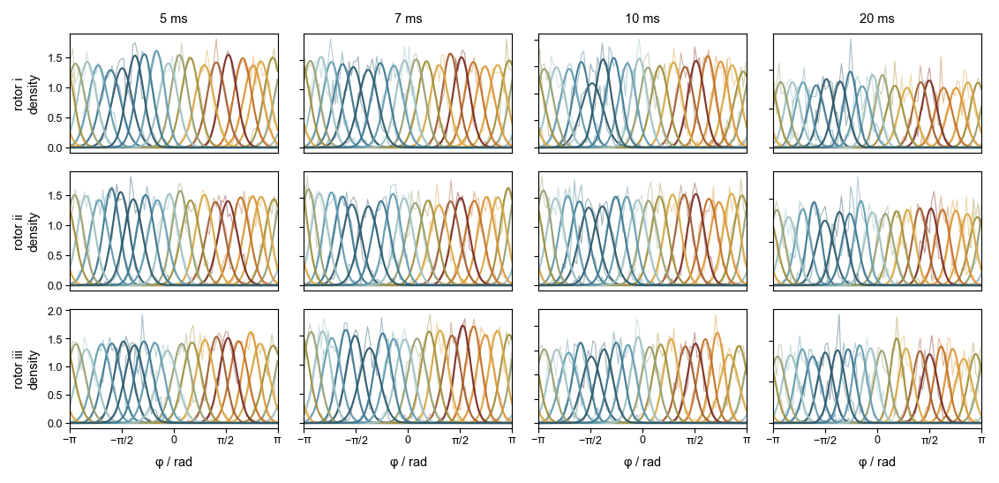

C:\Users\ga78vok\AppData\Local\Temp\ipykernel_20788\2660476229.py:1098: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


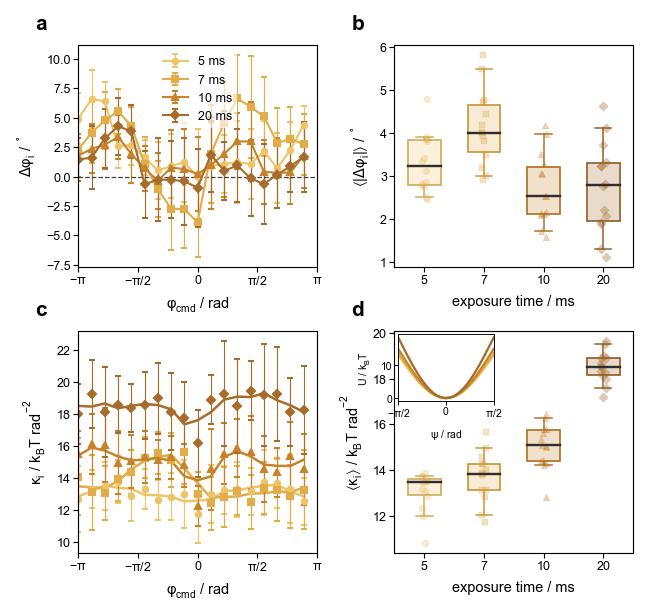

In [14]:
calibration_frame_time_colors = {
    5:  (238 / 255, 196 / 255, 105 / 255),
    7:  (226 / 255, 172 / 255, 72 / 255),
    10: (198 / 255, 131 / 255, 41 / 255),
    20: (166 / 255, 108 / 255, 44 / 255),
}

target_frame_time_colors = {
    5:  (220 / 255, 237 / 255, 235 / 255),
    7:  (190 / 255, 220 / 255, 218 / 255),
    10: (111 / 255, 166 / 255, 166 / 255),
    20: (46 / 255, 89 / 255, 108 / 255),
}

frame_time_markers = {
    5: "o",
    7: "s",
    10: "^",
    20: "D",
}


filter_calibration_rotors_frame_time(
    m_list=m_list,
    calibration_frame_time_colors=calibration_frame_time_colors,
    target_frame_time_colors=target_frame_time_colors,
    frame_time_markers=frame_time_markers,

    selection_frame_time_ms=5,

    min_locs_per_window=20,
    min_valid_window_fraction=0.80,

    min_Rbar=0.55,

    min_kappa=0.50,
    max_kappa=30.0,
    max_kappa_std=3.0,
    max_kappa_cv=0.25,
    max_kappa_fold=20,

    max_center_error_deg=15.0,
    max_center_rmse_deg=12.0,
    max_center_error_range_deg=25.0,

    min_tracking_corr=0.97,
    min_tracking_slope=0.90,
    max_tracking_slope=1.10,

    # Do not reject the expected frame-time-dependent change in kappa.
    max_cross_kappa_cv=None,
    max_cross_window_kappa_cv=None,
    max_cross_mu_rmse_deg=8.0,

    ensemble_center_mad=3.5,
    ensemble_kappa_mad=3.5,

    max_mean_abs_steering_error_deg=None,

    make_rawfigure=True,
    make_summaryfigure=True,
    max_raw_particles=3,
    raw_particle_sort="best",
    raw_hist_bins=90,
    rolling_mean_n=3,

    store_candidate_diagnostics=True,

    save_dir=save_dir_SI,
    raw_fig_name="SI_toFig3_exposuretime__calibration_rotors_frame_time_rawdata",
    summary_fig_name="SI_toFig3_exposuretime__calibration_rotors_frame_time_summary",
    stator_variant=stator_variant,

    raw_fig_width_mm=180,
    raw_panel_height_mm=25,
    summary_fig_width_mm=110,
    summary_fig_height_mm=100,

    fontsize=7,
    axis_label_size=7,
    tick_label_size=6,

    box_point_size=10,
    box_point_alpha=0.35,
    box_face_alpha=0.24,

    summary_panel_labels=("a", "b", "c", "d", "e", "f"),
    summary_panel_label_fontsize=10,
    summary_panel_label_fontfamily="Arial",
    summary_panel_label_fontweight="bold",

    C=CK_colors,
)

# for m in m_list:
#     m.calibration_rotors = m.calibration_rotors[1::]

## Estimate consensus trim time for umbrella windows with restraint potentials for target rotors

#### i. Check autocorrelation function per rotor / window

In [15]:
def calc_autocorrelation_times(
    m_list,
    include_diff=True,
    min_locs_for_tau=500,
    max_lag_s=1.0,
    f_trim=2.0,
):
    """
    Compute autocorrelation times for angular traces.

    Stored on each measurement:
        m.autocorrelation_df
        m.autocorrelation_trim_s

    The trim is measurement-specific:
        m.autocorrelation_trim_s = f_trim * q75(tau_s over UMB rows of this m)

    DIFF rows can be stored in m.autocorrelation_df, but DIFF is never used
    to determine m.autocorrelation_trim_s.
    """

    import re
    import numpy as np
    import pandas as pd
    from pathlib import Path

    particle_col = "group"
    phi_col = "phi"
    phi0_offset_rad = -np.pi / 2

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def measurement_name(m, i=None):
        try:
            return Path(str(m.path)).name
        except Exception:
            return f"m_list[{i}]" if i is not None else "unknown measurement"

    def path_string(m):
        try:
            return str(m.path)
        except Exception:
            return ""

    def parse_voltage(m):
        s = path_string(m)
        matches = re.findall(
            r"(?<!\d)(\d+(?:\.\d+)?)\s*V(?![A-Za-z])",
            s,
            flags=re.IGNORECASE,
        )
        if not matches:
            return np.nan
        return float(matches[-1])

    def voltage_label(v):
        if not np.isfinite(v):
            return "unknownV"
        if float(v).is_integer():
            return f"{int(v)}V"
        return f"{float(v):g}V"

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2.0 * np.pi) - np.pi

    def as_int_list(x):
        if x is None:
            return []
        try:
            return sorted(set(int(v) for v in list(x)))
        except Exception:
            try:
                return [int(x)]
            except Exception:
                return []

    def ensure_group_int(m):
        if "group_int" not in m.locs.columns:
            if particle_col not in m.locs.columns:
                raise KeyError(f"{measurement_name(m)} needs m.locs['{particle_col}'].")
            m.locs["group_int"] = m.locs[particle_col].astype(int)

    def ensure_time_column(m):
        if not hasattr(m, "locs") or m.locs is None:
            raise ValueError("m.locs is missing.")

        if "t" in m.locs.columns:
            return

        if "averagetime" in m.locs.columns:
            m.locs["t"] = m.locs["averagetime"].astype(float)
            return

        if "time" in m.locs.columns:
            m.locs["t"] = m.locs["time"].astype(float)
            return

        if "time_s" in m.locs.columns:
            m.locs["t"] = m.locs["time_s"].astype(float)
            return

        if "frame" in m.locs.columns and hasattr(m, "_average_tpf"):
            m.locs["t"] = m.locs["frame"].astype(float) * float(m._average_tpf)
            return

        if "frame" in m.locs.columns and hasattr(m, "fps"):
            m.locs["t"] = m.locs["frame"].astype(float) / float(m.fps)
            return

        raise ValueError("Need t, averagetime, time, time_s, or frame + _average_tpf/fps.")

    def infer_dt_default(m):
        for attr in ["_average_tpf", "average_tpf"]:
            if hasattr(m, attr):
                try:
                    dt = float(getattr(m, attr))
                    if np.isfinite(dt) and dt > 0:
                        return dt
                except Exception:
                    pass

        if hasattr(m, "fps"):
            try:
                fps = float(getattr(m, "fps"))
                if np.isfinite(fps) and fps > 0:
                    return 1.0 / fps
            except Exception:
                pass

        return 0.005

    def protocol_bounds(value):
        while (
            isinstance(value, (list, tuple))
            and len(value) == 1
            and isinstance(value[0], (list, tuple, dict))
        ):
            value = value[0]

        if isinstance(value, dict):
            t0 = value.get("start", value.get("t0", value.get("t_start", None)))
            t1 = value.get("end", value.get("t1", value.get("t_end", value.get("stop", None))))

            if t0 is None or t1 is None:
                raise ValueError(f"Cannot parse protocol bounds from {value}")

            return float(t0), float(t1)

        if isinstance(value, (tuple, list)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds from {value}")

    def circular_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.nan

        z = np.mean(np.exp(1j * phi))

        if np.abs(z) < 1e-15:
            return np.nan

        return float(np.angle(z))

    def acf_fft(x, max_lag):
        x = np.asarray(x, dtype=float)
        x = x[np.isfinite(x)]

        n = x.size

        if n < 4:
            return np.array([1.0]), np.array([0])

        x = x - np.mean(x)
        var = np.var(x)

        if not np.isfinite(var) or var <= 1e-30:
            return np.ones(1), np.array([0])

        nfft = 1 << (2 * n - 1).bit_length()
        fx = np.fft.fft(x, n=nfft)
        acf = np.fft.ifft(fx * np.conjugate(fx)).real[:n]
        acf = acf / (var * np.arange(n, 0, -1))
        acf = acf / acf[0]

        max_lag = int(min(max_lag, n - 1))
        lags = np.arange(max_lag + 1)

        return acf[: max_lag + 1], lags

    def tau_from_acf(acf, dt):
        acf = np.asarray(acf, dtype=float)

        if acf.size < 2:
            return float(dt), 1.0

        rho = acf[1:].copy()
        rho = rho[np.isfinite(rho)]

        if rho.size == 0:
            g = 1.0
        else:
            first_non_positive = np.where(rho <= 0)[0]
            if first_non_positive.size:
                rho = rho[: first_non_positive[0]]

            rho = rho[np.isfinite(rho)]

            if rho.size == 0:
                g = 1.0
            else:
                g = 1.0 + 2.0 * np.sum(rho)

        g = float(max(g, 1.0))
        tau_s = float(0.5 * g * dt)

        return tau_s, g

    def get_particle_radius_dict(m):
        radius = {}
        pdata = getattr(m, "particle_data", None)

        if pdata is None:
            return radius

        if isinstance(pdata, pd.DataFrame):
            if "R" not in pdata.columns:
                return radius

            for idx, row in pdata.iterrows():
                try:
                    radius[int(idx)] = float(row["R"])
                except Exception:
                    pass

            if "group" in pdata.columns:
                for _, row in pdata.iterrows():
                    try:
                        radius[int(row["group"])] = float(row["R"])
                    except Exception:
                        pass

            return radius

        if isinstance(pdata, dict):
            if "R" not in pdata:
                return radius

            R = pdata["R"]

            if isinstance(R, dict):
                for k, v in R.items():
                    try:
                        radius[int(k)] = float(v)
                    except Exception:
                        pass
                return radius

            try:
                arr = np.asarray(R, dtype=float)
                for i, val in enumerate(arr):
                    if np.isfinite(val):
                        radius[int(i)] = float(val)
            except Exception:
                pass

        return radius

    def get_particles_and_classes(m):
        whitelist = as_int_list(getattr(m, "whitelist", None))

        if not whitelist:
            if hasattr(m, "locs") and m.locs is not None and "group_int" in m.locs.columns:
                whitelist = sorted(set(m.locs["group_int"].astype(int).tolist()))
            elif hasattr(m, "locs") and m.locs is not None and particle_col in m.locs.columns:
                whitelist = sorted(set(m.locs[particle_col].astype(int).tolist()))

        whitelist = sorted(set(int(p) for p in whitelist))

        calibration = set(as_int_list(getattr(m, "calibration_rotors", None)))
        target = set(as_int_list(getattr(m, "target_rotors", None)))

        overlap = calibration & target
        if overlap:
            raise ValueError(
                f"{measurement_name(m)} has rotors in both m.calibration_rotors and "
                f"m.target_rotors: {sorted(overlap)}"
            )

        class_by_particle = {}

        for p in whitelist:
            if p in calibration:
                class_by_particle[int(p)] = "calibration"
            elif p in target:
                class_by_particle[int(p)] = "target"
            else:
                class_by_particle[int(p)] = "other"

        return whitelist, class_by_particle

    def iter_phases(m):
        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            raise ValueError(f"{measurement_name(m)} needs m.protocol.")

        phases = []

        for label, value in m.protocol.items():
            if not isinstance(label, str) or not label.startswith("deg-"):
                continue

            try:
                deg = float(label.split("-")[1])
                start, stop = protocol_bounds(value)
            except Exception:
                continue

            deg_display = ((deg + 180.0) % 360.0) - 180.0
            phi0 = float(wrap_pi(np.deg2rad(deg_display) + phi0_offset_rad))

            phases.append({
                "phase": str(label),
                "phase_type": "umbrella",
                "window_index": None,
                "deg": float(deg),
                "deg_display": float(deg_display),
                "phi0": float(phi0),
                "start": float(start),
                "stop": float(stop),
            })

        phases = sorted(phases, key=lambda d: d["deg"])

        for i, row in enumerate(phases):
            row["window_index"] = int(i)

        if include_diff and "diff" in m.protocol:
            start, stop = protocol_bounds(m.protocol["diff"])
            phases.insert(0, {
                "phase": "diff",
                "phase_type": "diff",
                "window_index": -1,
                "deg": np.nan,
                "deg_display": np.nan,
                "phi0": np.nan,
                "start": float(start),
                "stop": float(stop),
            })

        return phases

    def compute_row(
        m,
        measurement_index,
        particle,
        rotor_class,
        radius_dict,
        phase_info,
        t_particle,
        phi_particle,
        dt_default,
        voltage,
        vlabel,
    ):
        start = float(phase_info["start"])
        stop = float(phase_info["stop"])

        sel = (t_particle >= start) & (t_particle < stop)

        if not np.any(sel):
            return None

        t = t_particle[sel] - start
        phi = wrap_pi(phi_particle[sel])

        order = np.argsort(t, kind="mergesort")
        t = t[order]
        phi = phi[order]

        n_locs = int(phi.size)

        if n_locs < int(min_locs_for_tau):
            return None

        if t.size >= 3:
            dt = float(np.nanmedian(np.diff(t)))
            if not np.isfinite(dt) or dt <= 0:
                dt = float(dt_default)
        else:
            dt = float(dt_default)

        if phase_info["phase_type"] == "umbrella":
            psi = wrap_pi(phi - float(phase_info["phi0"]))
        else:
            mu = circular_mean(phi)
            if np.isfinite(mu):
                psi = wrap_pi(phi - mu)
            else:
                psi = wrap_pi(phi)

        max_lag = int(max(1, min(n_locs - 1, np.ceil(float(max_lag_s) / float(dt)))))
        acf, lags = acf_fft(psi, max_lag=max_lag)
        tau_s, g_stat = tau_from_acf(acf, dt)

        return {
            "measurement_index": int(measurement_index),
            "measurement_name": measurement_name(m, measurement_index),
            "voltage": float(voltage) if np.isfinite(voltage) else np.nan,
            "voltage_label": str(vlabel),
            "particle": int(particle),
            "rotor_class": str(rotor_class),
            "R_nm": float(radius_dict.get(int(particle), np.nan)),
            "phase": str(phase_info["phase"]),
            "phase_type": str(phase_info["phase_type"]),
            "window_index": int(phase_info["window_index"]),
            "deg": float(phase_info["deg"]) if np.isfinite(phase_info["deg"]) else np.nan,
            "deg_display": float(phase_info["deg_display"]) if np.isfinite(phase_info["deg_display"]) else np.nan,
            "phase_start_s": float(start),
            "phase_stop_s": float(stop),
            "phase_duration_s": float(stop - start),
            "n_locs": int(n_locs),
            "dt_s": float(dt),
            "max_lag_s": float(max_lag * dt),
            "tau_s": float(tau_s),
            "tau_rho_s": float(tau_s),
            "tau_int_s": float(tau_s),
            "g_statistical_inefficiency": float(g_stat),
        }

    m_flat = flatten(m_list)

    for measurement_index, m in enumerate(m_flat):
        if not hasattr(m, "locs") or m.locs is None:
            continue

        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            continue

        phases = iter_phases(m)

        if len(phases) == 0:
            continue

        ensure_time_column(m)
        ensure_group_int(m)

        if phi_col not in m.locs.columns:
            raise KeyError(f"{measurement_name(m, measurement_index)}: m.locs needs '{phi_col}'.")

        particles, class_by_particle = get_particles_and_classes(m)

        if len(particles) == 0:
            m.autocorrelation_df = pd.DataFrame()
            m.autocorrelation_trim_s = np.nan
            continue

        radius_dict = get_particle_radius_dict(m)
        voltage = parse_voltage(m)
        vlabel = voltage_label(voltage)
        dt_default = infer_dt_default(m)

        g_all = m.locs["group_int"].to_numpy(dtype=int, copy=False)
        t_all = m.locs["t"].to_numpy(dtype=float, copy=False)
        phi_all = wrap_pi(m.locs[phi_col].to_numpy(dtype=float, copy=False))

        ok = np.isfinite(t_all) & np.isfinite(phi_all)
        ok &= np.isin(g_all, np.asarray(particles, dtype=int))

        g_all = g_all[ok]
        t_all = t_all[ok]
        phi_all = phi_all[ok]

        rows = []

        for particle in particles:
            psel = g_all == int(particle)

            if not np.any(psel):
                continue

            t_particle = t_all[psel]
            phi_particle = phi_all[psel]

            for phase_info in phases:
                row = compute_row(
                    m=m,
                    measurement_index=measurement_index,
                    particle=int(particle),
                    rotor_class=class_by_particle[int(particle)],
                    radius_dict=radius_dict,
                    phase_info=phase_info,
                    t_particle=t_particle,
                    phi_particle=phi_particle,
                    dt_default=dt_default,
                    voltage=voltage,
                    vlabel=vlabel,
                )

                if row is not None:
                    rows.append(row)

        df = pd.DataFrame(rows)

        if len(df):
            d_umb = df[df["phase_type"].astype(str) == "umbrella"].copy()
            tau_vals = d_umb["tau_s"].to_numpy(float) if len(d_umb) else np.array([], dtype=float)
            tau_vals = tau_vals[np.isfinite(tau_vals) & (tau_vals > 0)]

            if tau_vals.size:
                measurement_trim_s = float(f_trim) * float(np.nanquantile(tau_vals, 0.75))
            else:
                measurement_trim_s = np.nan
        else:
            measurement_trim_s = np.nan

        m.autocorrelation_df = df
        m.autocorrelation_trim_s = measurement_trim_s

    return None

In [16]:
calc_autocorrelation_times(
    m_list=m_list,
    include_diff=True,
    min_locs_for_tau=t_UMB*0.5,
    max_lag_s=1.0,
    f_trim=2.0,
)


#### ii. Plot autocorrelation overview across measurements

In [17]:
def plot_autocorrelation_from_measurements(
    m_list,
    rotor_classes=('calibration', 'target'),
    include_diff_column=False,
    show_other_rotors=False,
    n_max_rotors_per_subset=20,
    max_lag_s=0.5,
    acf_grid_n=160,
    random_seed=7,
    stator_variant=None,
    save_dir=None,
    save_prefix='SI_exposure_time_autocorrelation_curves',
    fig_width_mm=180,
    fig_height_mm=78,
    fontsize=8,
    axis_label_size=None,
    tick_label_size=None,
    title_size=None,
    annotation_size=None,
    calibration_exposure_time_colors=None,
    target_exposure_time_colors=None,
    diff_calibration_color=(0.68, 0.68, 0.68),
    diff_target_color=(0.30, 0.30, 0.30),
    other_color=(0.45, 0.45, 0.45),
    summary_ylim_calibration_s=(0, 0.12),
    summary_ylim_target_s=(0, 0.30),
    summary_column_width=1.16,
    summary_spacer_width=0.18,
    summary_hspace=0.08,
    summary_ytick_step_s=0.1,
    panel_labels=('a', 'b', 'c', 'd'),
    panel_label_fontsize=10,
    panel_label_fontfamily='Arial',
    panel_label_fontweight='bold',
    acf_panel_label_x_rel=-0.20,
    summary_panel_label_x_rel=-0.28,
    panel_label_y_rel=0.04,
    C=CK_colors,
):
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.gridspec import GridSpec

    particle_col = 'group'
    phi_col = 'phi'
    phi0_offset_rad = -np.pi / 2
    default_dt_s = 0.005

    C = C() if callable(C) else dict(C)
    axis_label_size = fontsize if axis_label_size is None else axis_label_size
    tick_label_size = fontsize - 1 if tick_label_size is None else tick_label_size
    title_size = fontsize if title_size is None else title_size
    annotation_size = fontsize - 2 if annotation_size is None else annotation_size

    if calibration_exposure_time_colors is None:
        calibration_exposure_time_colors = {
            5: (246 / 255, 207 / 255, 121 / 255),
            7: (225 / 255, 165 / 255, 64 / 255),
            10: (188 / 255, 112 / 255, 29 / 255),
            20: (166 / 255, 108 / 255, 44 / 255),
        }

    if target_exposure_time_colors is None:
        target_exposure_time_colors = {
            5: (190 / 255, 220 / 255, 218 / 255),
            7: (111 / 255, 166 / 255, 166 / 255),
            10: (73 / 255, 139 / 255, 167 / 255),
            20: (46 / 255, 89 / 255, 108 / 255),
        }

    calibration_exposure_time_colors = {float(k): v for k, v in calibration_exposure_time_colors.items()}
    target_exposure_time_colors = {float(k): v for k, v in target_exposure_time_colors.items()}

    rotor_classes = [str(rotor_class) for rotor_class in rotor_classes]

    if show_other_rotors and 'other' not in rotor_classes:
        rotor_classes.append('other')

    if not show_other_rotors:
        rotor_classes = [rotor_class for rotor_class in rotor_classes if rotor_class != 'other']

    rng = np.random.default_rng(int(random_seed))

    def mm_to_inch(value):
        return float(value) / 25.4

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            return [item for sub in obj for item in flatten(sub)]
        return [obj]

    def prefixed_name(name):
        if stator_variant is None or not str(stator_variant).strip():
            return str(name)
        return f'{str(stator_variant).strip()}__{name}'

    def path_string(m):
        try:
            return str(m.path)
        except Exception:
            return ''

    def measurement_name(m):
        return Path(path_string(m)).name

    def is_umb_measurement(m):
        name = measurement_name(m).upper()
        protocol = getattr(m, 'protocol', None)

        if 'UMB' in name:
            return True

        if 'DIFF' in name and 'UMB' not in name:
            return False

        return isinstance(protocol, dict) and any(
            isinstance(key, str) and key.lower().startswith('deg-')
            for key in protocol
        )

    def is_standalone_diff_measurement(m):
        name = measurement_name(m).upper()
        protocol = getattr(m, 'protocol', None)

        if is_umb_measurement(m):
            return False

        if 'DIFF' in name:
            return True

        if isinstance(protocol, dict):
            has_diff = any(str(key).lower() == 'diff' for key in protocol)
            has_windows = any(
                isinstance(key, str) and key.lower().startswith('deg-')
                for key in protocol
            )
            return has_diff and not has_windows

        return False

    def parse_exposure_time_ms(m):
        name = measurement_name(m)

        patterns = [
            r'(?<!\d)(\d+(?:\.\d+)?)\s*ms(?![A-Za-z])',
            r'_(\d+(?:\.\d+)?)ms(?:_|-|\.|$)',
        ]

        for pattern in patterns:
            matches = re.findall(pattern, name, flags=re.IGNORECASE)
            if matches:
                return float(matches[-1])

        return np.nan

    def exposure_time_label(exposure_time_ms):
        if not np.isfinite(exposure_time_ms):
            return 'unknown'

        exposure_time_ms = float(exposure_time_ms)

        if exposure_time_ms.is_integer():
            return f'{int(exposure_time_ms)} ms'

        return f'{exposure_time_ms:g} ms'

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def circular_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.nan

        z = np.mean(np.exp(1j * phi))
        return np.nan if np.abs(z) < 1e-15 else float(np.angle(z))

    def nearest_color_key(exposure_time_ms, color_dict):
        if not np.isfinite(exposure_time_ms) or not color_dict:
            return None

        keys = np.asarray(sorted(color_dict), dtype=float)
        return float(keys[np.argmin(np.abs(keys - float(exposure_time_ms)))])

    def first_color(color_dict, fallback):
        if not color_dict:
            return fallback
        return color_dict[float(sorted(color_dict)[0])]

    def class_panel_color(rotor_class, panel_kind, exposure_time_ms):
        rotor_class = str(rotor_class)

        if panel_kind == 'diff':
            if rotor_class == 'calibration':
                return diff_calibration_color
            if rotor_class == 'target':
                return diff_target_color
            return other_color

        if rotor_class == 'calibration':
            key = nearest_color_key(exposure_time_ms, calibration_exposure_time_colors)
            return calibration_exposure_time_colors.get(
                key,
                first_color(calibration_exposure_time_colors, (0.6, 0.6, 0.6)),
            )

        if rotor_class == 'target':
            key = nearest_color_key(exposure_time_ms, target_exposure_time_colors)
            return target_exposure_time_colors.get(
                key,
                first_color(target_exposure_time_colors, (0.5, 0.5, 0.5)),
            )

        return other_color

    def style_axis(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.55)
            spine.set_color('black')

        ax.tick_params(
            length=2,
            width=0.55,
            labelsize=tick_label_size,
            color='black',
            labelcolor='black',
            pad=1.4,
        )
        ax.grid(False)

    def ensure_group_int(m):
        if 'group_int' in m.locs.columns:
            return

        if particle_col not in m.locs.columns:
            raise KeyError("m.locs needs column 'group'.")

        m.locs['group_int'] = m.locs[particle_col].astype(int)

    def ensure_time_column(m):
        if 't' in m.locs.columns:
            return

        for source_col in ['averagetime', 'time', 'time_s']:
            if source_col in m.locs.columns:
                m.locs['t'] = m.locs[source_col].astype(float)
                return

        if 'frame' in m.locs.columns:
            dt_here = float(getattr(m, '_average_tpf', getattr(m, 'average_tpf', default_dt_s)))
            m.locs['t'] = m.locs['frame'].astype(float) * dt_here
            return

        raise ValueError('Need t, averagetime, time, time_s, or frame.')

    def acf_fft_regularized(x, max_lag):
        x = np.asarray(x, dtype=float)
        x = x[np.isfinite(x)]

        if x.size < 4:
            return np.array([1.0]), np.array([0])

        x = x - np.mean(x)
        variance = np.var(x)

        if not np.isfinite(variance) or variance <= 1e-30:
            return np.ones(1), np.array([0])

        n = x.size
        max_lag = int(min(max_lag, n - 1))
        nfft = 1 << (2 * n - 1).bit_length()
        fx = np.fft.fft(x, n=nfft)
        acf = np.fft.ifft(fx * np.conjugate(fx)).real[:n]
        acf = acf / (variance * np.arange(n, 0, -1))
        acf = acf / acf[0]

        return acf[:max_lag + 1], np.arange(max_lag + 1)

    def interpolate_to_grid(lag_s, acf, lag_grid):
        lag_s = np.asarray(lag_s, dtype=float)
        acf = np.asarray(acf, dtype=float)

        keep = np.isfinite(lag_s) & np.isfinite(acf) & (lag_s > 0)

        if np.sum(keep) < 3:
            return None

        lag_s = lag_s[keep]
        acf = acf[keep]
        order = np.argsort(lag_s, kind='mergesort')
        lag_s = lag_s[order]
        acf = acf[order]

        interpolated = np.interp(lag_grid, lag_s, acf, left=np.nan, right=np.nan)
        return interpolated if np.isfinite(interpolated).any() else None

    def robust_summary(curves):
        if not curves:
            return None

        values = np.vstack(curves)
        median = np.full(values.shape[1], np.nan)

        for index in range(values.shape[1]):
            x = values[:, index]
            x = x[np.isfinite(x)]

            if x.size:
                median[index] = np.median(x)

        return median if np.isfinite(median).any() else None

    def get_phi_trace_from_locs(m, particle, row):
        ensure_time_column(m)
        ensure_group_int(m)

        if phi_col not in m.locs.columns:
            raise KeyError("m.locs needs column 'phi'.")

        start = float(row['phase_start_s'])
        stop = float(row['phase_stop_s'])

        data = m.locs.loc[
            m.locs['group_int'].astype(int) == int(particle),
            ['group_int', 't', phi_col],
        ].copy()

        if len(data) == 0:
            return None

        time = data['t'].to_numpy(float)
        phi = wrap_pi(data[phi_col].to_numpy(float))
        keep = np.isfinite(time) & np.isfinite(phi) & (time >= start) & (time < stop)

        if not np.any(keep):
            return None

        time = time[keep] - start
        phi = phi[keep]
        order = np.argsort(time, kind='mergesort')
        time = time[order]
        phi = phi[order]

        if len(phi) < 4:
            return None

        if str(row['phase_type']).lower() == 'umbrella':
            deg_display = float(row['deg_display'])
            phi0 = float(wrap_pi(np.deg2rad(deg_display) + phi0_offset_rad))
            psi = wrap_pi(phi - phi0)
        else:
            mu = circular_mean(phi)
            psi = wrap_pi(phi - mu) if np.isfinite(mu) else wrap_pi(phi)

        psi = psi - np.nanmean(psi)
        dt_trace_s = float(np.nanmedian(np.diff(time))) if len(time) > 1 else default_dt_s

        if not np.isfinite(dt_trace_s) or dt_trace_s <= 0:
            dt_trace_s = default_dt_s

        return time, psi, dt_trace_s

    def get_tau_col(df):
        for column in ['tau_s', 'tau_rho_s', 'tau_int_s']:
            if column in df.columns:
                return column

        raise KeyError(
            'm.autocorrelation_df needs tau_s, tau_rho_s, or tau_int_s.'
        )

    def collect_panel_items(measurements):
        measurements = flatten(measurements)
        items = []

        if include_diff_column:
            diff_rows = []

            for measurement_index, m in enumerate(measurements):
                if not is_standalone_diff_measurement(m):
                    continue

                df = getattr(m, 'autocorrelation_df', None)

                if df is None or len(df) == 0:
                    continue

                data = df.copy()
                data = data[data['phase_type'].astype(str).str.lower() == 'diff'].copy()
                data = data[data['rotor_class'].astype(str).isin(rotor_classes)].copy()

                if len(data) == 0:
                    continue

                data['_source_measurement_index'] = int(measurement_index)
                data['_source_measurement_object'] = [m] * len(data)
                diff_rows.append(data)

            if not diff_rows:
                raise ValueError(
                    "include_diff_column=True, but no standalone DIFF "
                    "measurement containing phase_type == 'diff' was found."
                )

            items.append({
                'panel_index': 0,
                'measurement_index': -1,
                'measurement': None,
                'label': 'diffusion',
                'data': pd.concat(diff_rows, ignore_index=True),
                'panel_kind': 'diff',
                'exposure_time_ms': np.nan,
            })

        umbrella_items = []

        for measurement_index, m in enumerate(measurements):
            if not is_umb_measurement(m):
                continue

            df = getattr(m, 'autocorrelation_df', None)

            if df is None or len(df) == 0:
                continue

            data = df.copy()
            data = data[data['phase_type'].astype(str).str.lower() == 'umbrella'].copy()
            data = data[data['rotor_class'].astype(str).isin(rotor_classes)].copy()

            if len(data) == 0:
                continue

            exposure_time_ms = parse_exposure_time_ms(m)

            if not np.isfinite(exposure_time_ms):
                raise ValueError(
                    f'Could not determine exposure time from filename: '
                    f'{measurement_name(m)}'
                )

            data['_source_measurement_index'] = int(measurement_index)
            data['_source_measurement_object'] = [m] * len(data)

            umbrella_items.append({
                'measurement_index': int(measurement_index),
                'measurement': m,
                'label': exposure_time_label(exposure_time_ms),
                'data': data,
                'panel_kind': 'umbrella',
                'exposure_time_ms': float(exposure_time_ms),
            })

        umbrella_items = sorted(
            umbrella_items,
            key=lambda item: (
                item['exposure_time_ms'],
                measurement_name(item['measurement']),
            ),
        )

        for item in umbrella_items:
            item['panel_index'] = len(items)
            items.append(item)

        return items

    def make_exposure_time_boxplot(
        ax,
        tau_df_plot,
        rotor_class,
        show_xaxis,
        ylim_s=None,
        ytick_step_s=0.1,
    ):
        data = tau_df_plot[
            tau_df_plot['rotor_class'].astype(str) == str(rotor_class)
        ].copy()

        ax.set_ylabel(
            f'{rotor_class}\n' + r'$\tau$ / s',
            fontsize=axis_label_size,
        )

        if len(data) == 0:
            ax.text(
                0.5,
                0.5,
                f'no {rotor_class} data',
                transform=ax.transAxes,
                ha='center',
                va='center',
                fontsize=annotation_size,
            )

            if ylim_s is not None:
                ax.set_ylim(float(ylim_s[0]), float(ylim_s[1]))

            if not show_xaxis:
                ax.set_xticks([])

            style_axis(ax)
            return

        exposure_times = sorted(set(
            data.loc[
                (data['panel_kind'].astype(str) == 'umbrella')
                & np.isfinite(data['exposure_time_ms'].astype(float)),
                'exposure_time_ms',
            ].astype(float)
        ))

        categories = []

        if np.any(data['panel_kind'].astype(str) == 'diff'):
            categories.append({
                'label': 'diff.',
                'panel_kind': 'diff',
                'exposure_time_ms': np.nan,
            })

        categories.extend([
            {
                'label': f'{int(value)}' if float(value).is_integer() else f'{value:g}',
                'panel_kind': 'umbrella',
                'exposure_time_ms': float(value),
            }
            for value in exposure_times
        ])

        positions = np.arange(1, len(categories) + 1, dtype=float)
        box_data = []
        colors = []

        for category in categories:
            if category['panel_kind'] == 'diff':
                values = data.loc[
                    data['panel_kind'].astype(str) == 'diff',
                    'tau_s',
                ].to_numpy(float)

                color = class_panel_color(rotor_class, 'diff', np.nan)
            else:
                values = data.loc[
                    (data['panel_kind'].astype(str) == 'umbrella')
                    & np.isclose(
                        data['exposure_time_ms'].astype(float),
                        category['exposure_time_ms'],
                    ),
                    'tau_s',
                ].to_numpy(float)

                color = class_panel_color(
                    rotor_class,
                    'umbrella',
                    category['exposure_time_ms'],
                )

            values = values[np.isfinite(values) & (values > 0)]
            box_data.append(values)
            colors.append(color)

        for position, values, color in zip(positions, box_data, colors):
            if values.size == 0:
                continue

            jitter = np.clip(
                rng.normal(0, 0.055, size=values.size),
                -0.14,
                0.14,
            )

            ax.scatter(
                np.full(values.size, position) + jitter,
                values,
                s=7,
                facecolor=color,
                edgecolor='none',
                alpha=0.28,
                rasterized=True,
                zorder=1,
            )

        nonempty = [
            (position, values, color)
            for position, values, color in zip(positions, box_data, colors)
            if values.size > 0
        ]

        if nonempty:
            boxplot = ax.boxplot(
                [item[1] for item in nonempty],
                positions=[item[0] for item in nonempty],
                widths=0.55,
                patch_artist=True,
                showfliers=False,
                whis=(5, 95),
                medianprops={'color': 'black', 'linewidth': 0.85},
                whiskerprops={'color': 'black', 'linewidth': 0.55},
                capprops={'color': 'black', 'linewidth': 0.55},
                boxprops={'color': 'black', 'linewidth': 0.55},
            )

            for patch, item in zip(boxplot['boxes'], nonempty):
                patch.set_facecolor(item[2])
                patch.set_alpha(0.55)

        ax.set_xlim(0.45, len(categories) + 0.55)

        if ylim_s is not None:
            ax.set_ylim(float(ylim_s[0]), float(ylim_s[1]))

        if ytick_step_s is not None and float(ytick_step_s) > 0:
            ymin, ymax = ax.get_ylim()
            step = float(ytick_step_s)
            ticks = np.arange(np.ceil(ymin / step) * step, ymax + 0.5 * step, step)
            ax.set_yticks(ticks)

        ax.set_xticks(positions)

        if show_xaxis:
            ax.set_xticklabels([category['label'] for category in categories])
            ax.set_xlabel('exposure time / ms', fontsize=axis_label_size)
        else:
            ax.set_xticklabels([])
            ax.tick_params(axis='x', which='both', bottom=False, labelbottom=False)
            ax.set_xlabel('')

        style_axis(ax)

    panel_items = collect_panel_items(m_list)

    if len(panel_items) == 0:
        raise ValueError(
            'No usable m.autocorrelation_df found. '
            'Run calc_autocorrelation_times(...) first.'
        )

    required_columns = {
        'particle',
        'rotor_class',
        'phase_type',
        'phase_start_s',
        'phase_stop_s',
    }

    for panel in panel_items:
        missing = sorted(required_columns - set(panel['data'].columns))

        if missing:
            raise ValueError(
                f"m.autocorrelation_df is missing columns: {missing}."
            )

        get_tau_col(panel['data'])

    n_panels = len(panel_items)
    n_rows = len(rotor_classes)

    exposure_times_present = [
        float(panel['exposure_time_ms'])
        for panel in panel_items
        if np.isfinite(panel['exposure_time_ms'])
    ]

    min_lag_s = (
        max(1e-6, min(exposure_times_present) / 1000)
        if exposure_times_present
        else default_dt_s
    )

    if max_lag_s <= min_lag_s:
        raise ValueError(
            f'max_lag_s={max_lag_s} must exceed the shortest exposure '
            f'time, {min_lag_s} s.'
        )

    lag_grid = np.geomspace(
        min_lag_s,
        float(max_lag_s),
        int(acf_grid_n),
    )

    selected_particles_by_subset = {
        (str(rotor_class), int(panel['panel_index'])): set()
        for rotor_class in rotor_classes
        for panel in panel_items
    }

    curves_by_subset = {
        (str(rotor_class), int(panel['panel_index'])): []
        for rotor_class in rotor_classes
        for panel in panel_items
    }

    tau_plot_rows = []

    for panel in panel_items:
        panel_index = int(panel['panel_index'])
        panel_df = panel['data']
        tau_col = get_tau_col(panel_df)

        for rotor_class in rotor_classes:
            subset = panel_df[
                panel_df['rotor_class'].astype(str) == str(rotor_class)
            ].copy()

            if len(subset) == 0:
                continue

            particles = sorted(set(subset['particle'].astype(int)))

            if (
                n_max_rotors_per_subset is not None
                and len(particles) > int(n_max_rotors_per_subset)
            ):
                particles = sorted(
                    rng.choice(
                        np.asarray(particles, dtype=int),
                        size=int(n_max_rotors_per_subset),
                        replace=False,
                    ).astype(int)
                )

            selected_particles_by_subset[
                str(rotor_class),
                panel_index,
            ].update(particles)

            subset = subset[
                subset['particle'].astype(int).isin(particles)
            ].copy()

            for _, row in subset.iterrows():
                particle = int(row['particle'])
                source_measurement = row['_source_measurement_object']
                trace = get_phi_trace_from_locs(
                    source_measurement,
                    particle,
                    row,
                )

                if trace is None:
                    continue

                _, psi, dt_trace_s = trace
                max_lag = int(max(
                    1,
                    min(
                        len(psi) - 1,
                        np.ceil(float(max_lag_s) / dt_trace_s),
                    ),
                ))

                acf, lags = acf_fft_regularized(
                    psi,
                    max_lag=max_lag,
                )

                lag_s = lags.astype(float) * dt_trace_s
                interpolated = interpolate_to_grid(
                    lag_s,
                    acf,
                    lag_grid,
                )

                if interpolated is not None:
                    curves_by_subset[
                        str(rotor_class),
                        panel_index,
                    ].append(interpolated)

                tau_plot_rows.append({
                    'panel_index': panel_index,
                    'measurement_index': int(row['_source_measurement_index']),
                    'measurement_label': str(panel['label']),
                    'panel_kind': str(panel['panel_kind']),
                    'exposure_time_ms': float(panel['exposure_time_ms']),
                    'rotor_class': str(rotor_class),
                    'particle': particle,
                    'phase': str(row['phase']) if 'phase' in row.index else '',
                    'phase_type': str(row['phase_type']),
                    'tau_s': float(row[tau_col]),
                })

    tau_df_plot = pd.DataFrame(tau_plot_rows)

    if len(tau_df_plot) == 0:
        raise ValueError('No ACF curves could be generated.')

    fig = plt.figure(
        figsize=(
            mm_to_inch(fig_width_mm),
            mm_to_inch(fig_height_mm),
        )
    )

    gs = GridSpec(
        n_rows,
        n_panels + 2,
        figure=fig,
        left=0.065,
        right=0.985,
        bottom=0.145,
        top=0.885,
        wspace=0.22,
        hspace=0.08,
        width_ratios=(
            [1.0] * n_panels
            + [float(summary_spacer_width)]
            + [float(summary_column_width)]
        ),
    )

    acf_axes_by_row = {}

    for row_index, rotor_class in enumerate(rotor_classes):
        for column_index, panel in enumerate(panel_items):
            panel_index = int(panel['panel_index'])
            ax = fig.add_subplot(gs[row_index, column_index])

            if column_index == 0:
                acf_axes_by_row[row_index] = ax

            ax.set_rasterization_zorder(2)

            color = class_panel_color(
                rotor_class,
                panel['panel_kind'],
                panel['exposure_time_ms'],
            )

            curves = curves_by_subset.get(
                (str(rotor_class), panel_index),
                [],
            )

            for curve in curves:
                ax.plot(
                    lag_grid,
                    curve,
                    color=color,
                    lw=0.42,
                    alpha=0.16,
                    rasterized=True,
                    zorder=1,
                )

            median_curve = robust_summary(curves)

            if median_curve is not None:
                ax.plot(
                    lag_grid,
                    median_curve,
                    color='black',
                    lw=1.0,
                    ls='--',
                    alpha=0.85,
                    zorder=4,
                )

            rows_here = tau_df_plot[
                (tau_df_plot['rotor_class'].astype(str) == str(rotor_class))
                & (tau_df_plot['panel_index'].astype(int) == panel_index)
            ]

            tau_here = rows_here['tau_s'].to_numpy(float)
            tau_here = tau_here[np.isfinite(tau_here) & (tau_here > 0)]

            if tau_here.size:
                ax.axvline(
                    np.nanmedian(tau_here),
                    color=color,
                    lw=0.9,
                    ls=':',
                    alpha=0.95,
                    zorder=5,
                )

            ax.axhline(
                0,
                color='black',
                lw=0.45,
                alpha=0.35,
            )

            ax.set_xscale('log')
            ax.set_xlim(min_lag_s, float(max_lag_s))
            ax.set_ylim(-0.18, 1.02)
            ax.set_yticks([0, 0.5, 1])
            ax.set_yticklabels(['0', '0.5', '1'])

            if row_index == n_rows - 1:
                ax.set_xlabel(
                    r'$\delta t$ / s',
                    fontsize=axis_label_size,
                )
            else:
                ax.tick_params(
                    axis='x',
                    which='both',
                    labelbottom=False,
                )

            if column_index == 0:
                ax.set_ylabel(
                    f'{rotor_class}\n'
                    + r'$\rho_{\psi\psi}(\delta t)$',
                    fontsize=axis_label_size,
                )
            else:
                ax.set_yticklabels([])

            if row_index == 0:
                ax.set_title(
                    panel['label'],
                    fontsize=title_size,
                    pad=3,
                )

            n_rotors_here = len(
                selected_particles_by_subset.get(
                    (str(rotor_class), panel_index),
                    set(),
                )
            )

            ax.text(
                0.98,
                0.97,
                f'n={n_rotors_here}',
                transform=ax.transAxes,
                ha='right',
                va='top',
                fontsize=annotation_size,
                color='black',
            )

            style_axis(ax)

    summary_gs = gs[:, -1].subgridspec(
        2,
        1,
        hspace=float(summary_hspace),
    )

    ax_summary_calibration = fig.add_subplot(summary_gs[0, 0])
    ax_summary_target = fig.add_subplot(
        summary_gs[1, 0],
        sharex=ax_summary_calibration,
    )

    make_exposure_time_boxplot(
        ax=ax_summary_calibration,
        tau_df_plot=tau_df_plot,
        rotor_class='calibration',
        show_xaxis=False,
        ylim_s=summary_ylim_calibration_s,
        ytick_step_s=0.02,
    )

    make_exposure_time_boxplot(
        ax=ax_summary_target,
        tau_df_plot=tau_df_plot,
        rotor_class='target',
        show_xaxis=True,
        ylim_s=summary_ylim_target_s,
        ytick_step_s=0.1,
    )

    panel_labels = tuple(panel_labels) if panel_labels is not None else ()
    label_axes = [
        acf_axes_by_row.get(0),
        acf_axes_by_row.get(1),
        ax_summary_calibration,
        ax_summary_target,
    ]

    if panel_labels:
        row_y = {}

        for row_index in range(min(2, n_rows)):
            ax_row = acf_axes_by_row.get(row_index)

            if ax_row is not None:
                bbox = ax_row.get_position()
                row_y[row_index] = (
                    bbox.y1
                    + float(panel_label_y_rel) * bbox.height
                )

        for label_index, (label, ax_label) in enumerate(
            zip(panel_labels, label_axes)
        ):
            if (
                ax_label is None
                or label is None
                or not str(label).strip()
            ):
                continue

            bbox = ax_label.get_position()
            row_index = 0 if label_index in (0, 2) else 1

            x_rel = (
                float(acf_panel_label_x_rel)
                if label_index < 2
                else float(summary_panel_label_x_rel)
            )

            y = row_y.get(
                row_index,
                bbox.y1 + float(panel_label_y_rel) * bbox.height,
            )

            fig.text(
                bbox.x0 + x_rel * bbox.width,
                y,
                str(label),
                ha='right',
                va='bottom',
                fontsize=panel_label_fontsize,
                fontfamily=panel_label_fontfamily,
                fontweight=panel_label_fontweight,
                color='black',
            )

    if (
        save_dir is not None
        and save_prefix is not None
        and str(save_prefix).strip()
    ):
        save_dir = Path(save_dir).expanduser()
        save_dir.mkdir(parents=True, exist_ok=True)
        output_name = prefixed_name(save_prefix)

        png_path = save_dir / f'{output_name}.png'
        svg_path = save_dir / f'{output_name}.svg'

        fig.savefig(
            png_path,
            dpi=300,
            bbox_inches='tight',
        )
        fig.savefig(
            svg_path,
            bbox_inches='tight',
        )

        print('Saved:', png_path.resolve())
        print('Saved:', svg_path.resolve())

    plt.show()
    plt.close(fig)
    return None

Saved: \\nas.ads.mwn.de\tuph\e14\users\lweiss\_06_Umbrella_Sampling\02_Figures\Supplementary_Information\to_Figure_3\effect_exposure_time\SI_toFig3_exposuretime__autocorrelation_curves.png
Saved: \\nas.ads.mwn.de\tuph\e14\users\lweiss\_06_Umbrella_Sampling\02_Figures\Supplementary_Information\to_Figure_3\effect_exposure_time\SI_toFig3_exposuretime__autocorrelation_curves.svg


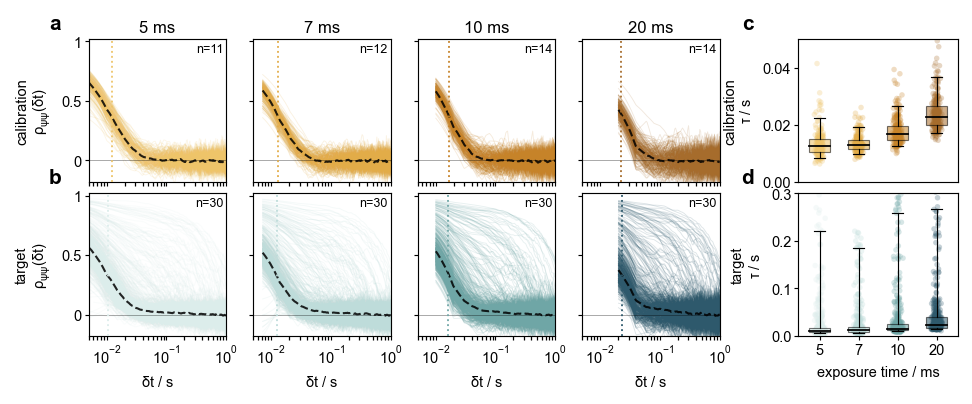

In [18]:
plot_autocorrelation_from_measurements(
    m_list=m_list,
    rotor_classes=('calibration', 'target'),
    include_diff_column=False,
    show_other_rotors=False,
    n_max_rotors_per_subset=30,
    max_lag_s=1,
    acf_grid_n=160,
    random_seed=7,
    calibration_exposure_time_colors=calibration_frame_time_colors,
    target_exposure_time_colors=target_frame_time_colors,

    acf_panel_label_x_rel=-0.20,
    summary_panel_label_x_rel=-0.28,
    panel_label_y_rel=0.04,
    fig_width_mm=160,
    fig_height_mm=68,

    summary_ylim_calibration_s=(0, 0.05),
    summary_ylim_target_s=(0, 0.29),
    
    fontsize=7,
    axis_label_size=7,
    tick_label_size=7,
    title_size=8,
    annotation_size=6,
    stator_variant=stator_variant,
    save_dir=save_dir_SI,
    save_prefix='SI_toFig3_exposuretime__autocorrelation_curves',
    C=CK_colors,
)

## SI | Stationarity and overlap during umbrella sampling 

#### i. Compute stationarity during umbrella windows and overlap of distributions from neighboring windows

In [19]:
def compute_stationarity_overlap_target_rotors(
    m_list,
    min_locs_after_trim=100,
    min_locs_calibration_center=50,
    min_frame_coverage=None,
):
    """
    Compute lean UMB QC metrics for already-defined calibration and target rotors.

    Reads from each UMB measurement:
        m.calibration_rotors
        m.target_rotors
        m.trajectories
        m.protocol
        m.autocorrelation_trim_s

    Stores on each UMB measurement:
        m.voltage_stationarity_overlap_window_df

    Stored table contains only plot-relevant columns:
        measurement_index
        measurement_name
        voltage
        rotor_class
        particle
        phase
        window_index
        deg
        deg_display
        phi0_cmd_deg
        mean_phi_deg
        calib_mean_phi_deg
        command_error_deg
        calib_target_error_deg
        half_overlap
        half_mean_shift_deg
        neighbor_overlap_mean
        neighbor2_overlap_mean

    No radius-based target inference.
    No flat-particle logic.
    No particle summary tables.
    No return objects.
    """

    import re
    import gc
    import numpy as np
    import pandas as pd
    from pathlib import Path

    particle_col = "group"
    phi0_offset_rad = -np.pi / 2
    nbins = 72

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def path_string(m):
        try:
            return str(m.path)
        except Exception:
            return ""

    def measurement_name(m, i=None):
        try:
            return Path(path_string(m)).name
        except Exception:
            return f"m_list[{i}]" if i is not None else "unknown measurement"

    def parse_voltage(m):
        s = path_string(m)
        hits = re.findall(
            r"(?<!\d)(\d+(?:\.\d+)?)\s*V(?![A-Za-z])",
            s,
            flags=re.IGNORECASE,
        )
        if not hits:
            return np.nan

        v = float(hits[-1])
        if abs(v - round(v)) < 1e-9:
            return int(round(v))
        return v

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2.0 * np.pi) - np.pi

    def wrap_deg(x):
        return (np.asarray(x, dtype=float) + 180.0) % 360.0 - 180.0

    def as_int_list(x):
        if x is None:
            return []
        if isinstance(x, (str, bytes)):
            return []
        try:
            return sorted(set(int(v) for v in list(x)))
        except Exception:
            try:
                return [int(x)]
            except Exception:
                return []

    def is_umb(m):
        name = path_string(m).upper()

        if "DIFF" in name:
            return False

        if "UMB" in name:
            return True

        return (
            hasattr(m, "protocol")
            and isinstance(m.protocol, dict)
            and any(isinstance(k, str) and k.startswith("deg-") for k in m.protocol.keys())
        )

    def protocol_bounds(value):
        while (
            isinstance(value, (list, tuple))
            and len(value) == 1
            and isinstance(value[0], (list, tuple, dict))
        ):
            value = value[0]

        if isinstance(value, dict):
            t0 = value.get("start", value.get("start_time", value.get("t_start", value.get("t0", None))))
            t1 = value.get("end", value.get("end_time", value.get("t_end", value.get("t1", value.get("stop", None)))))

            if t0 is None or t1 is None:
                raise ValueError(f"Cannot parse protocol bounds from {value}")

            return float(t0), float(t1)

        if isinstance(value, (tuple, list)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds from {value}")

    def get_deg_windows(m):
        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            raise ValueError("m.protocol is missing or not a dict.")

        rows = []

        for label, value in m.protocol.items():
            if not isinstance(label, str) or not label.startswith("deg-"):
                continue

            try:
                deg = float(label.split("-")[1]) % 360.0
                start, stop = protocol_bounds(value)
            except Exception:
                continue

            phi0_cmd = float(wrap_pi(np.deg2rad(deg) + float(phi0_offset_rad)))

            rows.append({
                "phase": str(label),
                "deg": float(deg),
                "deg_display": float(((deg + 180.0) % 360.0) - 180.0),
                "phi0_cmd_rad": float(phi0_cmd),
                "phi0_cmd_deg": float(np.rad2deg(phi0_cmd)),
                "start": float(start),
                "stop": float(stop),
            })

        if len(rows) == 0:
            raise ValueError("No parseable deg-* umbrella windows found.")

        df = pd.DataFrame(rows).sort_values("phi0_cmd_rad").reset_index(drop=True)
        df["window_index"] = np.arange(len(df), dtype=int)

        return df

    def infer_frame_time(m):
        for attr in ["_average_tpf", "average_tpf"]:
            if hasattr(m, attr):
                try:
                    dt = float(getattr(m, attr))
                    if np.isfinite(dt) and dt > 0:
                        return dt
                except Exception:
                    pass

        if hasattr(m, "fps"):
            try:
                fps = float(getattr(m, "fps"))
                if np.isfinite(fps) and fps > 0:
                    return 1.0 / fps
            except Exception:
                pass

        return 0.005

    def get_trim_s(m):
        trim_s = getattr(m, "autocorrelation_trim_s", np.nan)

        try:
            trim_s = float(trim_s)
        except Exception:
            trim_s = np.nan

        if np.isfinite(trim_s) and trim_s >= 0:
            return trim_s

        return 0.0

    def circular_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.nan

        z = np.mean(np.exp(1j * phi))

        if np.abs(z) < 1e-15:
            return np.nan

        return float(np.angle(z))

    def hist_counts(phi, edges, min_count):
        phi = wrap_pi(phi)
        phi = phi[np.isfinite(phi)]

        if phi.size < int(min_count):
            return np.zeros(len(edges) - 1, dtype=np.int32), 0

        counts, _ = np.histogram(phi, bins=edges, density=False)
        return counts.astype(np.int32), int(phi.size)

    def hist_overlap_from_counts(c1, n1, c2, n2):
        if n1 <= 0 or n2 <= 0:
            return np.nan

        p1 = np.asarray(c1, dtype=float) / float(n1)
        p2 = np.asarray(c2, dtype=float) / float(n2)

        return float(np.sum(np.minimum(p1, p2)))

    def get_rotor_subsets(m):
        calibration = as_int_list(getattr(m, "calibration_rotors", None))
        target = as_int_list(getattr(m, "target_rotors", None))

        if len(calibration) == 0:
            raise ValueError(f"{measurement_name(m)}: m.calibration_rotors is missing or empty.")

        if len(target) == 0:
            raise ValueError(f"{measurement_name(m)}: m.target_rotors is missing or empty.")

        overlap = set(calibration) & set(target)

        if overlap:
            raise ValueError(
                f"{measurement_name(m)}: rotors are both calibration and target: {sorted(overlap)}"
            )

        return sorted(set(calibration)), sorted(set(target))

    def pick_phase_column(df):
        for col in ["phase", "protocol", "phase_name", "window", "segment"]:
            if col in df.columns:
                return col
        return None

    def pick_group_column(df):
        for col in ["group", "group_int", "particle", "particle_id"]:
            if col in df.columns:
                return col
        return None

    def pick_phi_column(df):
        for col in [
            "phi_unwrapped",
            "phi_unwrap",
            "phi_unwrapped_rad",
            "unwrapped_phi",
            "phi_cont",
            "phi_continuous",
            "phi_trajectory",
            "phi",
        ]:
            if col in df.columns:
                return col
        return None

    def get_phase_container(m, phase):
        if not hasattr(m, "trajectories") or m.trajectories is None:
            raise ValueError("m.trajectories missing. Run calc_trajectories() first.")

        tr = m.trajectories

        if isinstance(tr, dict):
            if phase in tr:
                return tr[phase]
            if str(phase) in tr:
                return tr[str(phase)]

            for key in tr.keys():
                if str(key) == str(phase):
                    return tr[key]

            return None

        if isinstance(tr, pd.DataFrame):
            phase_col = pick_phase_column(tr)

            if phase_col is None:
                return tr

            return tr[tr[phase_col].astype(str) == str(phase)].copy()

        return None

    def extract_particle_trace(obj, particle):
        particle = int(particle)

        if obj is None:
            return None

        if isinstance(obj, pd.DataFrame):
            df = obj

            group_col = pick_group_column(df)
            phi_col = pick_phi_column(df)

            if group_col is not None and phi_col is not None:
                d = df[df[group_col].astype(int) == particle].copy()

                if len(d) == 0:
                    return None

                if "frame" in d.columns:
                    d = d.sort_values("frame", kind="mergesort")
                elif "t" in d.columns:
                    d = d.sort_values("t", kind="mergesort")
                elif "time_s" in d.columns:
                    d = d.sort_values("time_s", kind="mergesort")
                elif "time" in d.columns:
                    d = d.sort_values("time", kind="mergesort")

                return np.asarray(d[phi_col].to_numpy(float), dtype=float)

            possible_cols = [
                particle,
                str(particle),
                f"{particle}",
                f"p{particle}",
                f"particle_{particle}",
            ]

            for col in possible_cols:
                if col in df.columns:
                    return np.asarray(df[col].to_numpy(float), dtype=float)

            return None

        if isinstance(obj, dict):
            if particle in obj:
                return extract_particle_trace(obj[particle], particle)
            if str(particle) in obj:
                return extract_particle_trace(obj[str(particle)], particle)

            for key in obj.keys():
                if str(key) == str(particle):
                    return extract_particle_trace(obj[key], particle)

            return None

        arr = np.asarray(obj)

        if arr.ndim == 1:
            return arr.astype(float)

        if arr.ndim == 2:
            if particle < arr.shape[0]:
                return arr[particle, :].astype(float)
            if particle < arr.shape[1]:
                return arr[:, particle].astype(float)

        return None

    def trim_trace_by_frames(phi, trim_s, dt):
        phi = np.asarray(phi, dtype=float)

        if phi.size == 0:
            return phi

        n_trim = int(np.floor(float(trim_s) / float(dt)))
        n_trim = max(0, min(n_trim, phi.size))

        return phi[n_trim:]

    def frame_coverage_of(phi):
        phi = np.asarray(phi, dtype=float)

        if phi.size == 0:
            return np.nan

        return float(np.isfinite(phi).sum() / phi.size)

    def passes_frame_coverage(phi):
        if min_frame_coverage is None:
            return True

        cov = frame_coverage_of(phi)

        if not np.isfinite(cov):
            return False

        return cov >= float(min_frame_coverage)

    def compute_half_stationarity(phi, edges):
        phi = np.asarray(phi, dtype=float)

        if phi.size < 2:
            return np.nan, np.nan

        half_idx = phi.size // 2
        phi_first = phi[:half_idx]
        phi_second = phi[half_idx:]

        if np.isfinite(phi_first).sum() < int(min_locs_after_trim):
            return np.nan, np.nan

        if np.isfinite(phi_second).sum() < int(min_locs_after_trim):
            return np.nan, np.nan

        c1, n1 = hist_counts(phi_first, edges, min_count=min_locs_after_trim)
        c2, n2 = hist_counts(phi_second, edges, min_count=min_locs_after_trim)

        half_overlap = hist_overlap_from_counts(c1, n1, c2, n2)

        mu_first = circular_mean(phi_first)
        mu_second = circular_mean(phi_second)

        half_mean_shift = (
            float(wrap_pi(mu_second - mu_first))
            if np.isfinite(mu_first) and np.isfinite(mu_second)
            else np.nan
        )

        return half_overlap, half_mean_shift

    def finite_pair_mean(a, b):
        vals = np.asarray([a, b], dtype=float)
        return float(np.nanmean(vals)) if np.any(np.isfinite(vals)) else np.nan

    m_flat = flatten(m_list)
    umb_measurements = [(i, m) for i, m in enumerate(m_flat) if is_umb(m)]

    if len(umb_measurements) == 0:
        raise ValueError("No UMB measurements found in m_list.")

    edges = np.linspace(-np.pi, np.pi, int(nbins) + 1)

    for measurement_index, m in umb_measurements:
        name = measurement_name(m, measurement_index)
        voltage = parse_voltage(m)
        dt = infer_frame_time(m)
        trim_s = get_trim_s(m)
        windows = get_deg_windows(m)

        calibration_particles, target_particles = get_rotor_subsets(m)
        all_particles_needed = sorted(set(calibration_particles).union(set(target_particles)))

        phase_objects = {}
        for _, w in windows.iterrows():
            phase = str(w["phase"])
            phase_objects[phase] = get_phase_container(m, phase)

        trace_cache = {}

        for _, w in windows.iterrows():
            phase = str(w["phase"])
            obj = phase_objects.get(phase, None)

            phase_cache = {}

            for pid in all_particles_needed:
                phi = extract_particle_trace(obj, int(pid))

                if phi is None:
                    continue

                phi = trim_trace_by_frames(phi, trim_s=trim_s, dt=dt)
                phase_cache[int(pid)] = phi

            trace_cache[phase] = phase_cache

        calib_mu_by_wi = {}

        for _, w in windows.iterrows():
            phase = str(w["phase"])
            wi = int(w["window_index"])

            phi_pool = []

            for pid in calibration_particles:
                phi = trace_cache.get(phase, {}).get(int(pid), None)

                if phi is None or not passes_frame_coverage(phi):
                    continue

                finite_phi = phi[np.isfinite(phi)]

                if finite_phi.size >= int(min_locs_calibration_center):
                    phi_pool.append(finite_phi)

            if len(phi_pool):
                phi_concat = np.concatenate(phi_pool)
                calib_mu_by_wi[wi] = circular_mean(phi_concat)
            else:
                calib_mu_by_wi[wi] = np.nan

        row_cache = []
        counts_by_particle_window = {}

        ensemble_particles = [
            ("calibration", calibration_particles),
            ("target", target_particles),
        ]

        for rotor_class, particle_list in ensemble_particles:
            for particle in particle_list:
                particle = int(particle)

                for _, w in windows.iterrows():
                    phase = str(w["phase"])
                    wi = int(w["window_index"])
                    phi0_cmd_deg = float(w["phi0_cmd_deg"])

                    phi = trace_cache.get(phase, {}).get(particle, None)

                    if phi is None:
                        finite_phi = np.array([], dtype=float)
                    else:
                        usable_for_window = passes_frame_coverage(phi)
                        finite_phi = phi[np.isfinite(phi)] if usable_for_window else np.array([], dtype=float)

                    if finite_phi.size >= int(min_locs_after_trim):
                        mu = circular_mean(finite_phi)
                        counts, n_hist = hist_counts(finite_phi, edges, min_count=min_locs_after_trim)
                    else:
                        mu = np.nan
                        counts = np.zeros(int(nbins), dtype=np.int32)
                        n_hist = 0

                    counts_by_particle_window[(rotor_class, particle, wi)] = (counts, int(n_hist))

                    half_overlap, half_mean_shift = (
                        compute_half_stationarity(phi, edges)
                        if phi is not None and passes_frame_coverage(phi)
                        else (np.nan, np.nan)
                    )

                    mean_phi_deg = float(np.rad2deg(mu)) if np.isfinite(mu) else np.nan
                    calib_mu = calib_mu_by_wi.get(wi, np.nan)
                    calib_mean_phi_deg = float(np.rad2deg(calib_mu)) if np.isfinite(calib_mu) else np.nan

                    command_error_deg = (
                        float(np.abs(wrap_deg(mean_phi_deg - phi0_cmd_deg)))
                        if np.isfinite(mean_phi_deg) and np.isfinite(phi0_cmd_deg)
                        else np.nan
                    )

                    calib_target_error_deg = (
                        float(np.abs(wrap_deg(mean_phi_deg - calib_mean_phi_deg)))
                        if rotor_class == "target"
                        and np.isfinite(mean_phi_deg)
                        and np.isfinite(calib_mean_phi_deg)
                        else np.nan
                    )

                    row_cache.append({
                        "measurement_index": int(measurement_index),
                        "measurement_name": name,
                        "voltage": voltage,
                        "rotor_class": str(rotor_class),
                        "particle": int(particle),
                        "phase": phase,
                        "window_index": wi,
                        "deg": float(w["deg"]),
                        "deg_display": float(w["deg_display"]),
                        "phi0_cmd_deg": phi0_cmd_deg,
                        "mean_phi_deg": mean_phi_deg,
                        "calib_mean_phi_deg": calib_mean_phi_deg,
                        "command_error_deg": command_error_deg,
                        "calib_target_error_deg": calib_target_error_deg,
                        "half_overlap": float(half_overlap) if np.isfinite(half_overlap) else np.nan,
                        "half_mean_shift_deg": (
                            float(np.rad2deg(half_mean_shift))
                            if np.isfinite(half_mean_shift)
                            else np.nan
                        ),
                    })

        wis = windows["window_index"].astype(int).to_numpy()
        nwin = len(wis)

        overlap_map = {}

        for rotor_class, particle_list in ensemble_particles:
            for particle in particle_list:
                particle = int(particle)

                for k, wi in enumerate(wis):
                    wi = int(wi)

                    wprev1 = int(wis[(k - 1) % nwin])
                    wnext1 = int(wis[(k + 1) % nwin])
                    wprev2 = int(wis[(k - 2) % nwin])
                    wnext2 = int(wis[(k + 2) % nwin])

                    c_i, n_i = counts_by_particle_window.get(
                        (rotor_class, particle, wi),
                        (np.zeros(int(nbins), dtype=np.int32), 0),
                    )

                    c_p1, n_p1 = counts_by_particle_window.get(
                        (rotor_class, particle, wprev1),
                        (np.zeros(int(nbins), dtype=np.int32), 0),
                    )
                    c_n1, n_n1 = counts_by_particle_window.get(
                        (rotor_class, particle, wnext1),
                        (np.zeros(int(nbins), dtype=np.int32), 0),
                    )

                    c_p2, n_p2 = counts_by_particle_window.get(
                        (rotor_class, particle, wprev2),
                        (np.zeros(int(nbins), dtype=np.int32), 0),
                    )
                    c_n2, n_n2 = counts_by_particle_window.get(
                        (rotor_class, particle, wnext2),
                        (np.zeros(int(nbins), dtype=np.int32), 0),
                    )

                    overlap_prev1 = hist_overlap_from_counts(c_i, n_i, c_p1, n_p1)
                    overlap_next1 = hist_overlap_from_counts(c_i, n_i, c_n1, n_n1)

                    overlap_prev2 = hist_overlap_from_counts(c_i, n_i, c_p2, n_p2)
                    overlap_next2 = hist_overlap_from_counts(c_i, n_i, c_n2, n_n2)

                    overlap_map[(rotor_class, particle, wi)] = {
                        "neighbor_overlap_mean": finite_pair_mean(overlap_prev1, overlap_next1),
                        "neighbor2_overlap_mean": finite_pair_mean(overlap_prev2, overlap_next2),
                    }

        for row in row_cache:
            key = (row["rotor_class"], int(row["particle"]), int(row["window_index"]))
            vals = overlap_map.get(key, {})
            row["neighbor_overlap_mean"] = vals.get("neighbor_overlap_mean", np.nan)
            row["neighbor2_overlap_mean"] = vals.get("neighbor2_overlap_mean", np.nan)

        m.voltage_stationarity_overlap_window_df = pd.DataFrame(row_cache)

        del phase_objects
        del trace_cache
        del counts_by_particle_window
        del overlap_map
        gc.collect()

    return None

In [20]:
compute_stationarity_overlap_target_rotors(
    m_list=m_list,
    min_locs_after_trim=100,
    min_locs_calibration_center=50,
    min_frame_coverage=None,
)

#### ii. Plot stationarity overview across measurements

In [21]:
def plot_stationarity_from_measurements(
    m_list,
    target_exposure_time_colors,
    calibration_exposure_time_colors,
    failure_threshold_deg=25.0,
    metric_source="window",
    rotor_classes=("calibration", "target"),
    fig_width_mm=180,
    fig_height_mm=100,
    stator_variant="L4",
    save_dir=None,
    save_prefix="stationarity_steering_connectivity_by_exposure_time",
    C=CK_colors,
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    point_size=8,
    point_alpha=0.28,
    max_points_per_box=350,
    strip_jitter=0.045,
    box_width=0.28,
    group_gap=1.12,
    class_offset=0.18,
    failure_bar_width=0.50,
    box_face_alpha=0.24,
    failure_ylim=None,
    stationarity_ylim=None,
    neighbor_ylim=None,
    neighbor2_ylim=None,
    steering_ylim_calibration=None,
    steering_ylim_target=None,
    shift_ylim_calibration=None,
    shift_ylim_target=None,
    panel_label_x=-0.24,
    panel_label_y=1.10,
    panel_label_fontsize=10,
    first_column_gap_ratio=0.34,
    subplot_wspace=0.36,
    subplot_hspace=0.58,
    print_summary=False,
    dpi=300,
):
    """
    UMB-resolved umbrella QC plot with six panels in a 2 x 3 layout.

    Panels a and d use separate y-axes:
        left:  calibration rotors
        right: target rotors

    The first-column gap is controlled independently by
    first_column_gap_ratio.

    Required beforehand:
        compute_stationarity_overlap_target_rotors(...)

    Returns None.
    """

    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.ticker import MaxNLocator

    if metric_source not in ("window", "particle"):
        raise ValueError("metric_source must be 'window' or 'particle'.")

    if not isinstance(target_exposure_time_colors, dict) or not target_exposure_time_colors:
        raise ValueError("target_exposure_time_colors must be a non-empty dictionary.")

    if not isinstance(calibration_exposure_time_colors, dict) or not calibration_exposure_time_colors:
        raise ValueError("calibration_exposure_time_colors must be a non-empty dictionary.")

    C = C() if callable(C) else dict(C)

    black = C.get("black", (0, 0, 0))
    fit_darkgrey = C.get("fit_darkgrey", (46 / 255, 46 / 255, 46 / 255))
    warmgold = C.get("warmgold", C.get("gold", (226 / 255, 172 / 255, 72 / 255)))
    target_teal = C.get("target_teal", (111 / 255, 166 / 255, 166 / 255))
    lightgrey = C.get("lightgrey", (0.72, 0.72, 0.72))

    # Use the darkest exposure-time colors for the dual-axis labels, ticks and spines.
    calibration_axis_color = calibration_exposure_time_colors.get(
        max(calibration_exposure_time_colors),
        warmgold,
    )
    target_axis_color = target_exposure_time_colors.get(
        max(target_exposure_time_colors),
        target_teal,
    )

    rng = np.random.default_rng(1)

    def mm_to_in(x):
        return float(x) / 25.4

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def path_string(m):
        try:
            return str(m.path)
        except Exception:
            return ""

    def measurement_name(m, i=None):
        try:
            return Path(path_string(m)).name
        except Exception:
            return f"m_list[{i}]" if i is not None else "unknown measurement"

    def is_umb(m):
        name = path_string(m).upper()

        if "DIFF" in name:
            return False
        if "UMB" in name:
            return True

        return (
            hasattr(m, "protocol")
            and isinstance(m.protocol, dict)
            and any(
                isinstance(key, str) and key.startswith("deg-")
                for key in m.protocol
            )
        )

    def parse_exposure_time_ms_from_name(name):
        hits = re.findall(
            r"(?<!\d)(\d+(?:\.\d+)?)\s*ms(?![A-Za-z])",
            str(name),
            flags=re.IGNORECASE,
        )

        if not hits:
            return None

        exposure_time_ms = float(hits[-1])

        if abs(exposure_time_ms - round(exposure_time_ms)) < 1e-9:
            return int(round(exposure_time_ms))

        return exposure_time_ms

    def clean_exposure_time_ms(exposure_time_ms):
        try:
            exposure_time_ms = float(exposure_time_ms)

            if abs(exposure_time_ms - round(exposure_time_ms)) < 1e-9:
                return int(round(exposure_time_ms))

            return exposure_time_ms
        except Exception:
            return exposure_time_ms

    def exposure_time_label(exposure_time_ms, fallback_index):
        try:
            exposure_time_ms = clean_exposure_time_ms(exposure_time_ms)

            if isinstance(exposure_time_ms, (int, np.integer)):
                return f"{int(exposure_time_ms)}"

            if np.isfinite(float(exposure_time_ms)):
                return f"{float(exposure_time_ms):g}"
        except Exception:
            pass

        return f"UMB {fallback_index + 1}"

    def blend(c1, c2, t):
        c1 = np.asarray(c1[:3], dtype=float)
        c2 = np.asarray(c2[:3], dtype=float)
        return tuple((1.0 - float(t)) * c1 + float(t) * c2)

    def get_color(rotor_class, exposure_time_ms):
        rotor_class = str(rotor_class)
        exposure_time_ms = clean_exposure_time_ms(exposure_time_ms)

        if rotor_class == "calibration":
            return calibration_exposure_time_colors.get(exposure_time_ms, warmgold)

        if rotor_class == "target":
            return target_exposure_time_colors.get(exposure_time_ms, target_teal)

        return lightgrey

    def style_boxed_ax(ax):
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(0.60)
            spine.set_color(black)

        ax.tick_params(
            length=2.0,
            width=0.60,
            labelsize=float(tick_label_size),
            colors=black,
            pad=1.4,
            direction="out",
        )
        ax.grid(False)

    def style_dual_axes(ax_left, ax_right, left_color, right_color):
        ax_left.spines["left"].set_visible(True)
        ax_left.spines["left"].set_linewidth(0.75)
        ax_left.spines["left"].set_color(left_color)
        ax_left.spines["right"].set_visible(False)

        ax_left.spines["top"].set_visible(True)
        ax_left.spines["top"].set_linewidth(0.60)
        ax_left.spines["top"].set_color(black)
        ax_left.spines["bottom"].set_visible(True)
        ax_left.spines["bottom"].set_linewidth(0.60)
        ax_left.spines["bottom"].set_color(black)

        ax_left.tick_params(
            axis="x",
            length=2.0,
            width=0.60,
            labelsize=float(tick_label_size),
            colors=black,
            pad=1.4,
            direction="out",
        )
        ax_left.tick_params(
            axis="y",
            length=2.0,
            width=0.75,
            labelsize=float(tick_label_size),
            colors=left_color,
            pad=1.4,
            direction="out",
        )
        ax_left.yaxis.label.set_color(left_color)
        ax_left.grid(False)

        ax_right.patch.set_visible(False)
        ax_right.set_zorder(ax_left.get_zorder() + 1)
        ax_right.spines["right"].set_visible(True)
        ax_right.spines["right"].set_linewidth(0.75)
        ax_right.spines["right"].set_color(right_color)
        ax_right.spines["left"].set_visible(False)
        ax_right.spines["top"].set_visible(False)
        ax_right.spines["bottom"].set_visible(False)

        ax_right.tick_params(
            axis="y",
            length=2.0,
            width=0.75,
            labelsize=float(tick_label_size),
            colors=right_color,
            pad=1.4,
            direction="out",
        )
        ax_right.tick_params(axis="x", bottom=False, labelbottom=False)
        ax_right.yaxis.label.set_color(right_color)
        ax_right.grid(False)

    def auto_ylim(y, kind):
        y = np.asarray(y, dtype=float)
        y = y[np.isfinite(y)]

        if y.size == 0:
            return (0.0, 10.0) if kind in ("shift", "steering") else (0.0, 1.0)

        if kind in ("shift", "steering"):
            hi = max(float(np.nanpercentile(y, 98)) * 1.15, 4.0)
            return 0.0, hi

        lo = np.nanpercentile(y, 2)
        hi = np.nanpercentile(y, 98)

        if not np.isfinite(lo) or not np.isfinite(hi):
            return 0.0, 1.0

        span = max(hi - lo, 0.10)
        y0 = max(0.0, lo - 0.16 * span)
        y1 = min(1.02, hi + 0.20 * span)

        if y1 - y0 < 0.18:
            mid = 0.5 * (y0 + y1)
            y0 = max(0.0, mid - 0.09)
            y1 = min(1.02, mid + 0.09)

        return float(y0), float(y1)

    def collect_window_tables():
        parts = []
        umb_counter = 0

        for i, m in enumerate(flatten(m_list)):
            if not is_umb(m):
                continue

            df = getattr(m, "voltage_stationarity_overlap_window_df", None)

            if not isinstance(df, pd.DataFrame) or len(df) == 0:
                continue

            d = df.copy()
            name = measurement_name(m, i)

            if "measurement_index" not in d.columns:
                d["measurement_index"] = int(i)

            if "measurement_name" not in d.columns:
                d["measurement_name"] = name

            if "exposure_time_ms" not in d.columns:
                parsed_exposure_time_ms = parse_exposure_time_ms_from_name(name)
                d["exposure_time_ms"] = np.nan if parsed_exposure_time_ms is None else parsed_exposure_time_ms

            if "rotor_class" not in d.columns:
                d["rotor_class"] = (
                    d["ensemble"].astype(str)
                    if "ensemble" in d.columns
                    else "target"
                )

            d["exposure_time_ms"] = d["exposure_time_ms"].map(clean_exposure_time_ms)
            d["_umb_index"] = int(umb_counter)
            d["_umb_source_index"] = int(i)
            d["_umb_name"] = name

            first_exposure_time_ms = d["exposure_time_ms"].dropna()

            if len(first_exposure_time_ms):
                d["_umb_exposure_time_ms"] = clean_exposure_time_ms(first_exposure_time_ms.iloc[0])
            else:
                parsed_exposure_time_ms = parse_exposure_time_ms_from_name(name)
                d["_umb_exposure_time_ms"] = (
                    np.nan
                    if parsed_exposure_time_ms is None
                    else clean_exposure_time_ms(parsed_exposure_time_ms)
                )

            d["_umb_label"] = exposure_time_label(
                d["_umb_exposure_time_ms"].iloc[0],
                umb_counter,
            )

            parts.append(d)
            umb_counter += 1

        if not parts:
            raise ValueError(
                "No stored UMB QC tables found. "
                "Run compute_stationarity_overlap_target_rotors(...) first."
            )

        out = pd.concat(parts, ignore_index=True)
        out["rotor_class"] = out["rotor_class"].astype(str)

        required = [
            "particle",
            "command_error_deg",
            "calib_target_error_deg",
            "half_overlap",
            "half_mean_shift_deg",
            "neighbor_overlap_mean",
            "neighbor2_overlap_mean",
        ]

        for col in required:
            if col not in out.columns:
                out[col] = np.nan

        out["abs_half_mean_shift_deg"] = np.abs(
            out["half_mean_shift_deg"].to_numpy(float)
        )

        out["failed_target_vs_calib"] = (
            out["rotor_class"].astype(str).eq("target")
            & np.isfinite(out["calib_target_error_deg"].to_numpy(float))
            & (
                out["calib_target_error_deg"].to_numpy(float)
                > float(failure_threshold_deg)
            )
        )

        return out

    def make_metric_table(window_df, source):
        d = window_df.copy()
        d["_use_for_qc_metric"] = True

        d.loc[
            d["rotor_class"].astype(str).eq("target")
            & d["failed_target_vs_calib"].astype(bool),
            "_use_for_qc_metric",
        ] = False

        if source == "window":
            return d

        rows = []
        group_cols = [
            "_umb_index",
            "_umb_label",
            "_umb_name",
            "_umb_exposure_time_ms",
            "measurement_index",
            "measurement_name",
            "exposure_time_ms",
            "rotor_class",
            "particle",
        ]

        for keys, g in d.groupby(group_cols, dropna=False, sort=False):
            (
                umb_index,
                umb_label,
                umb_name,
                umb_exposure_time_ms,
                measurement_index,
                measurement_name_value,
                exposure_time_ms,
                rotor_class,
                particle,
            ) = keys

            g_qc = g[g["_use_for_qc_metric"].astype(bool)].copy()
            command_error = g["command_error_deg"].to_numpy(float)
            half_overlap = g_qc["half_overlap"].to_numpy(float)
            half_shift = g_qc["abs_half_mean_shift_deg"].to_numpy(float)
            neighbor_overlap = g_qc["neighbor_overlap_mean"].to_numpy(float)
            neighbor2_overlap = g_qc["neighbor2_overlap_mean"].to_numpy(float)

            rows.append({
                "_umb_index": int(umb_index),
                "_umb_label": umb_label,
                "_umb_name": umb_name,
                "_umb_exposure_time_ms": umb_exposure_time_ms,
                "measurement_index": measurement_index,
                "measurement_name": measurement_name_value,
                "exposure_time_ms": exposure_time_ms,
                "rotor_class": rotor_class,
                "particle": particle,
                "command_error_deg": (
                    float(np.nanmedian(command_error))
                    if np.any(np.isfinite(command_error))
                    else np.nan
                ),
                "half_overlap": (
                    float(np.nanmedian(half_overlap))
                    if len(g_qc) and np.any(np.isfinite(half_overlap))
                    else np.nan
                ),
                "abs_half_mean_shift_deg": (
                    float(np.nanmedian(half_shift))
                    if len(g_qc) and np.any(np.isfinite(half_shift))
                    else np.nan
                ),
                "neighbor_overlap_mean": (
                    float(np.nanmedian(neighbor_overlap))
                    if len(g_qc) and np.any(np.isfinite(neighbor_overlap))
                    else np.nan
                ),
                "neighbor2_overlap_mean": (
                    float(np.nanmedian(neighbor2_overlap))
                    if len(g_qc) and np.any(np.isfinite(neighbor2_overlap))
                    else np.nan
                ),
                "_use_for_qc_metric": True,
            })

        return pd.DataFrame(rows)

    def make_failure_summary(window_df):
        target_df = window_df[
            window_df["rotor_class"].astype(str).eq("target")
        ].copy()

        rows = []

        if len(target_df) == 0:
            return pd.DataFrame(columns=[
                "_umb_index",
                "_umb_label",
                "_umb_name",
                "_umb_exposure_time_ms",
                "mean_failed",
                "std_failed",
                "n_target_particles",
            ])

        for umb_index, g_u in target_df.groupby("_umb_index", sort=True):
            fail_counts = []

            for _, g_p in g_u.groupby("particle", sort=True):
                fail_counts.append(
                    int(np.sum(g_p["failed_target_vs_calib"].astype(bool)))
                )

            fail_counts = np.asarray(fail_counts, dtype=float)

            if fail_counts.size:
                rows.append({
                    "_umb_index": int(umb_index),
                    "_umb_label": str(g_u["_umb_label"].iloc[0]),
                    "_umb_name": str(g_u["_umb_name"].iloc[0]),
                    "_umb_exposure_time_ms": g_u["_umb_exposure_time_ms"].iloc[0],
                    "mean_failed": float(np.nanmean(fail_counts)),
                    "std_failed": (
                        float(np.nanstd(fail_counts, ddof=1))
                        if fail_counts.size > 1
                        else 0.0
                    ),
                    "n_target_particles": int(fail_counts.size),
                })

        return pd.DataFrame(rows)

    def get_values(df, metric_key):
        col = {
            "steering": "command_error_deg",
            "stationarity": "half_overlap",
            "shift": "abs_half_mean_shift_deg",
            "neighbor": "neighbor_overlap_mean",
            "neighbor2": "neighbor2_overlap_mean",
        }[metric_key]

        if col not in df.columns:
            return np.array([], dtype=float)

        y = df[col].to_numpy(float)
        return y[np.isfinite(y)]

    def plot_box_data(ax, plot_df, metric_key, rotor_classes_use):
        box_data = []
        box_pos = []
        box_colors = []

        for umb_index in umb_indices:
            exposure_time_ms = umb_exposure_time_ms_by_index[umb_index]

            for rotor_class in rotor_classes_use:
                if (umb_index, rotor_class) not in pos:
                    continue

                g = plot_df[
                    plot_df["_umb_index"].astype(int).eq(int(umb_index))
                    & plot_df["rotor_class"].astype(str).eq(str(rotor_class))
                ].copy()

                if metric_key != "steering" and "_use_for_qc_metric" in g.columns:
                    g = g[g["_use_for_qc_metric"].astype(bool)].copy()

                y = get_values(g, metric_key)

                if y.size == 0:
                    continue

                x0 = pos[(umb_index, rotor_class)]
                color = get_color(rotor_class, exposure_time_ms)
                y_scatter = y

                if (
                    max_points_per_box is not None
                    and y_scatter.size > int(max_points_per_box)
                ):
                    take = rng.choice(
                        np.arange(y_scatter.size),
                        size=int(max_points_per_box),
                        replace=False,
                    )
                    y_scatter = y_scatter[take]

                jitter = rng.normal(
                    0.0,
                    float(strip_jitter),
                    size=y_scatter.size,
                )
                jitter = np.clip(
                    jitter,
                    -2.0 * float(strip_jitter),
                    2.0 * float(strip_jitter),
                )

                ax.scatter(
                    np.full(y_scatter.size, x0) + jitter,
                    y_scatter,
                    s=float(point_size),
                    facecolor=color,
                    edgecolor=blend(color, fit_darkgrey, 0.18),
                    linewidth=0.18,
                    alpha=float(point_alpha),
                    rasterized=True,
                    zorder=2,
                )

                box_data.append(y)
                box_pos.append(x0)
                box_colors.append(color)

        if box_data:
            bp = ax.boxplot(
                box_data,
                positions=box_pos,
                widths=float(box_width),
                patch_artist=True,
                showfliers=False,
                whis=(5, 95),
                zorder=4,
            )

            for patch, color in zip(bp["boxes"], box_colors):
                patch.set_facecolor((*color[:3], float(box_face_alpha)))
                patch.set_edgecolor(blend(color, fit_darkgrey, 0.14))
                patch.set_linewidth(0.85)

            expanded_colors = [
                color
                for color in box_colors
                for _ in range(2)
            ]

            for whisker, color in zip(bp["whiskers"], expanded_colors):
                whisker.set_color(blend(color, fit_darkgrey, 0.14))
                whisker.set_linewidth(0.75)

            for cap, color in zip(bp["caps"], expanded_colors):
                cap.set_color(blend(color, fit_darkgrey, 0.14))
                cap.set_linewidth(0.75)

            for median in bp["medians"]:
                median.set_color(fit_darkgrey)
                median.set_linewidth(1.15)

        return box_pos

    def add_boxplot_panel(ax, plot_df, metric_key, ylabel, ylim, kind):
        box_pos = plot_box_data(
            ax,
            plot_df,
            metric_key,
            rotor_classes,
        )

        ax.set_ylabel(ylabel, fontsize=float(axis_label_size))

        if box_pos:
            ax.set_xlim(min(box_pos) - 0.38, max(box_pos) + 0.38)

        if ylim is not None:
            ax.set_ylim(*ylim)
        else:
            ax.set_ylim(*auto_ylim(get_values(plot_df, metric_key), kind))

        style_boxed_ax(ax)

    def add_dual_boxplot_panel(
        ax_left,
        ax_right,
        plot_df,
        metric_key,
        ylabel,
        ylim_calibration,
        ylim_target,
        kind,
    ):
        calibration_pos = plot_box_data(
            ax_left,
            plot_df,
            metric_key,
            ("calibration",),
        )

        target_pos = plot_box_data(
            ax_right,
            plot_df,
            metric_key,
            ("target",),
        )

        all_positions = list(calibration_pos) + list(target_pos)

        if all_positions:
            xlim = (
                min(all_positions) - 0.38,
                max(all_positions) + 0.38,
            )
            ax_left.set_xlim(*xlim)
            ax_right.set_xlim(*xlim)

        calibration_values = get_values(
            plot_df[
                plot_df["rotor_class"].astype(str).eq("calibration")
            ],
            metric_key,
        )

        target_values = get_values(
            plot_df[
                plot_df["rotor_class"].astype(str).eq("target")
            ],
            metric_key,
        )

        ax_left.set_ylim(
            *(ylim_calibration or auto_ylim(calibration_values, kind))
        )
        ax_right.set_ylim(
            *(ylim_target or auto_ylim(target_values, kind))
        )

        ax_left.set_ylabel(
            "calibration\n" + ylabel,
            fontsize=float(axis_label_size),
            color=calibration_axis_color,
            labelpad=4,
        )

        ax_right.set_ylabel(
            "target",
            fontsize=float(axis_label_size),
            color=target_axis_color,
            rotation=270,
            va="bottom",
            labelpad=2,
        )

        style_dual_axes(
            ax_left,
            ax_right,
            calibration_axis_color,
            target_axis_color,
        )

    window_df = collect_window_tables()
    metric_df = make_metric_table(window_df, metric_source)
    failure_summary_df = make_failure_summary(window_df)

    umb_order = (
        window_df[
            [
                "_umb_index",
                "_umb_label",
                "_umb_name",
                "_umb_exposure_time_ms",
            ]
        ]
        .drop_duplicates()
        .sort_values(
            ["_umb_exposure_time_ms", "_umb_index"],
            ascending=[True, True],
        )
        .reset_index(drop=True)
    )

    if len(umb_order) == 0:
        raise ValueError("No UMB measurements found in stored QC tables.")

    umb_indices = umb_order["_umb_index"].astype(int).tolist()
    umb_labels = umb_order["_umb_label"].astype(str).tolist()

    umb_exposure_time_ms_by_index = {
        int(row["_umb_index"]): clean_exposure_time_ms(row["_umb_exposure_time_ms"])
        for _, row in umb_order.iterrows()
    }

    rotor_classes = [str(rotor_class) for rotor_class in rotor_classes]
    centers = np.arange(len(umb_indices), dtype=float) * float(group_gap)
    pos = {}

    for i, umb_index in enumerate(umb_indices):
        if len(rotor_classes) == 1:
            pos[(umb_index, rotor_classes[0])] = centers[i]
        else:
            if "calibration" in rotor_classes:
                pos[(umb_index, "calibration")] = (
                    centers[i] - float(class_offset)
                )

            if "target" in rotor_classes:
                pos[(umb_index, "target")] = (
                    centers[i] + float(class_offset)
                )

            extra = [
                rotor_class
                for rotor_class in rotor_classes
                if rotor_class not in ("calibration", "target")
            ]

            for j, rotor_class in enumerate(extra):
                pos[(umb_index, rotor_class)] = (
                    centers[i]
                    + (j + 2) * float(class_offset)
                )

    if print_summary:
        print("")
        print("UMB QC plot statistics")
        print("-----------------------")
        print(
            "Target failure definition: "
            "|target mean phi - calibration mean phi| "
            f"> {float(failure_threshold_deg):g}°."
        )
        print("Panels a and d use separate calibration and target y-axis scales.")
        print("Stationarity/connectivity panels exclude failed target windows.")
        print("")

    plt.rcParams.update({
        "font.size": float(fontsize),
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.linewidth": 0.60,
        "axes.labelsize": float(axis_label_size),
        "xtick.labelsize": float(tick_label_size),
        "ytick.labelsize": float(tick_label_size),
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    fig = plt.figure(
        figsize=(
            mm_to_in(fig_width_mm),
            mm_to_in(fig_height_mm),
        )
    )

    # The second GridSpec column is an empty spacer. This increases only
    # the gap between visual columns 1 and 2.
    gs = fig.add_gridspec(
        2,
        4,
        width_ratios=[
            1.0,
            float(first_column_gap_ratio),
            1.0,
            1.0,
        ],
        left=0.105,
        right=0.965,
        bottom=0.105,
        top=0.935,
        wspace=float(subplot_wspace),
        hspace=float(subplot_hspace),
    )

    ax_steer = fig.add_subplot(gs[0, 0])
    ax_fail = fig.add_subplot(gs[0, 2])
    ax_half = fig.add_subplot(gs[0, 3])

    ax_shift = fig.add_subplot(gs[1, 0])
    ax_neigh = fig.add_subplot(gs[1, 2])
    ax_neigh2 = fig.add_subplot(gs[1, 3])

    ax_steer_target = ax_steer.twinx()
    ax_shift_target = ax_shift.twinx()

    add_dual_boxplot_panel(
        ax_left=ax_steer,
        ax_right=ax_steer_target,
        plot_df=metric_df,
        metric_key="steering",
        ylabel=r"$|\langle\varphi\rangle-\varphi_\mathrm{cmd}|$ / °",
        ylim_calibration=steering_ylim_calibration,
        ylim_target=steering_ylim_target,
        kind="steering",
    )

    means = []
    stds = []

    for umb_index in umb_indices:
        g = failure_summary_df[
            failure_summary_df["_umb_index"]
            .astype(int)
            .eq(int(umb_index))
        ]

        means.append(
            float(g["mean_failed"].iloc[0])
            if len(g)
            else np.nan
        )
        stds.append(
            float(g["std_failed"].iloc[0])
            if len(g)
            else np.nan
        )

    for umb_index, x0, mean, std in zip(
        umb_indices,
        centers,
        means,
        stds,
    ):
        if not np.isfinite(mean):
            continue

        color = get_color(
            "target",
            umb_exposure_time_ms_by_index[umb_index],
        )

        ax_fail.bar(
            x0,
            mean,
            width=float(failure_bar_width),
            color=color,
            edgecolor=blend(color, fit_darkgrey, 0.20),
            linewidth=0.60,
            alpha=0.86,
            zorder=3,
        )

        if np.isfinite(std) and std > 0:
            ax_fail.errorbar(
                x0,
                mean,
                yerr=std,
                fmt="+",
                ecolor=fit_darkgrey,
                color=fit_darkgrey,
                elinewidth=0.75,
                capsize=2.2,
                capthick=0.75,
                zorder=4,
            )

    ax_fail.axhline(
        0,
        color=fit_darkgrey,
        lw=0.55,
        alpha=0.60,
    )

    if failure_ylim is not None:
        ax_fail.set_ylim(*failure_ylim)
    else:
        y = np.asarray(means, float) + np.asarray(stds, float)
        y = y[np.isfinite(y)]

        ax_fail.set_ylim(
            0,
            max(
                1.0,
                float(np.nanmax(y)) * 1.20,
            )
            if y.size
            else 1.0,
        )

    ax_fail.set_xlim(
        centers[0] - 0.38,
        centers[-1] + 0.38,
    )
    ax_fail.yaxis.set_major_locator(
        MaxNLocator(integer=False, nbins=4)
    )
    ax_fail.set_ylabel(
        r"$N_\mathrm{fail}$ per target rotor",
        fontsize=float(axis_label_size),
    )
    style_boxed_ax(ax_fail)

    add_boxplot_panel(
        ax=ax_half,
        plot_df=metric_df,
        metric_key="stationarity",
        ylabel=r"$O_{1/2}$",
        ylim=stationarity_ylim,
        kind="overlap",
    )

    add_dual_boxplot_panel(
        ax_left=ax_shift,
        ax_right=ax_shift_target,
        plot_df=metric_df,
        metric_key="shift",
        ylabel=r"$|\Delta\bar{\varphi}_{1/2}|$ / °",
        ylim_calibration=shift_ylim_calibration,
        ylim_target=shift_ylim_target,
        kind="shift",
    )

    add_boxplot_panel(
        ax=ax_neigh,
        plot_df=metric_df,
        metric_key="neighbor",
        ylabel=r"$O_{n,n+1}$",
        ylim=neighbor_ylim,
        kind="overlap",
    )

    add_boxplot_panel(
        ax=ax_neigh2,
        plot_df=metric_df,
        metric_key="neighbor2",
        ylabel=r"$O_{n,n+2}$",
        ylim=neighbor2_ylim,
        kind="overlap",
    )

    primary_axes = [
        ax_steer,
        ax_fail,
        ax_half,
        ax_shift,
        ax_neigh,
        ax_neigh2,
    ]

    for ax in primary_axes:
        ax.set_xticks(centers)
        ax.set_xticklabels(
            umb_labels,
            fontsize=float(tick_label_size),
        )
        ax.set_xlabel(
            "exposure time / ms",
            fontsize=float(axis_label_size),
        )

    for ax, panel_letter in zip(
        primary_axes,
        ["a", "b", "c", "d", "e", "f"],
    ):
        ax.text(
            float(panel_label_x),
            float(panel_label_y),
            panel_letter,
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=float(panel_label_fontsize),
            fontweight="bold",
            fontfamily="Arial",
            color=black,
            clip_on=False,
        )

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        prefix = (
            f"{stator_variant}__{save_prefix}"
            if stator_variant is not None and len(str(stator_variant))
            else save_prefix
        )

        fig.savefig(
            save_dir / f"{prefix}.png",
            dpi=int(dpi),
            bbox_inches="tight",
        )
        fig.savefig(
            save_dir / f"{prefix}.svg",
            dpi=int(dpi),
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)

    return None

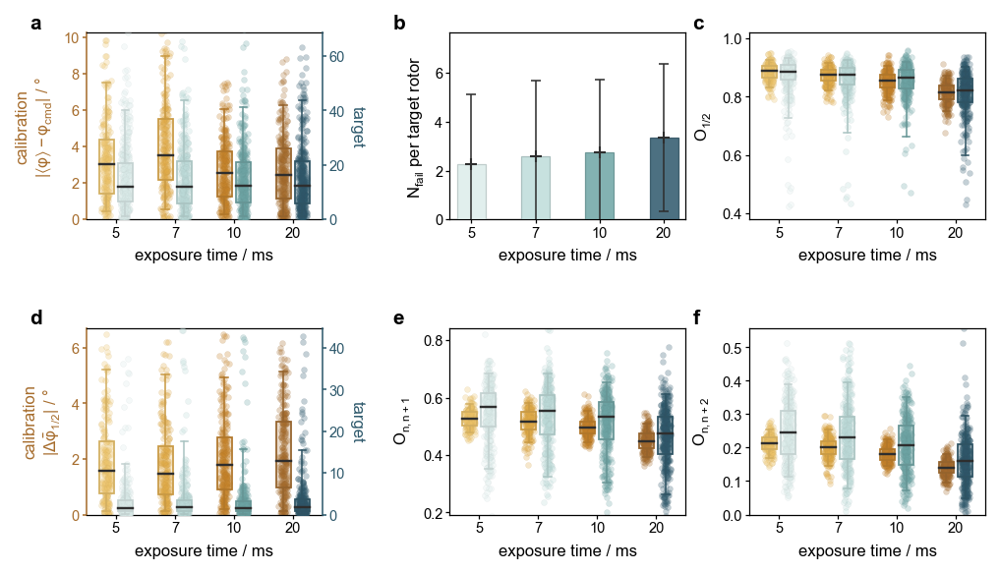

In [22]:
plot_stationarity_from_measurements(
    m_list=m_list,
    calibration_exposure_time_colors=calibration_frame_time_colors,
    target_exposure_time_colors=target_frame_time_colors,
    failure_threshold_deg=25.0,
    metric_source="window",
    rotor_classes=("calibration", "target"),
    fig_width_mm=180,
    fig_height_mm=100,
    stator_variant=stator_variant,
    save_dir=save_dir_SI,
    save_prefix="SI_toFig3_exposuretime__stationarity_steering_connectivity",
    C=CK_colors,
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    point_size=8,
    point_alpha=0.28,
    max_points_per_box=350,
    strip_jitter=0.045,
    box_width=0.28,
    group_gap=1.12,
    class_offset=0.18,
    failure_bar_width=0.50,
    box_face_alpha=0.24,
    failure_ylim=None,
    stationarity_ylim=None,
    neighbor_ylim=None,
    neighbor2_ylim=None,
    steering_ylim_calibration=None,
    steering_ylim_target=None,
    shift_ylim_calibration=None,
    shift_ylim_target=None,
    panel_label_x=-0.24,
    panel_label_y=1.10,
    panel_label_fontsize=10,
    first_column_gap_ratio=0.0,

)

#### _[iii. Plot exemplary data of calibration rotor and target rotor for single m]_

In [23]:
def plot_exemplary_data_rotors(
    m_list,
    particle=None,
    rotor_index=None,
    measurement_index=0,
    rotor_class="target",
    center_phase="deg-100",
    example_phases=None,
    n_neighbor_windows=5,
    C=CK_colors,
    hist_bins=72,
    rolling_mean_s=0.10,
    max_trace_points=500,
    fig_width_mm=180,
    fig_height_mm=120,
    save_dir=None,
    save_prefix="umbrella_qc_single_particle_lean",
    stator_variant=None,
):
    """
    Lean single-particle umbrella QC plot.

    Compatible with the new lean QC storage:
        m.voltage_stationarity_overlap_window_df

    Required on each UMB measurement:
        m.voltage_stationarity_overlap_window_df
        m.trajectories
        m.protocol

    Optional rotor lists:
        target:
            m.target_rotors
            m.target_particles

        calibration:
            m.calibration_rotors
            m.flat_rotors
            m.flat_particles_reliable
            m.flat_particles

    Particle selection:
        1) particle=<id> directly uses that particle id.
        2) rotor_index=<i> selects from the corresponding rotor list.
        3) if neither is given, auto-selects from the QC window table.

    Notes
    -----
    - Does not require m.voltage_stationarity_overlap_particle_df.
    - Does not write anything back into m.
    - Derives radian columns locally from degree columns if needed.
    - Recomputes only the traces/histograms needed for the shown particle.
    - Saves only if save_dir is not None.
    - Closes the figure after display.
    - Returns None.
    """

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.colors import LinearSegmentedColormap

    phi0_offset_rad = -np.pi / 2

    rotor_class = str(rotor_class).lower().strip()
    if rotor_class not in {"target", "calibration"}:
        raise ValueError("rotor_class must be 'target' or 'calibration'.")


    cmd_color = C["black"]
    calib_color = C["warmgold"]
    selected_color = C["target_teal"] if rotor_class == "target" else C["warmgold"]

    overlap_fill_color = (
        (*C["target_teal"][:3], 0.450)
        if rotor_class == "target"
        else (*C["beige"][:3], 0.75)
    )

    raw_trace_color = (0.82, 0.82, 0.82)
    smooth_trace_color = C["black"]
    early_color = C["lightgrey"]
    late_color = C["black"]
    overlap_i_color = C["black"]
    overlap_j_color = C["midgrey"]
    selected_band_color = (0.88, 0.88, 0.88)

    heat_cmap = LinearSegmentedColormap.from_list(
        "white_to_selected",
        [(1, 1, 1, 1), tuple(list(selected_color) + [1.0])],
        N=256,
    )

    def mm_to_inch(x):
        return float(x) / 25.4

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2.0 * np.pi) - np.pi

    def wrap_deg(x):
        return (np.asarray(x, dtype=float) + 180.0) % 360.0 - 180.0

    def align_angle_to_reference(angle, reference):
        angle = np.asarray(angle, dtype=float)
        reference = np.asarray(reference, dtype=float)
        return reference + wrap_pi(angle - reference)

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def as_int_list(x):
        if x is None:
            return []
        if isinstance(x, (pd.Series, np.ndarray)):
            x = x.tolist()
        if isinstance(x, (list, tuple, set)):
            out = []
            for v in x:
                try:
                    fv = float(v)
                    if np.isfinite(fv):
                        out.append(int(fv))
                except Exception:
                    pass
            return out
        try:
            return [int(x)]
        except Exception:
            return []

    def prefixed_name(name):
        if stator_variant is None or str(stator_variant).strip() == "":
            return str(name)
        return f"{str(stator_variant).strip()}__{name}"

    def style_ax(ax, labelsize=6.5):
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color("black")

        ax.tick_params(
            length=2.0,
            width=0.6,
            labelsize=labelsize,
            color="black",
            labelcolor="black",
        )

    def is_umb(m):
        s = str(getattr(m, "path", "")).upper()

        if "DIFF" in s:
            return False

        if "UMB" in s:
            return True

        return hasattr(m, "protocol") and isinstance(m.protocol, dict) and any(
            isinstance(k, str) and k.startswith("deg-") for k in m.protocol.keys()
        )

    def infer_dt(m):
        for attr in ["_average_tpf", "average_tpf"]:
            if hasattr(m, attr):
                try:
                    dt = float(getattr(m, attr))
                    if np.isfinite(dt) and dt > 0:
                        return dt
                except Exception:
                    pass

        if hasattr(m, "fps"):
            try:
                fps = float(getattr(m, "fps"))
                if np.isfinite(fps) and fps > 0:
                    return 1.0 / fps
            except Exception:
                pass

        return 0.005

    def infer_trim_s(m, wdf):
        if hasattr(m, "autocorrelation_trim_s"):
            try:
                v = float(m.autocorrelation_trim_s)
                if np.isfinite(v) and v >= 0:
                    return v
            except Exception:
                pass

        if hasattr(m, "wham_trim_s"):
            try:
                v = float(m.wham_trim_s)
                if np.isfinite(v) and v >= 0:
                    return v
            except Exception:
                pass

        if "trim_s" in wdf.columns and len(wdf):
            vals = wdf["trim_s"].to_numpy(float)
            vals = vals[np.isfinite(vals) & (vals >= 0)]
            if vals.size:
                return float(vals[0])

        return 0.0

    def protocol_bounds(value):
        while (
            isinstance(value, (list, tuple))
            and len(value) == 1
            and isinstance(value[0], (list, tuple, dict))
        ):
            value = value[0]

        if isinstance(value, dict):
            t0 = value.get("start", value.get("start_time", value.get("t_start", value.get("t0", None))))
            t1 = value.get("end", value.get("end_time", value.get("t_end", value.get("t1", value.get("stop", None)))))

            if t0 is None or t1 is None:
                raise ValueError(f"Cannot parse protocol bounds from {value}.")

            return float(t0), float(t1)

        if isinstance(value, (tuple, list)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds from {value}.")

    def get_deg_windows(m):
        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            raise ValueError("m.protocol missing or not a dict.")

        rows = []

        for phase, value in m.protocol.items():
            if not isinstance(phase, str) or not phase.startswith("deg-"):
                continue

            try:
                deg = float(phase.split("-")[1]) % 360.0
                start, stop = protocol_bounds(value)
            except Exception:
                continue

            phi0_cmd = float(wrap_pi(np.deg2rad(deg) + phi0_offset_rad))

            rows.append({
                "phase": str(phase),
                "deg": float(deg),
                "deg_display": float(((deg + 180.0) % 360.0) - 180.0),
                "phi0_cmd_rad": float(phi0_cmd),
                "phi0_cmd_deg": float(np.rad2deg(phi0_cmd)),
                "start": float(start),
                "stop": float(stop),
            })

        if not rows:
            raise ValueError("No parseable deg-* umbrella windows found.")

        df = pd.DataFrame(rows).sort_values("phi0_cmd_rad").reset_index(drop=True)
        df["window_index"] = np.arange(len(df), dtype=int)

        return df

    def hist_density(phi, edges):
        phi = wrap_pi(phi)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.zeros(len(edges) - 1, dtype=float)

        counts, _ = np.histogram(phi, bins=edges)
        total = counts.sum()

        if total <= 0:
            return np.zeros(len(edges) - 1, dtype=float)

        dphi = float(edges[1] - edges[0])

        return counts.astype(float) / (float(total) * dphi)

    def get_example_window_indices(windows):
        if example_phases is not None:
            out = []

            for ph in list(example_phases):
                hit = windows[windows["phase"].astype(str) == str(ph)]

                if len(hit):
                    out.append(int(hit["window_index"].iloc[0]))

            if not out:
                raise ValueError("None of the requested example_phases were found.")

            return out

        if center_phase is None:
            center_i = len(windows) // 2
        else:
            hit = windows[windows["phase"].astype(str) == str(center_phase)]
            center_i = int(hit["window_index"].iloc[0]) if len(hit) else len(windows) // 2

        n = max(1, int(n_neighbor_windows))
        n_left = n // 2
        n_right = n - n_left - 1
        nwin = len(windows)

        return [int((center_i + j) % nwin) for j in range(-n_left, n_right + 1)]

    def smooth_trace_time(t, y, rolling_mean_s):
        t = np.asarray(t, dtype=float)
        y = np.asarray(y, dtype=float)

        if t.size < 3 or rolling_mean_s is None or rolling_mean_s <= 0:
            return y.copy()

        dt = np.nanmedian(np.diff(t))

        if not np.isfinite(dt) or dt <= 0:
            return y.copy()

        win = max(3, int(round(float(rolling_mean_s) / dt)))

        if win % 2 == 0:
            win += 1

        if win >= y.size:
            win = y.size if y.size % 2 else y.size - 1

        if win < 3:
            return y.copy()

        finite = np.isfinite(y)
        y0 = np.where(finite, y, 0.0)
        w0 = finite.astype(float)

        kernel = np.ones(win, dtype=float)
        pad = win // 2

        ypad = np.pad(y0, pad_width=pad, mode="edge")
        wpad = np.pad(w0, pad_width=pad, mode="edge")

        num = np.convolve(ypad, kernel, mode="valid")
        den = np.convolve(wpad, kernel, mode="valid")

        out = np.full_like(y, np.nan, dtype=float)
        ok = den > 0
        out[ok] = num[ok] / den[ok]

        return out

    def downsample(t, y, nmax):
        t = np.asarray(t)
        y = np.asarray(y)

        if t.size <= int(nmax):
            return t, y

        idx = np.linspace(0, t.size - 1, int(nmax)).astype(int)

        return t[idx], y[idx]

    def pick_col(df, candidates):
        for col in candidates:
            if col in df.columns:
                return col
        return None

    def get_phase_container(m, phase):
        tr = getattr(m, "trajectories", None)

        if tr is None:
            raise ValueError("m.trajectories missing. Run calc_trajectories() first.")

        if isinstance(tr, dict):
            if phase in tr:
                return tr[phase]
            if str(phase) in tr:
                return tr[str(phase)]

            for key in tr:
                if str(key) == str(phase):
                    return tr[key]

            return None

        if isinstance(tr, pd.DataFrame):
            phase_col = pick_col(tr, ["phase", "protocol", "phase_name", "window", "segment"])

            if phase_col is None:
                return tr

            return tr[tr[phase_col].astype(str) == str(phase)].copy()

        return tr

    def extract_particle_trace(obj, pid):
        pid = int(pid)

        if obj is None:
            return np.array([], dtype=float)

        if isinstance(obj, pd.DataFrame):
            group_col = pick_col(obj, ["group", "group_int", "particle", "particle_id"])
            phi_col = pick_col(
                obj,
                [
                    "phi_unwrapped",
                    "phi_unwrap",
                    "phi_unwrapped_rad",
                    "unwrapped_phi",
                    "phi_cont",
                    "phi_continuous",
                    "phi_trajectory",
                    "phi",
                ],
            )

            if group_col is not None and phi_col is not None:
                d = obj[obj[group_col].astype(int) == pid].copy()

                if len(d) == 0:
                    return np.array([], dtype=float)

                sort_col = pick_col(d, ["frame", "t", "time_s", "time"])

                if sort_col is not None:
                    d = d.sort_values(sort_col, kind="mergesort")

                return d[phi_col].to_numpy(float)

            for col in [pid, str(pid), f"p{pid}", f"particle_{pid}"]:
                if col in obj.columns:
                    return obj[col].to_numpy(float)

            return np.array([], dtype=float)

        if isinstance(obj, dict):
            if pid in obj:
                return extract_particle_trace(obj[pid], pid)
            if str(pid) in obj:
                return extract_particle_trace(obj[str(pid)], pid)

            for key in obj:
                if str(key) == str(pid):
                    return extract_particle_trace(obj[key], pid)

            return np.array([], dtype=float)

        arr = np.asarray(obj)

        if arr.ndim == 1:
            return arr.astype(float)

        if arr.ndim == 2:
            if pid < arr.shape[0]:
                return arr[pid, :].astype(float)
            if pid < arr.shape[1]:
                return arr[:, pid].astype(float)

        return np.array([], dtype=float)

    def get_trace_for_phase(m, pid, phase, trim_s, dt):
        phi = extract_particle_trace(get_phase_container(m, phase), pid)
        phi = np.asarray(phi, dtype=float)

        if phi.size == 0:
            return np.array([], dtype=float), np.array([], dtype=float)

        n_trim = max(0, min(phi.size, int(np.floor(float(trim_s) / float(dt)))))
        phi = phi[n_trim:]

        t = np.arange(phi.size, dtype=float) * float(dt)

        return t, wrap_pi(phi)

    def get_rotor_list(m, rotor_class):
        if rotor_class == "target":
            attrs = ["target_rotors", "target_particles"]
        else:
            attrs = ["calibration_rotors", "flat_rotors", "flat_particles_reliable", "flat_particles"]

        for attr in attrs:
            if hasattr(m, attr):
                vals = as_int_list(getattr(m, attr))

                if vals:
                    return vals, attr

        return [], None

    def resolve_particle(m, particle, rotor_index, rotor_class, window_df):
        if particle is not None:
            return int(particle)

        rotor_list, source_attr = get_rotor_list(m, rotor_class)

        if rotor_index is not None:
            if not rotor_list:
                raise ValueError(
                    f"rotor_index was given, but no {rotor_class} rotor list exists on this measurement."
                )

            idx = int(rotor_index)

            if idx < 0 or idx >= len(rotor_list):
                raise IndexError(
                    f"rotor_index={idx} outside m.{source_attr}, which has n={len(rotor_list)} entries."
                )

            return int(rotor_list[idx])

        d = window_df.copy()

        if "rotor_class" in d.columns:
            d = d[d["rotor_class"].astype(str).str.lower().str.strip() == rotor_class].copy()
        elif rotor_list:
            d = d[d["particle"].astype(int).isin(rotor_list)].copy()

        if len(d) == 0 and rotor_list:
            return int(rotor_list[0])

        if len(d) == 0:
            raise ValueError(
                f"Could not auto-select a {rotor_class} rotor. "
                "Pass particle=<id> or rotor_index=<i>."
            )

        score_rows = []

        for pid, g in d.groupby("particle", sort=True):
            score = 0.0

            if "half_overlap" in g.columns:
                vals = g["half_overlap"].to_numpy(float)
                score += float(np.nanmedian(vals)) if np.any(np.isfinite(vals)) else 0.0

            if "neighbor_overlap_mean" in g.columns:
                vals = g["neighbor_overlap_mean"].to_numpy(float)
                score += float(np.nanmedian(vals)) if np.any(np.isfinite(vals)) else 0.0

            if "half_mean_shift_deg" in g.columns:
                vals = np.abs(g["half_mean_shift_deg"].to_numpy(float))
                shift = float(np.nanmedian(vals)) if np.any(np.isfinite(vals)) else 0.0
                score -= 0.01 * shift

            score_rows.append((int(pid), score))

        if not score_rows:
            row = d.sort_values("particle").iloc[0]
            return int(row["particle"])

        return int(sorted(score_rows, key=lambda x: x[1], reverse=True)[0][0])

    def make_local_plot_columns(wdf):
        wdf = wdf.copy()

        if "phi0_cmd_rad" not in wdf.columns:
            if "phi0_cmd_deg" in wdf.columns:
                wdf["phi0_cmd_rad"] = np.deg2rad(wdf["phi0_cmd_deg"].to_numpy(float))
            else:
                raise KeyError("Need phi0_cmd_deg or phi0_cmd_rad in m.voltage_stationarity_overlap_window_df.")

        if "phi0_cmd_deg" not in wdf.columns:
            wdf["phi0_cmd_deg"] = np.rad2deg(wdf["phi0_cmd_rad"].to_numpy(float))

        if "mean_phi_rad" not in wdf.columns and "mean_phi_deg" in wdf.columns:
            wdf["mean_phi_rad"] = np.deg2rad(wdf["mean_phi_deg"].to_numpy(float))

        if "mean_phi_deg" not in wdf.columns and "mean_phi_rad" in wdf.columns:
            wdf["mean_phi_deg"] = np.rad2deg(wdf["mean_phi_rad"].to_numpy(float))

        if "calib_mean_phi_rad" not in wdf.columns and "calib_mean_phi_deg" in wdf.columns:
            wdf["calib_mean_phi_rad"] = np.deg2rad(wdf["calib_mean_phi_deg"].to_numpy(float))

        if "calib_mean_phi_deg" not in wdf.columns and "calib_mean_phi_rad" in wdf.columns:
            wdf["calib_mean_phi_deg"] = np.rad2deg(wdf["calib_mean_phi_rad"].to_numpy(float))

        if "target_mean_phi_rad" not in wdf.columns and "target_mean_phi_deg" in wdf.columns:
            wdf["target_mean_phi_rad"] = np.deg2rad(wdf["target_mean_phi_deg"].to_numpy(float))

        if "target_mean_phi_deg" not in wdf.columns and "target_mean_phi_rad" in wdf.columns:
            wdf["target_mean_phi_deg"] = np.rad2deg(wdf["target_mean_phi_rad"].to_numpy(float))

        if "delta_target_minus_calib_mean_phi_deg" not in wdf.columns:
            if "mean_phi_deg" in wdf.columns and "calib_mean_phi_deg" in wdf.columns:
                wdf["delta_target_minus_calib_mean_phi_deg"] = wrap_deg(
                    wdf["mean_phi_deg"].to_numpy(float)
                    - wdf["calib_mean_phi_deg"].to_numpy(float)
                )
            elif "calib_target_error_deg" in wdf.columns:
                wdf["delta_target_minus_calib_mean_phi_deg"] = wdf["calib_target_error_deg"].to_numpy(float)
            else:
                wdf["delta_target_minus_calib_mean_phi_deg"] = np.nan

        if "neighbor_overlap_min" not in wdf.columns and "neighbor_overlap_mean" in wdf.columns:
            wdf["neighbor_overlap_min"] = wdf["neighbor_overlap_mean"].to_numpy(float)

        if "neighbor2_overlap_min" not in wdf.columns and "neighbor2_overlap_mean" in wdf.columns:
            wdf["neighbor2_overlap_min"] = wdf["neighbor2_overlap_mean"].to_numpy(float)

        return wdf

    m_flat = flatten(m_list)

    if not m_flat:
        raise ValueError("m_list is empty.")

    measurement_index = int(measurement_index)

    if measurement_index < 0 or measurement_index >= len(m_flat):
        raise IndexError(f"measurement_index={measurement_index} outside m_list length {len(m_flat)}.")

    m = m_flat[measurement_index]

    if not is_umb(m):
        raise ValueError(
            f"measurement_index={measurement_index} does not look like an UMB measurement."
        )

    window_df = getattr(m, "voltage_stationarity_overlap_window_df", None)

    if window_df is None or len(window_df) == 0:
        raise ValueError("m.voltage_stationarity_overlap_window_df is missing or empty.")

    window_df = window_df.copy()

    if "measurement_index" in window_df.columns:
        window_df = window_df[window_df["measurement_index"].astype(int) == measurement_index].copy()

    particle = resolve_particle(
        m=m,
        particle=particle,
        rotor_index=rotor_index,
        rotor_class=rotor_class,
        window_df=window_df,
    )

    wdf = window_df[window_df["particle"].astype(int) == int(particle)].copy()

    if "rotor_class" in wdf.columns:
        wdf_class = wdf[wdf["rotor_class"].astype(str).str.lower().str.strip() == rotor_class].copy()

        if len(wdf_class):
            wdf = wdf_class

    if len(wdf) == 0:
        raise ValueError(
            f"No stored QC rows found for particle={particle}, rotor_class={rotor_class}."
        )

    wdf = wdf.sort_values("window_index").reset_index(drop=True)
    wdf = make_local_plot_columns(wdf)

    windows = get_deg_windows(m)
    dt = infer_dt(m)
    trim_s = infer_trim_s(m, wdf)

    example_wi = get_example_window_indices(windows)

    edges_phi = np.linspace(-np.pi, np.pi, int(hist_bins) + 1)
    centers_phi = 0.5 * (edges_phi[:-1] + edges_phi[1:])

    window_cache = {}

    for _, row in windows.iterrows():
        wi = int(row["window_index"])
        phase = str(row["phase"])
        t, phi = get_trace_for_phase(m, particle, phase, trim_s, dt)

        window_cache[wi] = {
            "phase": phase,
            "t": t,
            "phi": phi,
            "density": hist_density(phi, edges_phi),
        }

    density_arr = np.asarray(
        [window_cache[int(wi)]["density"] for wi in wdf["window_index"].astype(int)],
        dtype=float,
    )

    fig = plt.figure(figsize=(mm_to_inch(fig_width_mm), mm_to_inch(fig_height_mm)))

    left = 0.045
    right = 0.985
    bottom = 0.075
    top = 0.94

    nrows = len(example_wi)
    row_gap = 0.016
    row_h = (top - bottom - row_gap * (nrows - 1)) / nrows

    w_heat = 0.18
    w_trace = 0.18
    w_stat = 0.16
    w_overlap = 0.16
    w_metrics = right - left - w_heat - w_trace - w_stat - w_overlap - 4 * 0.035

    x_heat = left
    x_trace = x_heat + w_heat + 0.035
    x_stat = x_trace + w_trace + 0.035
    x_overlap = x_stat + w_stat + 0.035
    x_metrics = x_overlap + w_overlap + 0.035

    ax_heat = fig.add_axes([x_heat, bottom, w_heat, top - bottom])

    vmax = None
    if np.any(np.isfinite(density_arr)):
        vmax0 = float(np.nanpercentile(density_arr, 95))
        if np.isfinite(vmax0) and vmax0 > 0:
            vmax = vmax0

    ax_heat.imshow(
        density_arr,
        aspect="auto",
        interpolation="nearest",
        origin="lower",
        extent=[-np.pi, np.pi, -0.5, len(density_arr) - 0.5],
        cmap=heat_cmap,
        vmin=0,
        vmax=vmax,
        alpha=0.80,
    )

    cmd_phi = wdf["phi0_cmd_rad"].to_numpy(float)
    ywin = np.arange(len(wdf), dtype=float)

    wi_to_rowpos = {int(wi): i for i, wi in enumerate(wdf["window_index"].astype(int))}

    for wi in example_wi:
        if int(wi) in wi_to_rowpos:
            y = wi_to_rowpos[int(wi)]
            ax_heat.axhspan(
                y - 0.45,
                y + 0.45,
                color=selected_band_color,
                alpha=0.20,
                lw=0,
                zorder=0,
            )

    ax_heat.plot(
        cmd_phi,
        ywin,
        lw=1.15,
        ls="--",
        color=cmd_color,
        label=r"$\varphi_\mathrm{cmd}$",
        zorder=4,
    )

    if "calib_mean_phi_rad" in wdf.columns:
        calib_phi = align_angle_to_reference(wdf["calib_mean_phi_rad"].to_numpy(float), cmd_phi)

        ax_heat.plot(
            calib_phi,
            ywin,
            marker="o",
            ms=2.2,
            lw=0.95,
            color=calib_color,
            label="calib.",
            zorder=5,
        )

    if "mean_phi_rad" in wdf.columns:
        mean_phi = align_angle_to_reference(wdf["mean_phi_rad"].to_numpy(float), cmd_phi)

        ax_heat.plot(
            mean_phi,
            ywin,
            marker="o",
            ms=2.2,
            lw=0.95,
            color=selected_color,
            label="target" if rotor_class == "target" else "selected",
            zorder=6,
        )
    elif "target_mean_phi_rad" in wdf.columns:
        mean_phi = align_angle_to_reference(wdf["target_mean_phi_rad"].to_numpy(float), cmd_phi)

        ax_heat.plot(
            mean_phi,
            ywin,
            marker="o",
            ms=2.2,
            lw=0.95,
            color=selected_color,
            label="target",
            zorder=6,
        )

    ax_heat.set_xlim(-1.10 * np.pi, 1.10 * np.pi)
    ax_heat.set_xlabel(r"$\varphi$ / rad", fontsize=7)
    ax_heat.set_ylabel("window index", fontsize=7)
    ax_heat.set_xticks([-np.pi, 0, np.pi])
    ax_heat.set_xticklabels([r"$-\pi$", "0", r"$\pi$"], fontsize=6)
    ax_heat.legend(
        frameon=False,
        fontsize=5.4,
        loc="lower right",
        handlelength=1.2,
        borderpad=0.1,
        labelspacing=0.2,
    )
    style_ax(ax_heat)

    stat_share_ax = None
    overlap_share_ax = None

    for r, wi in enumerate(example_wi):
        y0 = top - (r + 1) * row_h - r * row_gap

        win_row = windows[windows["window_index"].astype(int) == int(wi)].iloc[0]
        phi0 = float(win_row["phi0_cmd_rad"])

        t = window_cache[int(wi)]["t"]
        phi = window_cache[int(wi)]["phi"]
        psi = wrap_pi(phi - phi0)

        ax = fig.add_axes([x_trace, y0, w_trace, row_h])

        t_plot, psi_plot = downsample(t, psi, max_trace_points)
        psi_smooth = smooth_trace_time(t_plot, psi_plot, rolling_mean_s)

        ax.plot(
            t_plot,
            np.rad2deg(psi_plot),
            lw=0.40,
            color=raw_trace_color,
            alpha=0.85,
            rasterized=True,
        )
        ax.plot(
            t_plot,
            np.rad2deg(psi_smooth),
            lw=1.00,
            color=smooth_trace_color,
            alpha=0.95,
        )
        ax.axhline(0, lw=0.45, color="black", alpha=0.30)
        ax.set_ylim(-55, 55)
        ax.set_yticks([-50, 0, 50])
        ax.set_ylabel(r"$\psi$ / °", fontsize=6.5)

        if r == nrows - 1:
            ax.set_xlabel("time after trim / s", fontsize=6.5)
        else:
            ax.set_xticklabels([])

        style_ax(ax, labelsize=6)

        if stat_share_ax is None:
            ax = fig.add_axes([x_stat, y0, w_stat, row_h])
            stat_share_ax = ax
        else:
            ax = fig.add_axes([x_stat, y0, w_stat, row_h], sharey=stat_share_ax)

        finite_psi = psi[np.isfinite(psi)]

        if finite_psi.size >= 4:
            half = finite_psi.size // 2
            p_first = hist_density(finite_psi[:half], edges_phi)
            p_second = hist_density(finite_psi[half:], edges_phi)

            ax.plot(centers_phi, p_first, lw=1.00, color=early_color, alpha=0.95)
            ax.plot(centers_phi, p_second, lw=1.15, color=late_color, alpha=0.95)

        ax.set_xlim(-0.5 * np.pi, 0.5 * np.pi)
        ax.set_xticks([-0.5 * np.pi, 0, 0.5 * np.pi])
        ax.set_xticklabels([r"$-\pi/2$", "0", r"$\pi/2$"], fontsize=6)
        ax.set_ylabel("density", fontsize=6.5)

        if r == nrows - 1:
            ax.set_xlabel(r"$\psi$ / rad", fontsize=6.5)
        else:
            ax.set_xticklabels([])

        style_ax(ax, labelsize=6)

        if overlap_share_ax is None:
            ax = fig.add_axes([x_overlap, y0, w_overlap, row_h])
            overlap_share_ax = ax
        else:
            ax = fig.add_axes([x_overlap, y0, w_overlap, row_h], sharey=overlap_share_ax)

        next_wi = int((int(wi) + 1) % len(windows))
        phi_next = window_cache[next_wi]["phi"]

        p_i = hist_density(phi, edges_phi)
        p_j = hist_density(phi_next, edges_phi)
        p_min = np.minimum(p_i, p_j)

        ax.fill_between(
            centers_phi,
            0,
            p_min,
            color=overlap_fill_color,
            linewidth=0,
            zorder=1,
        )
        ax.plot(centers_phi, p_i, lw=1.05, color=overlap_i_color, alpha=0.95, zorder=3)
        ax.plot(centers_phi, p_j, lw=1.05, color=overlap_j_color, alpha=0.95, zorder=2)

        ax.set_xlim(-np.pi, np.pi)
        ax.set_xticks([-np.pi, 0, np.pi])
        ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"], fontsize=6)
        ax.set_ylabel("density", fontsize=6.5)

        if r == nrows - 1:
            ax.set_xlabel(r"$\varphi$ / rad", fontsize=6.5)
        else:
            ax.set_xticklabels([])

        style_ax(ax, labelsize=6)

    metrics_h_gap = 0.06
    metrics_h = (top - bottom - 2 * metrics_h_gap) / 3

    ax_m1 = fig.add_axes([x_metrics, bottom + 2 * (metrics_h + metrics_h_gap), w_metrics, metrics_h])
    ax_m2 = fig.add_axes([x_metrics, bottom + 1 * (metrics_h + metrics_h_gap), w_metrics, metrics_h])
    ax_m3 = fig.add_axes([x_metrics, bottom, w_metrics, metrics_h])

    x = wdf["phi0_cmd_deg"].to_numpy(float)
    sort = np.argsort(x)
    x_sorted = x[sort]

    def shade_metric_ax(ax):
        xvals = wdf["phi0_cmd_deg"].to_numpy(float)
        xvals = xvals[np.isfinite(xvals)]

        dx = np.nanmedian(np.abs(np.diff(np.sort(xvals)))) if xvals.size > 1 else 20.0

        if not np.isfinite(dx) or dx <= 0:
            dx = 20.0

        for wi in example_wi:
            row = wdf[wdf["window_index"].astype(int) == int(wi)]

            if len(row) == 0:
                continue

            xx = float(row["phi0_cmd_deg"].iloc[0])

            ax.axvspan(
                xx - 0.35 * dx,
                xx + 0.35 * dx,
                color=selected_band_color,
                alpha=0.35,
                lw=0,
                zorder=0,
            )

    for ax in [ax_m1, ax_m2, ax_m3]:
        shade_metric_ax(ax)

    if rotor_class == "target" and "delta_target_minus_calib_mean_phi_deg" in wdf.columns:
        delta = wdf["delta_target_minus_calib_mean_phi_deg"].to_numpy(float)
        delta_label = r"$\Delta\langle\varphi\rangle$ / °"
    elif "command_error_deg" in wdf.columns:
        delta = wdf["command_error_deg"].to_numpy(float)
        delta_label = r"$|\langle\varphi\rangle-\varphi_\mathrm{cmd}|$ / °"
    elif "mean_phi_deg" in wdf.columns and "phi0_cmd_deg" in wdf.columns:
        delta = wrap_deg(wdf["mean_phi_deg"].to_numpy(float) - wdf["phi0_cmd_deg"].to_numpy(float))
        delta_label = r"$\langle\varphi\rangle-\varphi_\mathrm{cmd}$ / °"
    else:
        delta = np.full(len(wdf), np.nan)
        delta_label = r"$\Delta\varphi$ / °"

    ax_m1.axhline(0, lw=0.5, color="black", alpha=0.40, zorder=1)
    ax_m1.plot(x_sorted, delta[sort], marker="o", ms=2.1, lw=0.90, color="black", zorder=3)
    ax_m1.set_ylabel(delta_label, fontsize=6.5)
    ax_m1.set_xticklabels([])
    style_ax(ax_m1, labelsize=6)

    if "half_overlap" in wdf.columns:
        ax_m2.plot(
            x_sorted,
            wdf["half_overlap"].to_numpy(float)[sort],
            marker="o",
            ms=2.1,
            lw=0.90,
            color="black",
            zorder=3,
        )

    ax_m2.set_ylim(0, 1.03)
    ax_m2.set_ylabel(r"$O_{1/2}$", fontsize=6.5)
    ax_m2.set_xticklabels([])
    style_ax(ax_m2, labelsize=6)

    if "neighbor_overlap_mean" in wdf.columns:
        ax_m3.plot(
            x_sorted,
            wdf["neighbor_overlap_mean"].to_numpy(float)[sort],
            marker="o",
            ms=2.1,
            lw=0.90,
            color="black",
            label=r"$O_{n,n+1}$",
            zorder=3,
        )

    if "neighbor2_overlap_mean" in wdf.columns:
        ax_m3.plot(
            x_sorted,
            wdf["neighbor2_overlap_mean"].to_numpy(float)[sort],
            lw=0.85,
            color=C["midgrey"],
            label=r"$O_{n,n+2}$",
            zorder=2,
        )

    ax_m3.set_ylim(0, 1.03)
    ax_m3.set_ylabel(r"$O_\mathrm{neighbor}$", fontsize=6.5)
    ax_m3.set_xlabel(r"$\varphi_\mathrm{cmd}$ / °", fontsize=6.5)
    ax_m3.legend(frameon=False, fontsize=5.8, handlelength=1.0)
    style_ax(ax_m3, labelsize=6)

    xmin = np.nanmin(x_sorted) if np.any(np.isfinite(x_sorted)) else -180
    xmax = np.nanmax(x_sorted) if np.any(np.isfinite(x_sorted)) else 180

    for ax in [ax_m1, ax_m2, ax_m3]:
        ax.set_xlim(xmin - 5, xmax + 5)

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        suffix = f"{rotor_class}_p{int(particle)}"

        if rotor_index is not None:
            suffix = f"{rotor_class}_idx{int(rotor_index)}_p{int(particle)}"

        out_name = f"{prefixed_name(save_prefix)}__{suffix}"

        fig.savefig(save_dir / f"{out_name}.png", dpi=300, bbox_inches="tight")
        fig.savefig(save_dir / f"{out_name}.svg", bbox_inches="tight")

    plt.show()
    plt.close(fig)

    return None

In [24]:
# full_execution = True
# if full_execution:
#     plot_exemplary_data_rotors(
#         m_list,
#         measurement_index=0,
#         rotor_class="calibration",
#         rotor_index=0,
#         C=CK_colors,
#         save_dir=save_dir,
#         save_prefix="Fig2_exemplary_rotor",
#         stator_variant=stator_variant,
#     )
    
#     plot_exemplary_data_rotors(
#         m_list,
#         measurement_index=0,
#         rotor_class="target",
#         rotor_index=5,
#         save_dir=save_dir,
#         C=CK_colors,
#         save_prefix="Fig2_exemplary_rotor",
#         stator_variant=stator_variant,
#     )

#### _[iv. Plot exemplary data for different spacings as overlap]_

In [25]:
def plot_exemplary_data_rotors(
    m_list,
    calibration_spacing_colors,
    target_spacing_colors,
    particle=None,
    rotor_index=0,
    rotor_class="target",
    spacing_order=(15, 20, 30),
    reference_spacing_deg=15,
    center_phase="deg-100",
    example_phases=None,
    n_neighbor_windows=3,
    stationarity_hist_xlim_deg=None,
    stationarity_hist_xticks_deg=None,
    neighbor_hist_xlim_deg=None,
    neighbor_hist_xticks_deg=None,
    command_marker="v",
    command_marker_size=3.5,
    command_marker_y_fraction=-0.045,
    command_marker_margin_fraction=0.09,
    metrics_column_gap=0.085,
    spacing_group_gap=0.040,
    selected_band_alpha=0.42,
    selected_metric_marker_size=24,
    selected_metric_edge_width=0.65,
    C=CK_colors,
    hist_bins=72,
    fig_width_mm=180,
    fig_height_mm=100,
    fontsize=7,
    axis_label_size=7,
    tick_label_size=6,
    save_dir=None,
    save_prefix="Fig2_exemplary_rotor_spacing_overlay",
    stator_variant=None,
    show_panel_labels=True,
    show_main_panel_labels=True,
    show_metric_panel_labels=True,
    panel_labels_main=("a", "b", "c"),
    panel_labels_metrics=("d", "e", "f"),
    panel_label_x_main=-0.18,
    panel_label_y_main=1.03,
    panel_label_x_metrics=-0.18,
    panel_label_y_metrics=1.03,
    panel_label_fontsize=10,
):
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.colors import LinearSegmentedColormap

    phi0_offset_rad = -np.pi / 2
    rotor_class = str(rotor_class).lower().strip()

    if rotor_class not in {"target", "calibration"}:
        raise ValueError("rotor_class must be 'target' or 'calibration'.")
    if not isinstance(calibration_spacing_colors, dict) or not calibration_spacing_colors:
        raise ValueError("calibration_spacing_colors must be a non-empty dictionary.")
    if not isinstance(target_spacing_colors, dict) or not target_spacing_colors:
        raise ValueError("target_spacing_colors must be a non-empty dictionary.")

    C = C() if callable(C) else dict(C)
    spacing_colors = target_spacing_colors if rotor_class == "target" else calibration_spacing_colors
    cmd_color = C["black"]
    early_alpha = 0.45
    late_alpha = 0.95
    overlap_i_color = C["black"]
    overlap_j_color = C["midgrey"]
    selected_band_color = (0.88, 0.88, 0.88)

    def mm_to_inch(x):
        return float(x) / 25.4

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def wrap_deg(x):
        return (np.asarray(x, dtype=float) + 180) % 360 - 180

    def circular_distance_deg(a, b):
        return np.abs(wrap_deg(np.asarray(a, dtype=float) - float(b)))

    def align_angle_to_reference(angle, reference):
        angle = np.asarray(angle, dtype=float)
        reference = np.asarray(reference, dtype=float)
        return reference + wrap_pi(angle - reference)

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            return [item for sub in obj for item in flatten(sub)]
        return [obj]

    def as_int_list(values):
        if values is None:
            return []
        if isinstance(values, (pd.Series, np.ndarray)):
            values = values.tolist()
        if not isinstance(values, (list, tuple, set)):
            values = [values]
        out = []
        for value in values:
            try:
                value = float(value)
                if np.isfinite(value):
                    out.append(int(value))
            except Exception:
                pass
        return out

    def prefixed_name(name):
        if stator_variant is None or not str(stator_variant).strip():
            return str(name)
        return f"{str(stator_variant).strip()}__{name}"

    def measurement_name(m, index=None):
        try:
            return Path(str(m.path)).name
        except Exception:
            return f"m_list[{index}]" if index is not None else "unknown"

    def parse_spacing(m):
        match = re.search(r"_(\d+(?:\.\d+)?)deg(?:-|_)", measurement_name(m), flags=re.IGNORECASE)
        return int(round(float(match.group(1)))) if match else None

    def spacing_color(spacing_deg):
        return spacing_colors.get(int(spacing_deg), C["grey"])

    def style_main_ax(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.60)
            spine.set_color(C["black"])
        ax.tick_params(length=2.0, width=0.60, labelsize=tick_label_size, color=C["black"], labelcolor=C["black"], pad=1.4)
        ax.grid(False)

    def style_mini_hist_ax(ax):
        ax.spines["bottom"].set_visible(True)
        ax.spines["bottom"].set_linewidth(0.60)
        ax.spines["bottom"].set_color(C["black"])
        ax.spines["left"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["top"].set_visible(False)
        ax.tick_params(axis="x", length=1.6, width=0.55, labelsize=tick_label_size, color=C["black"], labelcolor=C["black"], pad=1.2)
        ax.tick_params(axis="y", left=False, right=False, labelleft=False, labelright=False)
        ax.grid(False)

    def is_umb(m):
        name = str(getattr(m, "path", measurement_name(m))).upper()
        if "DIFF" in name:
            return False
        if "UMB" in name:
            return True
        return hasattr(m, "protocol") and isinstance(m.protocol, dict) and any(isinstance(key, str) and key.startswith("deg-") for key in m.protocol)

    def infer_dt(m):
        for attr in ["_average_tpf", "average_tpf"]:
            if hasattr(m, attr):
                try:
                    dt = float(getattr(m, attr))
                    if np.isfinite(dt) and dt > 0:
                        return dt
                except Exception:
                    pass
        if hasattr(m, "fps"):
            try:
                fps = float(m.fps)
                if np.isfinite(fps) and fps > 0:
                    return 1 / fps
            except Exception:
                pass
        return 0.005

    def infer_trim_s(m, window_df):
        for attr in ["autocorrelation_trim_s", "wham_trim_s"]:
            if hasattr(m, attr):
                try:
                    value = float(getattr(m, attr))
                    if np.isfinite(value) and value >= 0:
                        return value
                except Exception:
                    pass
        if "trim_s" in window_df.columns:
            values = window_df["trim_s"].to_numpy(float)
            values = values[np.isfinite(values) & (values >= 0)]
            if len(values):
                return float(values[0])
        return 0.0

    def protocol_bounds(value):
        while isinstance(value, (list, tuple)) and len(value) == 1 and isinstance(value[0], (list, tuple, dict)):
            value = value[0]

        if isinstance(value, dict):
            t0 = value.get("start", value.get("start_time", value.get("t_start", value.get("t0", None))))
            t1 = value.get("end", value.get("end_time", value.get("t_end", value.get("t1", value.get("stop", None)))))
            if t0 is None or t1 is None:
                raise ValueError(f"Cannot parse protocol bounds from {value}.")
            return float(t0), float(t1)

        if isinstance(value, (tuple, list)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds from {value}.")

    def get_deg_windows(m):
        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            raise ValueError("m.protocol missing or not a dictionary.")

        rows = []

        for phase, value in m.protocol.items():
            if not isinstance(phase, str) or not phase.startswith("deg-"):
                continue

            try:
                deg = float(phase.split("-")[1]) % 360
                start, stop = protocol_bounds(value)
            except Exception:
                continue

            phi0_cmd = float(wrap_pi(np.deg2rad(deg) + phi0_offset_rad))

            rows.append({
                "phase": str(phase),
                "deg": float(deg),
                "deg_display": float(wrap_deg(deg)),
                "phi0_cmd_rad": phi0_cmd,
                "phi0_cmd_deg": float(np.rad2deg(phi0_cmd)),
                "start": float(start),
                "stop": float(stop),
            })

        if not rows:
            raise ValueError("No parseable deg-* umbrella windows found.")

        out = pd.DataFrame(rows).sort_values("phi0_cmd_rad").reset_index(drop=True)
        out["window_index"] = np.arange(len(out), dtype=int)
        return out

    def parse_center_command_deg():
        if center_phase is None:
            return None

        match = re.search(r"deg[-_]?(-?\d+(?:\.\d+)?)", str(center_phase), flags=re.IGNORECASE)

        if match is None:
            raise ValueError(f"Could not parse center_phase={center_phase!r}. Use a label such as 'deg-100'.")

        protocol_deg = float(match.group(1))
        return float(wrap_deg(protocol_deg - 90.0))

    def local_example_window_indices(windows, target_phi0_cmd_deg):
        n_windows = len(windows)

        if example_phases is not None:
            requested_angles = []

            for phase in example_phases:
                match = re.search(r"deg[-_]?(-?\d+(?:\.\d+)?)", str(phase), flags=re.IGNORECASE)
                if match:
                    requested_angles.append(float(wrap_deg(float(match.group(1)) - 90.0)))

            if not requested_angles:
                raise ValueError("None of example_phases could be parsed.")

            local_angles = windows["phi0_cmd_deg"].to_numpy(float)
            local_indices = []

            for requested_angle in requested_angles:
                local_position = int(np.nanargmin(circular_distance_deg(local_angles, requested_angle)))
                local_indices.append(int(windows.iloc[local_position]["window_index"]))

            return list(dict.fromkeys(local_indices))

        if target_phi0_cmd_deg is None:
            center_position = n_windows // 2
        else:
            local_angles = windows["phi0_cmd_deg"].to_numpy(float)
            center_position = int(np.nanargmin(circular_distance_deg(local_angles, target_phi0_cmd_deg)))

        n = max(1, int(n_neighbor_windows))
        n_left = n // 2
        n_right = n - n_left - 1
        positions = [(center_position + offset) % n_windows for offset in range(-n_left, n_right + 1)]
        return [int(windows.iloc[position]["window_index"]) for position in positions]

    def hist_density(phi, edges):
        phi = wrap_pi(phi)
        phi = phi[np.isfinite(phi)]

        if len(phi) == 0:
            return np.zeros(len(edges) - 1, dtype=float)

        counts, _ = np.histogram(phi, bins=edges)
        total = counts.sum()

        if total <= 0:
            return np.zeros(len(edges) - 1, dtype=float)

        return counts.astype(float) / (float(total) * float(edges[1] - edges[0]))

    def hist_density_linear(values, edges):
        values = np.asarray(values, dtype=float)
        values = values[np.isfinite(values)]
        if len(values) == 0:
            return np.zeros(len(edges) - 1, dtype=float)
        counts, _ = np.histogram(values, bins=edges)
        total = counts.sum()
        if total <= 0:
            return np.zeros(len(edges) - 1, dtype=float)
        return counts.astype(float) / (float(total) * float(edges[1] - edges[0]))

    def pick_column(df, candidates):
        for column in candidates:
            if column in df.columns:
                return column
        return None

    def get_phase_container(m, phase):
        trajectories = getattr(m, "trajectories", None)

        if trajectories is None:
            raise ValueError("m.trajectories missing. Run calc_trajectories() first.")

        if isinstance(trajectories, dict):
            if phase in trajectories:
                return trajectories[phase]
            if str(phase) in trajectories:
                return trajectories[str(phase)]
            for key in trajectories:
                if str(key) == str(phase):
                    return trajectories[key]
            return None

        if isinstance(trajectories, pd.DataFrame):
            phase_column = pick_column(trajectories, ["phase", "protocol", "phase_name", "window", "segment"])
            if phase_column is None:
                return trajectories
            return trajectories[trajectories[phase_column].astype(str).eq(str(phase))].copy()

        return trajectories

    def extract_particle_trace(obj, particle_id):
        particle_id = int(particle_id)

        if obj is None:
            return np.array([], dtype=float)

        if isinstance(obj, pd.DataFrame):
            group_column = pick_column(obj, ["group", "group_int", "particle", "particle_id"])
            phi_column = pick_column(obj, ["phi_unwrapped", "phi_unwrap", "phi_unwrapped_rad", "unwrapped_phi", "phi_cont", "phi_continuous", "phi_trajectory", "phi"])

            if group_column is not None and phi_column is not None:
                data = obj[obj[group_column].astype(int).eq(particle_id)].copy()

                if len(data) == 0:
                    return np.array([], dtype=float)

                sort_column = pick_column(data, ["frame", "t", "time_s", "time"])

                if sort_column is not None:
                    data = data.sort_values(sort_column, kind="mergesort")

                return data[phi_column].to_numpy(float)

            for column in [particle_id, str(particle_id), f"p{particle_id}", f"particle_{particle_id}"]:
                if column in obj.columns:
                    return obj[column].to_numpy(float)

            return np.array([], dtype=float)

        if isinstance(obj, dict):
            if particle_id in obj:
                return extract_particle_trace(obj[particle_id], particle_id)
            if str(particle_id) in obj:
                return extract_particle_trace(obj[str(particle_id)], particle_id)
            for key in obj:
                if str(key) == str(particle_id):
                    return extract_particle_trace(obj[key], particle_id)
            return np.array([], dtype=float)

        array = np.asarray(obj)

        if array.ndim == 1:
            return array.astype(float)

        if array.ndim == 2:
            if particle_id < array.shape[0]:
                return array[particle_id, :].astype(float)
            if particle_id < array.shape[1]:
                return array[:, particle_id].astype(float)

        return np.array([], dtype=float)

    def get_trace_for_phase(m, particle_id, phase, trim_s, dt):
        phi = extract_particle_trace(get_phase_container(m, phase), particle_id)
        phi = np.asarray(phi, dtype=float)

        if len(phi) == 0:
            return np.array([], dtype=float), np.array([], dtype=float)

        n_trim = max(0, min(len(phi), int(np.floor(float(trim_s) / float(dt)))))
        phi = phi[n_trim:]
        t = np.arange(len(phi), dtype=float) * float(dt)
        return t, wrap_pi(phi)

    def get_rotor_list(m):
        attrs = ["target_rotors", "target_particles"] if rotor_class == "target" else ["calibration_rotors", "flat_rotors", "flat_particles_reliable", "flat_particles"]

        for attr in attrs:
            if hasattr(m, attr):
                values = as_int_list(getattr(m, attr))
                if values:
                    return values, attr

        return [], None

    def resolve_particle(reference_m, window_df=None):
        if particle is not None:
            return int(particle)

        rotor_list, source_attr = get_rotor_list(reference_m)

        if rotor_list:
            idx = 0 if rotor_index is None else int(rotor_index)

            if idx < 0 or idx >= len(rotor_list):
                raise IndexError(f"rotor_index={idx} outside m.{source_attr}, which contains {len(rotor_list)} rotors.")

            return int(rotor_list[idx])

        if window_df is None or len(window_df) == 0:
            raise ValueError(f"No stored {rotor_class} rotor list found on {measurement_name(reference_m)}.")

        data = window_df.copy()

        if "rotor_class" in data.columns:
            data = data[data["rotor_class"].astype(str).str.lower().str.strip().eq(rotor_class)].copy()

        if len(data) == 0:
            raise ValueError(f"Could not auto-select a {rotor_class} rotor. Pass particle=<id> or rotor_index=<i>.")

        return int(data.sort_values("particle").iloc[0]["particle"])

    def make_local_plot_columns(window_df):
        window_df = window_df.copy()

        if "phi0_cmd_rad" not in window_df.columns:
            if "phi0_cmd_deg" not in window_df.columns:
                raise KeyError("Need phi0_cmd_deg or phi0_cmd_rad.")
            window_df["phi0_cmd_rad"] = np.deg2rad(window_df["phi0_cmd_deg"].to_numpy(float))

        if "phi0_cmd_deg" not in window_df.columns:
            window_df["phi0_cmd_deg"] = np.rad2deg(window_df["phi0_cmd_rad"].to_numpy(float))

        if "mean_phi_rad" not in window_df.columns and "mean_phi_deg" in window_df.columns:
            window_df["mean_phi_rad"] = np.deg2rad(window_df["mean_phi_deg"].to_numpy(float))

        if "mean_phi_deg" not in window_df.columns and "mean_phi_rad" in window_df.columns:
            window_df["mean_phi_deg"] = np.rad2deg(window_df["mean_phi_rad"].to_numpy(float))

        if "calib_mean_phi_rad" not in window_df.columns and "calib_mean_phi_deg" in window_df.columns:
            window_df["calib_mean_phi_rad"] = np.deg2rad(window_df["calib_mean_phi_deg"].to_numpy(float))

        if "calib_mean_phi_deg" not in window_df.columns and "calib_mean_phi_rad" in window_df.columns:
            window_df["calib_mean_phi_deg"] = np.rad2deg(window_df["calib_mean_phi_rad"].to_numpy(float))

        if "target_mean_phi_rad" not in window_df.columns and "target_mean_phi_deg" in window_df.columns:
            window_df["target_mean_phi_rad"] = np.deg2rad(window_df["target_mean_phi_deg"].to_numpy(float))

        if "target_mean_phi_deg" not in window_df.columns and "target_mean_phi_rad" in window_df.columns:
            window_df["target_mean_phi_deg"] = np.rad2deg(window_df["target_mean_phi_rad"].to_numpy(float))

        if "delta_target_minus_calib_mean_phi_deg" not in window_df.columns:
            if "mean_phi_deg" in window_df.columns and "calib_mean_phi_deg" in window_df.columns:
                window_df["delta_target_minus_calib_mean_phi_deg"] = wrap_deg(window_df["mean_phi_deg"].to_numpy(float) - window_df["calib_mean_phi_deg"].to_numpy(float))
            elif "calib_target_error_deg" in window_df.columns:
                window_df["delta_target_minus_calib_mean_phi_deg"] = window_df["calib_target_error_deg"].to_numpy(float)
            else:
                window_df["delta_target_minus_calib_mean_phi_deg"] = np.nan

        return window_df

    def match_wdf_to_window_positions(wdf, windows):
        wdf = wdf.copy()
        local_angles = windows["phi0_cmd_deg"].to_numpy(float)
        matched_indices = []

        for angle in wdf["phi0_cmd_deg"].to_numpy(float):
            position = int(np.nanargmin(circular_distance_deg(local_angles, angle)))
            matched_indices.append(int(windows.iloc[position]["window_index"]))

        wdf["local_window_index"] = matched_indices
        return wdf

    all_measurements = flatten(m_list)
    umb_measurements = [m for m in all_measurements if is_umb(m)]
    by_spacing = {}

    for m in umb_measurements:
        spacing_deg = parse_spacing(m)
        if spacing_deg is not None:
            by_spacing.setdefault(int(spacing_deg), []).append(m)

    spacing_order = [int(spacing) for spacing in spacing_order if int(spacing) in by_spacing]

    if not spacing_order:
        raise ValueError(f"None of the requested spacings was found. Available spacings: {sorted(by_spacing)}")

    for spacing_deg in spacing_order:
        by_spacing[spacing_deg] = sorted(by_spacing[spacing_deg], key=measurement_name)

    selected_measurements = {spacing_deg: by_spacing[spacing_deg][0] for spacing_deg in spacing_order}
    reference_spacing_deg = int(reference_spacing_deg)

    if reference_spacing_deg not in selected_measurements:
        raise ValueError(f"reference_spacing_deg={reference_spacing_deg} is unavailable. Available spacings: {spacing_order}")

    reference_m = selected_measurements[reference_spacing_deg]
    reference_window_df = getattr(reference_m, "voltage_stationarity_overlap_window_df", None)

    if reference_window_df is None or len(reference_window_df) == 0:
        raise ValueError(f"{measurement_name(reference_m)} has no voltage_stationarity_overlap_window_df.")

    particle = resolve_particle(reference_m, reference_window_df)
    target_phi0_cmd_deg = parse_center_command_deg()
    measurement_data = {}

    for spacing_deg in spacing_order:
        m = selected_measurements[spacing_deg]
        window_df = getattr(m, "voltage_stationarity_overlap_window_df", None)

        if window_df is None or len(window_df) == 0:
            raise ValueError(f"{measurement_name(m)} has no voltage_stationarity_overlap_window_df.")

        particle_df = window_df[window_df["particle"].astype(int).eq(int(particle))].copy()

        if "rotor_class" in particle_df.columns:
            class_df = particle_df[particle_df["rotor_class"].astype(str).str.lower().str.strip().eq(rotor_class)].copy()
            if len(class_df):
                particle_df = class_df

        if len(particle_df) == 0:
            raise ValueError(f"Particle {particle} has no stored {rotor_class} QC rows at {spacing_deg}° spacing.")

        particle_df = make_local_plot_columns(particle_df)
        windows = get_deg_windows(m)
        particle_df = match_wdf_to_window_positions(particle_df, windows).sort_values("phi0_cmd_rad").reset_index(drop=True)
        example_window_indices = local_example_window_indices(windows, target_phi0_cmd_deg)
        center_window_index = int(example_window_indices[len(example_window_indices) // 2])

        measurement_data[spacing_deg] = {
            "m": m,
            "wdf": particle_df,
            "windows": windows,
            "dt": infer_dt(m),
            "trim_s": infer_trim_s(m, particle_df),
            "example_window_indices": example_window_indices,
            "center_window_index": center_window_index,
        }

    reference_data = measurement_data[reference_spacing_deg]
    reference_windows = reference_data["windows"]
    reference_selected_rows = reference_windows[reference_windows["window_index"].astype(int).isin(reference_data["example_window_indices"])].copy()
    reference_center_row = reference_windows[reference_windows["window_index"].astype(int).eq(reference_data["center_window_index"])]
    center_phi_cmd_deg = float(reference_center_row["phi0_cmd_deg"].iloc[0])
    selected_phi_cmd_deg = reference_selected_rows["phi0_cmd_deg"].to_numpy(float)
    selected_phi_cmd_deg = center_phi_cmd_deg + wrap_deg(selected_phi_cmd_deg - center_phi_cmd_deg)
    selected_phi_cmd_deg = np.sort(selected_phi_cmd_deg)

    phi_edges = np.linspace(-np.pi, np.pi, int(hist_bins) + 1)

    if stationarity_hist_xlim_deg is None:
        stationarity_xlim_deg = (float(selected_phi_cmd_deg[0]) - 50.0, float(selected_phi_cmd_deg[-1]) + 50.0)
    else:
        stationarity_xlim_deg = tuple(float(v) for v in stationarity_hist_xlim_deg)

    if stationarity_hist_xticks_deg is None:
        tick_step = 45.0
        tick_start = np.ceil(stationarity_xlim_deg[0] / tick_step) * tick_step
        tick_stop = np.floor(stationarity_xlim_deg[1] / tick_step) * tick_step
        stationarity_ticks_deg = np.arange(tick_start, tick_stop + 0.5 * tick_step, tick_step)
        if len(stationarity_ticks_deg) > 4:
            stationarity_ticks_deg = stationarity_ticks_deg[::2]
        if len(stationarity_ticks_deg) < 2:
            stationarity_ticks_deg = np.linspace(stationarity_xlim_deg[0], stationarity_xlim_deg[1], 3)
    else:
        stationarity_ticks_deg = np.asarray(stationarity_hist_xticks_deg, dtype=float).ravel()
        stationarity_ticks_deg = stationarity_ticks_deg[np.isfinite(stationarity_ticks_deg)]

    if neighbor_hist_xlim_deg is None:
        overlap_xlim_deg = (float(selected_phi_cmd_deg[0]) - 50.0, float(selected_phi_cmd_deg[-1]) + 50.0)
    else:
        overlap_xlim_deg = tuple(float(v) for v in neighbor_hist_xlim_deg)

    if neighbor_hist_xticks_deg is None:
        tick_step = 45.0
        tick_start = np.ceil(overlap_xlim_deg[0] / tick_step) * tick_step
        tick_stop = np.floor(overlap_xlim_deg[1] / tick_step) * tick_step
        overlap_ticks_deg = np.arange(tick_start, tick_stop + 0.5 * tick_step, tick_step)
        if len(overlap_ticks_deg) > 4:
            overlap_ticks_deg = overlap_ticks_deg[::2]
        if len(overlap_ticks_deg) < 2:
            overlap_ticks_deg = np.linspace(overlap_xlim_deg[0], overlap_xlim_deg[1], 3)
    else:
        overlap_ticks_deg = np.asarray(neighbor_hist_xticks_deg, dtype=float).ravel()
        overlap_ticks_deg = overlap_ticks_deg[np.isfinite(overlap_ticks_deg)]

    stationarity_edges_deg = np.linspace(*stationarity_xlim_deg, int(hist_bins) + 1)
    stationarity_centers_deg = 0.5 * (stationarity_edges_deg[:-1] + stationarity_edges_deg[1:])
    overlap_edges_deg = np.linspace(*overlap_xlim_deg, int(hist_bins) + 1)
    overlap_centers_deg = 0.5 * (overlap_edges_deg[:-1] + overlap_edges_deg[1:])
    stationarity_ymax = 0.0
    overlap_ymax = 0.0

    for spacing_deg in spacing_order:
        data = measurement_data[spacing_deg]
        window_cache = {}

        for _, row in data["windows"].iterrows():
            window_index = int(row["window_index"])
            phase = str(row["phase"])
            t, phi = get_trace_for_phase(data["m"], particle, phase, data["trim_s"], data["dt"])
            phi = wrap_pi(phi)
            window_cache[window_index] = {"phase": phase, "t": t, "phi": phi, "density_phi": hist_density(phi, phi_edges)}

        data["window_cache"] = window_cache
        data["density_array"] = np.asarray([window_cache[int(window_index)]["density_phi"] for window_index in data["wdf"]["local_window_index"].astype(int)], dtype=float)

        for local_wi in data["example_window_indices"]:
            local_wi = int(local_wi)
            phi = window_cache[local_wi]["phi"]
            phi0 = float(data["windows"].loc[data["windows"]["window_index"].astype(int).eq(local_wi), "phi0_cmd_rad"].iloc[0])
            phi_abs_deg = np.rad2deg(align_angle_to_reference(phi, phi0))
            finite_phi = phi_abs_deg[np.isfinite(phi_abs_deg)]

            if len(finite_phi) >= 4:
                half = len(finite_phi) // 2
                first_density = hist_density_linear(finite_phi[:half], stationarity_edges_deg)
                second_density = hist_density_linear(finite_phi[half:], stationarity_edges_deg)
                stationarity_ymax = max(stationarity_ymax, float(np.nanmax(first_density)), float(np.nanmax(second_density)))

            next_wi = int((local_wi + 1) % len(data["windows"]))
            next_phi = window_cache[next_wi]["phi"]
            phi_i_deg = np.rad2deg(align_angle_to_reference(phi, phi0))
            phi_j_deg = np.rad2deg(align_angle_to_reference(next_phi, phi0))
            p_i = hist_density_linear(phi_i_deg, overlap_edges_deg)
            p_j = hist_density_linear(phi_j_deg, overlap_edges_deg)
            overlap_ymax = max(overlap_ymax, float(np.nanmax(p_i)), float(np.nanmax(p_j)))

    stationarity_ylim_top = stationarity_ymax * 1.08 if stationarity_ymax > 0 else 1.0
    overlap_ylim_top = overlap_ymax * 1.08 if overlap_ymax > 0 else 1.0
    stationarity_marker_y = float(command_marker_y_fraction) * stationarity_ylim_top
    overlap_marker_y = float(command_marker_y_fraction) * overlap_ylim_top
    stationarity_ylim_bottom = -abs(float(command_marker_margin_fraction)) * stationarity_ylim_top
    overlap_ylim_bottom = -abs(float(command_marker_margin_fraction)) * overlap_ylim_top

    plt.rcParams.update({
        "font.size": fontsize,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.labelsize": axis_label_size,
        "xtick.labelsize": tick_label_size,
        "ytick.labelsize": tick_label_size,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    fig = plt.figure(figsize=(mm_to_inch(fig_width_mm), mm_to_inch(fig_height_mm)))

    left, right, bottom, top = 0.045, 0.985, 0.085, 0.965
    column_gap = 0.042
    heat_width, stat_width, overlap_width = 0.255, 0.145, 0.145
    x_heat = left
    x_stat = x_heat + heat_width + column_gap
    x_overlap = x_stat + stat_width + column_gap
    x_metrics = x_overlap + overlap_width + float(metrics_column_gap)
    metrics_width = right - x_metrics

    if metrics_width <= 0.08:
        raise ValueError("metrics_column_gap is too large for the selected figure width.")

    n_spacings = len(spacing_order)
    heat_gap = 0.018
    heat_height = (top - bottom - (n_spacings - 1) * heat_gap) / n_spacings

    for spacing_index, spacing_deg in enumerate(spacing_order):
        data = measurement_data[spacing_deg]
        y0 = top - (spacing_index + 1) * heat_height - spacing_index * heat_gap
        ax = fig.add_axes([x_heat, y0, heat_width, heat_height])
        color = spacing_color(spacing_deg)
        cmap = LinearSegmentedColormap.from_list(f"density_{spacing_deg}", [(1, 1, 1, 1), (*color[:3], 1)], N=256)
        density_array = data["density_array"]
        vmax = None

        if np.any(np.isfinite(density_array)):
            vmax_value = float(np.nanpercentile(density_array, 95))
            if np.isfinite(vmax_value) and vmax_value > 0:
                vmax = vmax_value

        ax.imshow(density_array, aspect="auto", interpolation="nearest", origin="lower", extent=[-np.pi, np.pi, -0.5, len(density_array) - 0.5], cmap=cmap, vmin=0, vmax=vmax, alpha=0.85)
        wdf = data["wdf"]
        selected_indices = set(int(wi) for wi in data["example_window_indices"])

        for row_position, local_wi in enumerate(wdf["local_window_index"].astype(int)):
            if local_wi in selected_indices:
                ax.axhspan(row_position - 0.45, row_position + 0.45, color=selected_band_color, alpha=selected_band_alpha, lw=0, zorder=3)

        cmd_phi = wdf["phi0_cmd_rad"].to_numpy(float)
        y_window = np.arange(len(wdf), dtype=float)
        ax.plot(cmd_phi, y_window, color=cmd_color, lw=0.95, ls="--", zorder=4)

        if "mean_phi_rad" in wdf.columns:
            mean_phi = align_angle_to_reference(wdf["mean_phi_rad"].to_numpy(float), cmd_phi)
            ax.plot(mean_phi, y_window, marker="o", ms=1.8, lw=0.85, color=color, zorder=5)
        elif "target_mean_phi_rad" in wdf.columns:
            mean_phi = align_angle_to_reference(wdf["target_mean_phi_rad"].to_numpy(float), cmd_phi)
            ax.plot(mean_phi, y_window, marker="o", ms=1.8, lw=0.85, color=color, zorder=5)

        ax.text(0.03, 0.95, f"{int(spacing_deg)}°", transform=ax.transAxes, ha="left", va="top", fontsize=axis_label_size, color=C["black"])
        ax.set_xlim(-1.10 * np.pi, 1.10 * np.pi)
        ax.set_xticks([-np.pi, 0, np.pi])

        if spacing_index == n_spacings - 1:
            ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"])
            ax.set_xlabel(r"$\varphi$ / rad", fontsize=axis_label_size)
        else:
            ax.set_xticklabels([])

        ax.set_ylabel("window index", fontsize=axis_label_size)
        style_main_ax(ax)

    n_example_windows = max(len(measurement_data[spacing]["example_window_indices"]) for spacing in spacing_order)
    group_gap = float(spacing_group_gap)

    if group_gap < 0:
        raise ValueError("spacing_group_gap must be >= 0.")

    group_height = (top - bottom - (n_spacings - 1) * group_gap) / n_spacings
    group_y0s = [top - (spacing_index + 1) * group_height - spacing_index * group_gap for spacing_index in range(n_spacings)]
    window_gap = 0.004
    window_height = (group_height - (n_example_windows - 1) * window_gap) / n_example_windows

    for spacing_index, spacing_deg in enumerate(spacing_order):
        data = measurement_data[spacing_deg]
        group_y0 = group_y0s[spacing_index]
        color = spacing_color(spacing_deg)
        local_example_indices = data["example_window_indices"]

        for window_position, local_wi in enumerate(local_example_indices):
            local_wi = int(local_wi)
            phi = data["window_cache"][local_wi]["phi"]
            phi0 = float(data["windows"].loc[data["windows"]["window_index"].astype(int).eq(local_wi), "phi0_cmd_rad"].iloc[0])
            phi0_deg = float(np.rad2deg(phi0))
            phi_abs_deg = np.rad2deg(align_angle_to_reference(phi, phi0))
            sub_y0 = group_y0 + group_height - (window_position + 1) * window_height - window_position * window_gap
            show_bottom_labels = spacing_index == n_spacings - 1 and window_position == len(local_example_indices) - 1

            ax_stat = fig.add_axes([x_stat, sub_y0, stat_width, window_height])
            finite_phi = phi_abs_deg[np.isfinite(phi_abs_deg)]

            if len(finite_phi) >= 4:
                half = len(finite_phi) // 2
                first_density = hist_density_linear(finite_phi[:half], stationarity_edges_deg)
                second_density = hist_density_linear(finite_phi[half:], stationarity_edges_deg)
                ax_stat.plot(stationarity_centers_deg, first_density, color=color, lw=0.85, alpha=early_alpha)
                ax_stat.plot(stationarity_centers_deg, second_density, color=color, lw=1.10, alpha=late_alpha)

            ax_stat.plot(phi0_deg, stationarity_marker_y, marker=command_marker, ms=command_marker_size, color=cmd_color, clip_on=False, zorder=10)
            ax_stat.set_xlim(*stationarity_xlim_deg)
            ax_stat.set_ylim(stationarity_ylim_bottom, stationarity_ylim_top)
            ax_stat.set_xticks(stationarity_ticks_deg)

            if show_bottom_labels:
                ax_stat.set_xticklabels([rf"${tick:.0f}^\circ$" for tick in stationarity_ticks_deg])
                ax_stat.set_xlabel(r"$\varphi$ / °", fontsize=axis_label_size)
            else:
                ax_stat.set_xticklabels([])

            style_mini_hist_ax(ax_stat)

            ax_overlap = fig.add_axes([x_overlap, sub_y0, overlap_width, window_height])
            next_wi = int((local_wi + 1) % len(data["windows"]))
            next_phi = data["window_cache"][next_wi]["phi"]
            next_phi0 = float(data["windows"].loc[data["windows"]["window_index"].astype(int).eq(next_wi), "phi0_cmd_rad"].iloc[0])
            next_phi0_deg = float(np.rad2deg(align_angle_to_reference(next_phi0, phi0)))
            phi_i_deg = np.rad2deg(align_angle_to_reference(phi, phi0))
            phi_j_deg = np.rad2deg(align_angle_to_reference(next_phi, phi0))
            p_i = hist_density_linear(phi_i_deg, overlap_edges_deg)
            p_j = hist_density_linear(phi_j_deg, overlap_edges_deg)
            overlap_density = np.minimum(p_i, p_j)

            ax_overlap.fill_between(overlap_centers_deg, 0, overlap_density, color=color, alpha=0.35, linewidth=0, zorder=1)
            ax_overlap.plot(overlap_centers_deg, p_i, color=overlap_i_color, lw=0.90, alpha=0.95, zorder=3)
            ax_overlap.plot(overlap_centers_deg, p_j, color=overlap_j_color, lw=0.90, alpha=0.90, zorder=2)
            ax_overlap.plot(phi0_deg, overlap_marker_y, marker=command_marker, ms=command_marker_size, color=overlap_i_color, clip_on=False, zorder=10)
            ax_overlap.plot(next_phi0_deg, overlap_marker_y, marker=command_marker, ms=command_marker_size, color=overlap_j_color, clip_on=False, zorder=10)
            ax_overlap.set_xlim(*overlap_xlim_deg)
            ax_overlap.set_ylim(overlap_ylim_bottom, overlap_ylim_top)
            ax_overlap.set_xticks(overlap_ticks_deg)

            if show_bottom_labels:
                ax_overlap.set_xticklabels([rf"${tick:.0f}^\circ$" for tick in overlap_ticks_deg])
                ax_overlap.set_xlabel(r"$\varphi$ / °", fontsize=axis_label_size)
            else:
                ax_overlap.set_xticklabels([])

            style_mini_hist_ax(ax_overlap)

    if n_spacings == 3:
        metric_y0s = group_y0s
        metric_heights = [group_height] * 3
    else:
        metrics_gap = 0.055
        metric_h = (top - bottom - 2 * metrics_gap) / 3
        metric_y0s = [bottom + 2 * (metric_h + metrics_gap), bottom + metric_h + metrics_gap, bottom]
        metric_heights = [metric_h] * 3

    ax_metric_1 = fig.add_axes([x_metrics, metric_y0s[0], metrics_width, metric_heights[0]])
    ax_metric_2 = fig.add_axes([x_metrics, metric_y0s[1], metrics_width, metric_heights[1]])
    ax_metric_3 = fig.add_axes([x_metrics, metric_y0s[2], metrics_width, metric_heights[2]])
    delta_label = r"$\Delta\varphi$ / °"

    for spacing_deg in spacing_order:
        data = measurement_data[spacing_deg]
        wdf = data["wdf"]
        color = spacing_color(spacing_deg)
        x = wdf["phi0_cmd_deg"].to_numpy(float)
        order = np.argsort(x)
        x_sorted = x[order]
        selected_local_indices = set(int(wi) for wi in data["example_window_indices"])
        selected_mask = wdf["local_window_index"].astype(int).isin(selected_local_indices).to_numpy()[order]

        if rotor_class == "target" and "delta_target_minus_calib_mean_phi_deg" in wdf.columns:
            delta = wdf["delta_target_minus_calib_mean_phi_deg"].to_numpy(float)
            delta_label = r"$\Delta\langle\varphi\rangle$ / °"
        elif "command_error_deg" in wdf.columns:
            delta = wdf["command_error_deg"].to_numpy(float)
            delta_label = r"$|\langle\varphi\rangle-\varphi_\mathrm{cmd}|$ / °"
        elif "mean_phi_deg" in wdf.columns:
            delta = wrap_deg(wdf["mean_phi_deg"].to_numpy(float) - wdf["phi0_cmd_deg"].to_numpy(float))
            delta_label = r"$\langle\varphi\rangle-\varphi_\mathrm{cmd}$ / °"
        else:
            delta = np.full(len(wdf), np.nan)

        delta_sorted = delta[order]
        ax_metric_1.plot(x_sorted, delta_sorted, marker="o", ms=2.1, lw=0.95, color=color, label=f"{int(spacing_deg)}°")
        ax_metric_1.scatter(x_sorted[selected_mask], delta_sorted[selected_mask], s=float(selected_metric_marker_size), facecolor=color, edgecolor=C["black"], linewidth=float(selected_metric_edge_width), zorder=6)

        if "half_overlap" in wdf.columns:
            half_overlap = wdf["half_overlap"].to_numpy(float)[order]
            ax_metric_2.plot(x_sorted, half_overlap, marker="o", ms=2.1, lw=0.95, color=color)
            ax_metric_2.scatter(x_sorted[selected_mask], half_overlap[selected_mask], s=float(selected_metric_marker_size), facecolor=color, edgecolor=C["black"], linewidth=float(selected_metric_edge_width), zorder=6)

        if "neighbor_overlap_mean" in wdf.columns:
            neighbor_overlap = wdf["neighbor_overlap_mean"].to_numpy(float)[order]
            ax_metric_3.plot(x_sorted, neighbor_overlap, marker="o", ms=2.1, lw=0.95, color=color)
            ax_metric_3.scatter(x_sorted[selected_mask], neighbor_overlap[selected_mask], s=float(selected_metric_marker_size), facecolor=color, edgecolor=C["black"], linewidth=float(selected_metric_edge_width), zorder=6)

        if "neighbor2_overlap_mean" in wdf.columns:
            neighbor2_overlap = wdf["neighbor2_overlap_mean"].to_numpy(float)[order]
            ax_metric_3.plot(x_sorted, neighbor2_overlap, lw=0.80, ls="--", color=color, alpha=0.60)

    ax_metric_1.axhline(0, color=C["grey"], lw=0.50, alpha=0.60)
    ax_metric_1.set_ylabel(delta_label, fontsize=axis_label_size)
    ax_metric_1.set_xticklabels([])
    ax_metric_1.legend(frameon=False, fontsize=tick_label_size, handlelength=1.1)
    style_main_ax(ax_metric_1)

    ax_metric_2.set_ylim(0, 1.03)
    ax_metric_2.set_ylabel(r"$O_{1/2}$", fontsize=axis_label_size)
    ax_metric_2.set_xticklabels([])
    style_main_ax(ax_metric_2)

    ax_metric_3.set_ylim(0, 1.03)
    ax_metric_3.set_ylabel(r"$O_{n,n+1}$", fontsize=axis_label_size)
    ax_metric_3.set_xlabel(r"$\varphi_\mathrm{cmd}$ / °", fontsize=axis_label_size)
    ax_metric_3.text(0.98, 0.04, r"dashed: $O_{n,n+2}$", transform=ax_metric_3.transAxes, ha="right", va="bottom", fontsize=tick_label_size, color=C["midgrey"])
    style_main_ax(ax_metric_3)

    all_x = np.concatenate([measurement_data[spacing]["wdf"]["phi0_cmd_deg"].to_numpy(float) for spacing in spacing_order])
    all_x = all_x[np.isfinite(all_x)]

    if len(all_x):
        xmin, xmax = float(np.nanmin(all_x)), float(np.nanmax(all_x))
        for ax in [ax_metric_1, ax_metric_2, ax_metric_3]:
            ax.set_xlim(xmin - 5, xmax + 5)

    def add_panel_label(x, y, label):
        if label is None or not str(label).strip():
            return
        fig.text(x, y, str(label), ha="left", va="bottom", fontsize=panel_label_fontsize, fontname="Arial", fontweight="bold", color="black", clip_on=False)

    if show_panel_labels and show_main_panel_labels:
        main_x = [
            x_heat + float(panel_label_x_main) * heat_width,
            x_stat + float(panel_label_x_main) * stat_width,
            x_overlap + float(panel_label_x_main) * overlap_width,
        ]
        main_y = top + (float(panel_label_y_main) - 1.0) * heat_height
        for x, label in zip(main_x, panel_labels_main):
            add_panel_label(x, main_y, label)

    if show_panel_labels and show_metric_panel_labels:
        for ax, label in zip((ax_metric_1, ax_metric_2, ax_metric_3), panel_labels_metrics):
            pos_ax = ax.get_position()
            x = pos_ax.x0 + float(panel_label_x_metrics) * pos_ax.width
            y = pos_ax.y0 + float(panel_label_y_metrics) * pos_ax.height
            add_panel_label(x, y, label)

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        suffix = f"{rotor_class}_p{int(particle)}" if rotor_index is None else f"{rotor_class}_idx{int(rotor_index)}_p{int(particle)}"
        output_name = f"{prefixed_name(save_prefix)}__{suffix}"
        fig.savefig(save_dir / f"{output_name}.png", dpi=300, bbox_inches="tight")
        fig.savefig(save_dir / f"{output_name}.svg", bbox_inches="tight")

    plt.show()
    plt.close(fig)
    return None

In [26]:
# target_spacing_colors = {
#     15: target_voltage_colors[200],
#     20: target_voltage_colors[250],
#     30: target_voltage_colors[300],
# }

# calibration_spacing_colors = {
#     15: (170/255, 210/255, 160/255),
#     20: (110/255, 175/255, 120/255),
#     30: (50/255, 120/255, 70/255),
# }

# # if full_execution:
# plot_exemplary_data_rotors(
#     m_list=m_list,
#     calibration_spacing_colors=calibration_spacing_colors,
#     target_spacing_colors=target_spacing_colors,

#     rotor_index=5,
#     rotor_class="target",

#     spacing_order=(5,7,10,20),
#     reference_spacing_deg=20,

#     # Absolute-angle limits for column 2
#     stationarity_hist_xlim_deg=(-35, 165),
#     # stationarity_hist_xticks_deg=(-80, -40, 0, 40, 80),

#     # Absolute-angle limits for column 3
#     neighbor_hist_xlim_deg=(-35, 165),
#     # neighbor_hist_xticks_deg=(-80, -40, 0, 40, 80),

#     center_phase="deg-150",
#     n_neighbor_windows=3,
#     C=CK_colors,
#     hist_bins=36,
#     fig_width_mm=180,
#     fig_height_mm=100,
#     fontsize=7,
#     axis_label_size=7,
#     tick_label_size=6,
#     save_dir=save_dir_SI,
#     save_prefix="SI_toFig3e_windows__exemplary_target_rotor_steering_connectivity",
#     stator_variant=stator_variant,
# )

#### _[iv. Plot summary statistics on stationarity and window overlap]_

In [27]:
def plot_umbrella_qc_histograms_from_measurements(
    m_list,
    spacing_layout="overlay",
    calibration_spacing_colors=None,
    target_spacing_colors=None,
    C=None,
    fig_width_mm=180,
    fig_height_mm=None,
    row_height_mm=42,
    horizontal_wspace=0.16,
    separate_rows_hspace=0.05,
    save_dir=None,
    save_prefix="umbrella_qc_histograms_spacing",
    stator_variant=None,
    delta_col=None,
    target_half_overlap_col="half_overlap",
    calib_half_overlap_col="half_overlap",
    neighbor_overlap_col="neighbor_overlap_mean",
    use_abs_delta=True,
    delta_bins=None,
    half_overlap_bins=None,
    neighbor_overlap_bins=None,
    half_overlap_nbins=50,
    neighbor_overlap_nbins=50,
    half_overlap_xlim=(0.5, 1.0),
    neighbor_overlap_xlim=(0.0, 1.0),
    threshold_delta_deg=10.0,
    threshold_half_overlap=0.80,
    threshold_neighbor_overlap=0.25,
    density=True,
    alpha=0.42,
    edge_lw=0.45,
    fontsize=8,
    axis_label_size=None,
    tick_label_size=None,
    title_size=None,
    annotation_size=None,
    legend_size=None,
    show_spacing_legend=True,
    dpi=300,
):
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.lines import Line2D

    if C is None:
        raise ValueError("Pass C=CK_colors.")

    C = C() if callable(C) else dict(C)

    if calibration_spacing_colors is None:
        calibration_spacing_colors = {
            15: (170 / 255, 210 / 255, 160 / 255),
            20: (110 / 255, 175 / 255, 120 / 255),
            30: (50 / 255, 120 / 255, 70 / 255),
        }

    if target_spacing_colors is None:
        target_spacing_colors = {
            15: (196 / 255, 225 / 255, 208 / 255),
            20: (105 / 255, 168 / 255, 145 / 255),
            30: (38 / 255, 104 / 255, 82 / 255),
        }

    calibration_spacing_colors = {int(round(float(k))): v for k, v in calibration_spacing_colors.items()}
    target_spacing_colors = {int(round(float(k))): v for k, v in target_spacing_colors.items()}
    spacing_layout = str(spacing_layout).strip().lower()

    if spacing_layout not in {"overlay", "separate_rows"}:
        raise ValueError("spacing_layout must be 'overlay' or 'separate_rows'.")

    axis_label_size = fontsize if axis_label_size is None else axis_label_size
    tick_label_size = fontsize - 1 if tick_label_size is None else tick_label_size
    title_size = fontsize if title_size is None else title_size
    annotation_size = fontsize - 1.7 if annotation_size is None else annotation_size
    legend_size = fontsize - 1 if legend_size is None else legend_size

    black = C.get("black", (0, 0, 0))
    grey = C.get("grey", (0.35, 0.35, 0.35))
    lightgrey = C.get("lightgrey", (0.72, 0.72, 0.72))

    xlabel_half = r"$O_{1/2}$"
    xlabel_neighbor = r"$O_{n,n+1}$"
    xlabel_delta = r"$|\Delta\tilde{\varphi}|$ / °"

    def mm(x):
        return float(x) / 25.4

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            return [item for sub in obj for item in flatten(sub)]
        return [obj]

    def measurement_name(m, index=None):
        try:
            return Path(str(m.path)).name
        except Exception:
            return f"m_list[{index}]" if index is not None else "unknown measurement"

    def is_umb(m):
        name = measurement_name(m).upper()
        return "UMB" in name and "DIFF" not in name

    def parse_spacing(m):
        match = re.search(r"_(\d+(?:\.\d+)?)deg(?:-|_)", measurement_name(m), flags=re.IGNORECASE)
        return int(round(float(match.group(1)))) if match else None

    def spacing_label(spacing):
        return f"{int(spacing)}°"

    def spacing_color(spacing, rotor_class):
        colors = calibration_spacing_colors if rotor_class == "calibration" else target_spacing_colors
        return colors.get(int(spacing), grey)

    def color_luminance(color):
        r, g, b = np.asarray(color, dtype=float)[:3]
        return 0.2126 * r + 0.7152 * g + 0.0722 * b

    def collect_measurements():
        rows = []

        for source_index, m in enumerate(flatten(m_list)):
            if not is_umb(m):
                continue

            df = getattr(m, "voltage_stationarity_overlap_window_df", None)

            if not isinstance(df, pd.DataFrame) or len(df) == 0:
                continue

            spacing = parse_spacing(m)

            if spacing is None:
                continue

            d = df.copy()

            if "rotor_class" not in d.columns:
                if "ensemble" not in d.columns:
                    raise KeyError(f"{measurement_name(m)} needs 'rotor_class' or 'ensemble'.")
                d["rotor_class"] = d["ensemble"].astype(str)

            rows.append({
                "m": m,
                "source_index": int(source_index),
                "name": measurement_name(m, source_index),
                "spacing_deg": int(spacing),
                "label": spacing_label(spacing),
                "df": d,
            })

        if not rows:
            raise ValueError(
                "No stored UMB QC tables found. "
                "Run compute_stationarity_overlap_target_rotors(...) first."
            )

        return sorted(rows, key=lambda row: (row["spacing_deg"], row["source_index"]))

    def find_col(df, candidates, label):
        for column in candidates:
            if column is not None and column in df.columns:
                return column

        raise KeyError(
            f"Could not find the column for {label}.\n"
            f"Tried: {candidates}\n"
            f"Available columns: {list(df.columns)}"
        )

    def finite_values(df, column):
        values = pd.to_numeric(df[column], errors="coerce").to_numpy(float)
        return values[np.isfinite(values)]

    def style_ax(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.60)
            spine.set_color(black)

        ax.tick_params(
            length=2.0,
            width=0.60,
            labelsize=tick_label_size,
            color=black,
            labelcolor=black,
            direction="out",
        )
        ax.grid(False)

    def draw_threshold(ax, threshold, threshold_kind):
        if threshold is None or not np.isfinite(threshold):
            return

        ax.axvline(float(threshold), color=grey, lw=0.8, ls=(0, (2.2, 1.6)), zorder=20)
        x0, x1 = ax.get_xlim()

        if threshold_kind == "below_good":
            ax.axvspan(x0, float(threshold), color=lightgrey, alpha=0.12, zorder=-20, linewidth=0)
        elif threshold_kind == "above_good":
            ax.axvspan(float(threshold), x1, color=lightgrey, alpha=0.12, zorder=-20, linewidth=0)

    def set_overlap_ticks(ax, xlim):
        if tuple(xlim) == (0.5, 1.0):
            ax.set_xticks([0.5, 0.75, 1.0])
            ax.set_xticklabels(["0.5", "0.75", "1"])
        elif tuple(xlim) == (0.0, 1.0):
            ax.set_xticks([0.0, 0.25, 0.5, 0.75, 1.0])
            ax.set_xticklabels(["0", "", "0.5", "", "1"])

    def finish_hist_axis(
        ax,
        xlabel,
        threshold=None,
        threshold_kind=None,
        xlim=None,
        ylabel=None,
        show_xaxis=True,
    ):
        if xlim is not None:
            ax.set_xlim(*xlim)

        draw_threshold(ax, threshold, threshold_kind)

        if xlim is not None:
            set_overlap_ticks(ax, xlim)

        if show_xaxis:
            ax.set_xlabel(xlabel, fontsize=axis_label_size)
        else:
            ax.set_xlabel("")
            ax.tick_params(axis="x", which="both", bottom=False, top=False, labelbottom=False)

        ax.set_ylabel("" if ylabel is None else ylabel, fontsize=axis_label_size)
        style_ax(ax)

    def draw_single_hist(ax, values, bins, color):
        ax.hist(
            values,
            bins=bins,
            density=bool(density),
            color=color,
            alpha=float(alpha),
            edgecolor=black,
            linewidth=float(edge_lw),
        )

    def draw_overlay_hist(ax, prepared_rows, value_key, bins, rotor_class):
        ordered = sorted(
            prepared_rows,
            key=lambda row: color_luminance(spacing_color(row["spacing_deg"], rotor_class)),
        )

        for row in ordered:
            color = spacing_color(row["spacing_deg"], rotor_class)

            ax.hist(
                row[value_key],
                bins=bins,
                density=bool(density),
                histtype="stepfilled",
                color=color,
                alpha=0.20,
                edgecolor=color,
                linewidth=float(edge_lw),
                label=row["label"],
            )
            ax.hist(
                row[value_key],
                bins=bins,
                density=bool(density),
                histtype="step",
                color=color,
                alpha=0.95,
                linewidth=max(0.70, float(edge_lw)),
            )

    rows = collect_measurements()

    if half_overlap_bins is None:
        half_overlap_bins = np.linspace(float(half_overlap_xlim[0]), float(half_overlap_xlim[1]), int(half_overlap_nbins) + 1)

    if neighbor_overlap_bins is None:
        neighbor_overlap_bins = np.linspace(float(neighbor_overlap_xlim[0]), float(neighbor_overlap_xlim[1]), int(neighbor_overlap_nbins) + 1)

    prepared = []

    for row in rows:
        df = row["df"].copy()
        df["rotor_class"] = df["rotor_class"].astype(str).str.lower().str.strip()
        target_df = df[df["rotor_class"] == "target"].copy()
        calib_df = df[df["rotor_class"] == "calibration"].copy()

        if len(target_df) == 0 or len(calib_df) == 0:
            continue

        delta_col_use = find_col(
            target_df,
            [
                delta_col,
                "calib_target_error_deg",
                "delta_target_minus_calib_mean_phi_deg",
                "target_minus_calib_mean_phi_deg",
                "target_calib_error_deg",
            ],
            "target-calibration steering mismatch",
        )

        target_half_col_use = find_col(
            target_df,
            [target_half_overlap_col, "half_overlap", "O_half"],
            "target half-window overlap",
        )

        calib_half_col_use = find_col(
            calib_df,
            [calib_half_overlap_col, "half_overlap", "O_half"],
            "calibration half-window overlap",
        )

        neighbor_col_use = find_col(
            target_df,
            [
                neighbor_overlap_col,
                "neighbor_overlap_mean",
                "neighbor_overlap_min",
                "neighbor_overlap",
                "O_neighbor",
            ],
            "target neighboring-window overlap",
        )

        delta = finite_values(target_df, delta_col_use)
        delta_plot = np.abs(delta) if bool(use_abs_delta) else delta
        O_half_calib = finite_values(calib_df, calib_half_col_use)
        O_half_target = finite_values(target_df, target_half_col_use)
        O_neighbor_target = finite_values(target_df, neighbor_col_use)

        O_half_calib = O_half_calib[(O_half_calib >= half_overlap_xlim[0]) & (O_half_calib <= half_overlap_xlim[1])]
        O_half_target = O_half_target[(O_half_target >= half_overlap_xlim[0]) & (O_half_target <= half_overlap_xlim[1])]
        O_neighbor_target = O_neighbor_target[
            (O_neighbor_target >= neighbor_overlap_xlim[0])
            & (O_neighbor_target <= neighbor_overlap_xlim[1])
        ]

        if min(len(delta_plot), len(O_half_calib), len(O_half_target), len(O_neighbor_target)) == 0:
            continue

        prepared.append({
            **row,
            "target_df": target_df,
            "calib_df": calib_df,
            "O_half_calib": O_half_calib,
            "delta_plot": delta_plot,
            "O_half_target": O_half_target,
            "O_neighbor_target": O_neighbor_target,
        })

    if not prepared:
        raise ValueError("No UMB measurement had complete calibration and target QC values to plot.")

    if delta_bins is None:
        all_delta = np.concatenate([row["delta_plot"] for row in prepared])
        q98 = float(np.nanquantile(all_delta, 0.98))
        threshold_based = float(threshold_delta_deg) * 1.35 if threshold_delta_deg is not None else q98
        xmax = max(10.0, q98, threshold_based)

        if np.nanmax(all_delta) > 0:
            xmax = min(xmax, float(np.nanmax(all_delta)))

        delta_bins = np.linspace(0.0, max(xmax, 10.0), 41) if bool(use_abs_delta) else 40

    plt.rcParams.update({
        "font.size": fontsize,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.linewidth": 0.60,
        "axes.labelsize": axis_label_size,
        "xtick.labelsize": tick_label_size,
        "ytick.labelsize": tick_label_size,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    ylabel = "density" if bool(density) else "counts"

    if spacing_layout == "overlay":
        fig_height_use = float(row_height_mm) if fig_height_mm is None else float(fig_height_mm)
        fig, axes = plt.subplots(1, 4, figsize=(mm(fig_width_mm), mm(fig_height_use)), squeeze=False, constrained_layout=False)
        ax0, ax1, ax2, ax3 = axes[0]

        draw_overlay_hist(ax0, prepared, "O_half_calib", half_overlap_bins, "calibration")
        draw_overlay_hist(ax1, prepared, "delta_plot", delta_bins, "target")
        draw_overlay_hist(ax2, prepared, "O_half_target", half_overlap_bins, "target")
        draw_overlay_hist(ax3, prepared, "O_neighbor_target", neighbor_overlap_bins, "target")

        finish_hist_axis(ax0, xlabel_half, threshold_half_overlap, "above_good", half_overlap_xlim, ylabel)
        finish_hist_axis(ax1, xlabel_delta, threshold_delta_deg, "below_good", (0.0, max(delta_bins)) if use_abs_delta else None)
        finish_hist_axis(ax2, xlabel_half, threshold_half_overlap, "above_good", half_overlap_xlim)
        finish_hist_axis(ax3, xlabel_neighbor, threshold_neighbor_overlap, "above_good", neighbor_overlap_xlim)

        for ax in axes[0]:
            ax.set_yticks([])
            ax.tick_params(axis="y", length=0)

        axes[0, 0].set_title("calibration", fontsize=title_size, pad=3)
        axes[0, 1].set_title("target vs calibration", fontsize=title_size, pad=3)
        axes[0, 2].set_title("target", fontsize=title_size, pad=3)
        axes[0, 3].set_title("target", fontsize=title_size, pad=3)

        if show_spacing_legend:
            spacings = sorted({row["spacing_deg"] for row in prepared})
            calibration_handles = [
                Line2D([0], [0], color=spacing_color(spacing, "calibration"), lw=4, label=spacing_label(spacing))
                for spacing in spacings
            ]
            target_handles = [
                Line2D([0], [0], color=spacing_color(spacing, "target"), lw=4, label=spacing_label(spacing))
                for spacing in spacings
            ]

            axes[0, 0].legend(
                handles=calibration_handles,
                title="window spacing",
                frameon=False,
                fontsize=legend_size,
                title_fontsize=legend_size,
                loc="upper left",
            )
            axes[0, 2].legend(
                handles=target_handles,
                title="window spacing",
                frameon=False,
                fontsize=legend_size,
                title_fontsize=legend_size,
                loc="upper left",
            )

        fig.subplots_adjust(left=0.055, right=0.990, bottom=0.19, top=0.88, wspace=float(horizontal_wspace))

    else:
        nrows = len(prepared)
        fig_height_use = float(row_height_mm) * nrows if fig_height_mm is None else float(fig_height_mm)
        fig, axes = plt.subplots(nrows, 4, figsize=(mm(fig_width_mm), mm(fig_height_use)), squeeze=False, constrained_layout=False)

        for row_index, row in enumerate(prepared):
            ax0, ax1, ax2, ax3 = axes[row_index]
            is_bottom_row = row_index == nrows - 1
            spacing = row["spacing_deg"]

            draw_single_hist(ax0, row["O_half_calib"], half_overlap_bins, spacing_color(spacing, "calibration"))
            draw_single_hist(ax1, row["delta_plot"], delta_bins, spacing_color(spacing, "target"))
            draw_single_hist(ax2, row["O_half_target"], half_overlap_bins, spacing_color(spacing, "target"))
            draw_single_hist(ax3, row["O_neighbor_target"], neighbor_overlap_bins, spacing_color(spacing, "target"))

            finish_hist_axis(ax0, xlabel_half, threshold_half_overlap, "above_good", half_overlap_xlim, ylabel, is_bottom_row)
            finish_hist_axis(ax1, xlabel_delta, threshold_delta_deg, "below_good", (0.0, max(delta_bins)) if use_abs_delta else None, show_xaxis=is_bottom_row)
            finish_hist_axis(ax2, xlabel_half, threshold_half_overlap, "above_good", half_overlap_xlim, show_xaxis=is_bottom_row)
            finish_hist_axis(ax3, xlabel_neighbor, threshold_neighbor_overlap, "above_good", neighbor_overlap_xlim, show_xaxis=is_bottom_row)

            for ax in axes[row_index]:
                ax.set_yticks([])
                ax.tick_params(axis="y", length=0)

            n_target = row["target_df"]["particle"].nunique() if "particle" in row["target_df"].columns else 0
            n_calib = row["calib_df"]["particle"].nunique() if "particle" in row["calib_df"].columns else 0

            ax0.text(
                0.02,
                0.98,
                f"{spacing_label(spacing)}\n"
                f"calib.: {int(n_calib)} particles, {len(row['calib_df'])} windows\n"
                f"target: {int(n_target)} particles, {len(row['target_df'])} windows",
                transform=ax0.transAxes,
                ha="left",
                va="top",
                fontsize=annotation_size,
                color=grey,
            )

        axes[0, 0].set_title("calibration", fontsize=title_size, pad=3)
        axes[0, 1].set_title("target vs calibration", fontsize=title_size, pad=3)
        axes[0, 2].set_title("target", fontsize=title_size, pad=3)
        axes[0, 3].set_title("target", fontsize=title_size, pad=3)

        fig.subplots_adjust(
            left=0.055,
            right=0.990,
            bottom=0.085,
            top=0.965,
            wspace=float(horizontal_wspace),
            hspace=float(separate_rows_hspace),
        )

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        prefix = f"{stator_variant}__{save_prefix}" if stator_variant is not None and str(stator_variant).strip() else save_prefix
        fig.savefig(save_dir / f"{prefix}.png", dpi=int(dpi), bbox_inches="tight")
        fig.savefig(save_dir / f"{prefix}.svg", bbox_inches="tight")

    plt.show()
    plt.close(fig)
    return None

In [28]:
# # if full_execution: 
# plot_umbrella_qc_histograms_from_measurements(
#     m_list=m_list,
#     spacing_layout="separate_rows",
#     calibration_spacing_colors=calibration_spacing_colors,
#     target_spacing_colors=target_spacing_colors,
#     fig_width_mm=180,
#     fig_height_mm=90,
#     horizontal_wspace=0.12,
#     separate_rows_hspace=0.05,
#     half_overlap_xlim=(0.5, 1.0),
#     half_overlap_nbins=50,
#     neighbor_overlap_xlim=(0.0, 1.0),
#     neighbor_overlap_nbins=50,
#     C=CK_colors,
#     fontsize=8,
#     axis_label_size=8,
#     tick_label_size=7,
#     title_size=8,
#     annotation_size=6.3,
#     save_dir=save_dir,
#     save_prefix="SI_umbrella_qc_histograms_spacing_separate",
#     stator_variant=stator_variant,
# )

#### v. Investigate information efficiency

In [29]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, curve_fit


def analyze_exposure_information_efficiency(
    m_list,
    calibration_exposure_time_colors,
    target_exposure_time_colors,
    calibration_particles,
    target_particles,
    exposure_order_ms=(5, 7, 10, 20),
    representative_window_deg=0,
    min_locs_per_window=30,
    min_valid_windows_per_particle=6,
    acf_fit_max_s=0.12,
    acf_fit_min_points=5,
    barrier_quantile=0.75,
    n_bootstrap=500,
    random_seed=7,
    fig_width_mm=180,
    fig_height_mm=88,
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    annotation_size=6,
    panel_label_size=9,
    panel_labels=("a", "b", "c", "d", "e", "f"),
    C=None,
    save_dir=None,
    save_prefix="Fig_exposure_information_model",
    stator_variant=None,
    dpi=300,
):
    """
    Fit and validate an OU exposure-averaging model before calculating an
    information-efficiency proxy.

    Model
    -----
    B(T, tau) = 2 * (x - 1 + exp(-x)) / x**2, x = T/tau
    kappa_app,r(T) = kappa0,r / B(T, tau)

    One shared tau_OU is fitted across calibration rotors, with one nuisance
    parameter kappa0,r per rotor. Rotors are bootstrapped to obtain a 95% CI.

    OU validation
    -------------
    Each calibration rotor/window ACF is fitted to
        rho(t) = A * exp(-t/tau_exp)
    over short positive lags. tau_exp is compared with the fitted tau_OU.

    Information metrics
    -------------------
    eta_corr   = N_eff / N = 1 / g
    eta_useful = eta_corr * B(T, tau_OU)**2
    N_info     = N * eta_useful

    eta_useful and N_info are information-efficiency proxies, not exact Fisher
    information. The fitted OU model must be inspected before interpretation.

    Stores
    ------
    The same result dictionary is stored as
        m.exposure_information_model
    on every UMB measurement used.

    Returns
    -------
    fig
    """
    if C is None:
        raise ValueError("Pass C=CK_colors.")

    C = C() if callable(C) else dict(C)
    for key, value in {
        "black": (0, 0, 0),
        "grey": (0.25, 0.25, 0.25),
        "midgrey": (0.45, 0.45, 0.45),
        "lightgrey": (0.72, 0.72, 0.72),
    }.items():
        C.setdefault(key, value)

    def mm(x): return float(x) / 25.4
    def rgb(x):
        x = np.asarray(x, float).ravel()[:3]
        return tuple(x / 255 if np.nanmax(x) > 1 else x)
    def flatten(x):
        if x is None: return []
        if isinstance(x, (list, tuple)): return [z for y in x for z in flatten(y)]
        return [x]
    def name(m):
        for attr in ("path", "filename", "file", "name"):
            value = getattr(m, attr, None)
            if value is not None: return Path(str(value)).name
        return "measurement"
    def is_diff(m): return "DIFF" in name(m).upper() and "PSEUDO_DIFF" not in name(m).upper()
    def is_umb(m):
        protocol = getattr(m, "protocol", None)
        return not is_diff(m) and ("UMB" in name(m).upper() or (
            isinstance(protocol, dict) and any(str(k).startswith("deg-") for k in protocol)
        ))
    def exposure_ms(m):
        for attr in ("exposure_time_ms", "frame_time_ms", "camera_frame_time_ms"):
            try:
                value = float(getattr(m, attr))
                if np.isfinite(value) and value > 0: return value
            except Exception:
                pass
        for attr in ("_average_tpf", "average_tpf"):
            try:
                value = 1000 * float(getattr(m, attr))
                if np.isfinite(value) and value > 0: return value
            except Exception:
                pass
        match = re.search(r"(?<!\d)(\d+(?:\.\d+)?)\s*ms", name(m), flags=re.I)
        return float(match.group(1)) if match else np.nan
    def exposure_key(value):
        if not np.isfinite(value): return None
        arr = np.asarray(exposure_order_ms, float)
        nearest = float(arr[np.argmin(np.abs(arr - value))])
        return nearest if np.isclose(nearest, value, atol=0.06, rtol=0.01) else None
    def wrap(phi): return (np.asarray(phi, float) + np.pi) % (2 * np.pi) - np.pi
    def circ_mean(phi):
        phi = np.asarray(phi, float)
        phi = phi[np.isfinite(phi)]
        return float(np.angle(np.mean(np.exp(1j * phi)))) if phi.size else np.nan
    def circ_std(phi):
        phi = np.asarray(phi, float)
        phi = phi[np.isfinite(phi)]
        if phi.size < 2: return np.nan
        R = np.clip(np.abs(np.mean(np.exp(1j * phi))), 1e-15, 1.0)
        return float(np.sqrt(-2 * np.log(R)))
    def bounds(value):
        while isinstance(value, (list, tuple)) and len(value) == 1 and isinstance(value[0], (list, tuple, dict)):
            value = value[0]
        if isinstance(value, dict):
            start = value.get("start", value.get("start_time", value.get("t_start", value.get("t0"))))
            stop = value.get("end", value.get("end_time", value.get("t_end", value.get("t1", value.get("stop")))))
            return float(start), float(stop)
        return float(value[0]), float(value[1])
    def windows(m):
        out = []
        for phase, value in getattr(m, "protocol", {}).items():
            match = re.match(r"^deg-(-?\d+(?:\.\d+)?)", str(phase))
            if match:
                try:
                    start, stop = bounds(value)
                    out.append((float(match.group(1)), str(phase), start, stop))
                except Exception:
                    pass
        return sorted(out)
    def locs(m):
        df = m.locs.copy()
        if "group" not in df and "group_int" in df: df["group"] = df["group_int"].astype(int)
        if "t" not in df:
            for col in ("averagetime", "time", "time_s"):
                if col in df:
                    df["t"] = df[col].astype(float)
                    break
            else:
                df["t"] = df["frame"].astype(float) * float(getattr(m, "_average_tpf", 0.005))
        df["group"] = df["group"].astype(int)
        return df
    def blur_retention(T_ms, tau_ms):
        x = np.asarray(T_ms, float) / float(tau_ms)
        return 2 * (x - 1 + np.exp(-x)) / np.maximum(x*x, 1e-30)
    def acf_fft(x, max_lag):
        x = np.asarray(x, float)
        x = x[np.isfinite(x)]
        n = x.size
        if n < 4: return np.array([1.0])
        x = x - np.mean(x)
        var = np.var(x)
        if not np.isfinite(var) or var <= 1e-30: return np.array([1.0])
        nfft = 1 << (2*n - 1).bit_length()
        fx = np.fft.fft(x, n=nfft)
        acf = np.fft.ifft(fx * np.conjugate(fx)).real[:n]
        acf = acf / (var * np.arange(n, 0, -1))
        acf = acf / acf[0]
        return acf[:min(max_lag + 1, n)]
    def exp_model(t, A, tau): return A * np.exp(-t / tau)
    def read_energy(m, particle):
        store = getattr(m, "reconstructed_energy_landscapes", None)
        table = store.get(int(particle)) if isinstance(store, dict) else None
        if isinstance(table, pd.DataFrame):
            ekey = "U_mbar" if "U_mbar" in table else "U_wham"
            phi, E = table["phi"].to_numpy(float), table[ekey].to_numpy(float)
        else:
            store = getattr(m, "energy_landscapes", {})
            entry = store.get(int(particle)) if isinstance(store, dict) else None
            if not isinstance(entry, dict): return None
            phi = np.asarray(entry.get("centers", entry.get("phi")), float)
            E = np.asarray(entry.get("E", entry.get("U_mbar")), float)
        order = np.argsort(wrap(phi))
        return wrap(phi)[order], np.asarray(E, float)[order]
    def interp_periodic(x, xp, fp):
        finite = np.isfinite(xp) & np.isfinite(fp)
        if finite.sum() < 2: return np.nan
        xp, fp = xp[finite], fp[finite]
        order = np.argsort(xp)
        xp, fp = xp[order], fp[order]
        return float(np.interp(wrap(x), np.r_[xp-2*np.pi, xp, xp+2*np.pi], np.tile(fp, 3)))

    exposure_order_ms = [float(v) for v in exposure_order_ms]
    calibration_particles = sorted(set(map(int, calibration_particles)))
    target_particles = sorted(set(map(int, target_particles)))
    cal_colors = {float(k): rgb(v) for k, v in calibration_exposure_time_colors.items()}
    tar_colors = {float(k): rgb(v) for k, v in target_exposure_time_colors.items()}
    black, grey, midgrey, lightgrey = map(rgb, [C["black"], C["grey"], C["midgrey"], C["lightgrey"]])

    umb = {}
    for m in flatten(m_list):
        if is_umb(m):
            key = exposure_key(exposure_ms(m))
            if key is not None and key not in umb: umb[key] = m
    missing = [v for v in exposure_order_ms if v not in umb]
    if missing: raise ValueError(f"Missing UMB measurements for {missing} ms.")

    # 1) Calibration stiffness per rotor and exposure time.
    rows = []
    for tpf in exposure_order_ms:
        m, df = umb[tpf], locs(umb[tpf])
        for deg, phase, start, stop in windows(m):
            w = df[(df.t >= start) & (df.t < stop) & df["group"].isin(calibration_particles)]
            for particle, g in w.groupby("group"):
                phi = wrap(g["phi"].to_numpy(float))
                phi = phi[np.isfinite(phi)]
                if phi.size < min_locs_per_window: continue
                sigma = circ_std(wrap(phi - circ_mean(phi)))
                kappa = 1 / sigma**2 if np.isfinite(sigma) and sigma > 0 else np.nan
                rows.append((tpf, int(particle), phase, deg, phi.size, kappa))
    kappa_window = pd.DataFrame(rows, columns=["tpf", "particle", "phase", "deg", "n", "kappa"])
    kappa_summary = kappa_window.groupby(["tpf", "particle"], as_index=False).agg(
        kappa=("kappa", "mean"), nwin=("phase", "nunique")
    )
    kappa_summary = kappa_summary[kappa_summary.nwin >= min_valid_windows_per_particle]
    common_cal = sorted(set.intersection(*[
        set(kappa_summary.loc[kappa_summary.tpf.eq(v), "particle"].astype(int))
        for v in exposure_order_ms
    ]))
    if len(common_cal) < 2:
        raise RuntimeError("Need at least two calibration rotors valid at all exposure times.")
    wide = kappa_summary[kappa_summary.particle.isin(common_cal)].pivot(
        index="particle", columns="tpf", values="kappa"
    ).reindex(columns=exposure_order_ms).dropna()
    common_cal = wide.index.astype(int).tolist()

    # 2) Shared tau_OU with rotor-specific kappa0.
    T = np.asarray(exposure_order_ms, float)
    Y = wide.to_numpy(float)

    def unpack(theta):
        tau = np.exp(theta[0])
        kappa0 = np.exp(theta[1:])
        return tau, kappa0

    def residual(theta, Y_local):
        tau, kappa0 = unpack(theta)
        pred = kappa0[:, None] / blur_retention(T[None, :], tau)
        return (np.log(Y_local) - np.log(pred)).ravel()

    tau0 = np.median(T)
    kappa0_init = np.nanmin(Y, axis=1)
    theta0 = np.log(np.r_[tau0, kappa0_init])
    fit = least_squares(residual, theta0, args=(Y,), max_nfev=50000)
    tau_ou_ms, kappa0_by_rotor = unpack(fit.x)

    rng = np.random.default_rng(random_seed)
    tau_boot = []
    for _ in range(int(n_bootstrap)):
        idx = rng.integers(0, len(Y), len(Y))
        Yb = Y[idx]
        kb0 = np.nanmin(Yb, axis=1)
        try:
            fb = least_squares(residual, np.log(np.r_[tau_ou_ms, kb0]), args=(Yb,), max_nfev=20000)
            tb, _ = unpack(fb.x)
            if np.isfinite(tb) and tb > 0: tau_boot.append(tb)
        except Exception:
            pass
    tau_boot = np.asarray(tau_boot, float)
    tau_ci = tuple(np.nanpercentile(tau_boot, [2.5, 97.5])) if tau_boot.size else (np.nan, np.nan)

    # 3) ACF exponential fits for calibration windows.
    acf_rows = []
    for tpf in exposure_order_ms:
        m, df, dt = umb[tpf], locs(umb[tpf]), tpf / 1000
        max_lag = max(2, int(np.ceil(acf_fit_max_s / dt)))
        for deg, phase, start, stop in windows(m):
            w = df[(df.t >= start) & (df.t < stop) & df["group"].isin(common_cal)]
            for particle, g in w.groupby("group"):
                phi = wrap(g["phi"].to_numpy(float))
                phi = phi[np.isfinite(phi)]
                if phi.size < min_locs_per_window: continue
                psi = wrap(phi - circ_mean(phi))
                acf = acf_fft(psi, max_lag)
                lag_t = np.arange(len(acf)) * dt
                keep = (lag_t > 0) & (lag_t <= acf_fit_max_s) & np.isfinite(acf) & (acf > 0)
                if keep.sum() < acf_fit_min_points: continue
                try:
                    popt, _ = curve_fit(
                        exp_model, lag_t[keep], acf[keep],
                        p0=(1.0, max(dt, tau_ou_ms / 1000)),
                        bounds=([0.2, dt/10], [1.5, 10.0]),
                        maxfev=20000,
                    )
                    pred = exp_model(lag_t[keep], *popt)
                    ss_res = np.sum((acf[keep] - pred)**2)
                    ss_tot = np.sum((acf[keep] - np.mean(acf[keep]))**2)
                    r2 = 1 - ss_res/ss_tot if ss_tot > 0 else np.nan
                    acf_rows.append((tpf, int(particle), phase, deg, 1000*popt[1], popt[0], r2))
                except Exception:
                    pass
    acf_fit_df = pd.DataFrame(acf_rows, columns=["tpf", "particle", "phase", "deg", "tau_exp_ms", "A", "r2"])

    # 4) Correlation and information-efficiency proxy for target windows.
    info_rows = []
    for tpf in exposure_order_ms:
        m = umb[tpf]
        acf_df = getattr(m, "autocorrelation_df", None)
        if not isinstance(acf_df, pd.DataFrame) or acf_df.empty:
            raise ValueError(f"{name(m)} has no m.autocorrelation_df. Run calc_autocorrelation_times(...) first.")
        d = acf_df[
            acf_df["phase_type"].astype(str).eq("umbrella")
            & acf_df["particle"].astype(int).isin(target_particles)
        ].copy()
        energy_cache = {p: read_energy(m, p) for p in d["particle"].dropna().astype(int).unique()}
        B = float(blur_retention(tpf, tau_ou_ms))
        for row in d.itertuples():
            N = int(row.n_locs)
            g = float(row.g_statistical_inefficiency)
            if not np.isfinite(g) or g < 1 or N <= 0: continue
            eta_corr = 1/g
            eta_useful = eta_corr * B**2
            barrier_score = np.nan
            energy = energy_cache.get(int(row.particle))
            if energy is not None and np.isfinite(row.deg):
                center = wrap(np.deg2rad(float(row.deg)) - np.pi/2)
                barrier_score = interp_periodic(center, energy[0], energy[1])
            info_rows.append((tpf, int(row.particle), str(row.phase), N, g, eta_corr, B, eta_useful, N*eta_useful, barrier_score))
    info_df = pd.DataFrame(info_rows, columns=[
        "tpf", "particle", "phase", "N", "g", "eta_corr", "B",
        "eta_useful", "N_info", "barrier_score"
    ])
    if info_df.empty:
        raise RuntimeError("No valid target-window autocorrelation rows found.")

    info_df["barrier"] = False
    for (_, _), idx in info_df.groupby(["tpf", "particle"]).groups.items():
        values = info_df.loc[idx, "barrier_score"].to_numpy(float)
        finite = np.isfinite(values)
        if finite.any():
            threshold = np.nanquantile(values[finite], barrier_quantile)
            info_df.loc[np.asarray(idx)[finite], "barrier"] = values[finite] >= threshold

    summary_rows = []
    for (tpf, particle), gdf in info_df.groupby(["tpf", "particle"]):
        summary_rows.append((tpf, particle, "all",
                             np.nanmedian(gdf.eta_corr), np.nanmedian(gdf.eta_useful), np.nanmedian(gdf.N_info)))
        gb = gdf[gdf.barrier]
        if len(gb):
            summary_rows.append((tpf, particle, "barrier",
                                 np.nanmedian(gb.eta_corr), np.nanmedian(gb.eta_useful), np.nanmedian(gb.N_info)))
    info_summary = pd.DataFrame(summary_rows, columns=["tpf", "particle", "region", "eta_corr", "eta_useful", "N_info"])

    result = {
        "tau_ou_ms": float(tau_ou_ms),
        "tau_ou_ci95_ms": tuple(map(float, tau_ci)),
        "tau_ou_bootstrap_ms": tau_boot,
        "kappa0_by_particle": {int(p): float(k) for p, k in zip(common_cal, kappa0_by_rotor)},
        "kappa_summary": kappa_summary,
        "acf_exponential_fits": acf_fit_df,
        "information_windows": info_df,
        "information_summary": info_summary,
    }
    for m in umb.values():
        m.exposure_information_model = result

    # 5) Figure.
    plt.rcParams.update({
        "font.size": fontsize, "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "axes.linewidth": 0.6, "axes.labelsize": axis_label_size,
        "xtick.labelsize": tick_label_size, "ytick.labelsize": tick_label_size,
        "svg.fonttype": "none", "pdf.fonttype": 42,
    })
    def style(ax):
        ax.tick_params(length=2, width=0.6, direction="out", pad=1.5)
        for spine in ax.spines.values(): spine.set_linewidth(0.6)

    fig = plt.figure(figsize=(mm(fig_width_mm), mm(fig_height_mm)))
    gs = fig.add_gridspec(2, 3, left=0.06, right=0.995, bottom=0.11, top=0.96, wspace=0.38, hspace=0.48)
    axes = [fig.add_subplot(gs[r, c]) for r in range(2) for c in range(3)]
    xpos = np.arange(len(exposure_order_ms), dtype=float)

    # a: paired stiffness + fitted shared-tau model
    for _, row in wide.iterrows():
        axes[0].plot(xpos, row.to_numpy(float), color=lightgrey, lw=0.5, alpha=0.7)
    for j, tpf in enumerate(exposure_order_ms):
        vals = wide[tpf].to_numpy(float)
        axes[0].scatter(np.full(len(vals), j), vals, s=8, color=cal_colors.get(tpf, grey), alpha=0.55, edgecolor="none")
        axes[0].plot([j-0.13, j+0.13], [np.nanmedian(vals)]*2, color=black, lw=1.1)
    Tfine = np.linspace(min(T), max(T), 300)
    pred_median = np.nanmedian(kappa0_by_rotor) / blur_retention(Tfine, tau_ou_ms)
    xfine = np.interp(Tfine, T, xpos)
    axes[0].plot(xfine, pred_median, color=black, lw=1.2)
    axes[0].text(0.04, 0.96, rf"$\tau_{{\rm OU}}={tau_ou_ms:.1f}$ ms" + "\n" +
                 rf"95% CI [{tau_ci[0]:.1f}, {tau_ci[1]:.1f}]",
                 transform=axes[0].transAxes, ha="left", va="top", fontsize=annotation_size)
    axes[0].set(xticks=xpos, xticklabels=[f"{v:g}" for v in exposure_order_ms],
                xlabel="exposure time / ms",
                ylabel=r"$\langle\kappa_{\rm app}\rangle$ / $k_{\rm B}T\,\mathrm{rad}^{-2}$")
    style(axes[0])

    # b: bootstrap tau distribution
    if tau_boot.size:
        axes[1].hist(tau_boot, bins=30, density=True, color=lightgrey, edgecolor="none")
        axes[1].axvline(tau_ou_ms, color=black, lw=1.2)
        axes[1].axvspan(tau_ci[0], tau_ci[1], color=midgrey, alpha=0.18, lw=0)
    axes[1].set(xlabel=r"$\tau_{\rm OU}$ / ms", ylabel="bootstrap density")
    style(axes[1])

    # c: ACF exponential validation
    valid_acf = acf_fit_df[np.isfinite(acf_fit_df.tau_exp_ms)]
    for j, tpf in enumerate(exposure_order_ms):
        vals = valid_acf.loc[valid_acf.tpf.eq(tpf), "tau_exp_ms"].to_numpy(float)
        if len(vals):
            jitter = rng.uniform(-0.06, 0.06, len(vals))
            axes[2].scatter(np.full(len(vals), j)+jitter, vals, s=7, color=cal_colors.get(tpf, grey),
                            alpha=0.35, edgecolor="none")
            axes[2].plot([j-0.13, j+0.13], [np.nanmedian(vals)]*2, color=black, lw=1.1)
    axes[2].axhline(tau_ou_ms, color=black, lw=0.9, ls="--", label=r"shared $\tau_{\rm OU}$")
    axes[2].set(xticks=xpos, xticklabels=[f"{v:g}" for v in exposure_order_ms],
                xlabel="exposure time / ms", ylabel=r"ACF-fit $\tau_{\exp}$ / ms")
    axes[2].legend(frameon=False, fontsize=annotation_size, loc="best")
    style(axes[2])

    # d: fit quality R2
    for j, tpf in enumerate(exposure_order_ms):
        vals = valid_acf.loc[valid_acf.tpf.eq(tpf), "r2"].to_numpy(float)
        vals = vals[np.isfinite(vals)]
        if len(vals):
            jitter = rng.uniform(-0.06, 0.06, len(vals))
            axes[3].scatter(np.full(len(vals), j)+jitter, vals, s=7, color=cal_colors.get(tpf, grey),
                            alpha=0.35, edgecolor="none")
            axes[3].plot([j-0.13, j+0.13], [np.nanmedian(vals)]*2, color=black, lw=1.1)
    axes[3].set(xticks=xpos, xticklabels=[f"{v:g}" for v in exposure_order_ms],
                xlabel="exposure time / ms", ylabel=r"single-exponential $R^2$", ylim=(0, 1.03))
    style(axes[3])

    # e/f: efficiency proxy
    def plot_eff(ax, column, ylabel, ylim=None):
        for j, tpf in enumerate(exposure_order_ms):
            for region, off, marker, filled in [("all", -0.09, "o", True), ("barrier", 0.09, "^", False)]:
                vals = info_summary[(info_summary.tpf.eq(tpf)) & (info_summary.region.eq(region))][column].to_numpy(float)
                vals = vals[np.isfinite(vals)]
                if not len(vals): continue
                x = np.full(len(vals), j+off) + rng.uniform(-0.035, 0.035, len(vals))
                color = tar_colors.get(tpf, grey)
                ax.scatter(x, vals, s=8, marker=marker, facecolor=color if filled else "none",
                           edgecolor=color, lw=0.6, alpha=0.45)
                ax.plot([j+off-0.06, j+off+0.06], [np.nanmedian(vals)]*2, color=black, lw=1.05)
        ax.set(xticks=xpos, xticklabels=[f"{v:g}" for v in exposure_order_ms],
               xlabel="exposure time / ms", ylabel=ylabel)
        if ylim is not None: ax.set_ylim(*ylim)
        style(ax)

    plot_eff(axes[4], "eta_useful", r"$\eta_{\rm useful}=(N_{\rm eff}/N)B^2$", (0, 1.03))
    plot_eff(axes[5], "N_info", r"$N_{\rm info}=N_{\rm eff}B^2$ / window", None)
    axes[4].plot([], [], "o", color=grey, ms=3, label="all windows")
    axes[4].plot([], [], "^", mfc="none", mec=grey, ms=3.5, label="barrier windows")
    axes[4].legend(frameon=False, fontsize=annotation_size, loc="best")

    for ax, label in zip(axes, panel_labels):
        ax.text(-0.18, 1.06, label, transform=ax.transAxes, fontsize=panel_label_size,
                fontweight="bold", va="top")

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        prefix = f"{stator_variant}__{save_prefix}" if stator_variant else save_prefix
        fig.savefig(save_dir / f"{prefix}.png", dpi=dpi, bbox_inches="tight")
        fig.savefig(save_dir / f"{prefix}.svg", bbox_inches="tight")

    return fig

In [30]:
# fig_information = analyze_exposure_information_efficiency(
#     m_list=m_list,
#     calibration_exposure_time_colors=calibration_exposure_time_colors,
#     target_exposure_time_colors=target_exposure_time_colors,
#     calibration_particles=m.calibration_rotors,
#     target_particles=selected_target_rotors,
#     exposure_order_ms=(5, 7, 10, 20),
#     representative_window_deg=0,
#     min_locs_per_window=30,
#     min_valid_windows_per_particle=6,
#     acf_fit_max_s=0.12,
#     acf_fit_min_points=5,
#     barrier_quantile=0.75,
#     n_bootstrap=500,
#     random_seed=7,
#     fig_width_mm=180,
#     fig_height_mm=88,
#     fontsize=8,
#     axis_label_size=8,
#     tick_label_size=7,
#     annotation_size=6,
#     panel_label_size=9,
#     panel_labels=("a", "b", "c", "d", "e", "f"),
#     C=CK_colors,
#     save_dir=save_dir_SI,
#     save_prefix="Fig_exposure_information_model",
#     stator_variant=stator_variant,
#     dpi=300,
# )

## _[SI | Calibration rotor metrics]_

In [31]:
def plot_calibration_bias_metric_convergence_heatmaps(
    m_list,
    durations_s=(1, 2, 3, 4, 5),
    example_window_deg=None,
    example_particles=None,
    example_xlim_deg=55,
    fig_width_mm=180,
    row_height_mm=62,
    save_dir=None,
    save_prefix="SI_calibration_bias_metric_convergence_heatmaps",
    stator_variant=None,
    C=CK_colors,
):
    """
    Per-UMB calibration-bias convergence diagnostic.

    For each UMB measurement, make one row block containing:
        1) three exemplary calibration-rotor distributions at one chosen window
        2) heatmap of median |Delta phi_i| / deg
        3) heatmap of median kappa_i / (k_B T rad^-2)
        4) heatmap of median O_{n,n+1}

    No pooling across UMBs in the heatmaps.
    Nothing is stored on m.
    Nothing is returned.
    Saves only if save_dir is not None.
    """

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.colors import LinearSegmentedColormap

    particle_col = "group"
    phi_col = "phi"
    phi0_offset_rad = -np.pi / 2
    min_locs_per_window = 20
    overlap_bins = 72
    density_bins_internal = 96
    dpi = 300

    C = C() if callable(C) else dict(C)

    black = C["black"]
    lightgrey = C["lightgrey"]
    warmgold = C["warmgold"]
    beige = C["beige"]

    durations_s = tuple(float(d) for d in durations_s)
    dur_sorted = sorted(durations_s)

    duration_colors = {}
    n_dur = max(1, len(dur_sorted) - 1)
    for i, d in enumerate(dur_sorted):
        f = i / n_dur if n_dur > 0 else 1.0
        c0 = np.array(beige[:3])
        c1 = np.array(warmgold[:3])
        duration_colors[d] = tuple((1 - f) * c0 + f * c1)

    def mm(x):
        return float(x) / 25.4

    def prefixed_name(name):
        if stator_variant is None or str(stator_variant).strip() == "":
            return str(name)
        return f"{str(stator_variant).strip()}__{name}"

    def style_ax(ax, labelsize=7):
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color(black)

        ax.tick_params(
            length=2.0,
            width=0.6,
            labelsize=labelsize,
            color=black,
            labelcolor=black,
        )

        ax.xaxis.label.set_color(black)
        ax.yaxis.label.set_color(black)
        ax.title.set_color(black)

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for x in obj:
                out.extend(flatten(x))
            return out
        return [obj]

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2.0 * np.pi) - np.pi

    def measurement_name(m, i=None):
        try:
            return Path(str(m.path)).name
        except Exception:
            return f"m_list[{i}]" if i is not None else "unknown"

    def short_measurement_label(m, i=None):
        name = measurement_name(m, i)
        base = Path(name).stem
        return base if len(base) <= 50 else base[:50] + "..."

    def is_umb(m):
        name = str(getattr(m, "path", "")).upper()

        if "DIFF" in name and "UMB" not in name:
            return False

        if "UMB" in name:
            return True

        if hasattr(m, "protocol") and isinstance(m.protocol, dict):
            return any(isinstance(k, str) and k.startswith("deg-") for k in m.protocol)

        return False

    def protocol_bounds(value):
        while (
            isinstance(value, (tuple, list))
            and len(value) == 1
            and isinstance(value[0], (tuple, list, dict))
        ):
            value = value[0]

        if isinstance(value, dict):
            t0 = value.get("start", value.get("start_time", value.get("t_start", value.get("t0", None))))
            t1 = value.get("end", value.get("end_time", value.get("t_end", value.get("t1", value.get("stop", None)))))

            if t0 is None or t1 is None:
                raise ValueError(f"Cannot parse protocol bounds from {value}")

            return float(t0), float(t1)

        if isinstance(value, (tuple, list)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds from {value}")

    def iter_deg_windows(m):
        out = []

        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            return out

        for key, val in m.protocol.items():
            if not isinstance(key, str) or not key.startswith("deg-"):
                continue

            try:
                deg = float(key.split("-")[1].split("_")[0]) % 360.0
                t0, t1 = protocol_bounds(val)
                phi0 = float(wrap_pi(np.deg2rad(deg) + phi0_offset_rad))
                out.append((str(key), float(deg), phi0, float(t0), float(t1)))
            except Exception:
                continue

        out.sort(key=lambda x: x[1])
        return out

    def prepare_locs(m):
        if not hasattr(m, "locs") or m.locs is None:
            raise ValueError(f"{measurement_name(m)} has no m.locs.")

        locs = m.locs.copy()

        if particle_col not in locs.columns:
            if "group_int" in locs.columns:
                locs[particle_col] = locs["group_int"].astype(int)
            else:
                raise KeyError(f"{measurement_name(m)} needs 'group' or 'group_int'.")

        if "t" not in locs.columns:
            if "averagetime" in locs.columns:
                locs["t"] = locs["averagetime"].astype(float)
            elif "time" in locs.columns:
                locs["t"] = locs["time"].astype(float)
            elif "time_s" in locs.columns:
                locs["t"] = locs["time_s"].astype(float)
            elif "frame" in locs.columns and hasattr(m, "_average_tpf"):
                locs["t"] = locs["frame"].astype(float) * float(m._average_tpf)
            elif "frame" in locs.columns:
                locs["t"] = locs["frame"].astype(float) * 0.005
            else:
                raise KeyError(f"{measurement_name(m)} needs t, averagetime, time, time_s, or frame.")

        if phi_col not in locs.columns:
            raise KeyError(f"{measurement_name(m)} needs phi column {phi_col!r}.")

        locs = locs[[particle_col, phi_col, "t"]].dropna().copy()
        locs[particle_col] = locs[particle_col].astype(int)
        locs = locs.sort_values([particle_col, "t"])

        return locs

    def as_int_list(x):
        if x is None:
            return []
        if isinstance(x, (str, bytes)):
            return []
        try:
            return sorted(set(int(v) for v in list(x)))
        except Exception:
            try:
                return [int(x)]
            except Exception:
                return []

    def get_calibration_particles(m):
        vals = as_int_list(getattr(m, "calibration_rotors", None))

        if len(vals) == 0:
            raise ValueError(
                f"{measurement_name(m)}: no calibration rotors found. "
                "Expected m.calibration_rotors."
            )

        return sorted(set(vals))

    def circ_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.nan

        z = np.mean(np.exp(1j * phi))
        if np.abs(z) < 1e-15:
            return np.nan

        return float(np.angle(z))

    def circ_resultant(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.nan

        return float(np.abs(np.mean(np.exp(1j * phi))))

    def circ_std(phi):
        R = circ_resultant(phi)

        if not np.isfinite(R) or R <= 0:
            return np.nan

        return float(np.sqrt(max(0.0, -2.0 * np.log(R))))

    def overlap_coefficient(a, b, bins):
        a = np.asarray(a, dtype=float)
        b = np.asarray(b, dtype=float)

        a = a[np.isfinite(a)]
        b = b[np.isfinite(b)]

        if a.size < 5 or b.size < 5:
            return np.nan

        ha, edges = np.histogram(a, bins=bins, density=True)
        hb, _ = np.histogram(b, bins=bins, density=True)

        d = float(edges[1] - edges[0])

        return float(np.sum(np.minimum(ha, hb)) * d)

    def hist_density(vals, bins):
        vals = np.asarray(vals, dtype=float)
        vals = vals[np.isfinite(vals)]

        centers = 0.5 * (bins[:-1] + bins[1:])

        if vals.size < 3:
            return centers, np.full_like(centers, np.nan, dtype=float)

        h, edges = np.histogram(vals, bins=bins, density=True)
        centers = 0.5 * (edges[:-1] + edges[1:])

        return centers, h

    def get_actual_limits(arr, qlo=5, qhi=95, pad_frac=0.06, min_pad=1e-6):
        arr = np.asarray(arr, dtype=float)
        finite = arr[np.isfinite(arr)]

        if finite.size == 0:
            return 0.0, 1.0

        vmin = float(np.nanpercentile(finite, qlo))
        vmax = float(np.nanpercentile(finite, qhi))

        if not np.isfinite(vmin) or not np.isfinite(vmax):
            vmin = float(np.nanmin(finite))
            vmax = float(np.nanmax(finite))

        if vmax < vmin:
            vmin, vmax = vmax, vmin

        if np.isclose(vmax, vmin):
            pad = max(abs(vmin) * pad_frac, min_pad)
            return vmin - pad, vmax + pad

        pad = max((vmax - vmin) * pad_frac, min_pad)
        return vmin - pad, vmax + pad

    m_flat = flatten(m_list)
    m_umbs = [(i, m) for i, m in enumerate(m_flat) if is_umb(m)]

    if len(m_umbs) == 0:
        raise ValueError("No UMB-like measurements found.")

    all_rows = []
    all_overlap_rows = []
    example_density_rows = []
    measurement_meta = []

    bins_density = np.linspace(-np.pi, np.pi, density_bins_internal + 1)
    bins_overlap = np.linspace(-np.pi, np.pi, overlap_bins + 1)

    for umb_order, (mi, m) in enumerate(m_umbs):
        name = measurement_name(m, mi)
        label = short_measurement_label(m, mi)
        windows = iter_deg_windows(m)

        if len(windows) == 0:
            continue

        cal_particles = get_calibration_particles(m)
        locs = prepare_locs(m)
        locs = locs[locs[particle_col].isin(cal_particles)].copy()

        if len(locs) == 0:
            continue

        if example_window_deg is None:
            this_example_window_deg = float(windows[len(windows) // 4][1])
        else:
            this_example_window_deg = float(example_window_deg)

        this_example_window = min(
            windows,
            key=lambda w: abs(float(w[1]) - float(this_example_window_deg)),
        )
        _, this_example_window_deg, _, _, _ = this_example_window
        this_example_window_deg = float(this_example_window_deg)

        if example_particles is None:
            this_example_particles = cal_particles[:3]
        else:
            requested = [int(p) for p in example_particles]
            valid = [p for p in requested if p in set(cal_particles)]
            this_example_particles = valid[:3]

            if len(this_example_particles) < 3:
                remaining = [p for p in cal_particles if p not in set(this_example_particles)]
                this_example_particles += remaining[:3 - len(this_example_particles)]

        if len(this_example_particles) < 3:
            raise ValueError(
                f"{name}: need at least 3 calibration rotors for the example panels."
            )

        particle_cache = {}

        for pid, g in locs.groupby(particle_col, sort=False):
            pid = int(pid)
            particle_cache[pid] = {
                "t": g["t"].to_numpy(float),
                "phi": wrap_pi(g[phi_col].to_numpy(float)),
            }

        measurement_meta.append({
            "measurement_index": int(mi),
            "umb_order": int(umb_order),
            "measurement_name": str(name),
            "measurement_label": str(label),
            "example_window_deg": float(this_example_window_deg),
            "example_particles": list(this_example_particles),
        })

        for duration_s in dur_sorted:
            pooled_abs_by_deg = {}

            for phase, deg, phi0, t0, t1_full in windows:
                t1 = min(float(t1_full), float(t0) + float(duration_s))
                pooled_abs = []

                for pid in cal_particles:
                    pid = int(pid)

                    if pid not in particle_cache:
                        continue

                    t_all = particle_cache[pid]["t"]
                    phi_all = particle_cache[pid]["phi"]

                    i0 = np.searchsorted(t_all, float(t0), side="left")
                    i1 = np.searchsorted(t_all, float(t1), side="left")

                    if i1 <= i0:
                        continue

                    phi = phi_all[i0:i1]
                    n = int(phi.size)

                    if n < min_locs_per_window:
                        continue

                    psi_cmd = wrap_pi(phi - phi0)
                    mu = circ_mean(psi_cmd)

                    center_error_deg = float(np.rad2deg(mu)) if np.isfinite(mu) else np.nan
                    psi_centered = wrap_pi(psi_cmd - mu) if np.isfinite(mu) else psi_cmd.copy()

                    var_centered = float(np.nanvar(psi_centered))
                    kappa = (
                        float(1.0 / var_centered)
                        if np.isfinite(var_centered) and var_centered > 1e-12
                        else np.nan
                    )

                    all_rows.append({
                        "measurement_index": int(mi),
                        "umb_order": int(umb_order),
                        "measurement_name": str(name),
                        "measurement_label": str(label),
                        "duration_s": float(duration_s),
                        "particle": int(pid),
                        "phase": str(phase),
                        "deg": float(deg),
                        "n_locs": int(n),
                        "abs_center_error_deg": float(abs(center_error_deg)) if np.isfinite(center_error_deg) else np.nan,
                        "kappa_theta_over_kBT_rad2": float(kappa),
                        "circular_std_rad": float(circ_std(psi_centered)),
                    })

                    pooled_abs.append(wrap_pi(psi_centered + np.deg2rad(deg)))

                    if (
                        int(pid) in set(this_example_particles)
                        and abs(float(deg) - float(this_example_window_deg)) < 1e-9
                    ):
                        centers, dens = hist_density(psi_cmd, bins_density)
                        for xval, yval in zip(centers, dens):
                            example_density_rows.append({
                                "measurement_index": int(mi),
                                "particle": int(pid),
                                "duration_s": float(duration_s),
                                "x_rad": float(xval),
                                "density": float(yval),
                            })

                if len(pooled_abs):
                    pooled_abs_by_deg[float(deg)] = np.concatenate(pooled_abs)

            degs = sorted(pooled_abs_by_deg.keys())

            for jj, deg_a in enumerate(degs):
                deg_b = degs[(jj + 1) % len(degs)]

                ov = overlap_coefficient(
                    pooled_abs_by_deg[deg_a],
                    pooled_abs_by_deg[deg_b],
                    bins_overlap,
                )

                all_overlap_rows.append({
                    "measurement_index": int(mi),
                    "umb_order": int(umb_order),
                    "measurement_name": str(name),
                    "measurement_label": str(label),
                    "duration_s": float(duration_s),
                    "deg": float(deg_a),
                    "deg_next": float(deg_b),
                    "neighbor_overlap": float(ov),
                })

    df = pd.DataFrame(all_rows)
    overlap_df = pd.DataFrame(all_overlap_rows)
    example_density_df = pd.DataFrame(example_density_rows)
    meta_df = pd.DataFrame(measurement_meta)

    if len(df) == 0:
        raise ValueError("No calibration convergence rows computed.")

    n_umb = len(meta_df)
    fig_height_mm = float(row_height_mm) * float(n_umb)

    cmap = LinearSegmentedColormap.from_list(
        "white_to_gold",
        [(1, 1, 1), tuple(warmgold[:3])],
        N=256,
    )

    fig = plt.figure(figsize=(mm(fig_width_mm), mm(fig_height_mm)))

    outer = fig.add_gridspec(
        n_umb,
        4,
        left=0.05,
        right=0.985,
        bottom=0.04,
        top=0.985,
        wspace=0.45,
        hspace=0.34,
        width_ratios=[1.18, 1.0, 1.0, 1.0],
    )

    def draw_heatmap(ax, pivot_df, ylabel, cbar_label, panel_title):
        arr = pivot_df.to_numpy(dtype=float)

        if arr.size == 0:
            ax.axis("off")
            return

        vmin, vmax = get_actual_limits(arr, qlo=5, qhi=95, pad_frac=0.06)

        im = ax.imshow(
            arr,
            origin="lower",
            aspect="auto",
            interpolation="nearest",
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
        )

        ax.set_xticks(np.arange(len(pivot_df.columns)))
        ax.set_xticklabels([f"{x:g}" for x in pivot_df.columns], fontsize=6.5)
        ax.set_xlabel("time per window / s", fontsize=7)

        yvals = list(pivot_df.index)
        ax.set_yticks(np.arange(len(yvals)))
        ax.set_yticklabels([f"{float(y):.0f}" for y in yvals], fontsize=6.5)
        ax.set_ylabel(ylabel, fontsize=7)

        ax.set_title(panel_title, fontsize=7, pad=4)

        cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
        cbar.ax.tick_params(labelsize=6, width=0.6, length=2)
        cbar.set_label(cbar_label, fontsize=7)

        style_ax(ax, labelsize=6.5)

    for row_i, meta in meta_df.sort_values("umb_order").reset_index(drop=True).iterrows():
        mi = int(meta["measurement_index"])
        label = str(meta["measurement_label"])
        ex_window_deg = float(meta["example_window_deg"])
        ex_particles = list(meta["example_particles"])

        example_gs = outer[row_i, 0].subgridspec(3, 1, hspace=0.10)
        ax_ex_list = [fig.add_subplot(example_gs[k, 0]) for k in range(3)]
        ax_err = fig.add_subplot(outer[row_i, 1])
        ax_kappa = fig.add_subplot(outer[row_i, 2])
        ax_ov = fig.add_subplot(outer[row_i, 3])

        xlim_rad = np.deg2rad(float(example_xlim_deg))

        ymax = 0.0
        for k, pid in enumerate(ex_particles[:3]):
            ax = ax_ex_list[k]
            subp = example_density_df[
                (example_density_df["measurement_index"].astype(int) == int(mi))
                & (example_density_df["particle"].astype(int) == int(pid))
            ].copy()

            for d in dur_sorted:
                s = subp[np.isclose(subp["duration_s"].astype(float), float(d))]
                if len(s) == 0:
                    continue

                ax.plot(
                    s["x_rad"],
                    s["density"],
                    color=duration_colors[d],
                    lw=1.05,
                    alpha=0.95,
                    label=f"{d:g} s",
                )

            ax.axvline(0, color=lightgrey, lw=0.7, zorder=0)
            ax.set_xlim(-xlim_rad, xlim_rad)

            tick = np.pi / 4
            if example_xlim_deg <= 35:
                tick = np.pi / 6
            if example_xlim_deg <= 25:
                tick = np.pi / 9

            ax.set_xticks([-tick, 0, tick])

            if np.isclose(tick, np.pi / 4):
                ticklabels = [r"$-\pi/4$", r"$0$", r"$\pi/4$"]
            elif np.isclose(tick, np.pi / 6):
                ticklabels = [r"$-\pi/6$", r"$0$", r"$\pi/6$"]
            elif np.isclose(tick, np.pi / 9):
                ticklabels = [r"$-\pi/9$", r"$0$", r"$\pi/9$"]
            else:
                ticklabels = [f"{-tick:.2f}", "0", f"{tick:.2f}"]

            if k == 2:
                ax.set_xticklabels(ticklabels, fontsize=6.5)
                ax.set_xlabel(r"$\Delta \varphi_i$ / rad", fontsize=7)
            else:
                ax.set_xticklabels([])

            ax.set_ylabel("density", fontsize=7)
            ax.set_title(f"p={pid}", fontsize=6.5, pad=2)

            if k == 0:
                ax.text(
                    0.0,
                    1.14,
                    f"{label}\nexample window {ex_window_deg:.0f}°",
                    transform=ax.transAxes,
                    ha="left",
                    va="bottom",
                    fontsize=7,
                    color=black,
                )
                ax.legend(
                    frameon=False,
                    fontsize=5.3,
                    title="used/window",
                    title_fontsize=5.7,
                    loc="upper right",
                    handlelength=1.1,
                    borderpad=0.1,
                    labelspacing=0.15,
                )

            style_ax(ax, labelsize=6)
            ymax = max(ymax, ax.get_ylim()[1])

        for ax in ax_ex_list:
            ax.set_ylim(0, ymax)

        sub_df = df[df["measurement_index"].astype(int) == int(mi)].copy()
        sub_ov_df = overlap_df[overlap_df["measurement_index"].astype(int) == int(mi)].copy()

        err_heat_df = (
            sub_df.groupby(["deg", "duration_s"], as_index=False)
                  .agg(value=("abs_center_error_deg", "median"))
        )
        kappa_heat_df = (
            sub_df.groupby(["deg", "duration_s"], as_index=False)
                  .agg(value=("kappa_theta_over_kBT_rad2", "median"))
        )
        overlap_heat_df = (
            sub_ov_df.groupby(["deg", "duration_s"], as_index=False)
                     .agg(value=("neighbor_overlap", "median"))
        )

        all_degs = sorted(set(err_heat_df["deg"].astype(float)).union(set(kappa_heat_df["deg"].astype(float))))
        all_degs_ov = sorted(set(overlap_heat_df["deg"].astype(float)))

        err_pivot = (
            err_heat_df.pivot(index="deg", columns="duration_s", values="value")
            .reindex(index=all_degs, columns=dur_sorted)
        )
        kappa_pivot = (
            kappa_heat_df.pivot(index="deg", columns="duration_s", values="value")
            .reindex(index=all_degs, columns=dur_sorted)
        )
        overlap_pivot = (
            overlap_heat_df.pivot(index="deg", columns="duration_s", values="value")
            .reindex(index=all_degs_ov, columns=dur_sorted)
        )

        draw_heatmap(
            ax=ax_err,
            pivot_df=err_pivot,
            ylabel=r"$\mathrm{\varphi}_\mathrm{cmd}$ / °",
            cbar_label=r"median $|\Delta \varphi_i|$ / °",
            panel_title=r"$|\Delta \varphi_i|$ / °",
        )
        draw_heatmap(
            ax=ax_kappa,
            pivot_df=kappa_pivot,
            ylabel=r"$\mathrm{\varphi}_\mathrm{cmd}$ / °",
            cbar_label=r"median $\kappa_i$ / $k_\mathrm{B}T$ rad$^{-2}$",
            panel_title=r"$\kappa_i$ / $k_\mathrm{B}T$ rad$^{-2}$",
        )
        draw_heatmap(
            ax=ax_ov,
            pivot_df=overlap_pivot,
            ylabel=r"$\mathrm{\varphi}_\mathrm{cmd}$ / °",
            cbar_label=r"median $O_{n,n+1}$",
            panel_title=r"$O_{n,n+1}$",
        )

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        out = prefixed_name(save_prefix)
        fig.savefig(save_dir / f"{out}.png", dpi=dpi, bbox_inches="tight")
        fig.savefig(save_dir / f"{out}.svg", bbox_inches="tight")

    plt.show()
    plt.close(fig)

    return None

#### i. Plot overview of calibration rotor metrics during umbrella sampling

In [32]:
# # if full_execution:
# plot_calibration_bias_metric_convergence_heatmaps(
#     m_list=m_list,
#     durations_s=(1, 2, 3, 4, 5),
#     example_window_deg=80,
#     example_particles=None,
#     example_xlim_deg=55,
#     fig_width_mm=180,
#     row_height_mm=62,
#     save_dir=None, #save_dir_SI,
#     save_prefix="SI_toFig3e_windows__calibration_bias_metric_convergence_heatmaps",
#     stator_variant=stator_variant if "stator_variant" in globals() else None,
#     C=CK_colors,
# )

## Reconstruction based on reliable calibration rotors via MBAR

#### i. MBAR based reconstruction for all target rotors

In [33]:
def run_MBAR_reconstruction(
    m_list,
    nbins=72,
    kappa_mode='by_angle',
    bias_potential='cosine',
    center_mode='ensemble',
    kappa_rescale_calibration=1.0,
    kappa_rescale_target=1.388,
    pmin_nan=1e-12,
    min_keep=200,
    rolling_mean_kappa_ensemble=True,
    rolling_mean_kappa_window=3,
    mbar_tol=1e-07,
    mbar_max_iter=1000,
    mbar_damp=0.8,
):
    """
    Lean MBAR reconstruction using the calibration already stored by
    filter_calibration_rotors(...).

    Reads
    -----
    m.calibration_rotors
    m.target_rotors
    m.kappa_calibration_by_window
    m.autocorrelation_trim_s
    m.locs
    m.protocol

    Uses from m.kappa_calibration_by_window
    ---------------------------------------
    kappa:
        stored per-calibration-rotor/per-window kappa estimate

    mu_fit:
        stored fitted center in the original m.locs angular coordinate;
        used to calculate the ensemble umbrella center

    The calibration trajectories are therefore not reprocessed to estimate
    kappa or umbrella centers.

    Reconstructs
    ------------
    All rotors in:
        m.calibration_rotors
        m.target_rotors

    Kappa scaling
    -------------
    calibration rotor:
        stored calibrated kappa * kappa_rescale_calibration

    target rotor:
        stored calibrated kappa * kappa_rescale_target

    Stores
    ------
    m.reconstructed_energy_landscapes_by_center
    m.reconstructed_energy_landscapes_by_bias
    m.reconstructed_energy_landscapes

    m.energy_landscapes
    m.energy_landscapes_meta

    m.kappa_bias
    m.center_bias

    Notes
    -----
    - Progress bars are always shown.
    - Nothing is returned.
    - No summary/status DataFrame is generated.
    - MBAR is unbinned internally.
    - nbins controls only the final angular representation.
    """
    import numpy as np
    import pandas as pd
    from pathlib import Path
    from tqdm.auto import tqdm

    particle_col = 'group'
    phi0_offset_rad = -np.pi / 2
    edges_cache = {}

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def as_int_list(values):
        if values is None:
            return []
        if isinstance(values, (str, bytes)):
            return []
        try:
            return sorted(set((int(v) for v in list(values))))
        except Exception:
            try:
                return [int(values)]
            except Exception:
                return []

    def measurement_name(m, index=None):
        try:
            return Path(str(m.path)).name
        except Exception:
            return f'm_list[{index}]' if index is not None else 'unknown measurement'

    def wrap_pi(phi):
        return (np.asarray(phi, dtype=float) + np.pi) % (2.0 * np.pi) - np.pi

    def zero_min(U):
        U = np.asarray(U, dtype=float).copy()
        finite = np.isfinite(U)
        if np.any(finite):
            U[finite] -= np.nanmin(U[finite])
        return U

    def logsumexp(a, axis=None):
        a = np.asarray(a, dtype=float)
        amax = np.max(a, axis=axis, keepdims=True)
        out = amax + np.log(np.sum(np.exp(a - amax), axis=axis, keepdims=True))
        if axis is not None:
            out = np.squeeze(out, axis=axis)
        return out

    def circular_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]
        if phi.size == 0:
            return np.nan
        z = np.mean(np.exp(1j * phi))
        if np.abs(z) < 1e-15:
            return np.nan
        return float(np.angle(z))

    def circular_std(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]
        if phi.size < 2:
            return np.nan
        R = np.abs(np.mean(np.exp(1j * phi)))
        R = np.clip(R, 1e-15, 1.0)
        return float(np.sqrt(-2.0 * np.log(R)))

    def circular_rolling_nanmean(values, window):
        values = np.asarray(values, dtype=float)
        if values.size == 0:
            return values.copy()
        window = int(window)
        if window <= 1:
            return values.copy()
        if window % 2 == 0:
            window += 1
        half = window // 2
        out = np.full(values.size, np.nan, dtype=float)
        for i in range(values.size):
            idx = [(i + shift) % values.size for shift in range(-half, half + 1)]
            local = values[idx]
            local = local[np.isfinite(local)]
            if local.size:
                out[i] = float(np.mean(local))
        return out

    def bias_names(value):
        value = str(value).lower()
        if value == 'cosine':
            return ['cosine']
        if value == 'harmonic':
            return ['harmonic']
        if value == 'both':
            return ['harmonic', 'cosine']
        raise ValueError("bias_potential must be 'cosine', 'harmonic', or 'both'.")

    def center_names(value):
        value = str(value).lower()
        if value == 'command':
            return ['command']
        if value == 'ensemble':
            return ['ensemble']
        if value == 'both':
            return ['command', 'ensemble']
        raise ValueError("center_mode must be 'command', 'ensemble', or 'both'.")

    def has_deg_protocol(m):
        return (
            hasattr(m, 'protocol')
            and isinstance(m.protocol, dict)
            and any((isinstance(key, str) and key.startswith('deg-') for key in m.protocol))
        )

    def is_umb(m):
        name = str(getattr(m, 'path', '')).upper()
        if 'DIFF' in name:
            return False
        if 'UMB' in name:
            return True
        return has_deg_protocol(m)

    def ensure_time_column(m):
        if not hasattr(m, 'locs') or m.locs is None:
            raise ValueError('m.locs is missing.')
        if 't' in m.locs.columns:
            return
        m.locs = m.locs.copy()
        if 'averagetime' in m.locs.columns:
            m.locs['t'] = m.locs['averagetime'].astype(float)
            return
        if 'time' in m.locs.columns:
            m.locs['t'] = m.locs['time'].astype(float)
            return
        if 'time_s' in m.locs.columns:
            m.locs['t'] = m.locs['time_s'].astype(float)
            return
        if 'frame' not in m.locs.columns:
            raise ValueError("m.locs needs 't', 'averagetime', 'time', 'time_s', or 'frame'.")
        dt = float(getattr(m, '_average_tpf', 0.005))
        m.locs['t'] = m.locs['frame'].astype(float) * dt

    def protocol_bounds(value):
        while (
            isinstance(value, (list, tuple)) and len(value) == 1 and isinstance(value[0], (list, tuple, dict))
        ):
            value = value[0]
        if isinstance(value, dict):
            start = value.get('start', value.get('start_time', value.get('t_start', value.get('t0', None))))
            stop = value.get(
                'end', value.get('end_time', value.get('t_end', value.get('t1', value.get('stop', None))))
            )
            if start is None or stop is None:
                raise ValueError(f'Cannot parse protocol bounds from {value}.')
            return (float(start), float(stop))
        if isinstance(value, (list, tuple)) and len(value) >= 2:
            return (float(value[0]), float(value[1]))
        raise ValueError(f'Cannot parse protocol bounds from {value}.')

    def phase_deg(phase):
        return float(str(phase).split('-')[1].split('_')[0])

    def protocol_windows(m):
        if not has_deg_protocol(m):
            raise ValueError('No deg-* windows found in m.protocol.')
        rows = []
        for phase, bounds in m.protocol.items():
            if not isinstance(phase, str) or not phase.startswith('deg-'):
                continue
            try:
                deg = phase_deg(phase)
                start, stop = protocol_bounds(bounds)
            except Exception:
                continue
            command_phi0 = float(wrap_pi(np.deg2rad(deg) + phi0_offset_rad))
            rows.append(
                {
                    'phase': str(phase),
                    'deg': float(deg),
                    'command_phi0': command_phi0,
                    'start': float(start),
                    'stop': float(stop),
                }
            )
        if len(rows) == 0:
            raise ValueError('No valid deg-* windows could be parsed.')
        return pd.DataFrame(rows).sort_values('command_phi0').reset_index(drop=True)

    def get_column(df, candidates):
        for column in candidates:
            if column in df.columns:
                return column
        raise KeyError(
            f'Could not find any of these columns: {candidates}\nAvailable columns:\n{list(df.columns)}'
        )

    def build_stored_calibration(m, calibration_rotors):
        stored = getattr(m, 'kappa_calibration_by_window', None)
        if not isinstance(stored, pd.DataFrame) or len(stored) == 0:
            raise ValueError(
                'm.kappa_calibration_by_window is missing or empty. Run filter_calibration_rotors(...) first.'
            )
        df = stored.copy()
        particle_col_stored = get_column(df, ['particle'])
        phase_col = get_column(df, ['phase'])
        kappa_col = get_column(df, ['kappa', 'kappa_vm', 'kappa_theta_over_kBT_rad2'])
        raw_center_col = get_column(df, ['mu_fit', 'mu_fit_rad'])
        calibration_set = set(map(int, calibration_rotors))
        df = df[df[particle_col_stored].astype(int).isin(calibration_set)].copy()
        if len(df) == 0:
            raise ValueError('None of m.calibration_rotors are present in m.kappa_calibration_by_window.')
        protocol_df = protocol_windows(m)
        rows = []
        for protocol_row in protocol_df.itertuples():
            phase = str(protocol_row.phase)
            g = df[df[phase_col].astype(str) == phase].copy()
            kappa = g[kappa_col].to_numpy(float)
            kappa = kappa[np.isfinite(kappa) & (kappa > 0)]
            fitted_centers = g[raw_center_col].to_numpy(float)
            fitted_centers = fitted_centers[np.isfinite(fitted_centers)]
            if kappa.size:
                kappa_mean = float(np.mean(kappa))
                kappa_std = float(np.std(kappa, ddof=1)) if kappa.size > 1 else np.nan
            else:
                kappa_mean = np.nan
                kappa_std = np.nan
            ensemble_phi0 = circular_mean(fitted_centers)
            if not np.isfinite(ensemble_phi0):
                ensemble_phi0 = float(protocol_row.command_phi0)
            delta = float(wrap_pi(ensemble_phi0 - protocol_row.command_phi0))
            rows.append(
                {
                    'phase': phase,
                    'deg': float(protocol_row.deg),
                    'command_phi0': float(protocol_row.command_phi0),
                    'command_phi0_deg': float(np.rad2deg(protocol_row.command_phi0)),
                    'ensemble_phi0': float(wrap_pi(ensemble_phi0)),
                    'ensemble_phi0_deg': float(np.rad2deg(wrap_pi(ensemble_phi0))),
                    'delta_ensemble_minus_command': delta,
                    'delta_ensemble_minus_command_deg': float(np.rad2deg(delta)),
                    'center_circstd': circular_std(fitted_centers),
                    'n_calibration_rotors': int(fitted_centers.size),
                    'kappa_mean_raw': kappa_mean,
                    'kappa_std_raw': kappa_std,
                }
            )
        calibration = pd.DataFrame(rows).sort_values('command_phi0').reset_index(drop=True)
        rolling = circular_rolling_nanmean(
            calibration['kappa_mean_raw'].to_numpy(float), rolling_mean_kappa_window
        )
        calibration['kappa_mean_rolling_raw'] = rolling
        if rolling_mean_kappa_ensemble:
            calibration['kappa_mean_used_raw'] = rolling
            kappa_source = f'rolling_mean_{int(rolling_mean_kappa_window)}'
        else:
            calibration['kappa_mean_used_raw'] = calibration['kappa_mean_raw']
            kappa_source = 'per_window_mean'
        used = calibration['kappa_mean_used_raw'].to_numpy(float)
        finite = np.isfinite(used) & (used > 0)
        if not np.any(finite):
            raise ValueError('No finite stored kappa values are available.')
        global_raw = float(np.mean(used[finite]))
        return (calibration, global_raw, kappa_source)

    def get_rotor_classes(m):
        calibration_rotors = as_int_list(getattr(m, 'calibration_rotors', None))
        target_rotors = as_int_list(getattr(m, 'target_rotors', None))
        overlap = sorted(set(calibration_rotors) & set(target_rotors))
        if overlap:
            raise ValueError(f'Rotors cannot be both calibration and target: {overlap}')
        rotor_class = {int(particle): 'calibration' for particle in calibration_rotors}
        rotor_class.update({int(particle): 'target' for particle in target_rotors})
        reconstruction_rotors = sorted(rotor_class)
        return (calibration_rotors, target_rotors, reconstruction_rotors, rotor_class)

    def lag1_corr(values):
        values = np.asarray(values, dtype=float)
        if values.size < 3:
            return 0.0
        a = values[:-1] - np.mean(values[:-1])
        b = values[1:] - np.mean(values[1:])
        denominator = np.sqrt(np.sum(a * a) * np.sum(b * b)) + 1e-30
        return float(np.sum(a * b) / denominator)

    def circular_lag1(phi):
        rho = 0.5 * (lag1_corr(np.cos(phi)) + lag1_corr(np.sin(phi)))
        return float(np.clip(rho, -0.99, 0.99))

    def collect_rotor_windows(m, particle):
        ensure_time_column(m)
        if 'phi' not in m.locs.columns:
            raise KeyError("m.locs needs 'phi'.")
        if particle_col not in m.locs.columns:
            raise KeyError(f'm.locs needs {particle_col!r}.')
        trim_s = float(getattr(m, 'autocorrelation_trim_s', np.nan))
        if not np.isfinite(trim_s) or trim_s < 0:
            raise ValueError('m.autocorrelation_trim_s is missing or invalid.')
        dt = float(getattr(m, '_average_tpf', 0.005))
        data = m.locs.loc[
            m.locs[particle_col].astype(int) == int(particle), [particle_col, 'phi', 't']
        ].copy()
        if len(data) == 0:
            raise ValueError(f'Particle {particle}: no localizations.')
        data = data.sort_values('t', kind='mergesort')
        data['phi'] = wrap_pi(data['phi'].to_numpy(float))
        n_trim = max(5, int(np.ceil(trim_s / dt)))
        samples = []
        phases = []
        command_centers = []
        for row in protocol_windows(m).itertuples():
            select = (data['t'] >= float(row.start)) & (data['t'] < float(row.stop))
            phi = data.loc[select, 'phi'].to_numpy(float)
            if phi.size < min_keep:
                continue
            if phi.size > n_trim + 5:
                phi = phi[n_trim:]
            if phi.size < min_keep:
                continue
            rho = circular_lag1(phi)
            denominator = 1.0 + rho
            if denominator > 1e-12:
                ess = phi.size * (1.0 - rho) / denominator
            else:
                ess = float(phi.size)
            if ess < 10:
                continue
            samples.append(wrap_pi(phi))
            phases.append(str(row.phase))
            command_centers.append(float(row.command_phi0))
        if len(samples) < 3:
            raise ValueError(f'Particle {particle}: fewer than three valid umbrella windows.')
        return {
            'samples': samples,
            'phases': phases,
            'command_centers': np.asarray(command_centers, dtype=float),
        }

    def values_for_phases(phases, calibration, column):
        phase_to_value = {str(row.phase): float(getattr(row, column)) for row in calibration.itertuples()}
        out = np.asarray([phase_to_value.get(str(phase), np.nan) for phase in phases], dtype=float)
        return out

    def get_edges_centers():
        if nbins in edges_cache:
            return edges_cache[nbins]
        edges = np.linspace(-np.pi, np.pi, int(nbins) + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])
        dphi = float(edges[1] - edges[0])
        edges_cache[nbins] = (edges, centers, dphi)
        return (edges, centers, dphi)

    def bias_energy(phi, centers, kappa, model):
        phi = np.asarray(phi, dtype=float)
        centers = np.asarray(centers, dtype=float)
        kappa = np.asarray(kappa, dtype=float)
        if kappa.ndim == 0:
            kappa = np.full(centers.size, float(kappa))
        delta = wrap_pi(phi[None, :] - centers[:, None])
        if model == 'cosine':
            return kappa[:, None] * (1.0 - np.cos(delta))
        if model == 'harmonic':
            return 0.5 * kappa[:, None] * delta**2
        raise ValueError('Unknown bias model.')

    def run_mbar(samples, centers, kappa, model):
        N_k = np.asarray([len(sample) for sample in samples], dtype=float)
        all_phi = wrap_pi(np.concatenate(samples))
        u_kn = bias_energy(all_phi, centers, kappa, model)
        log_N_k = np.log(N_k)
        f_k = np.zeros(len(samples), dtype=float)
        converged = False
        max_delta = np.nan
        for iteration in range(int(mbar_max_iter)):
            log_denominator = logsumexp(log_N_k[:, None] + f_k[:, None] - u_kn, axis=0)
            f_new = np.empty_like(f_k)
            for i in range(len(samples)):
                f_new[i] = -logsumexp(-u_kn[i] - log_denominator)
            f_new -= f_new[0]
            f_next = (1.0 - float(mbar_damp)) * f_k + float(mbar_damp) * f_new
            max_delta = float(np.max(np.abs(f_next - f_k)))
            f_k = f_next
            if max_delta < float(mbar_tol):
                converged = True
                break
        log_denominator = logsumexp(log_N_k[:, None] + f_k[:, None] - u_kn, axis=0)
        log_weights = -log_denominator
        log_weights -= logsumexp(log_weights)
        weights = np.exp(log_weights)
        edges, bin_centers, dphi = get_edges_centers()
        weighted_counts, _ = np.histogram(all_phi, bins=edges, weights=weights)
        probability = weighted_counts / dphi
        normalization = np.sum(probability) * dphi
        if normalization > 0:
            probability /= normalization
        energy = np.full(probability.size, np.nan, dtype=float)
        positive = probability > 0
        energy[positive] = -np.log(probability[positive])
        if pmin_nan is not None and pmin_nan > 0:
            energy[probability < float(pmin_nan)] = np.nan
        energy = zero_min(energy)
        weight_square_sum = float(np.sum(weights**2))
        ess = 1.0 / weight_square_sum if weight_square_sum > 0 else np.nan
        return {
            'phi': bin_centers,
            'P': probability,
            'U': energy,
            'converged': bool(converged),
            'n_iter': int(iteration + 1),
            'max_delta': float(max_delta),
            'ess': float(ess),
        }

    def pooled_landscape(samples):
        edges, centers, dphi = get_edges_centers()
        phi = wrap_pi(np.concatenate(samples))
        counts, _ = np.histogram(phi, bins=edges)
        probability = counts.astype(float) / (counts.sum() * dphi)
        energy = np.full(centers.size, np.nan, dtype=float)
        positive = probability > 0
        energy[positive] = -np.log(probability[positive])
        if pmin_nan is not None and pmin_nan > 0:
            energy[probability < float(pmin_nan)] = np.nan
        return (probability, zero_min(energy))

    def reconstruct_measurement(m, calibration_rotors, target_rotors, reconstruction_rotors, rotor_class):
        calibration, global_kappa_raw, kappa_source = build_stored_calibration(m, calibration_rotors)
        local_bias_names = bias_names(bias_potential)
        local_center_names = center_names(center_mode)
        primary_bias = 'cosine' if 'cosine' in local_bias_names else local_bias_names[0]
        primary_center = 'ensemble' if 'ensemble' in local_center_names else local_center_names[0]
        result = {
            center_name: {bias_name: {} for bias_name in local_bias_names}
            for center_name in local_center_names
        }
        diagnostics = {}
        for particle in tqdm(reconstruction_rotors, desc='MBAR rotors', leave=False):
            try:
                data = collect_rotor_windows(m, particle)
            except Exception:
                continue
            this_class = rotor_class[int(particle)]
            scale = (
                float(kappa_rescale_target) if this_class == 'target' else float(kappa_rescale_calibration)
            )
            if kappa_mode == 'global':
                kappa = np.full(len(data['phases']), global_kappa_raw * scale, dtype=float)
            elif kappa_mode == 'by_angle':
                kappa = values_for_phases(data['phases'], calibration, 'kappa_mean_used_raw') * scale
                missing = ~np.isfinite(kappa) | (kappa <= 0)
                kappa[missing] = global_kappa_raw * scale
            else:
                raise ValueError("kappa_mode must be 'global' or 'by_angle'.")
            centers = {}
            if 'command' in local_center_names:
                centers['command'] = data['command_centers']
            if 'ensemble' in local_center_names:
                centers['ensemble'] = values_for_phases(data['phases'], calibration, 'ensemble_phi0')
            pooled_P, pooled_U = pooled_landscape(data['samples'])
            for center_name in local_center_names:
                for bias_name in local_bias_names:
                    mbar = run_mbar(
                        samples=data['samples'], centers=centers[center_name], kappa=kappa, model=bias_name
                    )
                    result[center_name][bias_name][int(particle)] = pd.DataFrame(
                        {
                            'phi': mbar['phi'],
                            'P_mbar': mbar['P'],
                            'U_mbar': mbar['U'],
                            'P_wham': mbar['P'],
                            'U_wham': mbar['U'],
                            'P_pooled': pooled_P,
                            'U_naive': pooled_U,
                        }
                    )
                    if center_name == primary_center and bias_name == primary_bias:
                        diagnostics[int(particle)] = {
                            'rotor_class': this_class,
                            'kappa_rescale_applied': scale,
                            'mbar_converged': bool(mbar['converged']),
                            'mbar_n_iter': int(mbar['n_iter']),
                            'mbar_ess_unbiased': float(mbar['ess']),
                        }
        primary_landscapes = result[primary_center][primary_bias]
        energy_landscapes = {}
        for particle, table in primary_landscapes.items():
            diagnostic = diagnostics[int(particle)]
            energy_landscapes[int(particle)] = {
                'centers': table['phi'].to_numpy(copy=False),
                'E': table['U_mbar'].to_numpy(copy=False),
                'rotor_class': diagnostic['rotor_class'],
                'kappa_rescale_applied': diagnostic['kappa_rescale_applied'],
                'mbar_converged': diagnostic['mbar_converged'],
                'mbar_n_iter': diagnostic['mbar_n_iter'],
                'mbar_ess_unbiased': diagnostic['mbar_ess_unbiased'],
            }
        m.reconstructed_energy_landscapes_by_center = result
        m.reconstructed_energy_landscapes_by_bias = result[primary_center]
        m.reconstructed_energy_landscapes = primary_landscapes
        m.energy_landscapes = energy_landscapes
        m.center_bias = {
            'mode': str(center_mode),
            'primary_center': primary_center,
            'by_window': calibration[
                [
                    'phase',
                    'deg',
                    'command_phi0',
                    'command_phi0_deg',
                    'ensemble_phi0',
                    'ensemble_phi0_deg',
                    'delta_ensemble_minus_command',
                    'delta_ensemble_minus_command_deg',
                    'center_circstd',
                    'n_calibration_rotors',
                ]
            ].copy(),
        }
        m.kappa_bias = {
            'mode': str(kappa_mode),
            'source': 'm.kappa_calibration_by_window',
            'kappa_source': kappa_source,
            'global_raw': float(global_kappa_raw),
            'global_calibration': float(global_kappa_raw * float(kappa_rescale_calibration)),
            'global_target': float(global_kappa_raw * float(kappa_rescale_target)),
            'by_angle': calibration[
                [
                    'phase',
                    'deg',
                    'command_phi0',
                    'command_phi0_deg',
                    'kappa_mean_raw',
                    'kappa_std_raw',
                    'kappa_mean_rolling_raw',
                    'kappa_mean_used_raw',
                ]
            ].assign(
                kappa_mean_used_calibration=lambda d: d['kappa_mean_used_raw']
                * float(kappa_rescale_calibration),
                kappa_mean_used_target=lambda d: d['kappa_mean_used_raw'] * float(kappa_rescale_target),
            ),
        }
        m.energy_landscapes_meta = {
            'estimator': 'MBAR',
            'calibration_source': 'm.kappa_calibration_by_window',
            'nbins': int(nbins),
            'kappa_mode': str(kappa_mode),
            'bias_potential': str(bias_potential),
            'center_mode': str(center_mode),
            'primary_bias': primary_bias,
            'primary_center': primary_center,
            'kappa_rescale_calibration': float(kappa_rescale_calibration),
            'kappa_rescale_target': float(kappa_rescale_target),
            'calibration_rotors': list(map(int, calibration_rotors)),
            'target_rotors': list(map(int, target_rotors)),
        }

    measurements = flatten(m_list)
    umb_measurements = [(index, m) for index, m in enumerate(measurements) if is_umb(m)]
    if len(umb_measurements) == 0:
        raise ValueError('No UMB measurements found in m_list.')
    for measurement_index, m in tqdm(umb_measurements, desc='MBAR measurements'):
        calibration_rotors, target_rotors, reconstruction_rotors, rotor_class = get_rotor_classes(m)
        if len(calibration_rotors) == 0:
            raise ValueError(f'{measurement_name(m, measurement_index)}: m.calibration_rotors is empty.')
        if len(reconstruction_rotors) == 0:
            raise ValueError(
                f'{measurement_name(m, measurement_index)}: no calibration or target rotors are available.'
            )
        reconstruct_measurement(
            m=m,
            calibration_rotors=calibration_rotors,
            target_rotors=target_rotors,
            reconstruction_rotors=reconstruction_rotors,
            rotor_class=rotor_class,
        )
    return None

In [34]:
if full_execution:
    run_MBAR_reconstruction(
        m_list=m_list,
        nbins=72,    
        kappa_mode="by_angle",
        bias_potential="cosine",
        center_mode="ensemble",
        kappa_rescale_calibration=1.0,
        kappa_rescale_target=1.388,   
        pmin_nan=1e-12,
        min_keep=200,    
        rolling_mean_kappa_ensemble=True,
        rolling_mean_kappa_window=3,   
        mbar_tol=1e-7,
        mbar_max_iter=1000,
    )
else:
        run_MBAR_reconstruction(
        m_list=m_list,
        nbins=72,
        kappa_mode="by_angle",
        bias_potential="cosine",
        center_mode="ensemble",
        kappa_rescale_calibration=1.0,
        kappa_rescale_target=1.388,
        pmin_nan=1e-12,
        min_keep=200,
        rolling_mean_kappa_ensemble=True,
        rolling_mean_kappa_window=3,
        mbar_tol=1e-5,
        mbar_max_iter=300,
    )
    

MBAR measurements:   0%|          | 0/4 [00:00<?, ?it/s]

MBAR rotors:   0%|          | 0/96 [00:00<?, ?it/s]

MBAR rotors:   0%|          | 0/96 [00:00<?, ?it/s]

MBAR rotors:   0%|          | 0/96 [00:00<?, ?it/s]

MBAR rotors:   0%|          | 0/96 [00:00<?, ?it/s]

#### _ii. Inspect reconstructed energy landscapes per rotor (quick) based on MBAR_

In [35]:
def plot_MBAR_reconstruction_results(
    m_list,
    particles=None,
    ck=None,
    m_diff=None,
    diff_index=None,
    center_mode="both",              # "ensemble", "command", "both", or "primary"
    bias_potential="cosine",         # "primary", "cosine", or "harmonic"
    energy_col="U_wham",
    umb_token="UMB",
    diff_token="DIFF",
    particle_col="group",
    phi_col="phi",
    raw_hist_bins=72,
    diff_hist_bins=72,
    hist_density=True,
    smooth_wham_sigma=0.0,
    smooth_diff_sigma=0.0,
    min_diff_locs=1,
    max_particles=None,
    fig_width_mm=180,
    fig_height_mm=62,
    save_dir=None,
    save_prefix="WHAM_reconstruction",
    legend_fontsize=5.2,
    display_mode="append",           # "append", "replace", or "none"
    display_dpi=120,
    save_tight=False,
    keep_figs=False,
):
    """
    Computationally efficient complete plotting drop-in.

    One figure per rotor.

    Left:
        umbrella-window colorplot and angular histogram overlays

    Middle:
        WHAM reconstructed landscapes + DIFF inverse-Boltzmann landscape

    Right:
        RMSE of each reconstruction versus DIFF.
        RMSE is computed only over angular bins where DIFF has finite energy.

    Important display behavior:
        This version does NOT use display(fig). Instead it renders the figure
        to a PNG buffer, closes the matplotlib figure, and then displays the PNG.
        This prevents Jupyter from showing every figure twice.

    Parameters added relative to earlier version
    --------------------------------------------
    show : bool
        Whether to display figures in the notebook.
    display_mode : {"append", "replace", "none"}
        "append"  : show all figures below each other.
        "replace" : keep only the current figure visible.
        "none"    : do not display figures.
    display_dpi : int
        DPI used for the notebook preview PNG.
    save_tight : bool
        If True, save with bbox_inches="tight". False is much faster.
    keep_figs : bool
        If True, return live matplotlib figure objects in figs.
        If False, figs is empty and memory use is much lower.

    Returns
    -------
    metrics_df : pandas.DataFrame
    figs : dict
        particle -> matplotlib figure object, only if keep_figs=True.
    """

    import io
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.colors import LinearSegmentedColormap

    try:
        from scipy.ndimage import gaussian_filter1d
    except Exception:
        gaussian_filter1d = None

    try:
        from IPython.display import display, clear_output, Image as IPythonImage
        has_ipython_display = True
    except Exception:
        has_ipython_display = False

    if ck is None:
        ck = {
            "orange":     (215/255, 131/255,  41/255),
            "beige":      (225/255, 209/255, 180/255),
            "gold":       (226/255, 172/255,  72/255),
            "olive":      (140/255, 135/255,  59/255),
            "offwhite":   (222/255, 224/255, 213/255),
            "palecyan":   (167/255, 197/255, 197/255),
            "darkcyan":   (105/255, 155/255, 155/255),
            "lightblue":  ( 73/255, 139/255, 167/255),
            "darkblue":   ( 46/255,  89/255, 108/255),
            "darkred":    (102/255,  27/255,  35/255),
            "grey":       (0.25, 0.25, 0.25),
            "midgrey":    (0.45, 0.45, 0.45),
            "lightgrey":  (0.72, 0.72, 0.72),
        }

    hist_cmap = LinearSegmentedColormap.from_list(
        "ck_window_heatmap",
        [
            (1.0, 1.0, 1.0),
            ck.get("offwhite", (222/255, 224/255, 213/255)),
            ck.get("palecyan", (167/255, 197/255, 197/255)),
            ck.get("lightblue", (73/255, 139/255, 167/255)),
            ck.get("darkblue", (46/255, 89/255, 108/255)),
        ],
        N=256,
    )

    line_colors = [
        ck.get("darkblue", (46/255, 89/255, 108/255)),
        ck.get("orange", (215/255, 131/255, 41/255)),
        ck.get("darkcyan", (105/255, 155/255, 155/255)),
        ck.get("darkred", (102/255, 27/255, 35/255)),
        ck.get("olive", (140/255, 135/255, 59/255)),
        ck.get("gold", (226/255, 172/255, 72/255)),
    ]

    diff_color = ck.get("grey", (0.25, 0.25, 0.25))

    def mm_to_inch(x):
        return float(x) / 25.4

    def flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            out = []
            for item in obj:
                out.extend(flatten(item))
            return out
        return [obj]

    def wrap_pi(x):
        return (np.asarray(x, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def zero_min(y):
        y = np.asarray(y, dtype=float).copy()
        if np.isfinite(y).any():
            y -= np.nanmin(y)
        return y

    def smooth_periodic(y, sigma, preserve_nan=True):
        y = np.asarray(y, dtype=float).copy()

        if sigma is None or sigma <= 0 or gaussian_filter1d is None:
            return y

        finite = np.isfinite(y)
        if finite.sum() < 4:
            return y

        y_work = y.copy()

        if np.any(~finite):
            x = np.arange(len(y_work))
            x_ext = np.r_[x[finite] - len(y_work), x[finite], x[finite] + len(y_work)]
            y_ext = np.r_[y_work[finite], y_work[finite], y_work[finite]]
            y_work[~finite] = np.interp(x[~finite], x_ext, y_ext)

        y_s = gaussian_filter1d(y_work, float(sigma), mode="wrap")

        if preserve_nan:
            y_s[~finite] = np.nan

        return y_s

    def measurement_name(m, i=None):
        try:
            return Path(str(m.path)).name
        except Exception:
            return f"measurement_{i}" if i is not None else "measurement"

    def protocol_bounds(value):
        while isinstance(value, (list, tuple)) and len(value) == 1 and isinstance(value[0], (list, tuple)):
            value = value[0]

        if isinstance(value, dict):
            t0 = value.get("start", value.get("t0", None))
            t1 = value.get("end", value.get("t1", None))
            if t0 is None or t1 is None:
                raise ValueError(f"Cannot parse protocol bounds from {value}")
            return float(t0), float(t1)

        if isinstance(value, (list, tuple)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds from {value}")

    def deg_windows(m):
        if not hasattr(m, "protocol") or not isinstance(m.protocol, dict):
            return []

        windows = []

        for key, value in m.protocol.items():
            if not isinstance(key, str) or not key.startswith("deg-"):
                continue

            try:
                deg = float(key.split("-")[1])
                t0, t1 = protocol_bounds(value)
                windows.append((deg, key, t0, t1))
            except Exception:
                continue

        return sorted(windows, key=lambda x: x[0])

    def is_umb(m):
        name = measurement_name(m).upper()

        if diff_token.upper() in name:
            return False

        has_deg = hasattr(m, "protocol") and isinstance(m.protocol, dict) and any(
            isinstance(k, str) and k.startswith("deg-") for k in m.protocol.keys()
        )

        return (umb_token.upper() in name) or has_deg

    def has_reconstruction(m):
        for attr in [
            "reconstructed_energy_landscapes_by_center",
            "reconstructed_energy_landscapes_by_bias",
            "reconstructed_energy_landscapes",
            "energy_landscapes",
            "wham_center_comparison",
        ]:
            obj = getattr(m, attr, None)
            if isinstance(obj, dict) and len(obj) > 0:
                return True
        return False

    def find_diff_measurement(m_flat):
        if diff_index is not None:
            idx = int(diff_index)
            if idx < 0 or idx >= len(m_flat):
                raise IndexError(f"diff_index={idx} is outside valid range 0..{len(m_flat)-1}.")
            return m_flat[idx]

        if m_diff is not None:
            return m_diff

        for m in m_flat:
            name = measurement_name(m).upper()
            if diff_token.upper() in name and umb_token.upper() not in name:
                return m

        for m in m_flat:
            if is_umb(m):
                continue
            if hasattr(m, "locs") and m.locs is not None and phi_col in m.locs.columns:
                return m

        return None

    measurement_cache = {}

    class MeasurementCache:
        def __init__(self, m):
            self.m = m
            self.name = measurement_name(m)
            self.windows = deg_windows(m)
            self.particle_index_cache = {}
            self.window_hist_cache = {}

            self.valid = hasattr(m, "locs") and m.locs is not None
            self.locs = m.locs if self.valid else None

            self.group = None
            self.phi = None
            self.t = None

            if not self.valid:
                return

            if particle_col in self.locs.columns:
                self.group = self.locs[particle_col].to_numpy()
                try:
                    self.group = self.group.astype(int, copy=False)
                except Exception:
                    self.group = np.asarray([int(x) for x in self.group], dtype=int)

            if phi_col in self.locs.columns:
                self.phi = wrap_pi(self.locs[phi_col].to_numpy(dtype=float, copy=False))

            if "t" in self.locs.columns:
                self.t = self.locs["t"].to_numpy(dtype=float, copy=False)
            elif "averagetime" in self.locs.columns:
                self.t = self.locs["averagetime"].to_numpy(dtype=float, copy=False)
            elif "frame" in self.locs.columns and hasattr(m, "_average_tpf"):
                self.t = self.locs["frame"].to_numpy(dtype=float, copy=False) * float(m._average_tpf)

        def get_particle_indices(self, particle):
            particle = int(particle)

            if particle in self.particle_index_cache:
                return self.particle_index_cache[particle]

            if self.group is None:
                idx = np.array([], dtype=int)
            else:
                idx = np.flatnonzero(self.group == particle)

            self.particle_index_cache[particle] = idx
            return idx

        def get_particle_phi(self, particle):
            if self.phi is None:
                return np.array([], dtype=float)

            idx = self.get_particle_indices(particle)
            if idx.size == 0:
                return np.array([], dtype=float)

            vals = self.phi[idx]
            vals = vals[np.isfinite(vals)]

            return vals

        def get_window_phi_values(self, particle):
            if self.phi is None or self.t is None or len(self.windows) == 0:
                return [(deg, key, np.array([], dtype=float)) for deg, key, _, _ in self.windows]

            idx_particle = self.get_particle_indices(particle)

            if idx_particle.size == 0:
                return [(deg, key, np.array([], dtype=float)) for deg, key, _, _ in self.windows]

            t_particle = self.t[idx_particle]
            phi_particle = self.phi[idx_particle]

            out = []

            for deg, key, t0, t1 in self.windows:
                keep = (
                    np.isfinite(t_particle)
                    & np.isfinite(phi_particle)
                    & (t_particle >= t0)
                    & (t_particle < t1)
                )
                out.append((deg, key, phi_particle[keep]))

            return out

        def get_window_hist_data(self, particle, bins, density):
            key = (int(particle), int(len(bins) - 1), bool(density))

            if key in self.window_hist_cache:
                return self.window_hist_cache[key]

            vals_by_window = self.get_window_phi_values(particle)
            centers = 0.5 * (bins[:-1] + bins[1:])

            H_counts = []
            H_plot = []
            degs = []

            for deg, phase_key, vals in vals_by_window:
                counts, _ = np.histogram(vals, bins=bins, density=False)
                H_counts.append(counts.astype(float))

                if bool(density):
                    if len(vals) > 0:
                        y, _ = np.histogram(vals, bins=bins, density=True)
                    else:
                        y = np.zeros(len(centers), dtype=float)
                else:
                    y = counts.astype(float)

                H_plot.append(np.asarray(y, dtype=float))
                degs.append(float(deg))

            out = {
                "centers": centers,
                "counts": np.asarray(H_counts, dtype=float),
                "plot_hist": np.asarray(H_plot, dtype=float),
                "degs": np.asarray(degs, dtype=float),
                "vals_by_window": vals_by_window,
            }

            self.window_hist_cache[key] = out
            return out

    def get_mcache(m):
        key = id(m)
        if key not in measurement_cache:
            measurement_cache[key] = MeasurementCache(m)
        return measurement_cache[key]

    def resolve_primary_center(m):
        requested = str(center_mode).lower()

        if requested not in {"both", "primary"}:
            if requested in {"calibrated", "calib", "measured"}:
                return "ensemble"
            return requested

        meta = getattr(m, "energy_landscapes_meta", None)
        if isinstance(meta, dict) and meta.get("primary_center", None) is not None:
            return str(meta["primary_center"]).lower()

        out = getattr(m, "wham_center_comparison", None)
        if isinstance(out, dict) and out.get("primary_center", None) is not None:
            return str(out["primary_center"]).lower()

        center_bias = getattr(m, "center_bias", None)
        if isinstance(center_bias, dict) and center_bias.get("primary_center", None) is not None:
            return str(center_bias["primary_center"]).lower()

        return "command"

    def resolve_primary_bias(m):
        requested = str(bias_potential).lower()

        if requested != "primary":
            return requested

        meta = getattr(m, "energy_landscapes_meta", None)
        if isinstance(meta, dict) and meta.get("primary_bias", None) is not None:
            return str(meta["primary_bias"]).lower()

        out = getattr(m, "wham_center_comparison", None)
        if isinstance(out, dict) and out.get("primary_bias", None) is not None:
            return str(out["primary_bias"]).lower()

        kappa_bias_obj = getattr(m, "kappa_bias", None)
        if isinstance(kappa_bias_obj, dict) and kappa_bias_obj.get("primary_bias", None) is not None:
            return str(kappa_bias_obj["primary_bias"]).lower()

        return "cosine"

    def get_available_centers(m):
        by_center = getattr(m, "reconstructed_energy_landscapes_by_center", None)

        if isinstance(by_center, dict):
            centers = [k for k, v in by_center.items() if isinstance(v, dict) and len(v) > 0]
            if len(centers) > 0:
                return centers

        return [resolve_primary_center(m)]

    def get_container(m, requested_center=None, requested_bias=None, allow_fallback=True):
        c = requested_center if requested_center is not None else resolve_primary_center(m)
        b = requested_bias if requested_bias is not None else resolve_primary_bias(m)

        by_center = getattr(m, "reconstructed_energy_landscapes_by_center", None)

        if isinstance(by_center, dict):
            if c in by_center and isinstance(by_center[c], dict):
                if b in by_center[c] and isinstance(by_center[c][b], dict):
                    return by_center[c][b], c, b

            if allow_fallback:
                for c2, db in by_center.items():
                    if not isinstance(db, dict):
                        continue
                    if b in db and isinstance(db[b], dict) and len(db[b]) > 0:
                        return db[b], c2, b

                for c2, db in by_center.items():
                    if not isinstance(db, dict):
                        continue
                    for b2, dd in db.items():
                        if isinstance(dd, dict) and len(dd) > 0:
                            return dd, c2, b2

        by_bias = getattr(m, "reconstructed_energy_landscapes_by_bias", None)

        if isinstance(by_bias, dict):
            if b in by_bias and isinstance(by_bias[b], dict):
                return by_bias[b], c, b

            if allow_fallback:
                for b2, dd in by_bias.items():
                    if isinstance(dd, dict) and len(dd) > 0:
                        return dd, c, b2

        flat = getattr(m, "reconstructed_energy_landscapes", None)
        if isinstance(flat, dict) and len(flat) > 0:
            return flat, c, b

        el = getattr(m, "energy_landscapes", None)
        if isinstance(el, dict) and len(el) > 0:
            return el, c, b

        out = getattr(m, "wham_center_comparison", None)

        if isinstance(out, dict):
            tbc = out.get("targets_by_center", None)

            if isinstance(tbc, dict):
                if c in tbc and isinstance(tbc[c], dict):
                    if b in tbc[c] and isinstance(tbc[c][b], dict):
                        return tbc[c][b], c, b

                if allow_fallback:
                    for c2, db in tbc.items():
                        if not isinstance(db, dict):
                            continue
                        if b in db and isinstance(db[b], dict) and len(db[b]) > 0:
                            return db[b], c2, b

                    for c2, db in tbc.items():
                        if not isinstance(db, dict):
                            continue
                        for b2, dd in db.items():
                            if isinstance(dd, dict) and len(dd) > 0:
                                return dd, c2, b2

            t = out.get("targets", None)

            if isinstance(t, dict) and len(t) > 0:
                return t, c, b

        return {}, c, b

    def available_particles_from_container(container):
        out = set()

        if isinstance(container, dict):
            for k in container.keys():
                try:
                    out.add(int(k))
                except Exception:
                    pass

        return out

    def entry_to_phi_E(entry):
        if isinstance(entry, pd.DataFrame):
            if "phi" in entry.columns:
                phi = np.asarray(entry["phi"], dtype=float)
            elif "centers" in entry.columns:
                phi = np.asarray(entry["centers"], dtype=float)
            else:
                raise KeyError("No phi/centers column in stored WHAM DataFrame.")

            if energy_col in entry.columns:
                E = np.asarray(entry[energy_col], dtype=float)
            elif "U_wham" in entry.columns:
                E = np.asarray(entry["U_wham"], dtype=float)
            elif "U_naive" in entry.columns:
                E = np.asarray(entry["U_naive"], dtype=float)
            elif "E" in entry.columns:
                E = np.asarray(entry["E"], dtype=float)
            else:
                raise KeyError("No usable energy column in stored WHAM DataFrame.")

        elif isinstance(entry, dict):
            if "phi" in entry:
                phi = np.asarray(entry["phi"], dtype=float)
            elif "centers" in entry:
                phi = np.asarray(entry["centers"], dtype=float)
            else:
                raise KeyError("No phi/centers key in stored WHAM dict.")

            if energy_col in entry:
                E = np.asarray(entry[energy_col], dtype=float)
            elif "U_wham" in entry:
                E = np.asarray(entry["U_wham"], dtype=float)
            elif "U_naive" in entry:
                E = np.asarray(entry["U_naive"], dtype=float)
            elif "E" in entry:
                E = np.asarray(entry["E"], dtype=float)
            else:
                raise KeyError("No usable energy key in stored WHAM dict.")

        else:
            raise TypeError(f"Unsupported landscape entry type: {type(entry)}")

        good = np.isfinite(phi) & np.isfinite(E)
        phi = wrap_pi(phi[good])
        E = E[good]

        order = np.argsort(phi)
        phi = phi[order]
        E = E[order]

        E = smooth_periodic(E, smooth_wham_sigma, preserve_nan=False)
        E = zero_min(E)

        return phi, E

    def get_entry_from_container(container, particle):
        particle = int(particle)

        if particle in container:
            return container[particle]

        particle_str = str(particle)
        if particle_str in container:
            return container[particle_str]

        raise KeyError(f"Particle {particle} not found in stored reconstruction.")

    diff_energy_cache = {}

    def compute_diff_energy(phi_samples):
        phi_samples = wrap_pi(np.asarray(phi_samples, dtype=float))
        phi_samples = phi_samples[np.isfinite(phi_samples)]

        edges = np.linspace(-np.pi, np.pi, int(diff_hist_bins) + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])

        if len(phi_samples) < int(min_diff_locs):
            return centers, np.full_like(centers, np.nan, dtype=float), np.zeros_like(centers, dtype=float)

        counts, _ = np.histogram(phi_samples, bins=edges, density=False)
        counts = counts.astype(float)

        dphi = float(edges[1] - edges[0])
        P = counts / max(float(np.sum(counts)) * dphi, 1e-300)

        with np.errstate(divide="ignore", invalid="ignore"):
            U = -np.log(np.maximum(P, 1e-300))

        U[counts <= 0] = np.nan

        if smooth_diff_sigma is not None and smooth_diff_sigma > 0:
            U = smooth_periodic(U, smooth_diff_sigma, preserve_nan=True)

        U = zero_min(U)

        return centers, U, counts

    def get_diff_landscape(diff_obj, particle):
        key = (id(diff_obj), int(particle), int(diff_hist_bins), float(smooth_diff_sigma or 0.0), int(min_diff_locs))

        if key in diff_energy_cache:
            return diff_energy_cache[key]

        if diff_obj is None:
            phi_samples = np.array([], dtype=float)
        else:
            cache = get_mcache(diff_obj)
            phi_samples = cache.get_particle_phi(particle)

        phi_diff, U_diff, diff_counts = compute_diff_energy(phi_samples)

        out = {
            "phi_samples": phi_samples,
            "phi_diff": phi_diff,
            "U_diff": U_diff,
            "diff_counts": diff_counts,
        }

        diff_energy_cache[key] = out
        return out

    def interp_periodic(phi_src, y_src, phi_target):
        phi_src = wrap_pi(phi_src)
        phi_target = wrap_pi(phi_target)

        order = np.argsort(phi_src)
        x = phi_src[order]
        y = np.asarray(y_src, dtype=float)[order]

        finite = np.isfinite(x) & np.isfinite(y)
        x = x[finite]
        y = y[finite]

        if len(x) < 2:
            return np.full_like(phi_target, np.nan, dtype=float)

        x_ext = np.r_[x - 2 * np.pi, x, x + 2 * np.pi]
        y_ext = np.r_[y, y, y]

        return np.interp(phi_target, x_ext, y_ext)

    def compare_metrics_on_diff_range(phi_diff, U_diff, phi_test, E_test):
        finite_diff = np.isfinite(phi_diff) & np.isfinite(U_diff)

        if finite_diff.sum() < 3:
            return {
                "n_bins": int(finite_diff.sum()),
                "coverage_deg": np.nan,
                "rmse": np.nan,
                "mae": np.nan,
                "corr": np.nan,
            }

        phi_eval = phi_diff[finite_diff]
        U_ref = U_diff[finite_diff]
        E_eval = interp_periodic(phi_test, E_test, phi_eval)

        keep = np.isfinite(U_ref) & np.isfinite(E_eval)

        if keep.sum() < 3:
            return {
                "n_bins": int(keep.sum()),
                "coverage_deg": np.nan,
                "rmse": np.nan,
                "mae": np.nan,
                "corr": np.nan,
            }

        U_ref = zero_min(U_ref[keep])
        E_eval = zero_min(E_eval[keep])

        delta = E_eval - U_ref

        rmse = float(np.sqrt(np.mean(delta**2)))
        mae = float(np.mean(np.abs(delta)))
        corr = float(np.corrcoef(U_ref, E_eval)[0, 1]) if np.std(U_ref) > 0 and np.std(E_eval) > 0 else np.nan
        coverage_deg = float(keep.sum() * 360.0 / len(U_diff))

        return {
            "n_bins": int(keep.sum()),
            "coverage_deg": coverage_deg,
            "rmse": rmse,
            "mae": mae,
            "corr": corr,
        }

    def style_ax(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color("black")

        ax.tick_params(
            length=2.0,
            width=0.6,
            labelsize=7,
            color="black",
            labelcolor="black",
        )

    def set_phi_ticks(ax, labelsize=7):
        ax.set_xlim(-np.pi, np.pi)
        ax.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
        ax.set_xticklabels([r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"], fontsize=labelsize)

    def safe_legend(ax, *args, **kwargs):
        handles, labels = ax.get_legend_handles_labels()
        keep = [(h, l) for h, l in zip(handles, labels) if l and not str(l).startswith("_")]

        if len(keep) == 0:
            return None

        handles, labels = zip(*keep)
        return ax.legend(handles, labels, *args, **kwargs)

    def window_colors(n):
        base = [
            ck.get("darkblue",  (46/255, 89/255, 108/255)),
            ck.get("lightblue", (73/255, 139/255, 167/255)),
            ck.get("palecyan",  (167/255, 197/255, 197/255)),
            ck.get("gold",      (226/255, 172/255, 72/255)),
            ck.get("orange",    (215/255, 131/255, 41/255)),
            ck.get("darkred",   (102/255, 27/255, 35/255)),
        ]
        cmap = LinearSegmentedColormap.from_list("ck_window_lines", base)

        if n <= 1:
            return [cmap(0.5)]

        return [cmap(i / (n - 1)) for i in range(n)]

    def plot_window_colorplot(ax, m, particle):
        cache = get_mcache(m)
        bins = np.linspace(-np.pi, np.pi, int(raw_hist_bins) + 1)
        data = cache.get_window_hist_data(particle, bins=bins, density=hist_density)

        H = data["counts"]
        degs = data["degs"]

        if H.size == 0 or len(degs) == 0:
            ax.text(0.5, 0.5, "no windows", transform=ax.transAxes, ha="center", va="center", fontsize=7)
            style_ax(ax)
            return

        vmax = np.nanpercentile(H[H > 0], 98) if np.any(H > 0) else 1.0
        vmax = max(float(vmax), 1.0)

        ax.imshow(
            H,
            origin="lower",
            aspect="auto",
            extent=[-np.pi, np.pi, 0, len(degs)],
            cmap=hist_cmap,
            vmin=0,
            vmax=vmax,
            interpolation="nearest",
        )

        ax.set_ylabel("window", fontsize=7)
        ax.set_yticks([0.5, len(degs) - 0.5] if len(degs) > 1 else [0.5])
        ax.set_yticklabels(
            [f"{degs[0]:.0f}°", f"{degs[-1]:.0f}°"] if len(degs) > 1 else [f"{degs[0]:.0f}°"],
            fontsize=6,
        )
        set_phi_ticks(ax, labelsize=6)
        ax.set_xticklabels([])
        style_ax(ax)

    def plot_window_hist_overlays(ax, m, particle):
        cache = get_mcache(m)
        bins = np.linspace(-np.pi, np.pi, int(raw_hist_bins) + 1)
        data = cache.get_window_hist_data(particle, bins=bins, density=hist_density)

        centers = data["centers"]
        H_plot = data["plot_hist"]
        degs = data["degs"]
        colors = window_colors(len(degs))

        ymax = 0.0

        for i in range(len(degs)):
            if H_plot.size == 0:
                continue

            y = H_plot[i]

            if not np.isfinite(y).any():
                continue

            if np.nanmax(y) <= 0:
                continue

            ymax = max(ymax, np.nanmax(y))

            ax.plot(centers, y, lw=0.85, color=colors[i], alpha=0.92)

        ax.set_xlim(-np.pi, np.pi)
        ax.set_ylabel("density" if hist_density else "counts", fontsize=7)
        ax.set_xlabel(r"$\mathrm{\varphi}$ / rad", fontsize=7)

        if ymax > 0:
            ax.set_ylim(-0.02 * ymax, 1.08 * ymax)

        set_phi_ticks(ax, labelsize=6)
        style_ax(ax)

    def plot_metrics_panel(ax, metric_rows):
        ax.clear()

        if len(metric_rows) == 0:
            ax.axis("off")
            ax.text(
                0.02,
                0.92,
                "No finite DIFF overlap",
                ha="left",
                va="top",
                fontsize=7,
                transform=ax.transAxes,
            )
            return

        labels = []
        rmse = []
        colors = []
        alphas = []

        for row in metric_rows:
            labels.append(row["label"].replace("UMB ", "U"))
            rmse.append(row["rmse_vs_DIFF_kBT"])
            colors.append(row["_color"])
            alphas.append(0.45 if row.get("center", "") == "command" else 1.0)

        y = np.arange(len(labels))[::-1]
        rmse = np.asarray(rmse, dtype=float)

        finite_rmse = rmse[np.isfinite(rmse)]

        if finite_rmse.size:
            xmax = max(1.0, 1.18 * np.nanmax(finite_rmse))
        else:
            xmax = 1.0

        for yi, val, col, alpha in zip(y, rmse, colors, alphas):
            if np.isfinite(val):
                ax.barh(yi, val, height=0.62, color=col, alpha=alpha, linewidth=0)
                ax.text(
                    min(val + 0.03 * xmax, 0.93 * xmax),
                    yi,
                    f"{val:.2f}",
                    va="center",
                    ha="left",
                    fontsize=6,
                    color="black",
                )

        ax.set_xlim(0, xmax)
        ax.set_yticks(y)
        ax.set_yticklabels(labels, fontsize=6)
        ax.set_xlabel(r"RMSE vs DIFF / $k_\mathrm{B}T$", fontsize=7)
        ax.set_title("reconstruction error", fontsize=8)
        style_ax(ax)

    def render_save_close_display(fig, particle):
        png_data = None

        if display_mode != "none" and has_ipython_display:
            buf = io.BytesIO()
            fig.savefig(buf, format="png", dpi=display_dpi, bbox_inches=None)
            buf.seek(0)
            png_data = buf.getvalue()
            buf.close()

        if save_dir is not None:
            out_path = Path(save_dir) / f"{save_prefix}_particle-{int(particle):04d}.png"
            fig.savefig(
                out_path,
                dpi=dpi,
                bbox_inches="tight" if save_tight else None,
            )

        if keep_figs:
            figs[int(particle)] = fig
        else:
            plt.close(fig)

        if display_mode != "none":
            if has_ipython_display:
                if display_mode == "replace":
                    clear_output(wait=True)
                display(IPythonImage(data=png_data))
            else:
                if not keep_figs:
                    # Fallback for non-IPython backends: create no extra output here.
                    # In normal notebooks, the IPython PNG path above is used.
                    pass

    m_flat = flatten(m_list)
    diff_obj = find_diff_measurement(m_flat)

    umb_measurements = [m for m in m_flat if is_umb(m) and has_reconstruction(m)]

    if len(umb_measurements) == 0:
        raise ValueError("No UMB measurements with stored WHAM reconstructions found.")

    requested_mode = str(center_mode).lower()

    reconstruction_specs = []

    for i, m_umb in enumerate(umb_measurements):
        if requested_mode == "both":
            centers_to_try = []
            available = get_available_centers(m_umb)

            if "command" in available:
                centers_to_try.append("command")

            if "ensemble" in available:
                centers_to_try.append("ensemble")

            if len(centers_to_try) == 0:
                centers_to_try = [resolve_primary_center(m_umb)]

        elif requested_mode in {"command", "ensemble"}:
            centers_to_try = [requested_mode]

        else:
            centers_to_try = [resolve_primary_center(m_umb)]

        for c_try in centers_to_try:
            requested_bias = resolve_primary_bias(m_umb)
            container, c_used, b_used = get_container(
                m_umb,
                requested_center=c_try,
                requested_bias=requested_bias,
                allow_fallback=True,
            )

            if not isinstance(container, dict) or len(container) == 0:
                continue

            base_color = line_colors[i % len(line_colors)]
            is_command = c_used == "command"

            reconstruction_specs.append({
                "umb_index": i,
                "m": m_umb,
                "container": container,
                "center": c_used,
                "bias": b_used,
                "color": base_color,
                "alpha": 0.45 if is_command else 1.0,
                "lw": 1.15 if is_command else 1.65,
                "ls": "--" if is_command else "-",
                "label": f"UMB {i + 1} {c_used}" if requested_mode == "both" else f"UMB {i + 1}",
                "name": measurement_name(m_umb),
            })

    if len(reconstruction_specs) == 0:
        raise ValueError("No usable WHAM reconstruction containers found.")

    if particles is None:
        particle_sets = [available_particles_from_container(spec["container"]) for spec in reconstruction_specs]
        particles = sorted(set.union(*particle_sets)) if len(particle_sets) > 0 else []
    else:
        particles = [int(p) for p in particles]

    if max_particles is not None:
        particles = particles[:int(max_particles)]

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

    figs = {}
    rows = []

    for particle in particles:
        curves = []

        for spec in reconstruction_specs:
            try:
                entry = get_entry_from_container(spec["container"], particle)
                phi, E = entry_to_phi_E(entry)
            except Exception:
                continue

            curves.append({
                "umb_index": spec["umb_index"],
                "m": spec["m"],
                "phi": phi,
                "E": E,
                "center": spec["center"],
                "bias": spec["bias"],
                "color": spec["color"],
                "alpha": spec["alpha"],
                "lw": spec["lw"],
                "ls": spec["ls"],
                "label": spec["label"],
                "name": spec["name"],
            })

        if len(curves) == 0:
            continue

        diff_data = get_diff_landscape(diff_obj, particle)
        phi_diff_samples = diff_data["phi_samples"]
        phi_diff = diff_data["phi_diff"]
        U_diff = diff_data["U_diff"]

        fig = plt.figure(figsize=(mm_to_inch(fig_width_mm), mm_to_inch(fig_height_mm)))

        ax_heat = fig.add_axes([0.060, 0.58, 0.245, 0.31])
        ax_hist = fig.add_axes([0.060, 0.16, 0.245, 0.34])
        ax_E    = fig.add_axes([0.385, 0.16, 0.270, 0.73])
        ax_M    = fig.add_axes([0.720, 0.16, 0.255, 0.73])

        plot_window_colorplot(ax_heat, curves[0]["m"], particle)
        plot_window_hist_overlays(ax_hist, curves[0]["m"], particle)

        ymax_values = []

        for curve in curves:
            ax_E.plot(
                curve["phi"],
                curve["E"],
                color=curve["color"],
                lw=curve["lw"],
                ls=curve["ls"],
                alpha=curve["alpha"],
                label=curve["label"],
            )

            if np.isfinite(curve["E"]).any():
                ymax_values.append(np.nanmax(curve["E"]))

        if np.isfinite(U_diff).any():
            ax_E.plot(
                phi_diff,
                U_diff,
                color=diff_color,
                lw=1.35,
                ls="--",
                alpha=0.95,
                label=f"DIFF Boltzmann, n={len(phi_diff_samples)}",
            )
            ymax_values.append(np.nanmax(U_diff))

        set_phi_ticks(ax_E)
        ax_E.set_xlabel(r"$\mathrm{\varphi}$ / rad", fontsize=8)
        ax_E.set_ylabel(r"$U/k_\mathrm{B}T$", fontsize=8)
        ax_E.set_title(f"particle {int(particle)}", fontsize=8)
        safe_legend(
            ax_E,
            frameon=False,
            fontsize=legend_fontsize,
            handlelength=1.4,
            borderpad=0.2,
            labelspacing=0.25,
        )
        style_ax(ax_E)

        if len(ymax_values) > 0:
            ax_E.set_ylim(-0.25, max(2.0, 1.12 * np.nanmax(ymax_values)))

        metric_rows_particle = []

        if np.isfinite(U_diff).any():
            for curve in curves:
                met = compare_metrics_on_diff_range(phi_diff, U_diff, curve["phi"], curve["E"])

                row = {
                    "particle": int(particle),
                    "umb_index": int(curve["umb_index"]),
                    "measurement_name": curve["name"],
                    "label": curve["label"],
                    "center": curve["center"],
                    "bias": curve["bias"],
                    "n_diff_locs": int(len(phi_diff_samples)),
                    "n_overlap_bins": int(met["n_bins"]),
                    "angular_coverage_deg": float(met["coverage_deg"]),
                    "rmse_vs_DIFF_kBT": float(met["rmse"]),
                    "mae_vs_DIFF_kBT": float(met["mae"]),
                    "corr_vs_DIFF": float(met["corr"]),
                    "_color": curve["color"],
                }

                rows.append(row)
                metric_rows_particle.append(row)

        plot_metrics_panel(ax_M, metric_rows_particle)
        render_save_close_display(fig, particle)
        plt.show()
        plt.close(fig)
        

    # metrics_df = pd.DataFrame(rows)
    # return metrics_df, figs

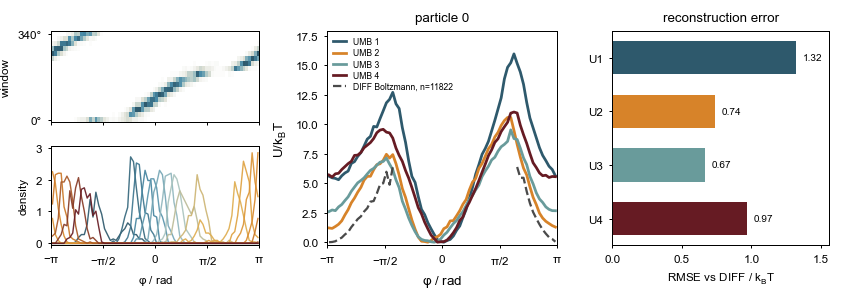

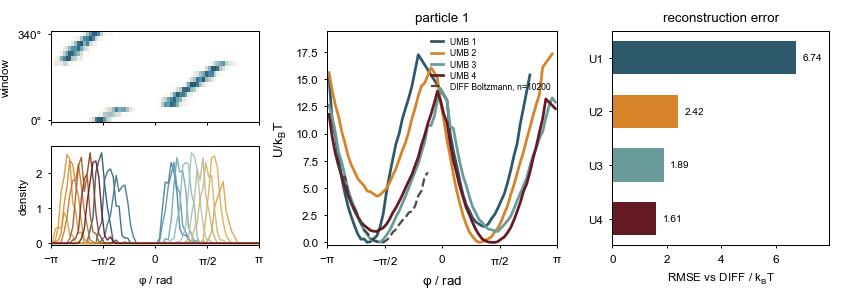

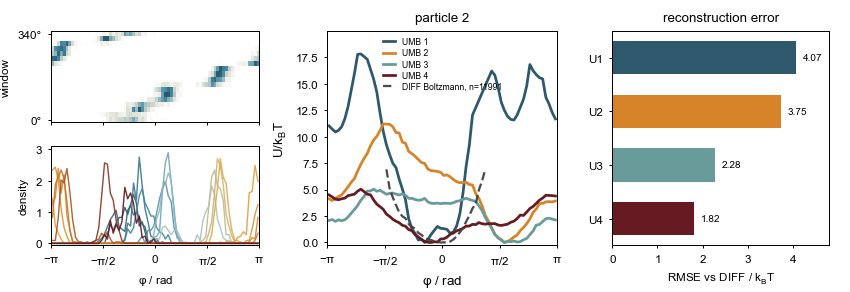

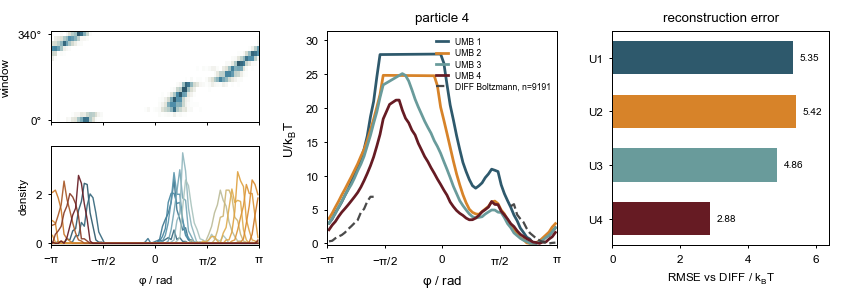

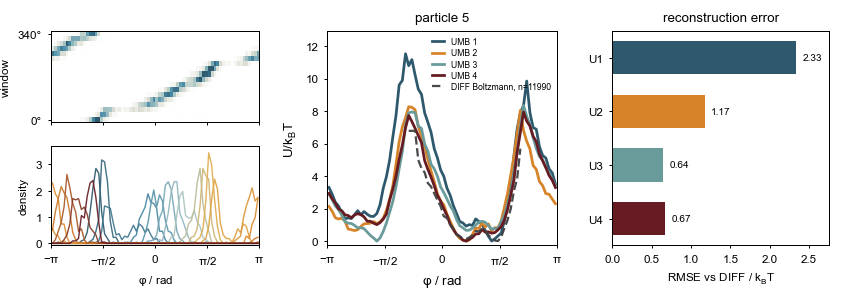

...

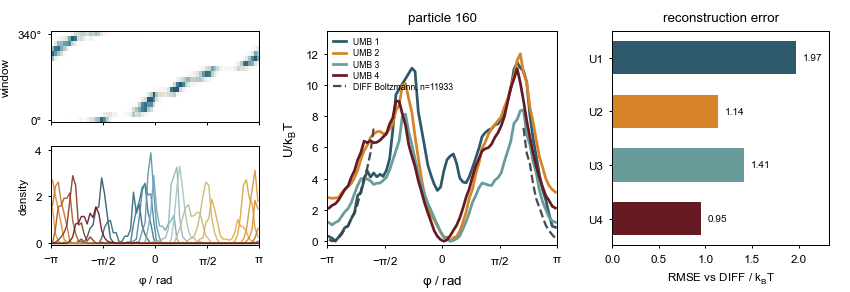

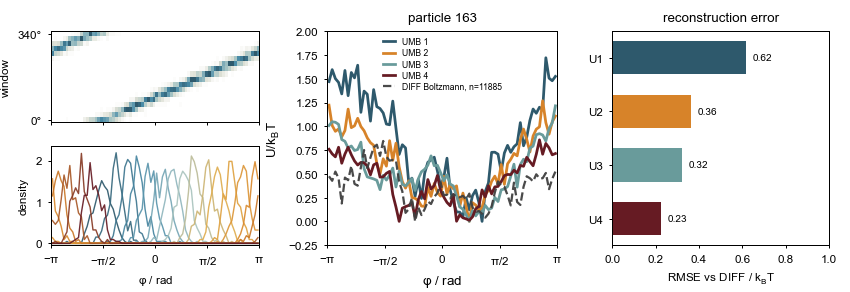

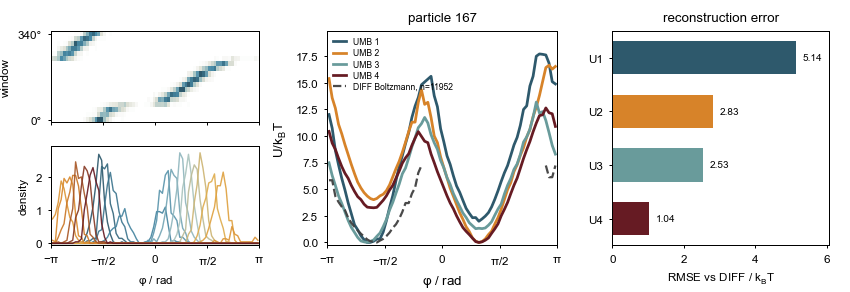

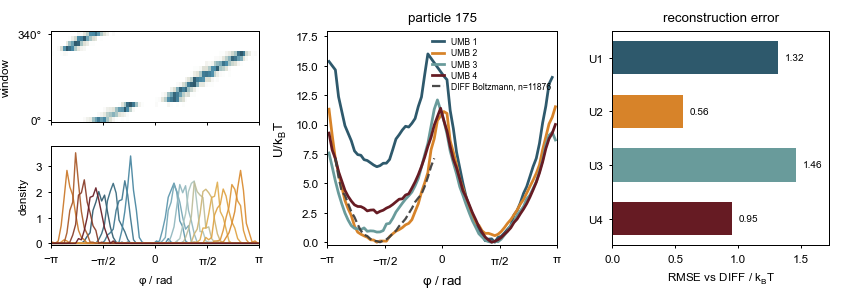

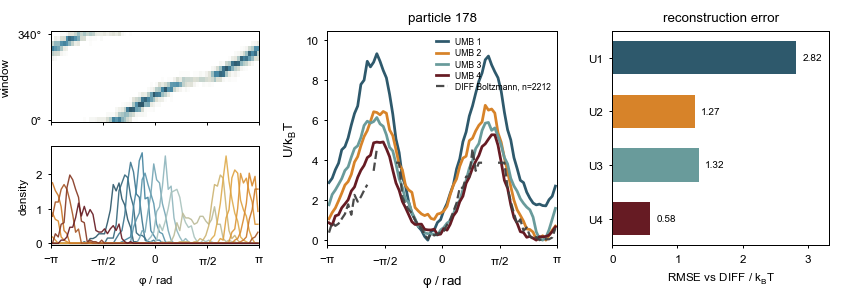

In [36]:
# if full_execution:
%matplotlib inline
plot_MBAR_reconstruction_results(
    m_list,
    particles=None,
    ck=CK_colors,
    center_mode="ensemble",
    bias_potential="cosine",
    max_particles=200,
    fig_width_mm=180,
    fig_height_mm=62,
    legend_fontsize=5.2,
    save_dir=None,
)

#### iii. Rotor gallery for point MBAR based reconstruction

In [37]:
def plot_MBAR_reconstruction_gallery(
    m_list,
    sampling_time_colors,
    particles=None,
    split_target_other=True,
    show_diff=True,
    show_consistency=True,
    show_rmse=True,
    center_mode="ensemble",
    bias_potential="cosine",
    spacing_order=(15, 20, 30),
    sampling_time_order_ms=(2.5, 5.0, 10.0, 20.0),
    ncols=4,
    nrows_per_page=6,
    panel_width_mm=36,
    panel_height_mm=30,
    shared_ylim=True,
    energy_tick_spacing_kBT=4.0,
    sort_by="particle",
    diff_pmin=1e-12,
    diff_hist_bins=None,
    full_lw=1.2,
    diff_lw=0.9,
    fontsize=7,
    title_fontsize=6.1,
    tick_fontsize=5.8,
    annotation_fontsize=5.2,
    rmse_panel_width_ratio=0.28,
    shared_rmse_ylim=True,
    rmse_ylim=None,
    C=CK_colors,
    save_dir=None,
    save_prefix="SI_MBAR_reconstruction_sampling_time_gallery",
    save_svg=True,
):
    import math
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from matplotlib.ticker import MultipleLocator

    if not isinstance(sampling_time_colors, dict) or not sampling_time_colors:
        raise ValueError("sampling_time_colors must be a non-empty dictionary.")

    C = C() if callable(C) else dict(C)
    C.setdefault("black", (0, 0, 0))
    C.setdefault("grey", (0.25, 0.25, 0.25))
    C.setdefault("midgrey", (0.45, 0.45, 0.45))

    sampling_time_colors = {float(key): tuple(value) for key, value in sampling_time_colors.items()}
    spacing_order = [int(round(float(spacing))) for spacing in spacing_order]
    sampling_time_order_ms = [float(value) for value in sampling_time_order_ms]
    show_rmse = bool(show_rmse and show_consistency)

    def flatten(values):
        if values is None:
            return []
        if isinstance(values, (list, tuple)):
            return [item for value in values for item in flatten(value)]
        return [values]

    def mm(value):
        return float(value) / 25.4

    def wrap_pi(phi):
        return (np.asarray(phi, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def zero_min(values):
        values = np.asarray(values, dtype=float).copy()
        finite = np.isfinite(values)
        if np.any(finite):
            values[finite] -= np.nanmin(values[finite])
        return values

    def measurement_name(m):
        try:
            return Path(str(m.path)).name
        except Exception:
            return "measurement"

    def natural_key(value):
        return [int(part) if part.isdigit() else part for part in re.split(r"(\d+)", str(value))]

    def parse_spacing(m):
        match = re.search(r"_(\d+(?:\.\d+)?)deg(?:-|_)", measurement_name(m), flags=re.IGNORECASE)
        return int(round(float(match.group(1)))) if match else None

    def parse_sampling_time_ms(m):
        tpf_s = getattr(m, "_average_tpf", None)

        if tpf_s is not None:
            try:
                tpf_s = float(tpf_s)
                if np.isfinite(tpf_s) and tpf_s > 0:
                    return 1000.0 * tpf_s
            except (TypeError, ValueError):
                pass

        match = re.search(r"(\d+(?:\.\d+)?)\s*ms", measurement_name(m), flags=re.IGNORECASE)
        return float(match.group(1)) if match else None

    def matching_sampling_time_key(sampling_time_ms):
        if sampling_time_ms is None or not np.isfinite(sampling_time_ms):
            return None

        keys = np.asarray(list(sampling_time_colors), dtype=float)
        nearest = float(keys[np.argmin(np.abs(keys - sampling_time_ms))])
        return nearest if np.isclose(nearest, sampling_time_ms, atol=0.05, rtol=0.01) else None

    def measurement_label(spacing_deg, sampling_time_ms):
        spacing_text = "unknown spacing" if spacing_deg is None else f"{int(spacing_deg)}°"
        sampling_text = "unknown frame time" if sampling_time_ms is None else f"{sampling_time_ms:g} ms"
        return f"{spacing_text}, {sampling_text}"

    def sampling_time_color(sampling_time_ms):
        key = matching_sampling_time_key(sampling_time_ms)
        return sampling_time_colors.get(key, C["midgrey"])

    def is_diff_measurement(m):
        return "DIFF" in str(getattr(m, "path", "")).upper()

    def is_umb_measurement(m):
        name = str(getattr(m, "path", "")).upper()
        return "UMB" in name and "DIFF" not in name

    def style_ax(ax):
        for spine in ax.spines.values():
            spine.set_color(C["black"])
            spine.set_linewidth(0.6)
        ax.tick_params(
            length=2.0,
            width=0.6,
            labelsize=tick_fontsize,
            direction="out",
            color=C["black"],
            labelcolor=C["black"],
        )
        ax.grid(False)

    def finite_limits(values, pad=0.08):
        finite_values = []

        for value in values:
            value = np.asarray(value, dtype=float)
            value = value[np.isfinite(value)]
            if value.size:
                finite_values.append(value)

        if not finite_values:
            return None

        finite_values = np.concatenate(finite_values)
        ymin = min(0.0, float(np.nanmin(finite_values)))
        ymax = max(0.0, float(np.nanmax(finite_values)))
        span = max(ymax - ymin, 1.0)
        return ymin - pad * span, ymax + pad * span

    def interp_periodic_no_gaps(phi_target, phi_source, values_source):
        phi_target = wrap_pi(phi_target)
        phi_source = wrap_pi(phi_source)
        values_source = np.asarray(values_source, dtype=float)

        keep_phi = np.isfinite(phi_source)
        phi_source = phi_source[keep_phi]
        values_source = values_source[keep_phi]

        if phi_source.size < 2:
            return np.full_like(phi_target, np.nan, dtype=float)

        order = np.argsort(phi_source)
        x = phi_source[order]
        y = values_source[order]
        out = np.full_like(phi_target, np.nan, dtype=float)
        finite = np.isfinite(y)

        if not np.any(finite):
            return out

        starts = np.flatnonzero(finite & np.r_[True, ~finite[:-1]])
        stops = np.flatnonzero(finite & np.r_[~finite[1:], True])

        for i0, i1 in zip(starts, stops):
            xs = x[i0:i1 + 1]
            ys = y[i0:i1 + 1]

            if len(xs) == 1:
                close = np.isclose(phi_target, xs[0], atol=1e-10)
                out[close] = ys[0]
                continue

            inside = (phi_target >= xs[0]) & (phi_target <= xs[-1])
            out[inside] = np.interp(phi_target[inside], xs, ys)

        return out

    def read_point_reconstruction(m):
        try:
            curves = m.reconstructed_energy_landscapes_by_center[center_mode][bias_potential]
        except Exception as error:
            raise KeyError(
                f"No stored MBAR reconstruction for center_mode={center_mode!r}, "
                f"bias_potential={bias_potential!r}."
            ) from error

        output = {}

        for particle, landscape in curves.items():
            if not isinstance(landscape, pd.DataFrame) or "phi" not in landscape.columns:
                continue

            if "U_mbar" in landscape.columns:
                energy_column = "U_mbar"
            elif "U_MBAR" in landscape.columns:
                energy_column = "U_MBAR"
            elif "U_wham" in landscape.columns:
                energy_column = "U_wham"
            else:
                continue

            phi = landscape["phi"].to_numpy(float)
            energy = landscape[energy_column].to_numpy(float)
            keep = np.isfinite(phi)
            phi = wrap_pi(phi[keep])
            energy = zero_min(energy[keep])
            order = np.argsort(phi)

            output[int(particle)] = {
                "phi": phi[order],
                "energy": energy[order],
            }

        return output

    def diff_boltzmann_curve(diff_measurements, particle, phi_grid):
        phi_all = []

        for m_diff in diff_measurements:
            locs = getattr(m_diff, "locs", None)

            if not isinstance(locs, pd.DataFrame) or "phi" not in locs.columns:
                continue

            if "group_int" in locs.columns:
                particle_column = "group_int"
            elif "group" in locs.columns:
                particle_column = "group"
            else:
                continue

            phi = locs.loc[
                locs[particle_column].astype(int) == int(particle),
                "phi",
            ].to_numpy(float)

            phi = wrap_pi(phi[np.isfinite(phi)])

            if phi.size:
                phi_all.append(phi)

        if not phi_all:
            return None

        phi = np.concatenate(phi_all)
        n_bins = int(diff_hist_bins) if diff_hist_bins is not None else int(len(phi_grid))
        edges = np.linspace(-np.pi, np.pi, n_bins + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])
        counts, _ = np.histogram(phi, bins=edges)
        counts = counts.astype(float)
        normalization = float(np.sum(counts)) * float(edges[1] - edges[0])

        if normalization <= 0:
            return None

        probability = counts / normalization
        energy = np.full(n_bins, np.nan, dtype=float)
        valid = counts > 0

        energy[valid] = -np.log(np.maximum(probability[valid], float(diff_pmin)))

        if np.any(valid):
            energy[valid] -= np.nanmin(energy[valid])

        return {
            "phi": centers,
            "energy": energy,
            "counts": counts,
            "n_locs": int(len(phi)),
        }

    def compare_reconstruction_to_diff(
        phi_reconstruction,
        energy_reconstruction,
        phi_diff,
        energy_diff,
    ):
        phi_diff = np.asarray(phi_diff, dtype=float)
        energy_diff = np.asarray(energy_diff, dtype=float)
        valid_diff = np.isfinite(phi_diff) & np.isfinite(energy_diff)
        n_diff_bins = int(np.sum(valid_diff))

        empty = {
            "n_bins": n_diff_bins,
            "coverage_deg": np.nan,
            "vertical_offset_kBT": np.nan,
            "rmse_kBT": np.nan,
            "mae_kBT": np.nan,
            "corr": np.nan,
        }

        if n_diff_bins < 3:
            return empty

        phi_eval = phi_diff[valid_diff]
        diffusion = energy_diff[valid_diff]
        reconstruction = interp_periodic_no_gaps(
            phi_eval,
            phi_reconstruction,
            energy_reconstruction,
        )

        keep = np.isfinite(reconstruction) & np.isfinite(diffusion)
        n_overlap = int(np.sum(keep))

        if n_overlap < 3:
            empty["n_bins"] = n_overlap
            return empty

        reconstruction = reconstruction[keep]
        diffusion = diffusion[keep]
        vertical_offset = float(np.mean(reconstruction - diffusion))
        residual = reconstruction - (diffusion + vertical_offset)
        rmse = float(np.sqrt(np.mean(residual ** 2)))
        mae = float(np.mean(np.abs(residual)))

        correlation = (
            float(np.corrcoef(reconstruction, diffusion)[0, 1])
            if np.std(reconstruction) > 0 and np.std(diffusion) > 0
            else np.nan
        )

        coverage_deg = float(n_overlap * 360.0 / len(energy_diff))

        return {
            "n_bins": n_overlap,
            "coverage_deg": coverage_deg,
            "vertical_offset_kBT": vertical_offset,
            "rmse_kBT": rmse,
            "mae_kBT": mae,
            "corr": correlation,
        }

    all_measurements = flatten(m_list)
    diff_measurements = [m for m in all_measurements if is_diff_measurement(m)]
    umb_measurements = [m for m in all_measurements if is_umb_measurement(m)]
    measurement_records = []

    for m in umb_measurements:
        try:
            reconstructions = read_point_reconstruction(m)
        except Exception:
            continue

        if not reconstructions:
            continue

        spacing_deg = parse_spacing(m)
        sampling_time_ms = parse_sampling_time_ms(m)

        if spacing_deg is None or sampling_time_ms is None:
            continue

        measurement_records.append({
            "measurement": m,
            "measurement_name": measurement_name(m),
            "spacing_deg": int(spacing_deg),
            "sampling_time_ms": float(sampling_time_ms),
            "label": measurement_label(spacing_deg, sampling_time_ms),
            "color": sampling_time_color(sampling_time_ms),
            "reconstructions": reconstructions,
        })

    if not measurement_records:
        raise ValueError(
            "No valid stored MBAR reconstruction was found in the supplied UMB measurements."
        )

    spacing_order_map = {spacing: index for index, spacing in enumerate(spacing_order)}
    sampling_time_order_map = {sampling_time: index for index, sampling_time in enumerate(sampling_time_order_ms)}

    measurement_records.sort(
        key=lambda record: (
            sampling_time_order_map.get(matching_sampling_time_key(record["sampling_time_ms"]), len(sampling_time_order_map)),
            record["sampling_time_ms"],
            spacing_order_map.get(record["spacing_deg"], len(spacing_order_map)),
            record["spacing_deg"],
            natural_key(record["measurement_name"]),
        )
    )

    label_counts = {}

    for record in measurement_records:
        label = record["label"]
        label_counts[label] = label_counts.get(label, 0) + 1

    label_seen = {}

    for record in measurement_records:
        label = record["label"]

        if label_counts[label] > 1:
            label_seen[label] = label_seen.get(label, 0) + 1
            record["label"] = f"{label} run {label_seen[label]}"

    target_particles = set()

    for record in measurement_records:
        target_particles.update(
            int(particle)
            for particle in getattr(record["measurement"], "target_rotors", [])
        )

    available_particles = sorted({
        int(particle)
        for record in measurement_records
        for particle in record["reconstructions"]
    })

    if particles is None:
        particles_to_plot = available_particles
    else:
        particles_to_plot = [
            int(particle)
            for particle in particles
            if int(particle) in available_particles
        ]

    if not particles_to_plot:
        raise ValueError(
            "None of the requested particles has a stored MBAR reconstruction."
        )

    particle_data = {}

    for particle in particles_to_plot:
        overlays = []

        for record in measurement_records:
            if particle not in record["reconstructions"]:
                continue

            reconstruction = record["reconstructions"][particle]

            overlays.append({
                "measurement": record["measurement"],
                "measurement_name": record["measurement_name"],
                "spacing_deg": record["spacing_deg"],
                "sampling_time_ms": record["sampling_time_ms"],
                "label": record["label"],
                "color": record["color"],
                "phi": np.asarray(reconstruction["phi"], dtype=float),
                "energy": np.asarray(reconstruction["energy"], dtype=float),
            })

        if not overlays:
            continue

        phi_reference = overlays[0]["phi"].copy()

        for overlay in overlays[1:]:
            same_grid = overlay["phi"].shape == phi_reference.shape

            if same_grid:
                same_grid = (
                    np.nanmax(np.abs(overlay["phi"] - phi_reference)) < 1e-10
                )

            if not same_grid:
                overlay["energy"] = interp_periodic_no_gaps(
                    phi_reference,
                    overlay["phi"],
                    overlay["energy"],
                )
                overlay["phi"] = phi_reference.copy()

        diff_curve = (
            diff_boltzmann_curve(diff_measurements, particle, phi_reference)
            if show_diff
            else None
        )

        for overlay in overlays:
            overlay["consistency"] = (
                compare_reconstruction_to_diff(
                    overlay["phi"],
                    overlay["energy"],
                    diff_curve["phi"],
                    diff_curve["energy"],
                )
                if diff_curve is not None
                else None
            )

        particle_data[particle] = {
            "phi": phi_reference,
            "overlays": overlays,
            "diff": diff_curve,
        }

    particles_to_plot = [
        particle
        for particle in particles_to_plot
        if particle in particle_data
    ]

    if sort_by == "particle":
        particles_to_plot = sorted(particles_to_plot)
    elif sort_by in {"consistency", "rmse"}:
        def mean_rmse(particle):
            values = []

            for overlay in particle_data[particle]["overlays"]:
                metric = overlay["consistency"]

                if metric is not None and np.isfinite(metric["rmse_kBT"]):
                    values.append(metric["rmse_kBT"])

            return float(np.nanmean(values)) if values else np.inf

        particles_to_plot = sorted(particles_to_plot, key=mean_rmse)
    else:
        raise ValueError(
            "sort_by must be 'particle', 'consistency', or 'rmse'."
        )

    if split_target_other:
        gallery_groups = [
            {
                "name": "target",
                "particles": [
                    particle
                    for particle in particles_to_plot
                    if particle in target_particles
                ],
            },
            {
                "name": "other",
                "particles": [
                    particle
                    for particle in particles_to_plot
                    if particle not in target_particles
                ],
            },
        ]
    else:
        gallery_groups = [{
            "name": "all",
            "particles": particles_to_plot,
        }]

    gallery_groups = [
        group
        for group in gallery_groups
        if group["particles"]
    ]

    panels_per_page = int(ncols) * int(nrows_per_page)

    if panels_per_page <= 0:
        raise ValueError("ncols and nrows_per_page must be positive.")

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

    for group in gallery_groups:
        group_values = []
        group_rmse = []

        for particle in group["particles"]:
            pdata = particle_data[particle]
            group_values.extend(
                overlay["energy"]
                for overlay in pdata["overlays"]
            )

            if pdata["diff"] is not None:
                group_values.append(pdata["diff"]["energy"])

            for overlay in pdata["overlays"]:
                metric = overlay["consistency"]

                if metric is not None and np.isfinite(metric["rmse_kBT"]):
                    group_rmse.append(metric["rmse_kBT"])

        group_ylim = finite_limits(group_values) if shared_ylim else None

        if rmse_ylim is not None:
            group_rmse_ylim = tuple(rmse_ylim)
        elif shared_rmse_ylim and group_rmse:
            group_rmse_ylim = (
                0,
                max(1.1, 1.12 * float(np.nanmax(group_rmse))),
            )
        else:
            group_rmse_ylim = None

        n_pages = int(
            math.ceil(len(group["particles"]) / panels_per_page)
        )

        for page in range(n_pages):
            start = page * panels_per_page
            stop = min(
                start + panels_per_page,
                len(group["particles"]),
            )
            page_particles = group["particles"][start:stop]

            figure = plt.figure(
                figsize=(
                    mm(panel_width_mm * ncols),
                    mm(panel_height_mm * nrows_per_page),
                )
            )

            outer = figure.add_gridspec(
                nrows_per_page,
                ncols,
                left=0.055,
                right=0.990,
                bottom=0.070,
                top=0.945,
                wspace=0.24,
                hspace=0.28,
            )

            for index, particle in enumerate(page_particles):
                row, column = divmod(index, ncols)

                if show_rmse:
                    inner = outer[row, column].subgridspec(
                        1,
                        2,
                        width_ratios=[
                            1.0,
                            float(rmse_panel_width_ratio),
                        ],
                        wspace=0.08,
                    )
                    ax = figure.add_subplot(inner[0, 0])
                    ax_rmse = figure.add_subplot(inner[0, 1])
                else:
                    ax = figure.add_subplot(outer[row, column])
                    ax_rmse = None

                pdata = particle_data[particle]

                for overlay in pdata["overlays"]:
                    ax.plot(
                        overlay["phi"],
                        overlay["energy"],
                        color=overlay["color"],
                        lw=full_lw,
                        label=overlay["label"],
                        zorder=3,
                    )

                if pdata["diff"] is not None:
                    ax.plot(
                        pdata["diff"]["phi"],
                        pdata["diff"]["energy"],
                        color=C["black"],
                        lw=diff_lw,
                        ls="--",
                        label="DIFF",
                        zorder=5,
                    )

                ax.axhline(
                    0,
                    color=C["grey"],
                    lw=0.45,
                    alpha=0.55,
                    zorder=0,
                )
                ax.set_xlim(-np.pi, np.pi)
                ax.set_xticks([-np.pi, 0, np.pi])
                ax.set_title(
                    f"rotor {particle}",
                    fontsize=title_fontsize,
                    pad=2,
                )

                if shared_ylim and group_ylim is not None:
                    ax.set_ylim(*group_ylim)
                elif not shared_ylim:
                    local_values = [
                        overlay["energy"]
                        for overlay in pdata["overlays"]
                    ]

                    if pdata["diff"] is not None:
                        local_values.append(pdata["diff"]["energy"])

                    local_ylim = finite_limits(local_values)

                    if local_ylim is not None:
                        ax.set_ylim(*local_ylim)

                if energy_tick_spacing_kBT is not None:
                    tick_spacing = float(energy_tick_spacing_kBT)

                    if not np.isfinite(tick_spacing) or tick_spacing <= 0:
                        raise ValueError(
                            "energy_tick_spacing_kBT must be None "
                            "or a positive number."
                        )

                    _, ymax = ax.get_ylim()
                    ymin = -0.4
                    ymax = np.ceil(ymax / tick_spacing) * tick_spacing

                    if ymax <= ymin:
                        ymax = ymin + tick_spacing

                    ax.set_ylim(ymin, ymax)
                    ax.yaxis.set_major_locator(
                        MultipleLocator(tick_spacing)
                    )

                if row == nrows_per_page - 1:
                    ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"])
                    ax.set_xlabel(
                        r"$\varphi$ / rad",
                        fontsize=fontsize,
                    )
                else:
                    ax.set_xticklabels([])

                if column == 0:
                    ax.set_ylabel(
                        r"$G(\varphi)$ / $k_\mathrm{B}T$",
                        fontsize=fontsize,
                    )
                else:
                    ax.set_yticklabels([])

                style_ax(ax)

                if show_rmse:
                    rmse_values = []
                    rmse_colors = []

                    for overlay in pdata["overlays"]:
                        metric = overlay["consistency"]
                        rmse_values.append(
                            metric["rmse_kBT"]
                            if metric is not None
                            else np.nan
                        )
                        rmse_colors.append(overlay["color"])

                    x = np.arange(len(rmse_values))
                    finite_rmse = np.isfinite(rmse_values)

                    if np.any(finite_rmse):
                        x_finite = x[finite_rmse]
                        values_finite = np.asarray(
                            rmse_values,
                            dtype=float,
                        )[finite_rmse]
                        colors_finite = [
                            rmse_colors[i]
                            for i in x_finite
                        ]

                        ax_rmse.bar(
                            x_finite,
                            values_finite,
                            width=0.72,
                            color=colors_finite,
                            edgecolor="none",
                        )

                    ax_rmse.set_xlim(
                        -0.6,
                        max(len(rmse_values) - 0.4, 0.6),
                    )
                    ax_rmse.set_xticks([])
                    ax_rmse.set_yticks([1.0])
                    ax_rmse.set_yticklabels(["1"])

                    if group_rmse_ylim is not None:
                        ax_rmse.set_ylim(*group_rmse_ylim)
                    elif np.any(finite_rmse):
                        ymax = max(
                            1.1,
                            1.12
                            * float(
                                np.nanmax(
                                    np.asarray(
                                        rmse_values,
                                        dtype=float,
                                    )[finite_rmse]
                                )
                            ),
                        )
                        ax_rmse.set_ylim(0, ymax)
                    else:
                        ax_rmse.set_ylim(0, 1.1)

                    style_ax(ax_rmse)
                    ax_rmse.spines["top"].set_visible(False)
                    ax_rmse.spines["left"].set_visible(False)
                    ax_rmse.spines["right"].set_visible(True)
                    ax_rmse.spines["bottom"].set_visible(True)
                    ax_rmse.yaxis.tick_right()
                    ax_rmse.tick_params(
                        axis="x",
                        bottom=True,
                        labelbottom=False,
                        length=0,
                    )
                    ax_rmse.tick_params(
                        axis="y",
                        labelsize=max(tick_fontsize - 0.8, 4.0),
                        pad=1,
                    )

            legend_handles = {}

            for particle in page_particles:
                for overlay in particle_data[particle]["overlays"]:
                    legend_handles.setdefault(
                        overlay["label"],
                        plt.Line2D(
                            [],
                            [],
                            color=overlay["color"],
                            lw=full_lw,
                        ),
                    )

            if show_diff:
                legend_handles["DIFF"] = plt.Line2D(
                    [],
                    [],
                    color=C["black"],
                    lw=diff_lw,
                    ls="--",
                )

            if legend_handles:
                figure.legend(
                    legend_handles.values(),
                    legend_handles.keys(),
                    frameon=False,
                    fontsize=tick_fontsize,
                    loc="upper center",
                    ncol=max(1, len(legend_handles)),
                    bbox_to_anchor=(0.52, 0.997),
                    handlelength=1.5,
                    columnspacing=1.2,
                )

            if save_dir is not None:
                suffix = (
                    f"_{group['name']}_page_{page + 1:02d}"
                )

                figure.savefig(
                    save_dir / f"{save_prefix}{suffix}.png",
                    dpi=300,
                    bbox_inches="tight",
                )

                if save_svg:
                    figure.savefig(
                        save_dir / f"{save_prefix}{suffix}.svg",
                        bbox_inches="tight",
                    )

            plt.show()
            plt.close(figure)

    return None

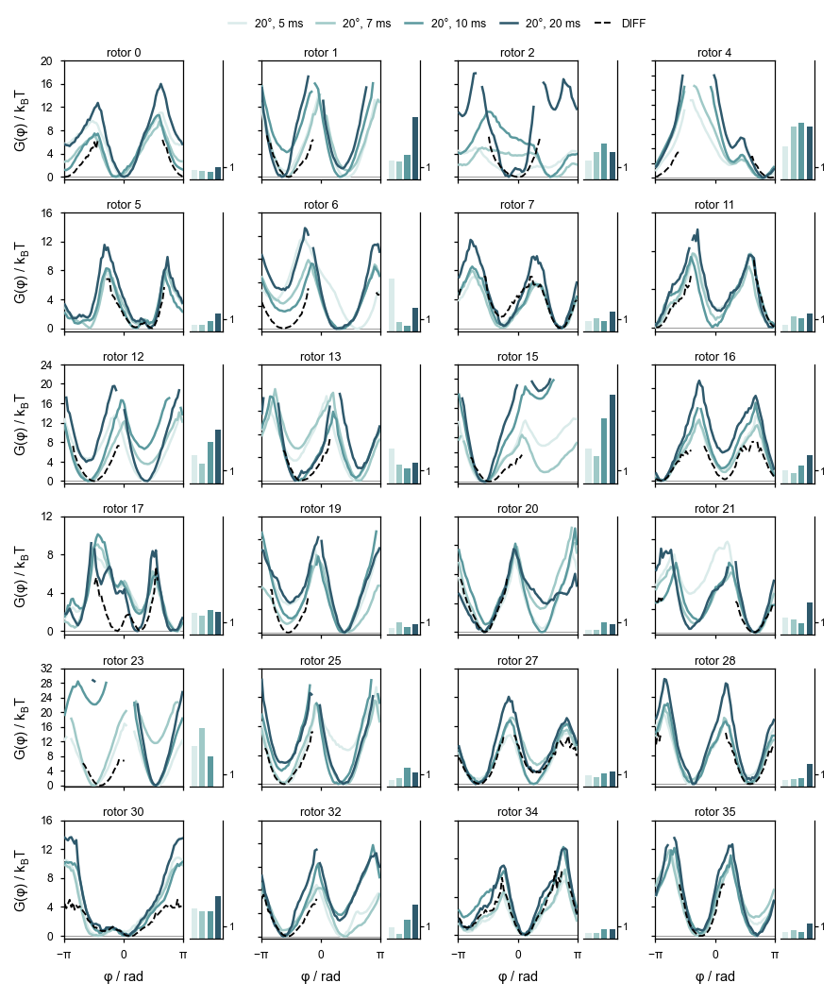

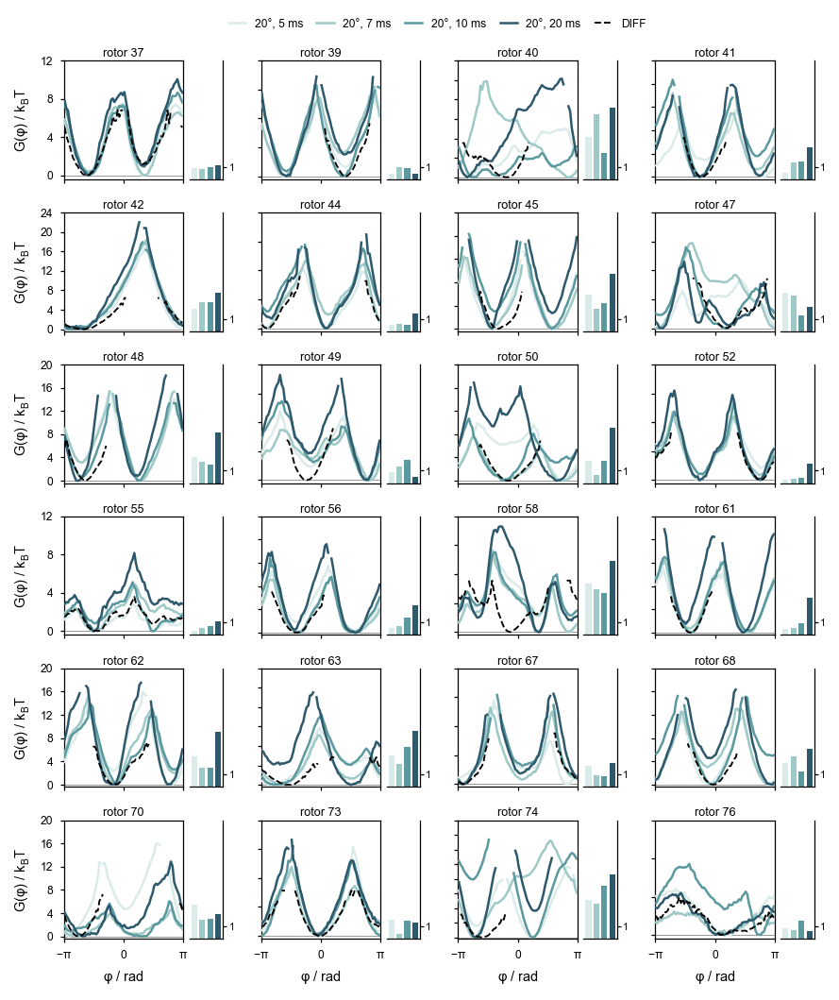

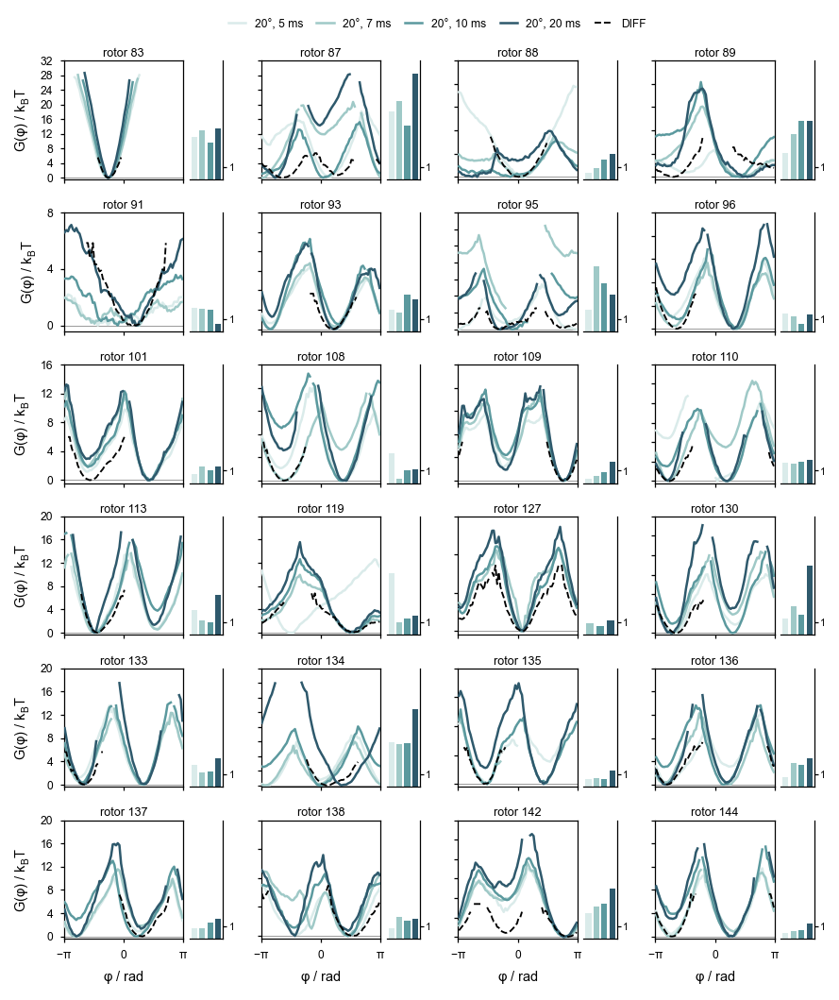

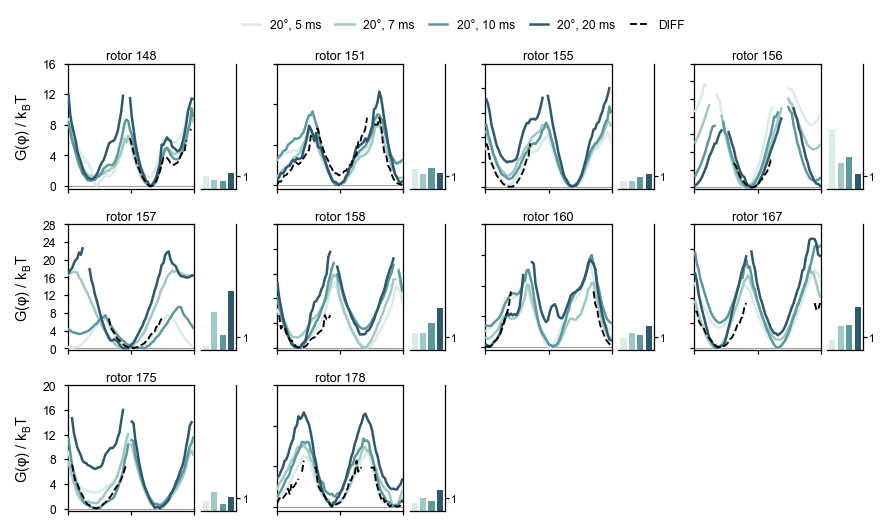

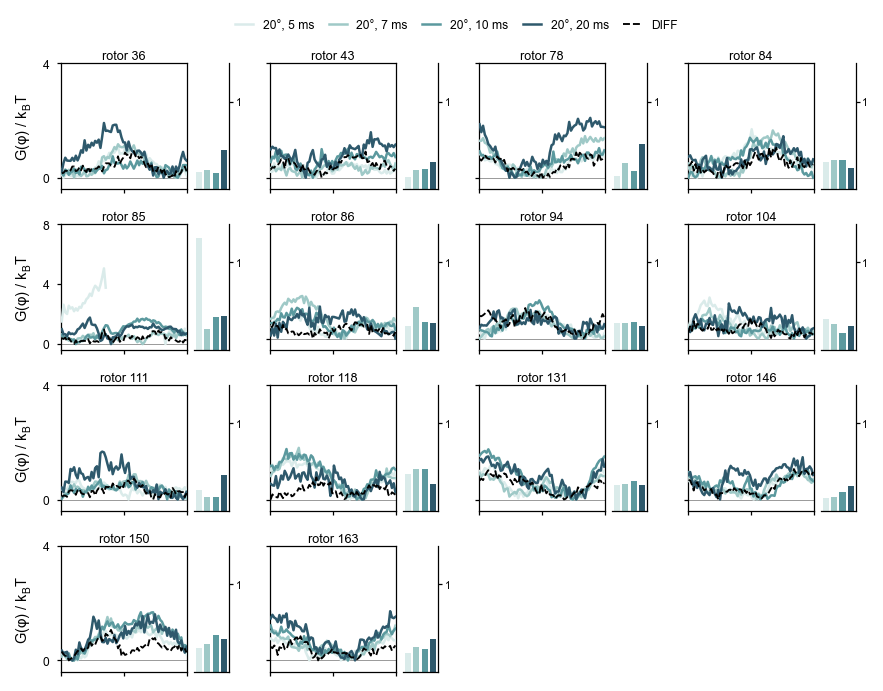

In [38]:
plot_MBAR_reconstruction_gallery(
    m_list=m_list,
    sampling_time_colors=target_exposure_time_colors,
    sampling_time_order_ms=(5.0, 7.0, 10.0, 20.0),
    particles=None,
    split_target_other=True,
    show_diff=True,
    show_consistency=True,
    show_rmse=False,
    center_mode="ensemble",
    bias_potential="cosine",
    ncols=4,
    nrows_per_page=6,
    panel_width_mm=36,
    panel_height_mm=30,
    shared_ylim=False,
    energy_tick_spacing_kBT=4.0,
    sort_by="particle",
    C=CK_colors,
    save_dir=None,
    save_prefix=None,
)

#### iv. Select target rotor ensemble for subsequent study

In [121]:
selected_target_rotors = [0,1,7,27,28,35,37,39,44,52,56,61,67,68,93,96,101,113,137,144,155,158]
selected_target_rotors = [0,1,7,27,28,35,37,39,44,52,56,61,67,68,93,96,101,113,137,144,155,158,4,175]

## _[SI | Statistical uncertainty of free-energy landscape reconstruction from finite trajectories]_

In [40]:
def compute_MBAR_statistical_uncertainty_blocks(
    m_list,
    particles=None,
    center_mode="ensemble",
    bias_potential="cosine",
    uncertainty_mode=("target_only", "full"),
    nbins=72,
    pmin_nan=1e-12,
    n_bootstrap=500,
    block_s_target=0.25,
    block_s_calib=0.25,
    ci=(2.5, 97.5),
    seed=1,
    min_keep=200,
    min_calib_locs_per_window=50,
    kappa_rescale_calibration=1.0,
    kappa_rescale_target=1.388,
    rolling_mean_kappa_ensemble=True,
    rolling_mean_kappa_window=3,
    mbar_tol=1e-7,
    mbar_max_iter=1000,
    mbar_damp=0.8,
):
    """
    Block-bootstrap uncertainty of target-rotor MBAR reconstructions.

    target_only:
        block-bootstrap target trajectories;
        keep the stored point-calibration fixed.

    full:
        block-bootstrap target trajectories;
        block-bootstrap trajectories of the fixed m.calibration_rotors;
        recompute ensemble centers and kappa.

    particles=None:
        analyze all m.target_rotors.

    m_list=m_list:
        analyze every UMB measurement.

    m_list=m_list[1]:
        analyze only the selected UMB measurement.

    Stores
    ------
    m.mbar_statistical_uncertainty_blocks = {
        "evals": evals,
        "summary_long": summary_long,
    }

    Nothing is returned.
    """
    import numpy as np
    import pandas as pd
    from pathlib import Path
    from tqdm.auto import tqdm

    # ------------------------------------------------------------------
    # helpers
    # ------------------------------------------------------------------

    def flatten(values):
        if isinstance(values, (list, tuple)):
            out = []
            for value in values:
                out.extend(flatten(value))
            return out
        return [values]

    def measurement_name(m):
        return Path(str(getattr(m, "path", "UMB measurement"))).name

    def wrap_pi(phi):
        return (np.asarray(phi, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def zero_min(U):
        U = np.asarray(U, dtype=float).copy()
        finite = np.isfinite(U)

        if np.any(finite):
            U[finite] -= np.nanmin(U[finite])

        return U

    def align_to_reference(U, U_ref):
        U = np.asarray(U, dtype=float).copy()
        U_ref = np.asarray(U_ref, dtype=float)
        finite = np.isfinite(U) & np.isfinite(U_ref)

        if np.sum(finite) >= 3:
            U -= np.nanmedian(U[finite] - U_ref[finite])
        else:
            U = zero_min(U)

        return U

    def logsumexp(a, axis=None):
        a = np.asarray(a, dtype=float)
        amax = np.max(a, axis=axis, keepdims=True)
        out = amax + np.log(np.sum(np.exp(a - amax), axis=axis, keepdims=True))

        return np.squeeze(out) if axis is None else np.squeeze(out, axis=axis)

    def circular_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.nan

        z = np.mean(np.exp(1j * phi))

        return float(np.angle(z)) if np.abs(z) > 1e-15 else np.nan

    def periodic_mean(values, window):
        values = np.asarray(values, dtype=float)
        window = int(window)

        if window <= 1:
            return values.copy()

        if window % 2 == 0:
            window += 1

        half = window // 2
        out = np.full(values.size, np.nan)

        for i in range(values.size):
            idx = [(i + shift) % values.size for shift in range(-half, half + 1)]
            local = values[idx]
            local = local[np.isfinite(local)]

            if local.size:
                out[i] = np.mean(local)

        return out

    def is_umb(m):
        name = str(getattr(m, "path", "")).upper()

        has_windows = (
            hasattr(m, "protocol")
            and isinstance(m.protocol, dict)
            and any(isinstance(phase, str) and phase.startswith("deg-") for phase in m.protocol)
        )

        return "DIFF" not in name and ("UMB" in name or has_windows)

    def protocol_bounds(value):
        while (
            isinstance(value, (list, tuple))
            and len(value) == 1
            and isinstance(value[0], (list, tuple, dict))
        ):
            value = value[0]

        if isinstance(value, dict):
            start = value.get(
                "start",
                value.get("start_time", value.get("t_start", value.get("t0"))),
            )

            stop = value.get(
                "end",
                value.get(
                    "end_time",
                    value.get("t_end", value.get("t1", value.get("stop"))),
                ),
            )

            if start is None or stop is None:
                raise ValueError(f"Cannot parse protocol bounds: {value}")

            return float(start), float(stop)

        if isinstance(value, (list, tuple)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(f"Cannot parse protocol bounds: {value}")

    def ensure_time(m):
        if "t" in m.locs.columns:
            return

        m.locs = m.locs.copy()

        if "averagetime" in m.locs.columns:
            m.locs["t"] = m.locs["averagetime"].astype(float)

        elif "time" in m.locs.columns:
            m.locs["t"] = m.locs["time"].astype(float)

        elif "time_s" in m.locs.columns:
            m.locs["t"] = m.locs["time_s"].astype(float)

        elif "frame" in m.locs.columns:
            dt = float(getattr(m, "_average_tpf", 0.005))
            m.locs["t"] = m.locs["frame"].astype(float) * dt

        else:
            raise KeyError(
                "m.locs needs 't', 'averagetime', 'time', 'time_s', or 'frame'."
            )

    def lag1(values):
        values = np.asarray(values, dtype=float)

        if values.size < 3:
            return 0.0

        a = values[:-1] - np.mean(values[:-1])
        b = values[1:] - np.mean(values[1:])
        denominator = np.sqrt(np.sum(a * a) * np.sum(b * b)) + 1e-30

        return float(np.sum(a * b) / denominator)

    def circular_lag1(phi):
        rho = 0.5 * (lag1(np.cos(phi)) + lag1(np.sin(phi)))

        return float(np.clip(rho, -0.99, 0.99))

    def collect_target_traces(m, particle, phases):
        ensure_time(m)

        if "group" not in m.locs.columns or "phi" not in m.locs.columns:
            raise KeyError("m.locs needs 'group' and 'phi'.")

        data = m.locs.loc[
            m.locs["group"].astype(int) == int(particle),
            ["phi", "t"],
        ].copy()

        if data.empty:
            raise ValueError(f"Particle {particle}: no localizations.")

        data = data.sort_values("t", kind="mergesort")
        data["phi"] = wrap_pi(data["phi"].to_numpy(float))

        trim_s = float(m.autocorrelation_trim_s)
        dt = float(getattr(m, "_average_tpf", 0.005))
        n_trim = max(5, int(np.ceil(trim_s / dt)))

        traces = []

        for phase in phases:
            start, stop = protocol_bounds(m.protocol[str(phase)])
            selected = (data["t"] >= start) & (data["t"] < stop)

            phi = data.loc[selected, "phi"].to_numpy(float)
            t = data.loc[selected, "t"].to_numpy(float)

            if phi.size < min_keep:
                traces.append(None)
                continue

            if phi.size > n_trim + 5:
                phi = phi[n_trim:]
                t = t[n_trim:]

            if phi.size < min_keep:
                traces.append(None)
                continue

            finite = np.isfinite(phi) & np.isfinite(t)
            phi = wrap_pi(phi[finite])
            t = t[finite]

            rho = circular_lag1(phi)
            denominator = 1 + rho
            ess = phi.size * (1 - rho) / denominator if denominator > 1e-12 else float(phi.size)

            if ess < 10:
                traces.append(None)
                continue

            traces.append({
                "phase": str(phase),
                "phi": phi,
                "t": t,
            })

        return traces

    def collect_calibration_traces(m, calibration_rotors, phases):
        ensure_time(m)

        trim_s = float(m.autocorrelation_trim_s)
        dt = float(getattr(m, "_average_tpf", 0.005))
        n_trim = max(5, int(np.ceil(trim_s / dt)))

        cache = {}

        for particle in calibration_rotors:
            data = m.locs.loc[
                m.locs["group"].astype(int) == int(particle),
                ["phi", "t"],
            ].copy()

            if data.empty:
                continue

            data = data.sort_values("t", kind="mergesort")
            data["phi"] = wrap_pi(data["phi"].to_numpy(float))

            particle_traces = {}

            for phase in phases:
                start, stop = protocol_bounds(m.protocol[str(phase)])
                selected = (data["t"] >= start) & (data["t"] < stop)

                phi = data.loc[selected, "phi"].to_numpy(float)
                t = data.loc[selected, "t"].to_numpy(float)

                if phi.size > n_trim + 5:
                    phi = phi[n_trim:]
                    t = t[n_trim:]

                finite = np.isfinite(phi) & np.isfinite(t)
                phi = wrap_pi(phi[finite])
                t = t[finite]

                if phi.size >= min_calib_locs_per_window:
                    particle_traces[str(phase)] = {
                        "phi": phi,
                        "t": t,
                    }

            if particle_traces:
                cache[int(particle)] = particle_traces

        return cache

    def block_bootstrap(phi, t, block_s, rng):
        phi = np.asarray(phi, dtype=float)
        t = np.asarray(t, dtype=float)

        if phi.size == 0:
            return phi.copy()

        if phi.size < 3 or block_s is None or block_s <= 0:
            idx = rng.integers(0, phi.size, size=phi.size)
            return wrap_pi(phi[idx])

        dt = np.nanmedian(np.diff(t)) if t.size > 1 else np.nan

        if not np.isfinite(dt) or dt <= 0:
            block_n = max(1, int(round(phi.size / 10)))
        else:
            block_n = max(1, int(round(float(block_s) / dt)))

        block_n = min(block_n, phi.size)

        starts = np.arange(0, phi.size, block_n, dtype=int)
        blocks = [phi[start:min(start + block_n, phi.size)] for start in starts]

        if len(blocks) == 1:
            idx = rng.integers(0, phi.size, size=phi.size)
            return wrap_pi(phi[idx])

        n_blocks = int(np.ceil(phi.size / block_n))
        selected = rng.integers(0, len(blocks), size=n_blocks)

        return wrap_pi(np.concatenate([blocks[i] for i in selected])[:phi.size])

    def vm_kappa(phi, center):
        delta = wrap_pi(np.asarray(phi, dtype=float) - float(center))
        delta = delta[np.isfinite(delta)]

        if delta.size == 0:
            return np.nan

        R = np.hypot(np.mean(np.cos(delta)), np.mean(np.sin(delta)))

        if not np.isfinite(R) or R < 1e-8:
            return np.nan

        if R < 0.53:
            kappa = 2 * R + R**3 + 5 * R**5 / 6

        elif R < 0.85:
            kappa = -0.4 + 1.39 * R + 0.43 / max(1 - R, 1e-12)

        else:
            kappa = 1 / max(R**3 - 4 * R**2 + 3 * R, 1e-12)

        return float(max(kappa, 0))

    def run_mbar(samples, centers, kappa):
        counts = np.asarray([len(sample) for sample in samples], dtype=float)

        if len(samples) < 2:
            raise ValueError("MBAR needs at least two umbrella windows.")

        if np.any(counts <= 0):
            raise ValueError("Empty umbrella window encountered.")

        phi = wrap_pi(np.concatenate(samples))

        centers = np.asarray(centers, dtype=float)
        kappa = np.asarray(kappa, dtype=float)

        if centers.size != len(samples) or kappa.size != len(samples):
            raise ValueError(
                f"MBAR size mismatch: {len(samples)} samples, "
                f"{centers.size} centers, {kappa.size} kappa values."
            )

        if not np.all(np.isfinite(centers)):
            raise ValueError("Non-finite umbrella center encountered.")

        if not np.all(np.isfinite(kappa) & (kappa > 0)):
            raise ValueError("Non-finite or non-positive kappa encountered.")

        delta = wrap_pi(phi[None, :] - centers[:, None])

        if bias_potential == "cosine":
            u_kn = kappa[:, None] * (1 - np.cos(delta))

        elif bias_potential == "harmonic":
            u_kn = 0.5 * kappa[:, None] * delta**2

        else:
            raise ValueError("bias_potential must be 'cosine' or 'harmonic'.")

        log_counts = np.log(counts)
        f_k = np.zeros(len(samples))
        converged = False

        for iteration in range(int(mbar_max_iter)):
            log_denominator = logsumexp(
                log_counts[:, None] + f_k[:, None] - u_kn,
                axis=0,
            )

            f_new = np.asarray([
                -logsumexp(-u_kn[i] - log_denominator)
                for i in range(len(f_k))
            ])

            f_new -= f_new[0]
            f_next = (1 - float(mbar_damp)) * f_k + float(mbar_damp) * f_new

            max_delta = float(np.max(np.abs(f_next - f_k)))
            f_k = f_next

            if max_delta < float(mbar_tol):
                converged = True
                break

        log_denominator = logsumexp(
            log_counts[:, None] + f_k[:, None] - u_kn,
            axis=0,
        )

        log_weights = -log_denominator
        log_weights -= logsumexp(log_weights)

        weights = np.exp(log_weights)

        edges = np.linspace(-np.pi, np.pi, int(nbins) + 1)
        phi_grid = 0.5 * (edges[:-1] + edges[1:])
        dphi = float(edges[1] - edges[0])

        probability, _ = np.histogram(phi, bins=edges, weights=weights)
        probability = probability.astype(float) / dphi

        normalization = probability.sum() * dphi

        if normalization > 0:
            probability /= normalization

        energy = np.full(probability.size, np.nan)
        positive = probability > 0

        energy[positive] = -np.log(probability[positive])

        if pmin_nan is not None and pmin_nan > 0:
            energy[probability < float(pmin_nan)] = np.nan

        weight_square_sum = np.sum(weights**2)

        return {
            "phi": phi_grid,
            "P": probability,
            "U": zero_min(energy),
            "converged": converged,
            "n_iter": iteration + 1,
            "ess": 1 / weight_square_sum if weight_square_sum > 0 else np.nan,
        }

    def point_parameters(m, phases):
        center_df = m.center_bias["by_window"]
        kappa_df = m.kappa_bias["by_angle"]

        center_column = "ensemble_phi0" if center_mode == "ensemble" else "command_phi0"

        center_map = dict(
            zip(
                center_df["phase"].astype(str),
                center_df[center_column].astype(float),
            )
        )

        kappa_map = dict(
            zip(
                kappa_df["phase"].astype(str),
                kappa_df["kappa_mean_used_target"].astype(float),
            )
        )

        centers = np.asarray([center_map[str(phase)] for phase in phases], dtype=float)
        kappa = np.asarray([kappa_map[str(phase)] for phase in phases], dtype=float)

        if str(m.kappa_bias["mode"]) == "global":
            kappa[:] = float(m.kappa_bias["global_target"])

        return wrap_pi(centers), kappa

    def command_centers_for_phases(m, phases):
        center_df = m.center_bias["by_window"]

        command_map = dict(
            zip(
                center_df["phase"].astype(str),
                center_df["command_phi0"].astype(float),
            )
        )

        return np.asarray([command_map[str(phase)] for phase in phases], dtype=float)

    def bootstrap_calibration(
        calibration_cache,
        phases,
        command_centers,
        point_centers,
        point_kappa,
        kappa_mode_use,
        rng,
    ):
        n_windows = len(phases)

        centers = np.full(n_windows, np.nan)
        kappa_raw = np.full(n_windows, np.nan)

        for j, phase in enumerate(phases):
            rotor_centers = []
            rotor_kappas = []

            for traces in calibration_cache.values():
                trace = traces.get(str(phase))

                if trace is None:
                    continue

                phi = block_bootstrap(
                    trace["phi"],
                    trace["t"],
                    block_s_calib,
                    rng,
                )

                if phi.size < min_calib_locs_per_window:
                    continue

                rotor_center = circular_mean(phi)

                if not np.isfinite(rotor_center):
                    continue

                rotor_kappa = vm_kappa(phi, rotor_center)

                if np.isfinite(rotor_kappa) and rotor_kappa > 0:
                    rotor_centers.append(rotor_center)
                    rotor_kappas.append(rotor_kappa)

            if rotor_centers:
                centers[j] = circular_mean(rotor_centers)

            if rotor_kappas:
                kappa_raw[j] = np.mean(rotor_kappas)

        missing_center = ~np.isfinite(centers)
        centers[missing_center] = point_centers[missing_center]

        finite_kappa = np.isfinite(kappa_raw) & (kappa_raw > 0)

        if np.any(finite_kappa):
            fill_kappa = np.nanmedian(kappa_raw[finite_kappa])
        else:
            fill_kappa = np.nanmedian(point_kappa / float(kappa_rescale_target))

        kappa_raw[~finite_kappa] = fill_kappa

        if rolling_mean_kappa_ensemble:
            kappa_smoothed = periodic_mean(
                kappa_raw,
                rolling_mean_kappa_window,
            )

            missing = ~np.isfinite(kappa_smoothed) | (kappa_smoothed <= 0)
            kappa_smoothed[missing] = kappa_raw[missing]

            kappa_raw = kappa_smoothed

        if kappa_mode_use == "global":
            kappa_raw[:] = np.nanmean(kappa_raw)

        elif kappa_mode_use != "by_angle":
            raise ValueError(
                "m.kappa_bias['mode'] must be 'global' or 'by_angle'."
            )

        centers_used = centers if center_mode == "ensemble" else command_centers
        kappa_used = kappa_raw * float(kappa_rescale_target)

        return wrap_pi(centers_used), kappa_used

    # ------------------------------------------------------------------
    # modes
    # ------------------------------------------------------------------

    modes = [uncertainty_mode] if isinstance(uncertainty_mode, str) else list(uncertainty_mode)
    modes = [str(mode).lower().replace("-", "_").strip() for mode in modes]

    invalid_modes = [mode for mode in modes if mode not in {"target_only", "full"}]

    if invalid_modes:
        raise ValueError(
            f"Unknown uncertainty modes: {invalid_modes}. "
            "Use 'target_only' and/or 'full'."
        )

    # ------------------------------------------------------------------
    # measurements
    # ------------------------------------------------------------------

    measurements = [m for m in flatten(m_list) if is_umb(m)]

    if not measurements:
        raise ValueError("No UMB measurements found.")

    for m in tqdm(
        measurements,
        desc="UMB measurements",
        total=len(measurements),
        dynamic_ncols=True,
    ):
        required = [
            "target_rotors",
            "calibration_rotors",
            "center_bias",
            "kappa_bias",
            "reconstructed_energy_landscapes_by_center",
        ]

        missing = [name for name in required if not hasattr(m, name)]

        if missing:
            raise AttributeError(
                f"{measurement_name(m)}: missing {missing}. "
                "Run run_MBAR_reconstruction(...) first."
            )

        try:
            point_landscapes = (
                m.reconstructed_energy_landscapes_by_center[
                    center_mode
                ][
                    bias_potential
                ]
            )

        except Exception as error:
            raise KeyError(
                f"{measurement_name(m)}: no stored MBAR reconstruction for "
                f"center_mode={center_mode!r}, bias_potential={bias_potential!r}."
            ) from error

        target_rotors = list(map(int, m.target_rotors))

        if particles is None:
            particles_to_compute = target_rotors.copy()
        else:
            particles_to_compute = [
                int(particle)
                for particle in particles
                if int(particle) in target_rotors
            ]

        particles_to_compute = [
            particle
            for particle in particles_to_compute
            if particle in point_landscapes
        ]

        if not particles_to_compute:
            raise ValueError(
                f"{measurement_name(m)}: no selected target rotors "
                "have a stored point-MBAR reconstruction."
            )

        calibration_rotors = list(map(int, m.calibration_rotors))
        kappa_mode_use = str(m.kappa_bias["mode"])

        evals = {}
        summary_parts = []

        # --------------------------------------------------------------
        # modes
        # --------------------------------------------------------------

        for mode in modes:
            curves = {}
            rows = []

            for particle in tqdm(
                particles_to_compute,
                desc=f"{mode} | target rotors",
                total=len(particles_to_compute),
                leave=False,
                dynamic_ncols=True,
            ):
                try:
                    reference_df = point_landscapes[int(particle)]

                    phi_ref = reference_df["phi"].to_numpy(float)
                    U_ref = zero_min(reference_df["U_mbar"].to_numpy(float))
                    P_ref = reference_df["P_mbar"].to_numpy(float)

                    all_phases = m.center_bias["by_window"]["phase"].astype(str).tolist()

                    target_traces = collect_target_traces(
                        m,
                        particle,
                        all_phases,
                    )

                    keep = np.asarray(
                        [trace is not None for trace in target_traces],
                        dtype=bool,
                    )

                    if np.sum(keep) < 3:
                        raise ValueError(
                            "Fewer than three valid target umbrella windows."
                        )

                    phases = [
                        phase
                        for phase, keep_window in zip(all_phases, keep)
                        if keep_window
                    ]

                    target_traces = [
                        trace
                        for trace in target_traces
                        if trace is not None
                    ]

                    point_centers, point_kappa = point_parameters(
                        m,
                        phases,
                    )

                    command_centers = command_centers_for_phases(
                        m,
                        phases,
                    )

                    calibration_cache = {}

                    if mode == "full":
                        calibration_cache = collect_calibration_traces(
                            m,
                            calibration_rotors,
                            phases,
                        )

                        if not calibration_cache:
                            raise ValueError(
                                "No usable calibration trajectories."
                            )

                    U_boot = []
                    kappa_boot = []
                    phi0_boot = []
                    ess_boot = []
                    n_iter_boot = []

                    n_failed = 0
                    first_error = None

                    rng = np.random.default_rng(
                        seed
                        + 100000 * modes.index(mode)
                        + int(particle)
                    )

                    for _ in tqdm(
                        range(int(n_bootstrap)),
                        desc=f"particle {particle}",
                        total=int(n_bootstrap),
                        leave=False,
                        dynamic_ncols=True,
                    ):
                        try:
                            target_samples = [
                                block_bootstrap(
                                    trace["phi"],
                                    trace["t"],
                                    block_s_target,
                                    rng,
                                )
                                for trace in target_traces
                            ]

                            if mode == "full":
                                centers, kappa = bootstrap_calibration(
                                    calibration_cache=calibration_cache,
                                    phases=phases,
                                    command_centers=command_centers,
                                    point_centers=point_centers,
                                    point_kappa=point_kappa,
                                    kappa_mode_use=kappa_mode_use,
                                    rng=rng,
                                )

                            else:
                                centers = point_centers.copy()
                                kappa = point_kappa.copy()

                            result = run_mbar(
                                samples=target_samples,
                                centers=centers,
                                kappa=kappa,
                            )

                            U_boot.append(
                                align_to_reference(
                                    result["U"],
                                    U_ref,
                                )
                            )

                            kappa_boot.append(kappa.copy())
                            phi0_boot.append(centers.copy())
                            ess_boot.append(result["ess"])
                            n_iter_boot.append(result["n_iter"])

                        except Exception as error:
                            n_failed += 1

                            if first_error is None:
                                first_error = f"{type(error).__name__}: {error}"

                    if not U_boot:
                        raise RuntimeError(
                            f"All bootstrap replicates failed for particle "
                            f"{particle}, mode {mode}. "
                            f"First bootstrap error: {first_error}"
                        )

                    U_boot = np.asarray(U_boot, dtype=float)
                    kappa_boot = np.asarray(kappa_boot, dtype=float)
                    phi0_boot = np.asarray(phi0_boot, dtype=float)

                    q_low, q_high = map(float, ci)

                    U_median, U_low, U_high = np.nanpercentile(
                        U_boot,
                        [50, q_low, q_high],
                        axis=0,
                    )

                    U_std = np.nanstd(
                        U_boot,
                        axis=0,
                        ddof=1,
                    )

                    kappa_median, kappa_low, kappa_high = np.nanpercentile(
                        kappa_boot,
                        [50, q_low, q_high],
                        axis=0,
                    )

                    phi0_delta = wrap_pi(
                        phi0_boot
                        - point_centers[None, :]
                    )

                    phi0_median, phi0_low, phi0_high = np.nanpercentile(
                        phi0_delta,
                        [50, q_low, q_high],
                        axis=0,
                    )

                    finite = np.isfinite(U_ref)

                    G_range = (
                        np.nanmax(U_ref[finite])
                        - np.nanmin(U_ref[finite])
                        if np.any(finite)
                        else np.nan
                    )

                    sigma_mean = float(np.nanmean(U_std))
                    sigma_p90 = float(np.nanpercentile(U_std, 90))
                    ci_width_mean = float(np.nanmean(U_high - U_low))

                    landscape_df = pd.DataFrame({
                        "particle": int(particle),
                        "phi": phi_ref,
                        "U_MBAR_point": U_ref,
                        "P_MBAR_point": P_ref,
                        "U_boot_median": U_median,
                        "U_boot_low": U_low,
                        "U_boot_high": U_high,
                        "U_boot_std": U_std,
                    })

                    calibration_df = pd.DataFrame({
                        "phase": phases,
                        "phi0_point": point_centers,
                        "phi0_delta_median": phi0_median,
                        "phi0_delta_low": phi0_low,
                        "phi0_delta_high": phi0_high,
                        "phi0_delta_median_deg": np.rad2deg(phi0_median),
                        "phi0_delta_low_deg": np.rad2deg(phi0_low),
                        "phi0_delta_high_deg": np.rad2deg(phi0_high),
                        "kappa_point": point_kappa,
                        "kappa_boot_median": kappa_median,
                        "kappa_boot_low": kappa_low,
                        "kappa_boot_high": kappa_high,
                    })

                    curves[int(particle)] = {
                        "landscape_df": landscape_df,
                        "calibration_df": calibration_df,
                        "U_boot_curves": U_boot,
                        "kappa_boot_curves": kappa_boot,
                        "phi0_boot_curves": phi0_boot,
                        "phase_list": phases,
                        "calib_particles": calibration_rotors,
                    }

                    rows.append({
                        "particle": int(particle),
                        "uncertainty_mode": mode,
                        "status": "ok",
                        "error": "",
                        "n_bootstrap_requested": int(n_bootstrap),
                        "n_bootstrap_success": int(len(U_boot)),
                        "n_bootstrap_failed": int(n_failed),
                        "G_range_MBAR_kBT": float(G_range),
                        "sigma_G_mean_kBT": sigma_mean,
                        "sigma_G_p90_kBT": sigma_p90,
                        "CI_width_G_mean_kBT": ci_width_mean,
                        "relative_sigma_G_mean": (
                            sigma_mean / G_range
                            if np.isfinite(G_range) and G_range > 0
                            else np.nan
                        ),
                        "bootstrap_ESS_median": float(np.nanmedian(ess_boot)),
                        "bootstrap_n_iter_median": float(np.nanmedian(n_iter_boot)),
                        "n_target_locs_total": int(
                            sum(len(trace["phi"]) for trace in target_traces)
                        ),
                        "n_windows": int(len(phases)),
                        "n_calibration_rotors": int(len(calibration_rotors)),
                    })

                except Exception as error:
                    rows.append({
                        "particle": int(particle),
                        "uncertainty_mode": mode,
                        "status": "failed",
                        "error": f"{type(error).__name__}: {error}",
                    })

            summary_df = pd.DataFrame(rows)

            evals[mode] = {
                "curves": curves,
                "summary_df": summary_df,
            }

            summary_parts.append(summary_df)

        m.mbar_statistical_uncertainty_blocks = {
            "evals": evals,
            "summary_long": pd.concat(
                summary_parts,
                ignore_index=True,
            ),
        }

    return None

In [122]:
compute_MBAR_statistical_uncertainty_blocks(
    m_list=m_list,
    particles=selected_target_rotors ,
    center_mode="ensemble",
    bias_potential="cosine",
    uncertainty_mode=("full"),
    nbins=72,
    n_bootstrap=20,
    block_s_target=0.25,
    block_s_calib=0.25,
    kappa_rescale_target=1.388,
)

UMB measurements:   0%|                                                                          | 0/4 [00:00<…

full | target rotors:   0%|                                                                     | 0/24 [00:00<…

particle 0:   0%|                                                                               | 0/20 [00:00<…

particle 1:   0%|                                                                               | 0/20 [00:00<…

C:\Users\ga78vok\.conda\envs\analysis\lib\site-packages\numpy\lib\nanfunctions.py:1583: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,
C:\Users\ga78vok\.conda\envs\analysis\lib\site-packages\numpy\lib\nanfunctions.py:1878: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


particle 7:   0%|                                                                               | 0/20 [00:00<…

... (130 outputs left out)

particle 158:   0%|                                                                             | 0/20 [00:00<…

particle 4:   0%|                                                                               | 0/20 [00:00<…

C:\Users\ga78vok\.conda\envs\analysis\lib\site-packages\numpy\lib\nanfunctions.py:1583: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,
C:\Users\ga78vok\.conda\envs\analysis\lib\site-packages\numpy\lib\nanfunctions.py:1878: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


particle 175:   0%|                                                                             | 0/20 [00:00<…

## Reconstruction for an equal number of raw data samples

In [42]:
def run_MBAR_sampling_controls(
    m_list,
    nbins=72,
    kappa_mode="by_angle",
    bias_potential="cosine",
    center_mode="ensemble",
    kappa_rescale_calibration=1.0,
    kappa_rescale_target=1.388,
    pmin_nan=1e-12,
    min_keep=200,
    rolling_mean_kappa_ensemble=True,
    rolling_mean_kappa_window=3,
    total_bias_time_s=None,
    sample_modes=("first_n", "spaced_n"),
    particles=None,
    reference_tpf_ms=20.0,
    apply_autocorrelation_trim=True,
    mbar_tol=1e-7,
    mbar_max_iter=1000,
    mbar_damp=0.8,
):
    """
    Lean unbinned MBAR reconstruction.

    Equal-time analysis
    -------------------
    total_bias_time_s=None:
        Use the complete recorded duration of every umbrella window.

    total_bias_time_s=60:
        Use the first

            total_bias_time_s / number_of_windows

        seconds of every deg-* window before the optional autocorrelation trim.

        Examples:
            15° spacing: 24 windows -> 2.5 s/window
            20° spacing: 18 windows -> 3.333 s/window
            30° spacing: 12 windows -> 5.0 s/window

    Sampling controls
    -----------------
    sample_modes=("first_n", "spaced_n"):
        Use all post-trim samples.

    "first_n":
        Use the first N post-trim samples, where N is the nominal number of
        samples generated at reference_tpf_ms over the same post-trim duration.

    "spaced_n":
        Use N evenly spaced post-trim samples across the complete selected
        window. This matches sample count while retaining full time coverage.

    Results are stored under m.mbar_reconstructions[storage_key]. Only
    sample_mode="all" also updates the legacy m.energy_landscapes attributes.

    The stored m.protocol and m.locs are not modified.
    """

    import numpy as np
    import pandas as pd
    from pathlib import Path
    from tqdm.auto import tqdm

    particle_col = "group"
    phi0_offset_rad = -np.pi / 2
    edges_cache = {}

    if total_bias_time_s is not None:
        total_bias_time_s = float(total_bias_time_s)

        if not np.isfinite(total_bias_time_s) or total_bias_time_s <= 0:
            raise ValueError(
                "total_bias_time_s must be None or a positive finite number."
            )

    sample_modes = [str(mode).lower() for mode in sample_modes]
    if not sample_modes or any(mode not in {"first_n", "spaced_n"} for mode in sample_modes):
        raise ValueError("sample_modes may contain only 'first_n' and 'spaced_n'.")
    sample_modes = list(dict.fromkeys(sample_modes))
    selected_particles = None if particles is None else set(int(value) for value in particles)
    reference_tpf_ms = float(reference_tpf_ms)
    if not np.isfinite(reference_tpf_ms) or reference_tpf_ms <= 0:
        raise ValueError("reference_tpf_ms must be positive and finite.")
    reference_tpf_s = reference_tpf_ms / 1000.0

    def flatten(obj):
        if obj is None:
            return []

        if isinstance(obj, (list, tuple)):
            return [item for sub in obj for item in flatten(sub)]

        return [obj]

    def as_int_list(values):
        if values is None or isinstance(values, (str, bytes)):
            return []

        try:
            return sorted(set(int(value) for value in list(values)))
        except Exception:
            try:
                return [int(values)]
            except Exception:
                return []

    def measurement_name(m, index=None):
        try:
            return Path(str(m.path)).name
        except Exception:
            return (
                f"m_list[{index}]"
                if index is not None
                else "unknown measurement"
            )

    def wrap_pi(phi):
        return (
            np.asarray(phi, dtype=float) + np.pi
        ) % (2 * np.pi) - np.pi

    def zero_min(values):
        values = np.asarray(values, dtype=float).copy()
        finite = np.isfinite(values)

        if np.any(finite):
            values[finite] -= np.nanmin(values[finite])

        return values

    def logsumexp(values, axis=None):
        values = np.asarray(values, dtype=float)

        if axis is None:
            vmax = np.max(values)

            if not np.isfinite(vmax):
                return float(vmax)

            return float(
                vmax
                + np.log(
                    np.sum(
                        np.exp(values - vmax)
                    )
                )
            )

        vmax = np.max(values, axis=axis, keepdims=True)

        result = vmax + np.log(
            np.sum(
                np.exp(values - vmax),
                axis=axis,
                keepdims=True,
            )
        )

        return np.squeeze(result, axis=axis)

    def circular_mean(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size == 0:
            return np.nan

        z = np.mean(np.exp(1j * phi))

        return (
            float(np.angle(z))
            if np.abs(z) >= 1e-15
            else np.nan
        )

    def circular_std(phi):
        phi = np.asarray(phi, dtype=float)
        phi = phi[np.isfinite(phi)]

        if phi.size < 2:
            return np.nan

        R = np.clip(
            np.abs(np.mean(np.exp(1j * phi))),
            1e-15,
            1.0,
        )

        return float(np.sqrt(-2 * np.log(R)))

    def circular_rolling_nanmean(values, window):
        values = np.asarray(values, dtype=float)

        if values.size == 0:
            return values.copy()

        window = int(window)

        if window <= 1:
            return values.copy()

        if window % 2 == 0:
            window += 1

        half = window // 2
        output = np.full(values.size, np.nan)

        for index in range(values.size):
            indices = [
                (index + shift) % values.size
                for shift in range(-half, half + 1)
            ]

            local = values[indices]
            local = local[np.isfinite(local)]

            if local.size:
                output[index] = float(np.mean(local))

        return output

    def bias_names(value):
        value = str(value).lower()

        if value == "cosine":
            return ["cosine"]

        if value == "harmonic":
            return ["harmonic"]

        if value == "both":
            return ["harmonic", "cosine"]

        raise ValueError(
            "bias_potential must be 'cosine', 'harmonic', or 'both'."
        )

    def center_names(value):
        value = str(value).lower()

        if value == "command":
            return ["command"]

        if value == "ensemble":
            return ["ensemble"]

        if value == "both":
            return ["command", "ensemble"]

        raise ValueError(
            "center_mode must be 'command', 'ensemble', or 'both'."
        )

    def has_deg_protocol(m):
        return (
            hasattr(m, "protocol")
            and isinstance(m.protocol, dict)
            and any(
                isinstance(key, str)
                and key.startswith("deg-")
                for key in m.protocol
            )
        )

    def is_umb(m):
        name = str(getattr(m, "path", "")).upper()

        if "DIFF" in name:
            return False

        if "UMB" in name:
            return True

        return has_deg_protocol(m)

    def ensure_time_column(m):
        if not hasattr(m, "locs") or m.locs is None:
            raise ValueError("m.locs is missing.")

        if "t" in m.locs.columns:
            return

        m.locs = m.locs.copy()

        if "averagetime" in m.locs.columns:
            m.locs["t"] = m.locs["averagetime"].astype(float)

        elif "time" in m.locs.columns:
            m.locs["t"] = m.locs["time"].astype(float)

        elif "time_s" in m.locs.columns:
            m.locs["t"] = m.locs["time_s"].astype(float)

        elif "frame" in m.locs.columns:
            dt = float(getattr(m, "_average_tpf", 0.005))
            m.locs["t"] = m.locs["frame"].astype(float) * dt

        else:
            raise ValueError(
                "m.locs needs 't', 'averagetime', 'time', "
                "'time_s', or 'frame'."
            )

    def protocol_bounds(value):
        while (
            isinstance(value, (list, tuple))
            and len(value) == 1
            and isinstance(value[0], (list, tuple, dict))
        ):
            value = value[0]

        if isinstance(value, dict):
            start = value.get(
                "start",
                value.get(
                    "start_time",
                    value.get(
                        "t_start",
                        value.get("t0"),
                    ),
                ),
            )

            stop = value.get(
                "end",
                value.get(
                    "end_time",
                    value.get(
                        "t_end",
                        value.get(
                            "t1",
                            value.get("stop"),
                        ),
                    ),
                ),
            )

            if start is None or stop is None:
                raise ValueError(
                    f"Cannot parse protocol bounds from {value}."
                )

            return float(start), float(stop)

        if isinstance(value, (list, tuple)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(
            f"Cannot parse protocol bounds from {value}."
        )

    def phase_deg(phase):
        return float(
            str(phase).split("-")[1].split("_")[0]
        )

    def protocol_windows(m):
        if not has_deg_protocol(m):
            raise ValueError(
                "No deg-* windows found in m.protocol."
            )

        rows = []

        for phase, bounds in m.protocol.items():
            if (
                not isinstance(phase, str)
                or not phase.startswith("deg-")
            ):
                continue

            try:
                deg = phase_deg(phase)
                start, stop = protocol_bounds(bounds)
            except Exception:
                continue

            rows.append({
                "phase": str(phase),
                "deg": float(deg),
                "command_phi0": float(
                    wrap_pi(
                        np.deg2rad(deg)
                        + phi0_offset_rad
                    )
                ),
                "start": float(start),
                "stop": float(stop),
                "recorded_duration_s": float(stop - start),
            })

        if not rows:
            raise ValueError(
                "No valid deg-* windows could be parsed."
            )

        windows = (
            pd.DataFrame(rows)
            .sort_values("command_phi0")
            .reset_index(drop=True)
        )

        windows["window_index"] = np.arange(
            len(windows),
            dtype=int,
        )

        return windows

    def infer_spacing_deg(windows):
        degrees = np.sort(
            np.mod(
                windows["deg"].to_numpy(float),
                360,
            )
        )

        if len(degrees) < 2:
            return np.nan

        differences = np.diff(
            np.r_[degrees, degrees[0] + 360]
        )

        differences = differences[
            np.isfinite(differences)
            & (differences > 1e-9)
        ]

        return (
            float(np.median(differences))
            if differences.size
            else np.nan
        )

    def get_column(df, candidates):
        for column in candidates:
            if column in df.columns:
                return column

        raise KeyError(
            f"Could not find any of these columns: {candidates}\n"
            f"Available columns:\n{list(df.columns)}"
        )

    def build_stored_calibration(
        m,
        calibration_rotors,
        windows,
    ):
        stored = getattr(
            m,
            "kappa_calibration_by_window",
            None,
        )

        if (
            not isinstance(stored, pd.DataFrame)
            or len(stored) == 0
        ):
            raise ValueError(
                "m.kappa_calibration_by_window is missing or empty. "
                "Run filter_calibration_rotors(...) first."
            )

        df = stored.copy()

        particle_col_stored = get_column(
            df,
            ["particle"],
        )

        phase_col = get_column(
            df,
            ["phase"],
        )

        kappa_col = get_column(
            df,
            [
                "kappa",
                "kappa_vm",
                "kappa_theta_over_kBT_rad2",
            ],
        )

        raw_center_col = get_column(
            df,
            ["mu_fit", "mu_fit_rad"],
        )

        calibration_set = set(
            map(int, calibration_rotors)
        )

        df = df[
            df[particle_col_stored]
            .astype(int)
            .isin(calibration_set)
        ].copy()

        if len(df) == 0:
            raise ValueError(
                "None of m.calibration_rotors are present in "
                "m.kappa_calibration_by_window."
            )

        rows = []

        for protocol_row in windows.itertuples():
            phase = str(protocol_row.phase)

            group = df[
                df[phase_col].astype(str) == phase
            ].copy()

            kappa = group[kappa_col].to_numpy(float)
            kappa = kappa[
                np.isfinite(kappa)
                & (kappa > 0)
            ]

            fitted_centers = group[
                raw_center_col
            ].to_numpy(float)

            fitted_centers = fitted_centers[
                np.isfinite(fitted_centers)
            ]

            kappa_mean = (
                float(np.mean(kappa))
                if kappa.size
                else np.nan
            )

            kappa_std = (
                float(np.std(kappa, ddof=1))
                if kappa.size > 1
                else np.nan
            )

            ensemble_phi0 = circular_mean(
                fitted_centers
            )

            if not np.isfinite(ensemble_phi0):
                ensemble_phi0 = float(
                    protocol_row.command_phi0
                )

            delta = float(
                wrap_pi(
                    ensemble_phi0
                    - protocol_row.command_phi0
                )
            )

            rows.append({
                "phase": phase,
                "deg": float(protocol_row.deg),
                "command_phi0": float(
                    protocol_row.command_phi0
                ),
                "command_phi0_deg": float(
                    np.rad2deg(
                        protocol_row.command_phi0
                    )
                ),
                "ensemble_phi0": float(
                    wrap_pi(ensemble_phi0)
                ),
                "ensemble_phi0_deg": float(
                    np.rad2deg(
                        wrap_pi(ensemble_phi0)
                    )
                ),
                "delta_ensemble_minus_command": delta,
                "delta_ensemble_minus_command_deg": float(
                    np.rad2deg(delta)
                ),
                "center_circstd": circular_std(
                    fitted_centers
                ),
                "n_calibration_rotors": int(
                    fitted_centers.size
                ),
                "kappa_mean_raw": kappa_mean,
                "kappa_std_raw": kappa_std,
            })

        calibration = (
            pd.DataFrame(rows)
            .sort_values("command_phi0")
            .reset_index(drop=True)
        )

        rolling = circular_rolling_nanmean(
            calibration[
                "kappa_mean_raw"
            ].to_numpy(float),
            rolling_mean_kappa_window,
        )

        calibration[
            "kappa_mean_rolling_raw"
        ] = rolling

        if rolling_mean_kappa_ensemble:
            calibration[
                "kappa_mean_used_raw"
            ] = rolling

            kappa_source = (
                f"rolling_mean_"
                f"{int(rolling_mean_kappa_window)}"
            )

        else:
            calibration[
                "kappa_mean_used_raw"
            ] = calibration["kappa_mean_raw"]

            kappa_source = "per_window_mean"

        used = calibration[
            "kappa_mean_used_raw"
        ].to_numpy(float)

        finite = np.isfinite(used) & (used > 0)

        if not np.any(finite):
            raise ValueError(
                "No finite stored kappa values are available."
            )

        return (
            calibration,
            float(np.mean(used[finite])),
            kappa_source,
        )

    def get_rotor_classes(m):
        calibration_rotors = as_int_list(
            getattr(m, "calibration_rotors", None)
        )

        target_rotors = as_int_list(
            getattr(m, "target_rotors", None)
        )

        overlap = sorted(
            set(calibration_rotors)
            & set(target_rotors)
        )

        if overlap:
            raise ValueError(
                f"Rotors cannot be both calibration and target: "
                f"{overlap}"
            )

        rotor_class = {
            int(particle): "calibration"
            for particle in calibration_rotors
        }

        rotor_class.update({
            int(particle): "target"
            for particle in target_rotors
        })

        return (
            calibration_rotors,
            target_rotors,
            sorted(rotor_class),
            rotor_class,
        )

    def lag1_corr(values):
        values = np.asarray(values, dtype=float)

        if values.size < 3:
            return 0.0

        a = values[:-1] - np.mean(values[:-1])
        b = values[1:] - np.mean(values[1:])

        denominator = (
            np.sqrt(
                np.sum(a * a)
                * np.sum(b * b)
            )
            + 1e-30
        )

        return float(
            np.sum(a * b) / denominator
        )

    def circular_lag1(phi):
        rho = 0.5 * (
            lag1_corr(np.cos(phi))
            + lag1_corr(np.sin(phi))
        )

        return float(
            np.clip(rho, -0.99, 0.99)
        )

    def collect_rotor_windows(
        m,
        particle,
        windows,
        raw_time_per_window_s,
    ):
        ensure_time_column(m)

        if "phi" not in m.locs.columns:
            raise KeyError(
                "m.locs needs 'phi'."
            )

        if particle_col not in m.locs.columns:
            raise KeyError(
                f"m.locs needs {particle_col!r}."
            )

        trim_s = float(
            getattr(
                m,
                "autocorrelation_trim_s",
                np.nan,
            )
        )

        if apply_autocorrelation_trim:
            if (
                not np.isfinite(trim_s)
                or trim_s < 0
            ):
                raise ValueError(
                    "m.autocorrelation_trim_s is missing or invalid."
                )
        else:
            trim_s = 0.0

        dt = float(
            getattr(m, "_average_tpf", 0.005)
        )

        if not np.isfinite(dt) or dt <= 0:
            dt = 0.005

        data = m.locs.loc[
            m.locs[particle_col]
            .astype(int)
            .eq(int(particle)),
            [particle_col, "phi", "t"],
        ].copy()

        if len(data) == 0:
            raise ValueError(
                f"Particle {particle}: no localizations."
            )

        data = data.sort_values(
            "t",
            kind="mergesort",
        )

        data["phi"] = wrap_pi(
            data["phi"].to_numpy(float)
        )

        n_trim = (
            max(
                5,
                int(np.ceil(trim_s / dt)),
            )
            if apply_autocorrelation_trim
            else 0
        )

        samples = []
        phases = []
        command_centers = []
        sampling_rows = []

        for row in windows.itertuples():
            raw_start = float(row.start)
            recorded_stop = float(row.stop)

            selected_stop = (
                recorded_stop
                if raw_time_per_window_s is None
                else min(
                    recorded_stop,
                    raw_start
                    + float(raw_time_per_window_s),
                )
            )

            select = (
                (data["t"] >= raw_start)
                & (data["t"] < selected_stop)
            )

            phi_raw = data.loc[
                select,
                "phi",
            ].to_numpy(float)

            n_raw = int(phi_raw.size)

            if n_raw < min_keep:
                continue

            if n_trim > 0:
                if n_raw <= n_trim:
                    continue

                phi = phi_raw[n_trim:]
            else:
                phi = phi_raw

            n_after_trim = int(phi.size)
            selected_duration_s = max(0.0, float(selected_stop - raw_start))
            n_reference_raw = int(np.floor(selected_duration_s / reference_tpf_s + 1e-12))
            n_reference_trim = (max(5, int(np.ceil(trim_s / reference_tpf_s))) if apply_autocorrelation_trim else 0)
            n_equalized_target = None if sample_mode == "all" else max(0, n_reference_raw - n_reference_trim)

            if sample_mode != "all":
                if n_equalized_target < min_keep or n_after_trim < n_equalized_target:
                    continue
                if sample_mode == "first_n":
                    phi = phi[:n_equalized_target]
                elif n_after_trim > n_equalized_target:
                    keep_indices = np.floor(
                        np.arange(n_equalized_target, dtype=float)
                        * n_after_trim / n_equalized_target
                    ).astype(int)
                    phi = phi[keep_indices]

            if phi.size < min_keep:
                continue

            rho = circular_lag1(phi)
            denominator = 1 + rho

            ess = (
                phi.size
                * (1 - rho)
                / denominator
                if denominator > 1e-12
                else float(phi.size)
            )

            if ess < 10:
                continue

            samples.append(
                wrap_pi(phi)
            )

            phases.append(
                str(row.phase)
            )

            command_centers.append(
                float(row.command_phi0)
            )

            sampling_rows.append({
                "particle": int(particle),
                "phase": str(row.phase),
                "deg": float(row.deg),
                "phase_start_s": raw_start,
                "recorded_phase_stop_s": recorded_stop,
                "selected_phase_stop_s": selected_stop,
                "recorded_duration_s": float(
                    recorded_stop - raw_start
                ),
                "selected_raw_duration_s": float(
                    selected_stop - raw_start
                ),
                "trim_s_requested": float(trim_s),
                "n_trim": int(n_trim),
                "n_raw_selected": n_raw,
                "n_after_trim_available": n_after_trim,
                "sample_mode": sample_mode,
                "reference_tpf_ms": float(reference_tpf_ms),
                "n_equalized_target": n_equalized_target,
                "n_used": int(phi.size),
                "used_duration_approx_s": float(
                    phi.size * dt
                ),
                "lag1_corr": float(rho),
                "ess_lag1": float(ess),
            })

        if len(samples) < 3:
            raise ValueError(
                f"Particle {particle}: fewer than three "
                "valid umbrella windows."
            )

        return {
            "samples": samples,
            "phases": phases,
            "command_centers": np.asarray(
                command_centers,
                dtype=float,
            ),
            "sampling_df": pd.DataFrame(
                sampling_rows
            ),
        }

    def values_for_phases(
        phases,
        calibration,
        column,
    ):
        phase_to_value = {
            str(row.phase): float(
                getattr(row, column)
            )
            for row in calibration.itertuples()
        }

        return np.asarray(
            [
                phase_to_value.get(
                    str(phase),
                    np.nan,
                )
                for phase in phases
            ],
            dtype=float,
        )

    def get_edges_centers():
        if nbins not in edges_cache:
            edges = np.linspace(
                -np.pi,
                np.pi,
                int(nbins) + 1,
            )

            centers = 0.5 * (
                edges[:-1]
                + edges[1:]
            )

            edges_cache[nbins] = (
                edges,
                centers,
                float(edges[1] - edges[0]),
            )

        return edges_cache[nbins]

    def bias_energy(
        phi,
        centers,
        kappa,
        model,
    ):
        phi = np.asarray(phi, dtype=float)
        centers = np.asarray(
            centers,
            dtype=float,
        )

        kappa = np.asarray(
            kappa,
            dtype=float,
        )

        if kappa.ndim == 0:
            kappa = np.full(
                centers.size,
                float(kappa),
            )

        delta = wrap_pi(
            phi[None, :]
            - centers[:, None]
        )

        if model == "cosine":
            return (
                kappa[:, None]
                * (1 - np.cos(delta))
            )

        if model == "harmonic":
            return (
                0.5
                * kappa[:, None]
                * delta**2
            )

        raise ValueError(
            "Unknown bias model."
        )

    def run_mbar(
        samples,
        centers,
        kappa,
        model,
    ):
        N_k = np.asarray(
            [len(sample) for sample in samples],
            dtype=float,
        )

        all_phi = wrap_pi(
            np.concatenate(samples)
        )

        u_kn = bias_energy(
            all_phi,
            centers,
            kappa,
            model,
        )

        log_N_k = np.log(N_k)
        f_k = np.zeros(
            len(samples),
            dtype=float,
        )

        converged = False
        max_delta = np.nan

        for iteration in range(
            int(mbar_max_iter)
        ):
            log_denominator = logsumexp(
                log_N_k[:, None]
                + f_k[:, None]
                - u_kn,
                axis=0,
            )

            f_new = np.empty_like(f_k)

            for index in range(len(samples)):
                f_new[index] = -logsumexp(
                    -u_kn[index]
                    - log_denominator
                )

            f_new -= f_new[0]

            f_next = (
                (1 - float(mbar_damp))
                * f_k
                + float(mbar_damp)
                * f_new
            )

            max_delta = float(
                np.max(
                    np.abs(
                        f_next - f_k
                    )
                )
            )

            f_k = f_next

            if max_delta < float(mbar_tol):
                converged = True
                break

        log_denominator = logsumexp(
            log_N_k[:, None]
            + f_k[:, None]
            - u_kn,
            axis=0,
        )

        log_weights = -log_denominator
        log_weights -= logsumexp(
            log_weights
        )

        weights = np.exp(log_weights)

        edges, bin_centers, dphi = (
            get_edges_centers()
        )

        weighted_counts, _ = np.histogram(
            all_phi,
            bins=edges,
            weights=weights,
        )

        probability = (
            weighted_counts / dphi
        )

        normalization = (
            np.sum(probability) * dphi
        )

        if normalization > 0:
            probability /= normalization

        energy = np.full(
            probability.size,
            np.nan,
        )

        positive = probability > 0

        energy[positive] = -np.log(
            probability[positive]
        )

        if (
            pmin_nan is not None
            and pmin_nan > 0
        ):
            energy[
                probability < float(pmin_nan)
            ] = np.nan

        weight_square_sum = float(
            np.sum(weights**2)
        )

        return {
            "phi": bin_centers,
            "P": probability,
            "U": zero_min(energy),
            "converged": bool(converged),
            "n_iter": int(iteration + 1),
            "max_delta": float(max_delta),
            "ess": (
                float(1 / weight_square_sum)
                if weight_square_sum > 0
                else np.nan
            ),
            "N_k": N_k.astype(int),
        }

    def pooled_landscape(samples):
        edges, centers, dphi = (
            get_edges_centers()
        )

        phi = wrap_pi(
            np.concatenate(samples)
        )

        counts, _ = np.histogram(
            phi,
            bins=edges,
        )

        total = counts.sum()

        if total <= 0:
            return (
                np.zeros(len(centers)),
                np.full(len(centers), np.nan),
            )

        probability = (
            counts.astype(float)
            / (total * dphi)
        )

        energy = np.full(
            centers.size,
            np.nan,
        )

        positive = probability > 0

        energy[positive] = -np.log(
            probability[positive]
        )

        if (
            pmin_nan is not None
            and pmin_nan > 0
        ):
            energy[
                probability < float(pmin_nan)
            ] = np.nan

        return (
            probability,
            zero_min(energy),
        )

    def reconstruct_measurement(
        m,
        calibration_rotors,
        target_rotors,
        reconstruction_rotors,
        rotor_class,
    ):
        windows = protocol_windows(m)
        n_protocol_windows = int(
            len(windows)
        )

        inferred_spacing_deg = (
            infer_spacing_deg(windows)
        )

        raw_time_per_window_s = (
            None
            if total_bias_time_s is None
            else (
                float(total_bias_time_s)
                / n_protocol_windows
            )
        )

        if raw_time_per_window_s is not None:
            minimum_recorded_duration = float(
                np.nanmin(
                    windows[
                        "recorded_duration_s"
                    ].to_numpy(float)
                )
            )

            if (
                raw_time_per_window_s
                > minimum_recorded_duration + 1e-9
            ):
                raise ValueError(
                    f"{measurement_name(m)}: requested "
                    f"{raw_time_per_window_s:.4g} s/window, "
                    f"but the shortest recorded window is "
                    f"{minimum_recorded_duration:.4g} s."
                )

        (
            calibration,
            global_kappa_raw,
            kappa_source,
        ) = build_stored_calibration(
            m,
            calibration_rotors,
            windows,
        )

        local_bias_names = bias_names(
            bias_potential
        )

        local_center_names = center_names(
            center_mode
        )

        primary_bias = (
            "cosine"
            if "cosine" in local_bias_names
            else local_bias_names[0]
        )

        primary_center = (
            "ensemble"
            if "ensemble" in local_center_names
            else local_center_names[0]
        )

        result = {
            center_name: {
                bias_name: {}
                for bias_name in local_bias_names
            }
            for center_name in local_center_names
        }

        diagnostics = {}
        sampling_tables = []

        for particle in tqdm(
            reconstruction_rotors,
            desc="MBAR rotors",
            leave=False,
        ):
            try:
                data = collect_rotor_windows(
                    m,
                    particle,
                    windows,
                    raw_time_per_window_s,
                )
            except Exception:
                continue

            sampling_tables.append(
                data["sampling_df"]
            )

            this_class = rotor_class[
                int(particle)
            ]

            scale = (
                float(kappa_rescale_target)
                if this_class == "target"
                else float(
                    kappa_rescale_calibration
                )
            )

            if kappa_mode == "global":
                kappa = np.full(
                    len(data["phases"]),
                    global_kappa_raw * scale,
                )

            elif kappa_mode == "by_angle":
                kappa = (
                    values_for_phases(
                        data["phases"],
                        calibration,
                        "kappa_mean_used_raw",
                    )
                    * scale
                )

                missing = (
                    ~np.isfinite(kappa)
                    | (kappa <= 0)
                )

                kappa[missing] = (
                    global_kappa_raw * scale
                )

            else:
                raise ValueError(
                    "kappa_mode must be "
                    "'global' or 'by_angle'."
                )

            centers = {}

            if "command" in local_center_names:
                centers["command"] = (
                    data["command_centers"]
                )

            if "ensemble" in local_center_names:
                centers["ensemble"] = (
                    values_for_phases(
                        data["phases"],
                        calibration,
                        "ensemble_phi0",
                    )
                )

            pooled_P, pooled_U = (
                pooled_landscape(
                    data["samples"]
                )
            )

            for center_name in local_center_names:
                for bias_name in local_bias_names:
                    mbar = run_mbar(
                        samples=data["samples"],
                        centers=centers[
                            center_name
                        ],
                        kappa=kappa,
                        model=bias_name,
                    )

                    result[
                        center_name
                    ][
                        bias_name
                    ][
                        int(particle)
                    ] = pd.DataFrame({
                        "phi": mbar["phi"],
                        "P_mbar": mbar["P"],
                        "U_mbar": mbar["U"],
                        "P_wham": mbar["P"],
                        "U_wham": mbar["U"],
                        "P_pooled": pooled_P,
                        "U_naive": pooled_U,
                    })

                    if (
                        center_name == primary_center
                        and bias_name == primary_bias
                    ):
                        diagnostics[
                            int(particle)
                        ] = {
                            "rotor_class": this_class,
                            "kappa_rescale_applied": scale,
                            "mbar_converged": bool(
                                mbar["converged"]
                            ),
                            "mbar_n_iter": int(
                                mbar["n_iter"]
                            ),
                            "mbar_max_delta": float(
                                mbar["max_delta"]
                            ),
                            "mbar_ess_unbiased": float(
                                mbar["ess"]
                            ),
                            "n_windows_used": int(
                                len(data["samples"])
                            ),
                            "n_samples_used": int(
                                sum(
                                    len(sample)
                                    for sample
                                    in data["samples"]
                                )
                            ),
                        }

        primary_landscapes = result[
            primary_center
        ][
            primary_bias
        ]

        energy_landscapes = {}

        for particle, table in (
            primary_landscapes.items()
        ):
            diagnostic = diagnostics[
                int(particle)
            ]

            energy_landscapes[
                int(particle)
            ] = {
                "centers": table[
                    "phi"
                ].to_numpy(copy=False),
                "E": table[
                    "U_mbar"
                ].to_numpy(copy=False),
                "rotor_class": diagnostic[
                    "rotor_class"
                ],
                "kappa_rescale_applied": diagnostic[
                    "kappa_rescale_applied"
                ],
                "mbar_converged": diagnostic[
                    "mbar_converged"
                ],
                "mbar_n_iter": diagnostic[
                    "mbar_n_iter"
                ],
                "mbar_max_delta": diagnostic[
                    "mbar_max_delta"
                ],
                "mbar_ess_unbiased": diagnostic[
                    "mbar_ess_unbiased"
                ],
                "n_windows_used": diagnostic[
                    "n_windows_used"
                ],
                "n_samples_used": diagnostic[
                    "n_samples_used"
                ],
            }

        sampling_df = (
            pd.concat(sampling_tables, ignore_index=True)
            if sampling_tables else pd.DataFrame()
        )
        sampling_meta = {
            "sample_mode": sample_mode,
            "reference_tpf_ms": float(reference_tpf_ms),
            "total_bias_time_requested_s": None if total_bias_time_s is None else float(total_bias_time_s),
            "n_protocol_windows": n_protocol_windows,
            "inferred_spacing_deg": inferred_spacing_deg,
            "raw_time_per_window_s": raw_time_per_window_s,
            "apply_autocorrelation_trim": bool(apply_autocorrelation_trim),
            "autocorrelation_trim_s": (
                float(getattr(m, "autocorrelation_trim_s", np.nan))
                if apply_autocorrelation_trim else 0.0
            ),
        }
        center_bias = {
            "mode": str(center_mode),
            "primary_center": primary_center,
            "by_window": calibration[[
                "phase", "deg", "command_phi0", "command_phi0_deg",
                "ensemble_phi0", "ensemble_phi0_deg",
                "delta_ensemble_minus_command", "delta_ensemble_minus_command_deg",
                "center_circstd", "n_calibration_rotors",
            ]].copy(),
        }
        kappa_bias = {
            "mode": str(kappa_mode),
            "source": "m.kappa_calibration_by_window",
            "kappa_source": kappa_source,
            "global_raw": float(global_kappa_raw),
            "global_calibration": float(global_kappa_raw * float(kappa_rescale_calibration)),
            "global_target": float(global_kappa_raw * float(kappa_rescale_target)),
            "by_angle": calibration[[
                "phase", "deg", "command_phi0", "command_phi0_deg",
                "kappa_mean_raw", "kappa_std_raw",
                "kappa_mean_rolling_raw", "kappa_mean_used_raw",
            ]].assign(
                kappa_mean_used_calibration=lambda df: df["kappa_mean_used_raw"] * float(kappa_rescale_calibration),
                kappa_mean_used_target=lambda df: df["kappa_mean_used_raw"] * float(kappa_rescale_target),
            ),
        }
        meta = {
            "estimator": "MBAR",
            "storage_key": sample_mode,
            "sample_mode": sample_mode,
            "reference_tpf_ms": float(reference_tpf_ms),
            "nbins": int(nbins),
            "kappa_mode": str(kappa_mode),
            "bias_potential": str(bias_potential),
            "center_mode": str(center_mode),
            "primary_bias": primary_bias,
            "primary_center": primary_center,
            "kappa_rescale_calibration": float(kappa_rescale_calibration),
            "kappa_rescale_target": float(kappa_rescale_target),
            "calibration_rotors": list(map(int, calibration_rotors)),
            "target_rotors": list(map(int, target_rotors)),
            **sampling_meta,
        }
        if not hasattr(m, "mbar_reconstructions") or not isinstance(m.mbar_reconstructions, dict):
            m.mbar_reconstructions = {}
        m.mbar_reconstructions[sample_mode] = {
            "by_center": result,
            "by_bias": result[primary_center],
            "reconstructed": primary_landscapes,
            "energy_landscapes": energy_landscapes,
            "sampling_df": sampling_df,
            "sampling": sampling_meta,
            "center_bias": center_bias,
            "kappa_bias": kappa_bias,
            "meta": meta,
        }


    measurements = flatten(m_list)

    umb_measurements = [
        (index, measurement)
        for index, measurement
        in enumerate(measurements)
        if is_umb(measurement)
    ]

    if not umb_measurements:
        raise ValueError(
            "No UMB measurements found in m_list."
        )

    for sample_mode in sample_modes:
        for measurement_index, m in tqdm(umb_measurements, desc=f"MBAR {sample_mode}"):
            calibration_rotors, target_rotors, reconstruction_rotors, rotor_class = get_rotor_classes(m)
            if not calibration_rotors:
                raise ValueError(f"{measurement_name(m, measurement_index)}: m.calibration_rotors is empty.")
            if selected_particles is not None:
                reconstruction_rotors = [particle for particle in reconstruction_rotors if particle in selected_particles]
            if not reconstruction_rotors:
                continue
            reconstruct_measurement(
                m=m,
                calibration_rotors=calibration_rotors,
                target_rotors=target_rotors,
                reconstruction_rotors=reconstruction_rotors,
                rotor_class=rotor_class,
            )

    return None

In [43]:
run_MBAR_sampling_controls(
    m_list=m_list,
    sample_modes=("first_n", "spaced_n"),
    particles=selected_target_rotors,
    reference_tpf_ms=20.0,
    nbins=72,
    kappa_mode="by_angle",
    bias_potential="cosine",
    center_mode="ensemble",
    kappa_rescale_calibration=1.0,
    kappa_rescale_target=1.388,
    pmin_nan=1e-12,
    min_keep=200,
    rolling_mean_kappa_ensemble=True,
    rolling_mean_kappa_window=3,
    total_bias_time_s=None,
    apply_autocorrelation_trim=True,
    mbar_tol=1e-5,
    mbar_max_iter=300,
    mbar_damp=0.8,
)

MBAR first_n:   0%|          | 0/4 [00:00<?, ?it/s]

MBAR rotors:   0%|          | 0/22 [00:00<?, ?it/s]

MBAR rotors:   0%|          | 0/22 [00:00<?, ?it/s]

MBAR rotors:   0%|          | 0/22 [00:00<?, ?it/s]

MBAR rotors:   0%|          | 0/22 [00:00<?, ?it/s]

MBAR spaced_n:   0%|          | 0/4 [00:00<?, ?it/s]

MBAR rotors:   0%|          | 0/22 [00:00<?, ?it/s]

MBAR rotors:   0%|          | 0/22 [00:00<?, ?it/s]

MBAR rotors:   0%|          | 0/22 [00:00<?, ?it/s]

MBAR rotors:   0%|          | 0/22 [00:00<?, ?it/s]

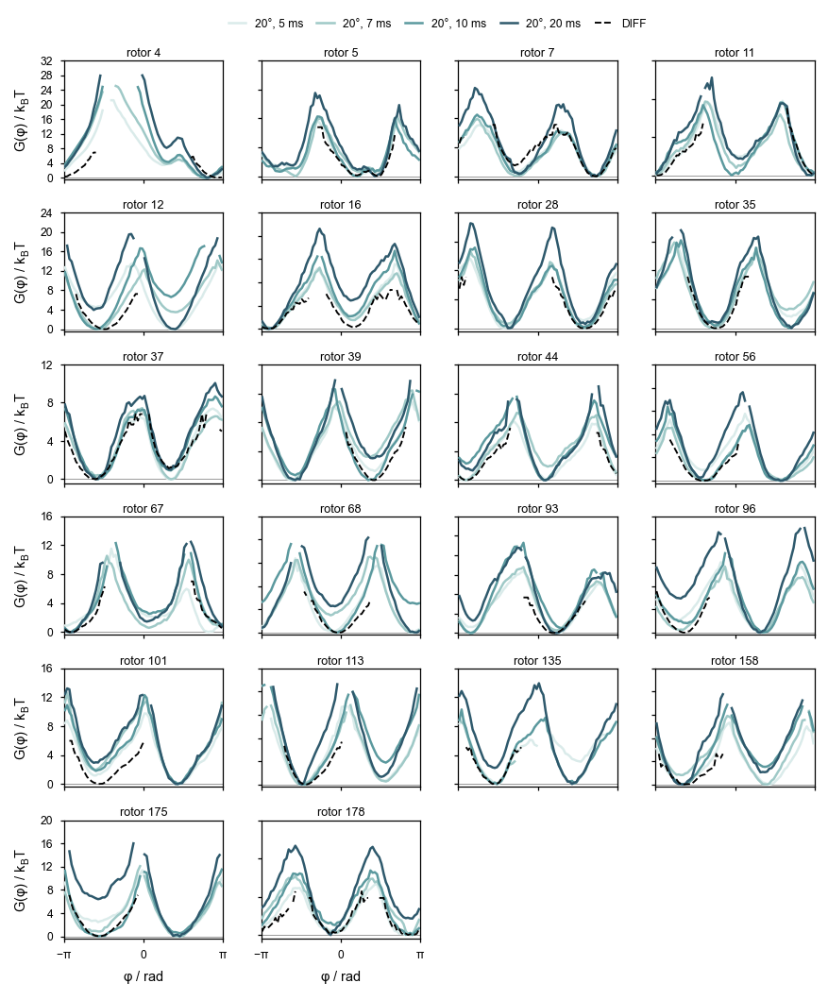

In [82]:
# Plot the newly stored equal-sample reconstructions.
plot_MBAR_reconstruction_gallery(
    m_list=m_list,
    sampling_time_colors=target_exposure_time_colors,
    sampling_time_order_ms=(5.0, 7.0, 10.0, 20.0),
    particles=[4,5,7,12,11,16,28,35,37,39,44,56,67,68,93,96,101,113,135,178,158,175],
    split_target_other=True,
    show_diff=True,
    show_consistency=True,
    show_rmse=False,
    center_mode="ensemble",
    bias_potential="cosine",
    ncols=4,
    nrows_per_page=6,
    panel_width_mm=36,
    panel_height_mm=30,
    shared_ylim=False,
    energy_tick_spacing_kBT=4.0,
    sort_by="particle",
    C=CK_colors,
    save_dir=None,
    save_prefix=None,
)

## Figure 3 – Effect of sampling time  on reconstruction

#### i. Ornstein-Uhlenbeck model of motion blurring in a harmonic trap by camera exposure time

In [45]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from scipy.linalg import toeplitz
from scipy.stats import norm, vonmises


def analyze_exposure_time_ornsteinuhlenbeck(
    m_list,
    calibration_particles,
    exposure_order_ms=(5, 7, 10, 20),
    representative_window_deg=0,
    particle_col="group",
    phi_col="phi",
    min_locs_per_window=30,
    min_valid_windows_per_exposure=6,
    max_acf_lag_s=0.12,
    min_acf_points=4,
    n_window_bootstrap=300,
    n_rotor_bootstrap=2000,
    tau_bounds_ms=(0.5, 200.0),
    min_fit_r2=0.50,
    localization_noise_fraction=0.0,
    information_window_s=5.0,
    fim_max_frames=180,
    random_seed=7,
):
    def flatten(x):
        if x is None:
            return []
        if isinstance(x, (list, tuple)):
            return [z for y in x for z in flatten(y)]
        return [x]

    def name(m):
        for attr in ("path", "filename", "file", "name"):
            value = getattr(m, attr, None)
            if value is not None:
                return Path(str(value)).name
        return "measurement"

    def is_diff(m):
        return "DIFF" in name(m).upper() and "PSEUDO_DIFF" not in name(m).upper()

    def is_umb(m):
        protocol = getattr(m, "protocol", None)
        return (not is_diff(m)) and ("UMB" in name(m).upper() or (isinstance(protocol, dict) and any(str(k).startswith("deg-") for k in protocol)))

    def exposure_ms(m):
        for attr in ("exposure_time_ms", "frame_time_ms", "camera_frame_time_ms"):
            try:
                value = float(getattr(m, attr))
                if np.isfinite(value) and value > 0:
                    return value
            except Exception:
                pass
        for attr in ("_average_tpf", "average_tpf"):
            try:
                value = 1000 * float(getattr(m, attr))
                if np.isfinite(value) and value > 0:
                    return value
            except Exception:
                pass
        hit = re.search(r"(?<!\d)(\d+(?:\.\d+)?)\s*ms", name(m), flags=re.I)
        return float(hit.group(1)) if hit else np.nan

    def exposure_key(value):
        if not np.isfinite(value):
            return None
        arr = np.asarray(exposure_order_ms, float)
        nearest = float(arr[np.argmin(np.abs(arr - value))])
        return nearest if np.isclose(nearest, value, atol=0.06, rtol=0.01) else None

    def wrap(x):
        return (np.asarray(x, float) + np.pi) % (2 * np.pi) - np.pi

    def circ_mean(x):
        x = np.asarray(x, float)
        x = x[np.isfinite(x)]
        return float(np.angle(np.mean(np.exp(1j * x)))) if x.size else np.nan

    def circ_std(x):
        x = np.asarray(x, float)
        x = x[np.isfinite(x)]
        if x.size < 2:
            return np.nan
        R = np.clip(np.abs(np.mean(np.exp(1j * x))), 1e-15, 1.0)
        return float(np.sqrt(-2 * np.log(R)))

    def bounds(v):
        while isinstance(v, (list, tuple)) and len(v) == 1 and isinstance(v[0], (list, tuple, dict)):
            v = v[0]
        if isinstance(v, dict):
            a = v.get("start", v.get("start_time", v.get("t_start", v.get("t0"))))
            b = v.get("end", v.get("end_time", v.get("t_end", v.get("t1", v.get("stop")))))
            return float(a), float(b)
        return float(v[0]), float(v[1])

    def windows(m):
        out = []
        for phase, v in getattr(m, "protocol", {}).items():
            hit = re.match(r"^deg-(-?\d+(?:\.\d+)?)", str(phase))
            if hit is not None:
                try:
                    a, b = bounds(v)
                    out.append((float(hit.group(1)), str(phase), a, b))
                except Exception:
                    pass
        return sorted(out)

    def locs(m):
        df = m.locs.copy()
        if particle_col not in df and "group_int" in df:
            df[particle_col] = df["group_int"].astype(int)
        if "t" not in df:
            for col in ("averagetime", "time", "time_s"):
                if col in df:
                    df["t"] = df[col].astype(float)
                    break
            else:
                df["t"] = df["frame"].astype(float) * float(getattr(m, "_average_tpf", 0.005))
        df[particle_col] = df[particle_col].astype(int)
        return df

    def q_cov(lags, T, dt, tau, noise_fraction=0.0):
        lags = np.asarray(lags, int)
        T = float(T)
        dt = float(dt)
        tau = float(tau)
        q = np.empty(len(lags), float)
        q[lags == 0] = 2 * tau / T**2 * (T - tau * (1 - np.exp(-T / tau))) + float(noise_fraction)
        pos = lags > 0
        k = lags[pos].astype(float)
        q[pos] = tau**2 / T**2 * np.exp(-(k * dt - T) / tau) * (1 - np.exp(-T / tau))**2
        return q

    def B_ms(T_ms, tau_ms):
        T_ms = np.asarray(T_ms, float)
        tau_ms = float(tau_ms)
        return 2 * tau_ms / T_ms**2 * (T_ms - tau_ms * (1 - np.exp(-T_ms / tau_ms)))

    def kappa_model(T_ms, kappa_tilde, tau_ms):
        return np.asarray(kappa_tilde / B_ms(np.asarray(T_ms, float), tau_ms), float)

    def acf_fft(x, max_lag):
        x = np.asarray(x, float)
        x = x[np.isfinite(x)]
        if x.size < 4:
            return np.array([1.0])
        x = x - np.mean(x)
        var = np.var(x)
        if not np.isfinite(var) or var <= 1e-30:
            return np.array([1.0])
        n = len(x)
        nfft = 1 << (2 * n - 1).bit_length()
        f = np.fft.fft(x, nfft)
        ac = np.fft.ifft(f * np.conjugate(f)).real[:n]
        ac = ac / (var * np.arange(n, 0, -1))
        ac = ac / ac[0]
        return ac[:min(int(max_lag) + 1, n)]

    exposure_order_ms = [float(x) for x in exposure_order_ms]
    calibration_particles = sorted(set(map(int, calibration_particles)))
    rng = np.random.default_rng(random_seed)

    umb = {}
    for m in flatten(m_list):
        if is_umb(m):
            key = exposure_key(exposure_ms(m))
            if key is not None and key not in umb:
                umb[key] = m
    missing = [x for x in exposure_order_ms if x not in umb]
    if missing:
        raise ValueError(f"Missing UMB measurements for exposure times {missing} ms.")

    krows, acf_rows, sample_rows = [], [], []
    representative_phase_by_exposure = {}
    for tpf in exposure_order_ms:
        m = umb[tpf]
        df = locs(m)
        dt = tpf / 1000
        max_lag = max(2, int(np.ceil(max_acf_lag_s / dt)))
        all_windows = windows(m)
        if not all_windows:
            continue
        rep_row = min(all_windows, key=lambda row: abs(row[0] - float(representative_window_deg)))
        representative_phase_by_exposure[tpf] = rep_row[1]
        rep_deg, rep_phase, rep_start, rep_stop = rep_row
        rep_w = df[(df.t >= rep_start) & (df.t < rep_stop) & (df[particle_col].isin(calibration_particles))]
        for particle, g in rep_w.groupby(particle_col):
            phi = wrap(g[phi_col].to_numpy(float))
            phi = phi[np.isfinite(phi)]
            if phi.size < min_locs_per_window:
                continue
            mu = circ_mean(phi)
            psi = wrap(phi - mu)
            sample_rows.append((tpf, int(particle), rep_phase, rep_deg, psi.copy()))
        for deg, phase, start, stop in all_windows:
            w = df[(df.t >= start) & (df.t < stop) & (df[particle_col].isin(calibration_particles))]
            for particle, g in w.groupby(particle_col):
                phi = wrap(g[phi_col].to_numpy(float))
                phi = phi[np.isfinite(phi)]
                if phi.size < min_locs_per_window:
                    continue
                psi = wrap(phi - circ_mean(phi))
                sigma = circ_std(psi)
                if np.isfinite(sigma) and sigma > 0:
                    krows.append((tpf, int(particle), phase, deg, len(phi), sigma, 1 / sigma**2))
                acf = acf_fft(psi, max_lag)
                if len(acf) >= min_acf_points:
                    for lag, value in enumerate(acf):
                        acf_rows.append((tpf, int(particle), phase, deg, lag, lag * dt, value))

    window_df = pd.DataFrame(krows, columns=["tpf", "particle", "phase", "deg", "n", "sigma", "kappa"])
    acf_df = pd.DataFrame(acf_rows, columns=["tpf", "particle", "phase", "deg", "lag", "lag_s", "acf"])
    if window_df.empty:
        raise RuntimeError("No valid calibration-window data found.")

    counts = window_df.groupby(["particle", "tpf"])["phase"].nunique().unstack("tpf").reindex(columns=exposure_order_ms)
    valid = counts.index[(counts >= int(min_valid_windows_per_exposure)).all(axis=1)].astype(int).tolist()
    if len(valid) < 2:
        raise RuntimeError("Need at least two calibration rotors valid at every exposure time.")

    summary = window_df[window_df.particle.isin(valid)].groupby(["particle", "tpf"], as_index=False).agg(
        kappa=("kappa", "mean"),
        sigma=("sigma", "mean"),
        n_windows=("phase", "nunique"),
        n_frames=("n", "median"),
    )

    T = np.asarray(exposure_order_ms, float)

    def fit_one(y):
        y = np.asarray(y, float)
        if np.any(~np.isfinite(y)) or np.any(y <= 0):
            return None
        lo = np.log([1e-9, tau_bounds_ms[0]])
        hi = np.log([1e6, tau_bounds_ms[1]])

        def res(theta):
            kappa_tilde, tau = np.exp(theta)
            return np.log(y) - np.log(kappa_model(T, kappa_tilde, tau))

        fit = least_squares(res, np.log([np.nanmin(y), np.median(T)]), bounds=(lo, hi), max_nfev=30000)
        kappa_tilde, tau = np.exp(fit.x)
        pred = kappa_model(T, kappa_tilde, tau)
        ssr = np.sum((y - pred) ** 2)
        sst = np.sum((y - np.mean(y)) ** 2)
        r2 = 1 - ssr / sst if sst > 0 else np.nan
        return float(kappa_tilde), float(tau), pred, float(r2)

    fit_rows, boot_by_particle = [], {}
    for p in valid:
        y = summary[summary.particle.eq(p)].set_index("tpf").reindex(exposure_order_ms)["kappa"].to_numpy(float)
        fit = fit_one(y)
        if fit is None:
            continue
        kappa_tilde, tau, pred, r2 = fit
        groups = {t: window_df[(window_df.particle.eq(p)) & (window_df.tpf.eq(t))].kappa.to_numpy(float) for t in exposure_order_ms}
        boot = []
        for _ in range(int(n_window_bootstrap)):
            yb = np.array([np.mean(rng.choice(groups[t], len(groups[t]), replace=True)) for t in exposure_order_ms])
            fb = fit_one(yb)
            if fb is not None and np.isfinite(fb[1]):
                boot.append(fb[1])
        boot = np.asarray(boot, float)
        ci = np.nanpercentile(boot, [2.5, 97.5]) if boot.size else [np.nan, np.nan]
        accepted = bool(np.isfinite(tau) and tau_bounds_ms[0] < tau < tau_bounds_ms[1] and np.isfinite(r2) and r2 >= min_fit_r2)
        fit_rows.append((p, kappa_tilde, tau, ci[0], ci[1], r2, accepted))
        boot_by_particle[int(p)] = boot

    fit_df = pd.DataFrame(fit_rows, columns=["particle", "kappa_tilde", "tau_ou_ms", "tau_ci_low_ms", "tau_ci_high_ms", "r2", "accepted"])
    accepted = fit_df[fit_df.accepted].copy()
    if accepted.empty:
        raise RuntimeError("No rotor-specific OU fit passed QC.")
    particles = accepted.particle.astype(int).tolist()

    tau_values = accepted.tau_ou_ms.to_numpy(float)
    tau_pop = float(np.median(tau_values))
    tau_pop_boot = np.array([np.median(rng.choice(tau_values, len(tau_values), replace=True)) for _ in range(int(n_rotor_bootstrap))], float)
    tau_pop_ci = tuple(np.percentile(tau_pop_boot, [2.5, 97.5]))

    pred_rows, res_rows = [], []
    for p in particles:
        fit = accepted[accepted.particle.eq(p)].iloc[0]
        obs = summary[summary.particle.eq(p)].set_index("tpf").reindex(exposure_order_ms)
        pred = kappa_model(T, fit.kappa_tilde, fit.tau_ou_ms)
        for tpf, ko, kp in zip(exposure_order_ms, obs.kappa.to_numpy(float), pred):
            pred_rows.append((p, tpf, ko, kp, np.log(ko), np.log(kp)))
            res_rows.append((p, tpf, np.log(ko) - np.log(kp)))
    pred_df = pd.DataFrame(pred_rows, columns=["particle", "tpf", "kappa_obs", "kappa_pred", "log_kappa_obs", "log_kappa_pred"])
    residual_df = pd.DataFrame(res_rows, columns=["particle", "tpf", "delta_log_kappa"])

    acf_panel_rows = []
    for p in particles:
        tau = float(accepted.loc[accepted.particle.eq(p), "tau_ou_ms"].iloc[0])
        for tpf in exposure_order_ms:
            d = acf_df[(acf_df.particle.eq(p)) & acf_df.tpf.eq(tpf)]
            if d.empty:
                continue
            empirical = d.groupby("lag", as_index=False).acf.median()
            empirical["lag_s"] = empirical["lag"] * tpf / 1000
            empirical = empirical[empirical["lag_s"] <= max_acf_lag_s]
            lags = empirical["lag"].to_numpy(int)
            obs = empirical["acf"].to_numpy(float)
            q = q_cov(lags, tpf / 1000, tpf / 1000, tau / 1000, localization_noise_fraction)
            pred = q / q[0]
            for lag, lag_s, obs_i, pred_i in zip(lags, empirical["lag_s"], obs, pred):
                acf_panel_rows.append((p, tpf, lag, lag_s, obs_i, pred_i))
    acf_panel_df = pd.DataFrame(acf_panel_rows, columns=["particle", "tpf", "lag", "lag_s", "acf_obs", "acf_pred"])

    def fisher_for_setting(tpf_ms, tau_ms, n_frames):
        n_actual = max(3, int(n_frames))
        n = min(n_actual, int(fim_max_frames))
        Texp = tpf_ms / 1000
        dt = tpf_ms / 1000
        tau = tau_ms / 1000
        lags = np.arange(n)
        c = q_cov(lags, Texp, dt, tau, localization_noise_fraction)
        Cmat = toeplitz(c)
        eps = 1e-4
        d_logvar = Cmat.copy()
        cp = q_cov(lags, Texp, dt, tau * np.exp(eps), localization_noise_fraction)
        cm = q_cov(lags, Texp, dt, tau * np.exp(-eps), localization_noise_fraction)
        d_logtau = (toeplitz(cp) - toeplitz(cm)) / (2 * eps)
        jitter = max(1e-12, 1e-10 * np.trace(Cmat) / n)
        Cmat = Cmat + jitter * np.eye(n)
        invC = np.linalg.inv(Cmat)
        D = [d_logvar, d_logtau]
        F = np.empty((2, 2))
        for i in range(2):
            Ai = invC @ D[i]
            for j in range(2):
                F[i, j] = 0.5 * np.trace(Ai @ (invC @ D[j]))
        F *= n_actual / n
        cov_theta = np.linalg.pinv(F)
        sd_logkappa_joint = np.sqrt(cov_theta[0, 0]) if cov_theta[0, 0] > 0 else np.nan
        sd_logtau_joint = np.sqrt(cov_theta[1, 1]) if cov_theta[1, 1] > 0 else np.nan
        sd_logkappa_tau_known = 1 / np.sqrt(F[0, 0]) if F[0, 0] > 0 else np.nan
        info_logtau = 1 / cov_theta[1, 1] if cov_theta[1, 1] > 0 else np.nan
        info_logkappa = 1 / cov_theta[0, 0] if cov_theta[0, 0] > 0 else np.nan
        return info_logkappa, info_logtau, sd_logkappa_joint, sd_logtau_joint, sd_logkappa_tau_known

    fisher_rows = []
    for p in particles:
        tau = float(accepted.loc[accepted.particle.eq(p), "tau_ou_ms"].iloc[0])
        for tpf in exposure_order_ms:
            n_record = int(np.floor(information_window_s / (tpf / 1000)))
            Ik, It, sd_k_joint, sd_t_joint, sd_k_tau_known = fisher_for_setting(tpf, tau, n_record)
            fisher_rows.append((p, tpf, tau, n_record, Ik / information_window_s, It / information_window_s, sd_k_joint, sd_t_joint, sd_k_tau_known))
    fisher_df = pd.DataFrame(fisher_rows, columns=[
        "particle", "tpf", "tau_ou_ms", "n_frames",
        "I_logkappa_per_s", "I_logtau_per_s",
        "sd_logkappa_joint", "sd_logtau_joint", "sd_logkappa_tau_known"
    ])
    fisher_df["rel_sd_kappa_joint_percent"] = 100 * fisher_df["sd_logkappa_joint"]
    fisher_df["rel_sd_kappa_tau_known_percent"] = 100 * fisher_df["sd_logkappa_tau_known"]

    result = {
        "exposure_order_ms": exposure_order_ms,
        "particles": particles,
        "window_kappa": window_df,
        "summary_kappa": summary,
        "fits_all": fit_df,
        "accepted_fits": accepted,
        "tau_population_median_ms": tau_pop,
        "tau_population_ci95_ms": tau_pop_ci,
        "tau_population_bootstrap_ms": tau_pop_boot,
        "tau_bootstrap_by_particle": boot_by_particle,
        "predicted_vs_measured": pred_df,
        "log_residuals": residual_df,
        "acf_panel": acf_panel_df,
        "fisher_information": fisher_df,
        "samples": sample_rows,
        "representative_window_deg": representative_window_deg,
        "representative_phase_by_exposure": representative_phase_by_exposure,
        "information_window_s": float(information_window_s),
    }
    for m in umb.values():
        m.exposure_time_ou_result = result
    return result

In [46]:
exposure_result = analyze_exposure_time_ornsteinuhlenbeck(
    m_list=m_list,
    calibration_particles=m.calibration_rotors,
    exposure_order_ms=(5, 7, 10, 20),
    representative_window_deg=0,
    information_window_s=5.0,
    random_seed=7,
)

#### ii. SI | Plot joint fit parameter kappa, tau for Ornstein-Uhlenbeck process

In [47]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import LinearSegmentedColormap, to_rgba
from scipy.stats import norm, vonmises


def _exp_rgb(value):
    value = np.asarray(value, float).ravel()[:3]
    return tuple(value / 255 if np.nanmax(value) > 1 else value)


def _exp_mm(value):
    return float(value) / 25.4


def _exp_blend(c1, c2, fraction):
    return tuple((1 - float(fraction)) * np.asarray(c1, float) + float(fraction) * np.asarray(c2, float))


def _exp_wrap_pi(phi):
    phi = np.asarray(phi, float)
    return (phi + np.pi) % (2 * np.pi) - np.pi


def _exp_circular_mean(phi):
    phi = np.asarray(phi, float)
    phi = phi[np.isfinite(phi)]
    if not len(phi):
        return np.nan
    z = np.mean(np.exp(1j * phi))
    return float(np.angle(z)) if np.abs(z) > 1e-15 else np.nan


def _exp_blur_factor_ms(exposure_ms, tau_tilde_ms):
    exposure_ms = np.asarray(exposure_ms, float)
    tau_tilde_ms = float(tau_tilde_ms)
    return 2 * tau_tilde_ms / exposure_ms**2 * (
        exposure_ms - tau_tilde_ms * (1 - np.exp(-exposure_ms / tau_tilde_ms))
    )


def _exp_kappa_model(exposure_ms, kappa_tilde, tau_tilde_ms):
    return np.asarray(kappa_tilde / _exp_blur_factor_ms(exposure_ms, tau_tilde_ms), float)


def _exp_gaussian_kernel1d(sigma_bins, truncate=4):
    sigma_bins = float(sigma_bins)
    if sigma_bins <= 0:
        return np.array([1.0])
    radius = max(1, int(np.ceil(truncate * sigma_bins)))
    x = np.arange(-radius, radius + 1, dtype=float)
    kernel = np.exp(-0.5 * (x / sigma_bins) ** 2)
    return kernel / np.sum(kernel)


def _exp_smooth_2d(array, sigma_bins):
    array = np.asarray(array, float)
    kernel = _exp_gaussian_kernel1d(sigma_bins)
    pad = len(kernel) // 2
    temporary = np.pad(array, ((0, 0), (pad, pad)), mode="edge")
    temporary = np.apply_along_axis(lambda x: np.convolve(x, kernel, mode="valid"), axis=1, arr=temporary)
    output = np.pad(temporary, ((pad, pad), (0, 0)), mode="edge")
    return np.apply_along_axis(lambda x: np.convolve(x, kernel, mode="valid"), axis=0, arr=output)


def _exp_smooth_histogram(values, width):
    values = np.asarray(values, float)
    width = int(width)
    if width <= 1:
        return values
    return np.convolve(values, np.ones(width, float) / width, mode="same")


def _exp_density_cmap(color):
    r, g, b, _ = to_rgba(color)
    return LinearSegmentedColormap.from_list(
        "exposure_density",
        [
            (0.00, (1, 1, 1, 0.00)),
            (0.10, (r, g, b, 0.06)),
            (0.25, (r, g, b, 0.16)),
            (0.45, (r, g, b, 0.34)),
            (0.65, (r, g, b, 0.56)),
            (0.82, (r, g, b, 0.78)),
            (1.00, (r, g, b, 0.92)),
        ],
    )


def _exp_style_axis(axis, black):
    for spine in axis.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.6)
        spine.set_color(black)
    axis.tick_params(length=2, width=0.6, direction="out", colors=black, pad=1.5)
    axis.grid(False)


def _exp_style_localization_axis(axis, rlim=0.82):
    axis.set_aspect("equal")
    axis.set_xlim(-rlim, rlim)
    axis.set_ylim(-0.08 * rlim, rlim)
    axis.set_xticks([])
    axis.set_yticks([])
    axis.grid(False)
    for spine in axis.spines.values():
        spine.set_visible(False)


def _exp_parse_samples(samples):
    parsed = []
    for entry in samples:
        if isinstance(entry, dict):
            parsed.append(
                (
                    float(entry.get("tpf", entry.get("exposure_ms"))),
                    int(entry["particle"]),
                    str(entry["phase"]),
                    np.asarray(entry["psi"], float),
                )
            )
        elif len(entry) >= 5:
            parsed.append((float(entry[0]), int(entry[1]), str(entry[2]), np.asarray(entry[-1], float)))
    return parsed


def _exp_measurement_name(m):
    for attr in ("path", "filename", "file", "name"):
        if hasattr(m, attr):
            value = getattr(m, attr)
            if value is not None:
                return Path(str(value)).name
    return "measurement"


def _exp_get_exposure_time_ms(m, exposure_name_map=None):
    name = _exp_measurement_name(m)

    if exposure_name_map is not None:
        for exposure_ms, patterns in exposure_name_map.items():
            patterns = [patterns] if isinstance(patterns, str) else list(patterns)
            if any(str(pattern).lower() in name.lower() for pattern in patterns):
                return float(exposure_ms)

    match = re.search(r"(?<!\d)(5|7|10|20)\s*ms(?!\d)", name, flags=re.IGNORECASE)
    return float(match.group(1)) if match else np.nan


def _exp_protocol_bounds(value):
    while isinstance(value, (tuple, list)) and len(value) == 1 and isinstance(value[0], (tuple, list)):
        value = value[0]

    if isinstance(value, dict):
        t0 = value.get("start", value.get("t0"))
        t1 = value.get("end", value.get("t1"))
        if t0 is None or t1 is None:
            raise ValueError(f"Could not parse protocol bounds from {value}.")
        return float(t0), float(t1)

    if isinstance(value, (tuple, list)) and len(value) >= 2:
        return float(value[0]), float(value[1])

    raise ValueError(f"Could not parse protocol bounds from {value}.")


def _exp_ensure_locs(m):
    if not hasattr(m, "locs") or m.locs is None:
        raise ValueError(f"{_exp_measurement_name(m)} has no m.locs.")

    locs = m.locs
    changed = False

    if "group" not in locs.columns:
        if "group_int" not in locs.columns:
            raise ValueError(f"{_exp_measurement_name(m)} has neither 'group' nor 'group_int'.")
        locs = locs.copy()
        locs["group"] = locs["group_int"].astype(int)
        changed = True

    if "phi" not in locs.columns or "rho" not in locs.columns:
        raise ValueError(f"{_exp_measurement_name(m)} must contain 'phi' and 'rho'.")

    if "t" not in locs.columns:
        time_col = next((column for column in ("averagetime", "time", "time_s") if column in locs.columns), None)

        if time_col is not None:
            locs = locs.copy()
            locs["t"] = locs[time_col].to_numpy(float)
            changed = True
        elif "frame" in locs.columns:
            dt_s = float(getattr(m, "_average_tpf", 0.005))
            locs = locs.copy()
            locs["t"] = locs["frame"].to_numpy(float) * dt_s
            changed = True
        else:
            raise ValueError(f"{_exp_measurement_name(m)} has no readable time column.")

    if changed:
        m.locs = locs

    return locs


def _exp_fitted_radius(m, particle):
    particle_data = getattr(m, "particle_data", None)

    if isinstance(particle_data, pd.DataFrame) and "R" in particle_data.columns:
        if particle in particle_data.index:
            value = float(particle_data.loc[particle, "R"])
            if np.isfinite(value) and value > 0:
                return value

        for particle_column in ("group", "group_int", "particle"):
            if particle_column in particle_data.columns:
                selected = particle_data[particle_data[particle_column].astype(int).eq(int(particle))]
                if len(selected):
                    value = float(selected.iloc[0]["R"])
                    if np.isfinite(value) and value > 0:
                        return value

    locs = _exp_ensure_locs(m)
    rho = locs.loc[locs["group"].astype(int).eq(int(particle)), "rho"].to_numpy(float)
    rho = rho[np.isfinite(rho) & (rho > 0)]

    if not len(rho):
        raise RuntimeError(f"Could not determine radius for particle {particle}.")

    return float(np.nanmedian(rho))


def _exp_normalize_rho(rho, fitted_R):
    rho = np.asarray(rho, float)
    finite = rho[np.isfinite(rho)]

    if not len(finite):
        return np.full_like(rho, np.nan), 1.0

    rho_median = float(np.nanmedian(finite))
    scale = float(fitted_R) / rho_median if rho_median > 0 else 1.0
    rho_scaled = rho * scale
    finite_scaled = rho_scaled[np.isfinite(rho_scaled)]
    rmax = float(np.nanpercentile(finite_scaled, 99.5))

    if not np.isfinite(rmax) or rmax <= 0:
        rmax = float(fitted_R)

    rho_plot = np.clip((rho_scaled / rmax) * 0.70, 0, np.inf)
    fitted_R_plot = (float(fitted_R) / rmax) * 0.70
    return rho_plot, fitted_R_plot


def _exp_get_localization_example(
    m_list,
    exposure_ms,
    particle,
    representative_window_deg,
    exposure_name_map=None,
    phi_cmd_offset_rad=-np.pi / 2,
    min_locs=30,
):
    matching_measurements = [
        m
        for m in m_list
        if np.isfinite(_exp_get_exposure_time_ms(m, exposure_name_map))
        and np.isclose(_exp_get_exposure_time_ms(m, exposure_name_map), float(exposure_ms))
        and isinstance(getattr(m, "protocol", None), dict)
    ]

    for m in matching_measurements:
        phase_match = None

        for phase, bounds in m.protocol.items():
            match = re.match(r"^deg-(-?\d+(?:\.\d+)?)$", str(phase))
            if match is None:
                continue

            window_deg = float(match.group(1))
            if np.isclose(window_deg, float(representative_window_deg)):
                phase_match = str(phase), bounds, window_deg
                break

        if phase_match is None:
            continue

        phase, bounds, window_deg = phase_match
        t0, t1 = _exp_protocol_bounds(bounds)
        locs = _exp_ensure_locs(m)

        selected = locs[
            locs["group"].astype(int).eq(int(particle))
            & locs["t"].between(t0, t1, inclusive="left")
        ].copy()

        selected = selected[
            np.isfinite(selected["phi"].to_numpy(float))
            & np.isfinite(selected["rho"].to_numpy(float))
        ]

        if len(selected) < int(min_locs):
            continue

        phi = _exp_wrap_pi(selected["phi"].to_numpy(float))
        rho = selected["rho"].to_numpy(float)
        fitted_R = _exp_fitted_radius(m, particle)
        rho_plot, fitted_R_plot = _exp_normalize_rho(rho, fitted_R)

        phi_cmd_raw = float(_exp_wrap_pi(np.deg2rad(window_deg) + phi_cmd_offset_rad))
        phi_mean_raw = _exp_circular_mean(phi)

        if not np.isfinite(phi_mean_raw):
            phi_mean_raw = phi_cmd_raw

        rotation = float(np.pi / 2 - phi_cmd_raw)
        phi_plot = _exp_wrap_pi(phi + rotation)
        phi_cmd_plot = float(_exp_wrap_pi(phi_cmd_raw + rotation))
        phi_mean_plot = float(_exp_wrap_pi(phi_mean_raw + rotation))

        return {
            "measurement": _exp_measurement_name(m),
            "exposure_ms": float(exposure_ms),
            "particle": int(particle),
            "phase": phase,
            "window_deg": float(window_deg),
            "n_locs": int(len(selected)),
            "x": rho_plot * np.cos(phi_plot),
            "y": rho_plot * np.sin(phi_plot),
            "R_plot": float(fitted_R_plot),
            "x_cmd": float(fitted_R_plot * np.cos(phi_cmd_plot)),
            "y_cmd": float(fitted_R_plot * np.sin(phi_cmd_plot)),
            "x_mean": float(fitted_R_plot * np.cos(phi_mean_plot)),
            "y_mean": float(fitted_R_plot * np.sin(phi_mean_plot)),
        }

    raise RuntimeError(
        f"No valid localization data found for {exposure_ms:g} ms, "
        f"particle {particle}, window {representative_window_deg:g}°."
    )


def _exp_prepare_context(
    result,
    calibration_exposure_time_colors,
    calibration_example_particle=None,
    representative_window_deg=None,
    C=None,
):
    if C is None:
        raise ValueError("Pass C=CK_colors.")

    C = C() if callable(C) else dict(C)

    for key, value in {
        "black": (0, 0, 0),
        "grey": (0.25, 0.25, 0.25),
        "midgrey": (0.45, 0.45, 0.45),
        "lightgrey": (0.72, 0.72, 0.72),
    }.items():
        C.setdefault(key, value)

    colors = {float(key): _exp_rgb(value) for key, value in calibration_exposure_time_colors.items()}
    black, grey, midgrey, lightgrey = map(
        _exp_rgb,
        [C["black"], C["grey"], C["midgrey"], C["lightgrey"]],
    )

    exposure_order_ms = [float(value) for value in result["exposure_order_ms"]]
    particles = list(map(int, result["particles"]))
    summary_df = result["summary_kappa"].copy()
    fit_df = result["accepted_fits"].copy()
    fisher_df = result["fisher_information"].copy()
    predicted_df = result.get("predicted_vs_measured", pd.DataFrame()).copy()
    acf_panel = result.get("acf_panel", pd.DataFrame()).copy()

    representative_window_deg = (
        result["representative_window_deg"]
        if representative_window_deg is None
        else float(representative_window_deg)
    )

    if calibration_example_particle is None or int(calibration_example_particle) not in particles:
        calibration_example_particle = int(fit_df.sort_values("r2", ascending=False)["particle"].iloc[0])
    else:
        calibration_example_particle = int(calibration_example_particle)

    selected_rows = fit_df[fit_df["particle"].astype(int).eq(calibration_example_particle)]

    if selected_rows.empty:
        raise RuntimeError(f"No accepted fit found for calibration rotor {calibration_example_particle}.")

    selected_fit = selected_rows.iloc[0]
    selected_fit_summary = {
        "particle": calibration_example_particle,
        "kappa_tilde": float(selected_fit["kappa_tilde"]),
        "tau_tilde_ms": float(selected_fit["tau_ou_ms"]),
        "r2": float(selected_fit["r2"]) if "r2" in selected_fit.index else np.nan,
        "tau_ci_low_ms": float(selected_fit["tau_ci_low_ms"]) if "tau_ci_low_ms" in selected_fit.index else np.nan,
        "tau_ci_high_ms": float(selected_fit["tau_ci_high_ms"]) if "tau_ci_high_ms" in selected_fit.index else np.nan,
    }

    sample_lookup = {
        (exposure_ms, particle, phase): psi
        for exposure_ms, particle, phase, psi in _exp_parse_samples(result["samples"])
    }

    available = []

    for exposure_ms in exposure_order_ms:
        candidates = []

        for (candidate_exposure, particle, phase), psi in sample_lookup.items():
            if candidate_exposure != exposure_ms or particle != calibration_example_particle:
                continue

            match = re.match(r"^deg-(-?\d+(?:\.\d+)?)", phase)
            if match is not None:
                candidates.append((phase, float(match.group(1)), psi))

        if candidates:
            available.append(
                (
                    exposure_ms,
                    min(candidates, key=lambda row: abs(row[1] - representative_window_deg)),
                )
            )

    if len(available) != len(exposure_order_ms):
        found = [row[0] for row in available]
        missing = [value for value in exposure_order_ms if value not in found]
        raise RuntimeError(f"Representative-window samples are missing for {missing} ms.")

    available_map = {
        float(exposure_ms): (phase, window_deg, np.asarray(psi, float))
        for exposure_ms, (phase, window_deg, psi) in available
    }

    return {
        "C": C,
        "colors": colors,
        "black": black,
        "grey": grey,
        "midgrey": midgrey,
        "lightgrey": lightgrey,
        "exposure_order_ms": exposure_order_ms,
        "particles": particles,
        "summary_df": summary_df,
        "fit_df": fit_df,
        "fisher_df": fisher_df,
        "predicted_df": predicted_df,
        "acf_panel": acf_panel,
        "representative_window_deg": representative_window_deg,
        "calibration_example_particle": calibration_example_particle,
        "selected_fit_summary": selected_fit_summary,
        "available_map": available_map,
    }

In [48]:
def plot_si_exposure_time_first_three_validation(
    result,
    calibration_exposure_time_colors,
    calibration_example_particle=None,
    representative_window_deg=None,
    density_xlim_rad=(-np.pi / 2, np.pi / 2),
    density_nbins=54,
    density_smooth_nbins=3,
    fig_width_mm=180,
    fig_height_mm=58,
    fontsize=7,
    axis_label_size=7,
    tick_label_size=7,
    annotation_size=6,
    panel_label_size=10,
    panel_labels=("a", "b", "c", "d", "e"),
    C=None,
    save_dir=None,
    save_prefix="SI_exposure_time_first_three_validation",
    stator_variant=None,
    dpi=300,
):
    ctx = _exp_prepare_context(
        result=result,
        calibration_exposure_time_colors=calibration_exposure_time_colors,
        calibration_example_particle=calibration_example_particle,
        representative_window_deg=representative_window_deg,
        C=C,
    )

    colors = ctx["colors"]
    black, grey, midgrey, lightgrey = ctx["black"], ctx["grey"], ctx["midgrey"], ctx["lightgrey"]
    exposure_order_ms = ctx["exposure_order_ms"]
    particles = ctx["particles"]
    summary_df = ctx["summary_df"]
    fit_df = ctx["fit_df"]
    fisher_df = ctx["fisher_df"]
    predicted_df = ctx["predicted_df"]
    acf_panel = ctx["acf_panel"]
    calibration_example_particle = ctx["calibration_example_particle"]
    available_map = ctx["available_map"]

    plt.rcParams.update({
        "font.size": fontsize,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.linewidth": 0.6,
        "axes.labelsize": axis_label_size,
        "xtick.labelsize": tick_label_size,
        "ytick.labelsize": tick_label_size,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    fig = plt.figure(figsize=(_exp_mm(fig_width_mm), _exp_mm(fig_height_mm)))

    outer = fig.add_gridspec(
        1,
        5,
        left=0.045,
        right=0.995,
        bottom=0.17,
        top=0.91,
        width_ratios=(1.03, 0.98, 0.98, 1.18, 0.96),
        wspace=0.42,
    )

    gs_a = outer[0, 0].subgridspec(
        len(exposure_order_ms),
        1,
        hspace=0.10,
    )

    ax_a = [
        fig.add_subplot(gs_a[index, 0])
        for index in range(len(exposure_order_ms))
    ]

    ax_b = fig.add_subplot(outer[0, 1])
    ax_c = fig.add_subplot(outer[0, 2])

    gs_d = outer[0, 3].subgridspec(
        2,
        2,
        wspace=0.25,
        hspace=0.25,
    )

    acf_axes = [
        fig.add_subplot(gs_d[row, column])
        for row in range(2)
        for column in range(2)
    ]

    ax_e = fig.add_subplot(outer[0, 4])

    edges = np.linspace(
        density_xlim_rad[0],
        density_xlim_rad[1],
        int(density_nbins) + 1,
    )

    centers = 0.5 * (edges[:-1] + edges[1:])
    x_fit = np.linspace(density_xlim_rad[0], density_xlim_rad[1], 500)
    distribution_rows = []

    for exposure_ms in exposure_order_ms:
        _, _, psi = available_map[exposure_ms]
        psi = np.asarray(psi, float)
        psi = psi[np.isfinite(psi)]

        measured = np.histogram(
            psi,
            bins=edges,
            density=True,
        )[0]

        measured = _exp_smooth_histogram(
            measured,
            density_smooth_nbins,
        )

        gaussian_mu, gaussian_sigma = norm.fit(psi)
        vonmises_kappa, vonmises_mu, _ = vonmises.fit(psi, fscale=1)

        gaussian_curve = norm.pdf(
            x_fit,
            loc=gaussian_mu,
            scale=max(gaussian_sigma, 1e-12),
        )

        vonmises_curve = vonmises.pdf(
            x_fit,
            vonmises_kappa,
            loc=vonmises_mu,
        )

        distribution_rows.append({
            "exposure_ms": exposure_ms,
            "measured": measured,
            "gaussian": gaussian_curve,
            "vonmises": vonmises_curve,
        })

    common_ymax = max(
        np.nanmax(
            np.r_[
                row["measured"],
                row["gaussian"],
                row["vonmises"],
            ]
        )
        for row in distribution_rows
    ) * 1.08

    for row_index, (axis, row) in enumerate(zip(ax_a, distribution_rows)):
        exposure_ms = row["exposure_ms"]
        color = colors.get(exposure_ms, grey)

        axis.plot(
            centers,
            row["measured"],
            color=color,
            lw=1.20,
            zorder=3,
        )

        axis.plot(
            x_fit,
            row["gaussian"],
            color=black,
            lw=0.85,
            ls="--",
            alpha=0.90,
            zorder=4,
        )

        axis.plot(
            x_fit,
            row["vonmises"],
            color=midgrey,
            lw=0.90,
            ls=":",
            alpha=0.95,
            zorder=5,
        )

        axis.set_xlim(*density_xlim_rad)
        axis.set_ylim(0, common_ymax)
        axis.set_xticks([-np.pi / 2, 0, np.pi / 2])

        if row_index == len(exposure_order_ms) - 1:
            axis.set_xticklabels([r"$-\pi/2$", "0", r"$\pi/2$"])
            axis.set_xlabel(r"$\psi$ / rad")
        else:
            axis.set_xticklabels([])

        if row_index == 1:
            axis.set_ylabel(r"$p(\psi)$")
        else:
            axis.set_ylabel("")

        axis.set_yticks([0, 1])
        axis.set_yticklabels([])

        axis.text(
            0.04,
            0.92,
            f"{exposure_ms:g} ms",
            transform=axis.transAxes,
            ha="left",
            va="top",
            fontsize=annotation_size,
            color=black,
        )

        if row_index == 0:
            axis.plot([], [], color=colors.get(exposure_order_ms[0], grey), lw=1.20, label="measured")
            axis.plot([], [], color=black, lw=0.85, ls="--", label="Gaussian")
            axis.plot([], [], color=midgrey, lw=0.90, ls=":", label="von Mises")

            # axis.legend(
            #     frameon=False,
            #     fontsize=annotation_size,
            #     loc="upper left",
            #     handlelength=1.5,
            #     labelspacing=0.15,
            #     borderaxespad=0.25,
            # )

        _exp_style_axis(axis, black)

    x_positions = np.arange(len(exposure_order_ms), dtype=float)
    exposure_fine = np.linspace(min(exposure_order_ms), max(exposure_order_ms), 300)
    x_fine = np.interp(exposure_fine, exposure_order_ms, x_positions)

    wide_kappa = (
        summary_df[summary_df["particle"].isin(particles)]
        .pivot(index="particle", columns="tpf", values="kappa")
        .reindex(index=particles, columns=exposure_order_ms)
    )

    fit_lookup = fit_df.set_index("particle")
    selected_fit = fit_lookup.loc[calibration_example_particle]

    for particle in particles:
        if particle == calibration_example_particle:
            continue

        measured = np.log(wide_kappa.loc[particle].to_numpy(float))
        fit = fit_lookup.loc[particle]

        ax_b.plot(
            x_positions,
            measured,
            color=lightgrey,
            lw=0.50,
            alpha=0.25,
        )

        ax_b.plot(
            x_fine,
            np.log(
                _exp_kappa_model(
                    exposure_fine,
                    float(fit["kappa_tilde"]),
                    float(fit["tau_ou_ms"]),
                )
            ),
            color=midgrey,
            lw=0.50,
            alpha=0.12,
        )

    for index, exposure_ms in enumerate(exposure_order_ms):
        values = wide_kappa[exposure_ms].drop(
            index=calibration_example_particle,
            errors="ignore",
        ).to_numpy(float)

        values = np.log(
            values[np.isfinite(values) & (values > 0)]
        )

        ax_b.scatter(
            np.full(len(values), index),
            values,
            s=8,
            color=colors.get(exposure_ms, grey),
            alpha=0.32,
            edgecolor="none",
        )

    selected_values = np.log(
        wide_kappa.loc[calibration_example_particle].to_numpy(float)
    )

    selected_prediction = np.log(
        _exp_kappa_model(
            exposure_fine,
            float(selected_fit["kappa_tilde"]),
            float(selected_fit["tau_ou_ms"]),
        )
    )

    for index, (exposure_ms, value) in enumerate(zip(exposure_order_ms, selected_values)):
        if np.isfinite(value):
            ax_b.scatter(
                [index],
                [value],
                s=25,
                facecolor="white",
                edgecolor=colors.get(exposure_ms, grey),
                linewidth=1.10,
                zorder=7,
            )

    ax_b.plot(
        x_fine,
        selected_prediction,
        color=black,
        lw=1.20,
        ls="--",
        zorder=6,
    )

    ax_b.set_xticks(x_positions)
    ax_b.set_xticklabels([f"{value:g}" for value in exposure_order_ms])
    ax_b.set_xlabel("exposure time / ms")
    ax_b.set_ylabel(r"$\log\langle\kappa_i\rangle$")
    ax_b.set_ylim(2.3, 3.08)
    _exp_style_axis(ax_b, black)

    if not predicted_df.empty:
        inset = ax_b.inset_axes([0.18, 0.65, 0.50, 0.30])

        other = predicted_df[
            predicted_df["particle"].astype(int).ne(calibration_example_particle)
        ]

        selected = predicted_df[
            predicted_df["particle"].astype(int).eq(calibration_example_particle)
        ]

        inset.scatter(
            other["log_kappa_obs"],
            other["log_kappa_pred"],
            s=12,
            c=[colors.get(float(value), grey) for value in other["tpf"]],
            alpha=0.35,
            edgecolors="none",
        )

        inset.scatter(
            selected["log_kappa_obs"],
            selected["log_kappa_pred"],
            s=16,
            facecolors="white",
            edgecolors=[
                colors.get(float(value), grey)
                for value in selected["tpf"]
            ],
            linewidths=1.0,
            zorder=5,
        )

        lower = min(
            predicted_df["log_kappa_pred"].min(),
            predicted_df["log_kappa_obs"].min(),
        )

        upper = max(
            predicted_df["log_kappa_pred"].max(),
            predicted_df["log_kappa_obs"].max(),
        )

        padding = 0.03 * max(upper - lower, 1e-12)

        inset.plot(
            [lower - padding, upper + padding],
            [lower - padding, upper + padding],
            color=midgrey,
            lw=0.7,
            ls="--",
        )

        inset.set_xlim(lower - padding, upper + padding)
        inset.set_ylim(lower - padding, upper + padding)
        inset.set_xticks([])
        inset.set_yticks([])
        inset.set_xlabel("measured", fontsize=annotation_size, labelpad=1)
        inset.set_ylabel("predicted", fontsize=annotation_size, labelpad=1)

        for spine in inset.spines.values():
            spine.set_linewidth(0.5)

    tau_values = fit_df["tau_ou_ms"].to_numpy(float)
    kappa_values = fit_df["kappa_tilde"].to_numpy(float)

    tau_low = (
        fit_df["tau_ci_low_ms"].to_numpy(float)
        if "tau_ci_low_ms" in fit_df.columns
        else np.full_like(tau_values, np.nan)
    )

    tau_high = (
        fit_df["tau_ci_high_ms"].to_numpy(float)
        if "tau_ci_high_ms" in fit_df.columns
        else np.full_like(tau_values, np.nan)
    )

    highlight_color = colors.get(exposure_order_ms[-1], grey)

    ax_c.scatter(
        tau_values,
        kappa_values,
        s=16,
        color=lightgrey,
        alpha=0.60,
        edgecolor="none",
        zorder=2,
    )

    for tau, kappa, low, high in zip(
        tau_values,
        kappa_values,
        tau_low,
        tau_high,
    ):
        if np.isfinite(low) and np.isfinite(high):
            ax_c.plot(
                [low, high],
                [kappa, kappa],
                color=lightgrey,
                lw=0.60,
                alpha=0.50,
                zorder=1,
            )

    selected_row = fit_df[
        fit_df["particle"].astype(int).eq(calibration_example_particle)
    ].iloc[0]

    if (
        np.isfinite(selected_row.get("tau_ci_low_ms", np.nan))
        and np.isfinite(selected_row.get("tau_ci_high_ms", np.nan))
    ):
        ax_c.plot(
            [
                selected_row["tau_ci_low_ms"],
                selected_row["tau_ci_high_ms"],
            ],
            [
                selected_row["kappa_tilde"],
                selected_row["kappa_tilde"],
            ],
            color=highlight_color,
            lw=1.0,
            zorder=4,
        )

    ax_c.scatter(
        [selected_row["tau_ou_ms"]],
        [selected_row["kappa_tilde"]],
        s=34,
        facecolor="white",
        edgecolor=highlight_color,
        linewidth=1.25,
        zorder=5,
    )

    tau_median = float(np.nanmedian(tau_values))
    kappa_median = float(np.nanmedian(kappa_values))

    ax_c.axvline(
        tau_median,
        color=midgrey,
        lw=0.8,
        ls=":",
        zorder=0,
    )

    ax_c.axhline(
        kappa_median,
        color=midgrey,
        lw=0.8,
        ls=":",
        zorder=0,
    )

    # Selected calibration rotor: same brown tone as the highlighted point.
    ax_c.annotate(
        rf"$\tilde{{\tau}}={selected_row['tau_ou_ms']:.1f}\;\mathrm{{ms}}$"
        + "\n"
        + rf"$\tilde{{\kappa}}={selected_row['kappa_tilde']:.1f}\;"
        + r"k_\mathrm{B}T\,\mathrm{rad}^{-2}$",
        xy=(selected_row["tau_ou_ms"], selected_row["kappa_tilde"]),
        xytext=(7, -7),
        textcoords="offset points",
        ha="left",
        va="top",
        fontsize=annotation_size,
        color=highlight_color,
    )

    # Population medians: gray labels placed next to the corresponding axes.
    ax_c.text(
        tau_median,
        0.02,
        rf"$\operatorname{{med}}(\tilde{{\tau}})={tau_median:.1f}\;\mathrm{{ms}}$",
        transform=ax_c.get_xaxis_transform(),
        ha="center",
        va="bottom",
        fontsize=annotation_size,
        color=midgrey,
    )

    ax_c.text(
        0.02,
        kappa_median,
        rf"$\operatorname{{med}}(\tilde{{\kappa}})={kappa_median:.1f}\;"
        + r"k_\mathrm{B}T\,\mathrm{rad}^{-2}$",
        transform=ax_c.get_yaxis_transform(),
        ha="left",
        va="bottom",
        fontsize=annotation_size,
        color=midgrey,
    )

    ax_c.set_xlabel(r"$\tilde{\tau}$ / ms")
    ax_c.set_ylabel(
        r"$\tilde{\kappa}$ / $k_\mathrm{B}T\,\mathrm{rad}^{-2}$"
    )

    _exp_style_axis(ax_c, black)

    for panel_index, (axis, exposure_ms) in enumerate(
        zip(acf_axes, exposure_order_ms)
    ):
        data = acf_panel[
            acf_panel["tpf"].eq(exposure_ms)
        ].copy()

        selected_data = data[
            data["particle"].astype(int).eq(calibration_example_particle)
        ]

        other_data = data[
            data["particle"].astype(int).ne(calibration_example_particle)
        ]

        for _, group in other_data.groupby("particle"):
            axis.plot(
                1000 * group["lag_s"].to_numpy(float),
                group["acf_obs"].to_numpy(float),
                color=colors.get(exposure_ms, grey),
                lw=0.45,
                alpha=0.12,
            )

        median_observed = data.groupby(
            "lag_s",
            as_index=False,
        )["acf_obs"].median()

        median_predicted = data.groupby(
            "lag_s",
            as_index=False,
        )["acf_pred"].median()

        axis.plot(
            1000 * median_observed["lag_s"],
            median_observed["acf_obs"],
            color=colors.get(exposure_ms, grey),
            lw=1.0,
            alpha=0.65,
        )

        axis.plot(
            1000 * median_predicted["lag_s"],
            median_predicted["acf_pred"],
            color=midgrey,
            lw=0.8,
            ls="--",
            alpha=0.70,
        )

        if not selected_data.empty:
            selected_data = selected_data.sort_values("lag_s")

            axis.plot(
                1000 * selected_data["lag_s"],
                selected_data["acf_obs"],
                color=colors.get(exposure_ms, grey),
                lw=1.25,
                zorder=5,
            )

            axis.plot(
                1000 * selected_data["lag_s"],
                selected_data["acf_pred"],
                color=black,
                lw=1.0,
                ls="--",
                zorder=6,
            )

        axis.axvline(
            exposure_ms,
            color=lightgrey,
            lw=0.6,
            ls=":",
        )

        axis.text(
            0.1,
            0.94,
            f"{exposure_ms:g} ms",
            transform=axis.transAxes,
            ha="left",
            va="top",
            fontsize=annotation_size,
        )

        axis.set_xlim(
            0,
            max(
                1000 * median_observed["lag_s"].max(),
                exposure_ms,
            ),
        )

        axis.set_ylim(-0.05, 1.02)
        axis.set_yticks([0, 0.5, 1])

        if panel_index % 2 == 0:
            axis.set_yticklabels(["0", "0.5", "1"])
        else:
            axis.set_yticklabels([])

        if panel_index >= 2:
            axis.set_xlabel("lag / ms")
        else:
            axis.set_xticklabels([])

        if panel_index % 2 == 0:
            axis.set_ylabel(r"$\rho_{\psi\psi}(\delta t)$")

        _exp_style_axis(axis, black)

    wide_information = (
        fisher_df
        .pivot(index="particle", columns="tpf", values="I_logtau_per_s")
        .reindex(index=particles, columns=exposure_order_ms)
    )

    median_information = []
    rng = np.random.default_rng(4)

    for particle in particles:
        if particle == calibration_example_particle:
            continue

        ax_e.plot(
            x_positions,
            wide_information.loc[particle].to_numpy(float),
            color=lightgrey,
            lw=0.50,
            alpha=0.25,
        )

    for index, exposure_ms in enumerate(exposure_order_ms):
        values = wide_information[exposure_ms].drop(
            index=calibration_example_particle,
            errors="ignore",
        ).to_numpy(float)

        values = values[np.isfinite(values)]
        jitter = rng.uniform(-0.05, 0.05, len(values))

        ax_e.scatter(
            np.full(len(values), index) + jitter,
            values,
            s=9,
            color=colors.get(exposure_ms, grey),
            alpha=0.38,
            edgecolor="none",
        )

        all_values = wide_information[exposure_ms].to_numpy(float)
        median_information.append(
            np.nanmedian(all_values[np.isfinite(all_values)])
        )

    selected_information = wide_information.loc[
        calibration_example_particle
    ].to_numpy(float)

    for index, (exposure_ms, value) in enumerate(
        zip(exposure_order_ms, selected_information)
    ):
        if np.isfinite(value):
            ax_e.scatter(
                [index],
                [value],
                s=25,
                facecolor="white",
                edgecolor=colors.get(exposure_ms, grey),
                linewidth=1.10,
                zorder=6,
            )

    ax_e.plot(
        x_positions,
        selected_information,
        color=black,
        lw=1.05,
        ls="--",
        zorder=5,
    )

    ax_e.plot(
        x_positions,
        median_information,
        color=midgrey,
        ls = ":",
        lw=1.05,
        zorder=4,
    )

    ax_e.set_xticks(x_positions)
    ax_e.set_xticklabels([f"{value:g}" for value in exposure_order_ms])
    ax_e.set_xlabel("exposure time / ms")
    ax_e.set_ylabel(r"Fisher information on $\log\tilde{\tau}$ / s$^{-1}$")

    _exp_style_axis(ax_e, black)

    panel_axes = [ax_a[0], ax_b, ax_c, acf_axes[0], ax_e]
    fig.canvas.draw()
    panel_label_y = max(axis.get_position().y1 for axis in panel_axes) + 0.018
    panel_label_xoffset = 0.024

    for axis, label in zip(panel_axes, panel_labels):
        fig.text(
            axis.get_position().x0 - panel_label_xoffset,
            panel_label_y,
            label,
            fontsize=panel_label_size,
            fontweight="bold",
            ha="left",
            va="top",
            color=black,
        )

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        prefix = f"{stator_variant}__{save_prefix}" if stator_variant else save_prefix
        fig.savefig(save_dir / f"{prefix}.png", dpi=dpi, bbox_inches="tight")
        fig.savefig(save_dir / f"{prefix}.svg", bbox_inches="tight")

    plt.show()
    plt.close(fig)
    return fig

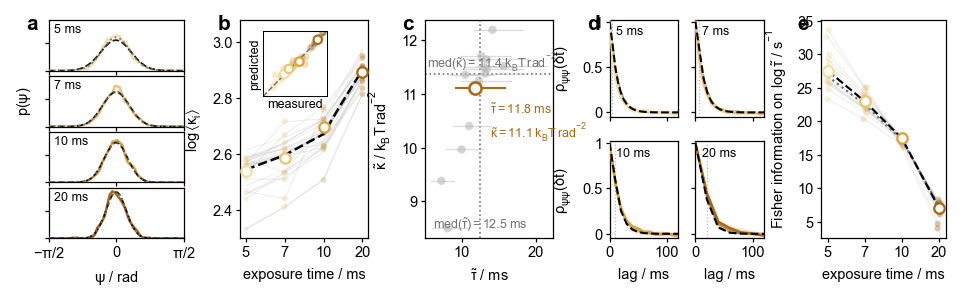

In [49]:
selected_calibration_rotor = 78
selected_umbrella_window_angle = 0

fig_si = plot_si_exposure_time_first_three_validation(
    result=exposure_result,
    calibration_example_particle=selected_calibration_rotor,
    representative_window_deg=selected_umbrella_window_angle,

    fig_width_mm=160,
    fig_height_mm=50,

    save_dir=save_dir_SI,
    save_prefix="SI_toFig3_exposure_time__Ornstein-Uhlenbeck_motion_blur",
    
    C=CK_colors,
    calibration_exposure_time_colors=calibration_exposure_time_colors,
    stator_variant=None,
)

#### iii. Figure 3 Effect of exposure time on bias estimation and reconstruction

In [70]:
# def plot_fig3_exposure_time_first_three(
#     m_list,
#     result,
#     calibration_exposure_time_colors,
#     calibration_example_particle=None,
#     representative_window_deg=None,
#     show_localization_exposure_ms=(5, 10, 20),
#     potential_xlim_rad=(-np.pi / 6, np.pi / 6),
#     potential_ylim=None,
#     potential_scalebar_kBT=0.5,
#     localization_exposure_name_map=None,
#     localization_phi_cmd_offset_rad=-np.pi / 2,
#     localization_min_locs=30,
#     contour_bins=180,
#     contour_sigma_bins=5.0,
#     fig_width_mm=180,
#     fig_height_mm=58,
#     fontsize=7,
#     axis_label_size=7,
#     tick_label_size=7,
#     annotation_size=6,
#     panel_label_size=9,
#     panel_labels=("a", "b", "c", "h"),
#     sigma_rel_label=r"$\sigma_{{\tilde{\kappa}}}$ / $\tilde{\kappa}$  /  $\%$",
#     target_exposure_time_colors=None,
#     target_reconstruction_mode="fixed_window_duration",  # "fixed_window_duration" or "equal_sample_number"
#     target_sample_mode="first_n",
#     target_particles=None,
#     representative_target_particle=None,
#     target_reference_exposure_ms=5.0,
#     target_show_exposures=(5, 7, 10, 20),
#     target_delta_exposures=(7, 10, 20),
#     target_selection_quantile=0.80,
#     target_smooth_bins=3,
#     target_energy_zero_mode="per_curve_min",
#     target_panel_title=None,
#     target_display_shift_rad=0.0,
#     target_show_bootstrap_bands=True,
#     target_bootstrap_mode="full",
#     target_bootstrap_alpha=0.16,
#     target_inset_bbox=(0.52, 0.50, 0.44, 0.43),
#     target_inset_show_iqr=True,
#     target_inset_alpha=0.14,
#     target_example_lw_ref=1.35,
#     target_example_lw=1.20,
#     target_delta_lw=1.05,
#     target_ylim=None,
#     target_inset_ylim=None,
#     C=None,
#     save_dir=None,
#     save_prefix="Fig3_exposure_time_first_three",
#     stator_variant=None,
#     dpi=300,
# ):
#     import re
#     import numpy as np
#     import pandas as pd
#     import matplotlib.pyplot as plt
#     from pathlib import Path
#     from scipy.stats import norm
#     from mpl_toolkits.axes_grid1.inset_locator import inset_axes

#     ctx = _exp_prepare_context(
#         result=result,
#         calibration_exposure_time_colors=calibration_exposure_time_colors,
#         calibration_example_particle=calibration_example_particle,
#         representative_window_deg=representative_window_deg,
#         C=C,
#     )

#     colors = ctx["colors"]
#     black = ctx["black"]
#     grey = ctx["grey"]
#     midgrey = ctx["midgrey"]
#     lightgrey = ctx["lightgrey"]
#     exposure_order_ms = ctx["exposure_order_ms"]
#     particles = ctx["particles"]
#     summary_df = ctx["summary_df"]
#     fit_df = ctx["fit_df"]
#     fisher_df = ctx["fisher_df"]
#     representative_window_deg = ctx["representative_window_deg"]
#     calibration_example_particle = ctx["calibration_example_particle"]
#     selected_fit_summary = ctx["selected_fit_summary"]
#     available_map = ctx["available_map"]

#     if target_exposure_time_colors is None:
#         target_exposure_time_colors = calibration_exposure_time_colors

#     def _rgb(value):
#         value = np.asarray(value, float).ravel()[:3]
#         return tuple(value / 255 if np.nanmax(value) > 1 else value)

#     target_colors = {float(k): _rgb(v) for k, v in target_exposure_time_colors.items()}
#     black = _rgb(black)
#     grey = _rgb(grey)
#     midgrey = _rgb(midgrey)
#     lightgrey = _rgb(lightgrey)

#     def _flatten(obj):
#         if obj is None:
#             return []
#         if isinstance(obj, (list, tuple)):
#             return [item for sub in obj for item in _flatten(sub)]
#         return [obj]

#     def _wrap(phi):
#         return (np.asarray(phi, float) + np.pi) % (2 * np.pi) - np.pi

#     def _mm(value):
#         return float(value) / 25.4

#     def _zero_min(values):
#         values = np.asarray(values, float).copy()
#         finite = np.isfinite(values)
#         if np.any(finite):
#             values[finite] -= np.nanmin(values[finite])
#         return values

#     def _circ_smooth(values, width):
#         values = np.asarray(values, float)
#         width = int(width)
#         if width <= 1:
#             return values.copy()
#         valid = np.isfinite(values).astype(float)
#         filled = np.where(np.isfinite(values), values, 0.0)
#         kernel = np.ones(width, float) / width
#         pad = width // 2
#         num = np.convolve(np.r_[filled[-pad:], filled, filled[:pad]], kernel, mode="same")[pad:-pad]
#         den = np.convolve(np.r_[valid[-pad:], valid, valid[:pad]], kernel, mode="same")[pad:-pad]
#         return np.divide(num, den, out=np.full_like(num, np.nan), where=den > 0)

#     def _periodic_interp(x_new, x, y):
#         x = _wrap(x)
#         y = np.asarray(y, float)
#         order = np.argsort(x)
#         x = x[order]
#         y = y[order]
#         return np.interp(_wrap(x_new), np.r_[x - 2 * np.pi, x, x + 2 * np.pi], np.tile(y, 3))

#     def _display_shift_curve(phi_grid, curve, shift_rad):
#         phi_grid = np.asarray(phi_grid, float)
#         curve = np.asarray(curve, float)
#         shift_rad = float(shift_rad)
#         if not np.isfinite(shift_rad) or abs(shift_rad) < 1e-15:
#             return curve.copy()
#         return _periodic_interp(phi_grid - shift_rad, phi_grid, curve)

#     def _read_target_bootstrap_band(m, particle):
#         particle = int(particle)
#         uncertainty = getattr(m, "mbar_statistical_uncertainty_blocks", None)
#         if not isinstance(uncertainty, dict):
#             raise KeyError(
#                 f"{_measurement_name(m)} has no mbar_statistical_uncertainty_blocks."
#             )

#         evals = uncertainty.get("evals", {})
#         if target_bootstrap_mode not in evals:
#             raise KeyError(
#                 f"{_measurement_name(m)} has no bootstrap mode "
#                 f"{target_bootstrap_mode!r}."
#             )

#         curves = evals[target_bootstrap_mode].get("curves", {})
#         if particle not in curves:
#             raise KeyError(
#                 f"{_measurement_name(m)} has no bootstrap result for "
#                 f"particle {particle} in mode {target_bootstrap_mode!r}."
#             )

#         landscape_df = curves[particle]["landscape_df"]
#         required = {"phi", "U_MBAR_point", "U_boot_low", "U_boot_high"}
#         missing = required.difference(landscape_df.columns)
#         if missing:
#             raise KeyError(
#                 f"Bootstrap landscape for particle {particle} is missing "
#                 f"columns {sorted(missing)}."
#             )

#         phi = _wrap(landscape_df["phi"].to_numpy(float))
#         point = landscape_df["U_MBAR_point"].to_numpy(float)
#         low = landscape_df["U_boot_low"].to_numpy(float)
#         high = landscape_df["U_boot_high"].to_numpy(float)
#         order = np.argsort(phi)
#         return phi[order], point[order], low[order], high[order]

#     def _measurement_name(m):
#         for attr in ("path", "filename", "file", "name"):
#             value = getattr(m, attr, None)
#             if value is not None:
#                 return Path(str(value)).name
#         return "measurement"

#     def _infer_exposure_ms(m):
#         for attr in ("exposure_time_ms", "frame_time_ms", "camera_frame_time_ms"):
#             try:
#                 value = float(getattr(m, attr))
#                 if np.isfinite(value) and value > 0:
#                     return value
#             except Exception:
#                 pass
#         for attr in ("_average_tpf", "average_tpf"):
#             try:
#                 value = 1000.0 * float(getattr(m, attr))
#                 if np.isfinite(value) and value > 0:
#                     return value
#             except Exception:
#                 pass
#         match = re.search(r"(?<!\d)(\d+(?:\.\d+)?)\s*ms", _measurement_name(m), flags=re.I)
#         return float(match.group(1)) if match else np.nan

#     def _match_requested_exposure(value, requested):
#         if not np.isfinite(value):
#             return None
#         requested = np.asarray(requested, float)
#         candidate = float(requested[np.argmin(np.abs(requested - value))])
#         return candidate if np.isclose(candidate, value, atol=0.06, rtol=0.01) else None

#     def _style_target_axis(ax):
#         ax.grid(False)
#         ax.tick_params(length=2, width=0.6, direction="out", pad=1.5, labelsize=tick_label_size)
#         for spine in ax.spines.values():
#             spine.set_linewidth(0.6)

#     if target_reconstruction_mode not in {"fixed_window_duration", "equal_sample_number"}:
#         raise ValueError(
#             "target_reconstruction_mode must be 'fixed_window_duration' or 'equal_sample_number'."
#         )

#     def _get_target_measurements_by_exposure(m_list, exposures):
#         out = {}
#         for m in _flatten(m_list):
#             try:
#                 exp = _match_requested_exposure(_infer_exposure_ms(m), exposures)
#             except Exception:
#                 exp = None
#             if exp is None or exp in out:
#                 continue

#             if target_reconstruction_mode == "fixed_window_duration":
#                 landscapes = getattr(m, "energy_landscapes", None)
#                 if isinstance(landscapes, dict) and len(landscapes):
#                     out[exp] = m
#             else:
#                 recon = getattr(m, "mbar_reconstructions", None)
#                 if isinstance(recon, dict) and target_sample_mode in recon:
#                     out[exp] = m
#         return out

#     def _read_target_curve(m, particle):
#         particle = int(particle)

#         if target_reconstruction_mode == "fixed_window_duration":
#             energy_landscapes = getattr(m, "energy_landscapes", {})
#             if particle not in energy_landscapes:
#                 raise KeyError(
#                     f"{_measurement_name(m)} has no default target reconstruction "
#                     f"for particle {particle}."
#                 )

#             entry = energy_landscapes[particle]
#             if hasattr(entry, "columns"):
#                 phi_col = "phi" if "phi" in entry.columns else "phi_rad"
#                 energy_col = next(
#                     (col for col in ("U_mbar", "U_MBAR", "U_wham", "E", "energy") if col in entry.columns),
#                     None,
#                 )
#                 if energy_col is None:
#                     raise KeyError(f"No energy column found for particle {particle}.")
#                 phi = entry[phi_col].to_numpy(float)
#                 energy = entry[energy_col].to_numpy(float)
#             elif isinstance(entry, dict):
#                 phi = entry.get("phi", entry.get("phi_rad", entry.get("centers")))
#                 energy = entry.get("U_mbar", entry.get("U_MBAR", entry.get("E", entry.get("energy"))))
#                 if phi is None or energy is None:
#                     raise KeyError(f"Incomplete default reconstruction for particle {particle}.")
#                 phi = np.asarray(phi, float)
#                 energy = np.asarray(energy, float)
#             else:
#                 raise TypeError(f"Unsupported default reconstruction format for particle {particle}.")

#         else:
#             recon = getattr(m, "mbar_reconstructions", {})
#             if target_sample_mode not in recon:
#                 raise KeyError(f"{_measurement_name(m)} has no sample mode {target_sample_mode!r}.")
#             energy_landscapes = recon[target_sample_mode].get("energy_landscapes", {})
#             if particle not in energy_landscapes:
#                 raise KeyError(
#                     f"{_measurement_name(m)} has no {target_sample_mode} target reconstruction "
#                     f"for particle {particle}."
#                 )
#             entry = energy_landscapes[particle]
#             phi = np.asarray(entry["centers"], float)
#             energy = np.asarray(entry["E"], float)

#         order = np.argsort(_wrap(phi))
#         return _wrap(phi)[order], np.asarray(energy, float)[order]

#     def _collect_target_landscapes():
#         requested_exposures = tuple(float(v) for v in target_show_exposures)
#         exposure_to_m = _get_target_measurements_by_exposure(m_list, requested_exposures)
#         missing = [exp for exp in requested_exposures if exp not in exposure_to_m]
#         if missing:
#             raise ValueError(
#                 f"Missing target reconstructions for exposure times {missing} ms "
#                 f"in target_reconstruction_mode={target_reconstruction_mode!r}."
#             )

#         if target_particles is None:
#             particle_sets = []
#             for exp in requested_exposures:
#                 m = exposure_to_m[exp]
#                 local = getattr(m, "target_rotors", None)
#                 if local is not None:
#                     particle_sets.append(set(int(v) for v in local))
#                 else:
#                     if target_reconstruction_mode == "fixed_window_duration":
#                         energy_landscapes = getattr(m, "energy_landscapes", {})
#                         particle_sets.append(set(int(pid) for pid in energy_landscapes))
#                     else:
#                         energy_landscapes = m.mbar_reconstructions[target_sample_mode].get("energy_landscapes", {})
#                         particle_sets.append(
#                             set(
#                                 int(pid)
#                                 for pid, entry in energy_landscapes.items()
#                                 if str(entry.get("rotor_class", "")).lower() == "target"
#                             )
#                         )
#             particle_pool = sorted(set.intersection(*particle_sets)) if particle_sets else []
#         else:
#             particle_pool = sorted(set(int(v) for v in target_particles))

#         if not particle_pool:
#             raise ValueError("No target rotors available for the requested reconstruction comparison.")

#         common_phi = np.linspace(-np.pi, np.pi, 181, endpoint=False)
#         aligned = {}
#         alignment_phi0 = {}
#         valid_particles = []

#         for particle in particle_pool:
#             raw = {}
#             ok = True
#             for exp in requested_exposures:
#                 try:
#                     raw[exp] = _read_target_curve(exposure_to_m[exp], particle)
#                 except Exception:
#                     ok = False
#                     break
#             if not ok:
#                 continue

#             phi_ref, energy_ref = raw[float(target_reference_exposure_ms)]
#             smooth_ref = _circ_smooth(energy_ref, target_smooth_bins)
#             idx0 = int(np.nanargmin(smooth_ref))
#             phi0 = float(phi_ref[idx0])

#             curves = {}
#             for exp in requested_exposures:
#                 phi, energy = raw[exp]
#                 aligned_phi = _wrap(phi - phi0)
#                 order = np.argsort(aligned_phi)
#                 curve = _periodic_interp(common_phi, aligned_phi[order], np.asarray(energy, float)[order])
#                 if target_energy_zero_mode == "per_curve_min":
#                     curve = _zero_min(curve)
#                 curves[exp] = curve

#             aligned[int(particle)] = curves
#             alignment_phi0[int(particle)] = float(phi0)
#             valid_particles.append(int(particle))

#         if not valid_particles:
#             raise ValueError("No target rotors contain reconstructions at all requested exposure times.")

#         return exposure_to_m, valid_particles, common_phi, aligned, alignment_phi0

#     def _select_representative_target(valid_particles, aligned, exposures):
#         if representative_target_particle is not None and int(representative_target_particle) in valid_particles:
#             return int(representative_target_particle)
#         last_exp = float(max(target_delta_exposures))
#         scores = []
#         for particle in valid_particles:
#             ref = aligned[particle][float(target_reference_exposure_ms)]
#             cur = aligned[particle][last_exp]
#             finite = np.isfinite(ref) & np.isfinite(cur)
#             if finite.sum() < 8:
#                 scores.append(np.nan)
#             else:
#                 scores.append(float(np.sqrt(np.nanmean((cur[finite] - ref[finite]) ** 2))))
#         scores = np.asarray(scores, float)
#         target_score = np.nanquantile(scores[np.isfinite(scores)], float(target_selection_quantile))
#         return int(valid_particles[int(np.nanargmin(np.abs(scores - target_score)))])

#     def _build_target_delta_stats(valid_particles, aligned, common_phi):
#         delta_exposures = tuple(float(v) for v in target_delta_exposures if float(v) != float(target_reference_exposure_ms))
#         stats = {}
#         for exp in delta_exposures:
#             stack = []
#             for particle in valid_particles:
#                 ref = aligned[particle][float(target_reference_exposure_ms)]
#                 cur = aligned[particle][exp]
#                 stack.append(cur - ref)
#             stack = np.asarray(stack, float)
#             stats[exp] = {
#                 "median": np.nanmedian(stack, axis=0),
#                 "q25": np.nanpercentile(stack, 25, axis=0),
#                 "q75": np.nanpercentile(stack, 75, axis=0),
#             }
#         return stats

#     visible_loc_exposures = [float(value) for value in show_localization_exposure_ms if float(value) in exposure_order_ms]

#     localization_rows = {
#         exposure_ms: _exp_get_localization_example(
#             m_list=m_list,
#             exposure_ms=exposure_ms,
#             particle=calibration_example_particle,
#             representative_window_deg=representative_window_deg,
#             exposure_name_map=localization_exposure_name_map,
#             phi_cmd_offset_rad=localization_phi_cmd_offset_rad,
#             min_locs=localization_min_locs,
#         )
#         for exposure_ms in visible_loc_exposures
#     }

#     print(
#         f"Selected calibration rotor {calibration_example_particle}\n"
#         f"  kappa_tilde = {selected_fit_summary['kappa_tilde']:.3f} kBT rad^-2\n"
#         f"  tau_tilde   = {selected_fit_summary['tau_tilde_ms']:.3f} ms"
#     )

#     if np.isfinite(selected_fit_summary["tau_ci_low_ms"]) and np.isfinite(selected_fit_summary["tau_ci_high_ms"]):
#         print(
#             f"  tau_tilde 95% CI = "
#             f"[{selected_fit_summary['tau_ci_low_ms']:.3f}, "
#             f"{selected_fit_summary['tau_ci_high_ms']:.3f}] ms"
#         )

#     if np.isfinite(selected_fit_summary["r2"]):
#         print(f"  R^2              = {selected_fit_summary['r2']:.4f}")

#     (
#         exposure_to_m_target,
#         valid_target_particles,
#         common_phi_target,
#         aligned_target,
#         target_alignment_phi0,
#     ) = _collect_target_landscapes()

#     selected_target_particle = _select_representative_target(
#         valid_target_particles,
#         aligned_target,
#         target_show_exposures,
#     )
#     target_delta_stats = _build_target_delta_stats(
#         valid_target_particles,
#         aligned_target,
#         common_phi_target,
#     )

#     target_bootstrap_bands = {}
#     if target_show_bootstrap_bands:
#         if target_reconstruction_mode != "fixed_window_duration":
#             print(
#                 "Bootstrap bands are only shown for "
#                 "target_reconstruction_mode='fixed_window_duration'; "
#                 "skipping bands for the equal-sample-number control."
#             )
#         else:
#             phi0 = target_alignment_phi0[selected_target_particle]
#             for exp in map(float, target_show_exposures):
#                 m = exposure_to_m_target[exp]
#                 phi, point, low, high = _read_target_bootstrap_band(
#                     m,
#                     selected_target_particle,
#                 )

#                 aligned_phi = _wrap(phi - phi0)
#                 order = np.argsort(aligned_phi)
#                 aligned_phi = aligned_phi[order]
#                 point = point[order]
#                 low = low[order]
#                 high = high[order]

#                 point_i = _periodic_interp(
#                     common_phi_target,
#                     aligned_phi,
#                     point,
#                 )
#                 low_i = _periodic_interp(
#                     common_phi_target,
#                     aligned_phi,
#                     low,
#                 )
#                 high_i = _periodic_interp(
#                     common_phi_target,
#                     aligned_phi,
#                     high,
#                 )

#                 if target_energy_zero_mode == "per_curve_min":
#                     finite = np.isfinite(point_i)
#                     offset = np.nanmin(point_i[finite]) if np.any(finite) else 0.0
#                     low_i = low_i - offset
#                     high_i = high_i - offset

#                 target_bootstrap_bands[exp] = {
#                     "low": low_i,
#                     "high": high_i,
#                 }

#     plt.rcParams.update({
#         "font.size": fontsize,
#         "font.family": "sans-serif",
#         "font.sans-serif": ["Arial", "DejaVu Sans"],
#         "mathtext.fontset": "custom",
#         "mathtext.rm": "Arial",
#         "mathtext.it": "Arial:italic",
#         "mathtext.bf": "Arial:bold",
#         "axes.linewidth": 0.6,
#         "axes.labelsize": axis_label_size,
#         "xtick.labelsize": tick_label_size,
#         "ytick.labelsize": tick_label_size,
#         "svg.fonttype": "none",
#         "pdf.fonttype": 42,
#         "ps.fonttype": 42,
#     })

#     fig = plt.figure(figsize=(_exp_mm(fig_width_mm), _exp_mm(fig_height_mm)))

#     outer = fig.add_gridspec(
#         1,
#         4,
#         left=0.028,
#         right=0.992,
#         bottom=0.185,
#         top=0.900,
#         width_ratios=(1.55, 0.8, 0.8, 1.58),
#         wspace=0.20,
#     )

#     gs_a = outer[0, 0].subgridspec(1, 2, width_ratios=(1.0, 1.0), wspace=-0.18)
#     gs_locs = gs_a[0, 0].subgridspec(len(visible_loc_exposures), 1, hspace=0.08)

#     ax_locs = [fig.add_subplot(gs_locs[index, 0]) for index in range(len(visible_loc_exposures))]
#     ax_a = fig.add_subplot(gs_a[0, 1])
#     ax_b = fig.add_subplot(outer[0, 1])
#     ax_c = fig.add_subplot(outer[0, 2])
#     ax_h = fig.add_subplot(outer[0, 3])

#     x_potential = np.linspace(float(potential_xlim_rad[0]), float(potential_xlim_rad[1]), 500)
#     fit_rows = []

#     for exposure_ms in exposure_order_ms:
#         _, window_deg, psi = available_map[exposure_ms]
#         psi = psi[np.isfinite(psi)]
#         gaussian_mu, gaussian_sigma = norm.fit(psi)
#         gaussian_kappa = 1 / gaussian_sigma**2
#         color = colors.get(exposure_ms, grey)

#         ax_a.plot(
#             x_potential,
#             0.5 * gaussian_kappa * x_potential**2,
#             color=color,
#             lw=1.35,
#             label=f"{exposure_ms:g} ms",
#         )

#         fit_rows.append({
#             "tpf": exposure_ms,
#             "particle": calibration_example_particle,
#             "window_deg": window_deg,
#             "gaussian_mu_rad": gaussian_mu,
#             "gaussian_sigma_rad": gaussian_sigma,
#             "gaussian_kappa": gaussian_kappa,
#         })

#     ax_a.axvline(0, color=midgrey, lw=0.55, ls=":")
#     ax_a.axhline(0, color=lightgrey, lw=0.45)
#     ax_a.set_xlim(*potential_xlim_rad)

#     if potential_ylim is not None:
#         ax_a.set_ylim(*potential_ylim)

#     ax_a.set_xticks([-np.pi / 6, 0, np.pi / 6])
#     ax_a.set_xticklabels([r"$-\pi/6$", "0", r"$\pi/6$"])
#     ax_a.set_xlabel(r"$\psi$ / rad")
#     ax_a.set_ylabel("")
#     ax_a.set_yticks([])
#     ax_a.tick_params(axis="y", length=0)

#     ax_a.text(0.05, 0.95, r"$U_{i}(\psi)$", transform=ax_a.transAxes, ha="left", va="top", fontsize=7, color=black)

#     ax_a.legend(frameon=False, fontsize=annotation_size, loc="upper left", bbox_to_anchor=(0.03, 0.79), handlelength=1.5, labelspacing=0.25)

#     y0, y1 = ax_a.get_ylim()
#     x0, x1 = ax_a.get_xlim()
#     xspan = x1 - x0
#     yspan = y1 - y0
#     sb_x = x0 + 0.055 * xspan
#     sb_y0 = y0 + 0.055 * yspan
#     sb_y1 = min(sb_y0 + float(potential_scalebar_kBT), y1 - 0.06 * yspan)

#     ax_a.plot([sb_x, sb_x], [sb_y0, sb_y1], color=black, lw=0.9, solid_capstyle="butt", zorder=10)
#     ax_a.plot([sb_x - 0.012 * xspan, sb_x + 0.012 * xspan], [sb_y0, sb_y0], color=black, lw=0.9, zorder=10)
#     ax_a.plot([sb_x - 0.012 * xspan, sb_x + 0.012 * xspan], [sb_y1, sb_y1], color=black, lw=0.9, zorder=10)
#     ax_a.text(sb_x + 0.03 * xspan, 0.5 * (sb_y0 + sb_y1), rf"{potential_scalebar_kBT:g} $k_\mathrm{{B}}T$", ha="left", va="center", fontsize=annotation_size, color=black)

#     _exp_style_axis(ax_a, black)

#     for axis, exposure_ms in zip(ax_locs, visible_loc_exposures):
#         _exp_style_localization_axis(axis, rlim=0.82)
#         row = localization_rows[exposure_ms]
#         color = colors.get(exposure_ms, grey)
#         x = np.asarray(row["x"], float)
#         y = np.asarray(row["y"], float)
#         valid = np.isfinite(x) & np.isfinite(y)
#         x, y = x[valid], y[valid]

#         xedges = np.linspace(-0.82, 0.82, int(contour_bins) + 1)
#         yedges = np.linspace(-0.08 * 0.82, 0.82, int(contour_bins) + 1)
#         density = np.histogram2d(x, y, bins=[xedges, yedges])[0].T
#         density = _exp_smooth_2d(density, contour_sigma_bins)
#         positive = density[density > 0]
#         clip_value = np.percentile(positive, 99.6) if positive.size else 1.0
#         density = np.clip(density / clip_value, 0, 1) ** 0.86

#         xc = 0.5 * (xedges[:-1] + xedges[1:])
#         yc = 0.5 * (yedges[:-1] + yedges[1:])
#         X, Y = np.meshgrid(xc, yc)

#         axis.contourf(
#             X, Y, density,
#             levels=(0.06, 0.12, 0.22, 0.36, 0.54, 0.74, 1.00),
#             cmap=_exp_density_cmap(color),
#             antialiased=True,
#             zorder=2,
#         )

#         axis.contour(
#             X, Y, density,
#             levels=(0.18, 0.38, 0.62),
#             colors=[_exp_blend(color, midgrey, 0.10)],
#             linewidths=0.36,
#             alpha=0.42,
#             zorder=3,
#         )

#         theta = np.linspace(np.pi / 2 - np.deg2rad(60), np.pi / 2 + np.deg2rad(60), 240)
#         axis.plot(row["R_plot"] * np.cos(theta), row["R_plot"] * np.sin(theta), color=lightgrey, lw=0.70, alpha=0.50, zorder=4)
#         axis.plot([0, row["x_cmd"]], [0, row["y_cmd"]], color=midgrey, lw=0.85, ls="--", zorder=5)
#         axis.plot([0, row["x_mean"]], [0, row["y_mean"]], color=_exp_blend(color, midgrey, 0.08), lw=1.05, zorder=6)

#         axis.text(-0.07, 0.52, f"{exposure_ms:g} ms", transform=axis.transAxes, ha="right", va="center", fontsize=annotation_size, color=black, clip_on=False)

#     x_positions = np.arange(len(exposure_order_ms), dtype=float)
#     exposure_fine = np.linspace(min(exposure_order_ms), max(exposure_order_ms), 300)
#     x_fine = np.interp(exposure_fine, exposure_order_ms, x_positions)

#     wide_kappa = (
#         summary_df[summary_df["particle"].isin(particles)]
#         .pivot(index="particle", columns="tpf", values="kappa")
#         .reindex(index=particles, columns=exposure_order_ms)
#     )

#     rng = np.random.default_rng(4)

#     for particle in particles:
#         if particle == calibration_example_particle:
#             continue
#         ax_b.plot(x_positions, wide_kappa.loc[particle].to_numpy(float), color=lightgrey, lw=0.45, alpha=0.20, zorder=1)

#     box_data = [wide_kappa[exposure_ms].dropna().to_numpy(float) for exposure_ms in exposure_order_ms]
#     boxplot = ax_b.boxplot(
#         box_data,
#         positions=x_positions,
#         widths=0.34,
#         patch_artist=True,
#         showfliers=False,
#         medianprops={"color": midgrey, "linewidth": 0.8},
#         boxprops={"linewidth": 0.6, "color": midgrey},
#         whiskerprops={"linewidth": 0.6, "color": midgrey},
#         capprops={"linewidth": 0.6, "color": midgrey},
#     )

#     for patch, exposure_ms in zip(boxplot["boxes"], exposure_order_ms):
#         patch.set_facecolor(colors.get(exposure_ms, grey))
#         patch.set_alpha(0.13)

#     for index, exposure_ms in enumerate(exposure_order_ms):
#         values = wide_kappa[exposure_ms].drop(index=calibration_example_particle, errors="ignore").dropna().to_numpy(float)
#         jitter = rng.uniform(-0.10, 0.10, len(values))
#         ax_b.scatter(np.full(len(values), index) + jitter, values, s=13, color=colors.get(exposure_ms, grey), alpha=0.36, edgecolor="none", zorder=3)

#     selected_observed = wide_kappa.loc[calibration_example_particle].to_numpy(float)

#     for index, (exposure_ms, value) in enumerate(zip(exposure_order_ms, selected_observed)):
#         if np.isfinite(value):
#             ax_b.scatter([index], [value], s=28, facecolor="white", edgecolor=colors.get(exposure_ms, grey), linewidth=1.15, zorder=9)

#     selected_prediction = _exp_kappa_model(exposure_fine, selected_fit_summary["kappa_tilde"], selected_fit_summary["tau_tilde_ms"])
#     ax_b.plot(x_fine, selected_prediction, color=black, lw=1.25, ls="--", zorder=8)

#     median_kappa_tilde = float(np.nanmedian(fit_df["kappa_tilde"].to_numpy(float)))
#     ax_b.axhline(median_kappa_tilde, color=midgrey, lw=0.85, ls=":", zorder=0)
#     ax_b.text(
#         0.97,
#         median_kappa_tilde + 0.13,
#         rf"$\tilde{{\kappa}}={median_kappa_tilde:.1f}\;" rf"k_\mathrm{{B}}T\,\mathrm{{rad}}^{{-2}}$",
#         transform=ax_b.get_yaxis_transform(),
#         ha="right",
#         va="bottom",
#         fontsize=annotation_size,
#         color=midgrey,
#     )
#     ax_b.text(
#         0.97,
#         0.055,
#         rf"$\tilde{{\kappa}}={selected_fit_summary['kappa_tilde']:.1f}" rf"\;k_\mathrm{{B}}T\,\mathrm{{rad}}^{{-2}}$"
#         + "\n"
#         + rf"$\tilde{{\tau}}={selected_fit_summary['tau_tilde_ms']:.1f}\;\mathrm{{ms}}$",
#         transform=ax_b.transAxes,
#         ha="right",
#         va="bottom",
#         fontsize=annotation_size,
#         color=black,
#     )
#     ax_b.set_xticks(x_positions)
#     ax_b.set_xticklabels([f"{value:g}" for value in exposure_order_ms])
#     ax_b.set_xlabel("exposure time / ms")
#     ax_b.set_ylabel(r"$\langle\kappa_i\rangle$ / $k_\mathrm{B}T\,\mathrm{rad}^{-2}$")
#     _exp_style_axis(ax_b, black)

#     wide_precision = (
#         fisher_df
#         .pivot(index="particle", columns="tpf", values="rel_sd_kappa_joint_percent")
#         .reindex(index=particles, columns=exposure_order_ms)
#     )

#     median_precision = np.array([np.nanmedian(wide_precision[exposure_ms].to_numpy(float)) for exposure_ms in exposure_order_ms], float)

#     for particle in particles:
#         if particle == calibration_example_particle:
#             continue
#         ax_c.plot(x_positions, wide_precision.loc[particle].to_numpy(float), color=lightgrey, lw=0.50, alpha=0.28, zorder=1)

#     for index, exposure_ms in enumerate(exposure_order_ms):
#         values = wide_precision[exposure_ms].to_numpy(float)
#         values = values[np.isfinite(values)]
#         jitter = rng.uniform(-0.05, 0.05, len(values))
#         ax_c.scatter(np.full(len(values), index) + jitter, values, s=10, color=colors.get(exposure_ms, grey), alpha=0.48, edgecolor="none", zorder=3)

#     ax_c.plot(x_positions, median_precision, color=midgrey, lw=1.0, ls=":", zorder=4)

#     selected_precision = wide_precision.loc[calibration_example_particle].to_numpy(float)
#     ax_c.plot(x_positions, selected_precision, color=black, lw=1.20, ls="--", zorder=6)

#     for index, (exposure_ms, value) in enumerate(zip(exposure_order_ms, selected_precision)):
#         if np.isfinite(value):
#             ax_c.scatter([index], [value], s=28, facecolor="white", edgecolor=colors.get(exposure_ms, grey), linewidth=1.15, zorder=7)

#     ax_c.set_xticks(x_positions)
#     ax_c.set_xticklabels([f"{value:g}" for value in exposure_order_ms])
#     ax_c.set_xlabel("exposure time / ms")
#     ax_c.set_ylabel(sigma_rel_label)
#     ax_c.text(0.03, 0.97, f"{result['information_window_s']:g} s observation", transform=ax_c.transAxes, ha="left", va="top", fontsize=annotation_size, color=black)

#     selected_kappa_tilde = float(selected_fit_summary["kappa_tilde"])
#     selected_sigma_abs = selected_kappa_tilde * selected_precision / 100.0
#     idx_5 = exposure_order_ms.index(5.0)
#     idx_20 = exposure_order_ms.index(20.0)

#     ax_c.text(
#         0.70,
#         0.06,
#         rf"$\sigma_{{\tilde{{\kappa}}}}=$"
#         + "\n"
#         + rf"{selected_sigma_abs[idx_5]:.2f} " + r"$k_\mathrm{B}T\,\mathrm{rad}^{-2}$"
#         + "\n"
#         + rf"{selected_sigma_abs[idx_20]:.2f} " + r"$k_\mathrm{B}T\,\mathrm{rad}^{-2}$",
#         transform=ax_c.transAxes,
#         ha="right",
#         va="bottom",
#         fontsize=annotation_size,
#         color=black,
#     )
#     _exp_style_axis(ax_c, black)

#     # Panel h
#     ref_exp = float(target_reference_exposure_ms)
#     show_exposures = [float(v) for v in target_show_exposures]
#     delta_exposures = [float(v) for v in target_delta_exposures if float(v) != ref_exp]
#     example_curves = aligned_target[selected_target_particle]

#     # ax_h.plot(
#     #     common_phi_target,
#     #     example_curves[ref_exp],
#     #     color=target_colors.get(exp, grey),
#     #     lw=target_example_lw_ref,
#     #     label=f"{ref_exp:g} ms",
#     #     zorder=5,
#     # )

#     display_shift = float(target_display_shift_rad)

#     for exp in show_exposures:
#         color = target_colors.get(exp, grey)

#         if exp in target_bootstrap_bands:
#             low = _display_shift_curve(
#                 common_phi_target,
#                 target_bootstrap_bands[exp]["low"],
#                 display_shift,
#             )
#             high = _display_shift_curve(
#                 common_phi_target,
#                 target_bootstrap_bands[exp]["high"],
#                 display_shift,
#             )
#             ax_h.fill_between(
#                 common_phi_target,
#                 low,
#                 high,
#                 color=color,
#                 alpha=target_bootstrap_alpha,
#                 lw=0,
#                 zorder=1,
#             )

#         ax_h.plot(
#             common_phi_target,
#             _display_shift_curve(
#                 common_phi_target,
#                 example_curves[exp],
#                 display_shift,
#             ),
#             color=color,
#             lw=target_example_lw,
#             label=f"{exp:g} ms",
#             zorder=3,
#         )

#     ax_h.set_xlim(-np.pi, np.pi)
#     ax_h.set_ylim(-0.18, 19)
#     ax_h.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2,  np.pi])
#     ax_h.set_xticklabels([r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"])
#     ax_h.set_xlabel(r"$\varphi$ / rad")
#     ax_h.set_ylabel(r"$G(\varphi)$ / $k_\mathrm{B}T$")

#     # if target_panel_title is None:
#     #     ax_h.set_title(f"representative target rotor {selected_target_particle}", fontsize=fontsize)
#     # else:
#     #     ax_h.set_title(str(target_panel_title), fontsize=fontsize)

#     if target_ylim is not None:
#         ax_h.set_ylim(*target_ylim)

#     ax_h.legend(frameon=False, fontsize=annotation_size, loc="upper right", handlelength=1.5, labelspacing=0.20)
#     _style_target_axis(ax_h)

#     ax_h_inset = inset_axes(
#         ax_h,
#         width=f"{100 * float(target_inset_bbox[2]):.1f}%",
#         height=f"{100 * float(target_inset_bbox[3]):.1f}%",
#         bbox_to_anchor=target_inset_bbox,
#         bbox_transform=ax_h.transAxes,
#         loc="lower left",
#         borderpad=0.0,
#     )

#     for exp in delta_exposures:
#         stats = target_delta_stats[exp]
#         color = target_colors.get(exp, grey)
#         if target_inset_show_iqr:
#             ax_h_inset.fill_between(common_phi_target, stats["q25"], stats["q75"], color=color, alpha=target_inset_alpha, lw=0)
#         ax_h_inset.plot(common_phi_target, stats["median"], color=color, lw=target_delta_lw, label=f"{exp:g} ms - {ref_exp:g} ms")

#     ax_h_inset.axhline(0, color=midgrey, lw=0.7, ls=":")
#     ax_h_inset.set_xlim(-np.pi, np.pi)
#     ax_h_inset.set_ylim(-1, 5.3)
#     ax_h_inset.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2,  np.pi])
#     ax_h_inset.set_xticklabels([r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"])
#     ax_h_inset.set_xlabel("")
#     ax_h_inset.set_ylabel(r"$\Delta G_{T,5}$ / $k_\mathrm{B}T$", fontsize=annotation_size)
#     ax_h_inset.tick_params(length=2, width=0.55, direction="out", pad=1.0, labelsize=annotation_size)
#     for spine in ax_h_inset.spines.values():
#         spine.set_linewidth(0.55)

#     if target_inset_ylim is not None:
#         ax_h_inset.set_ylim(*target_inset_ylim)

#     # ax_h_inset.text(
#     #     0.03,
#     #     0.97,
#     #     f"{len(valid_target_particles)} target rotors\n{ref_exp:g} ms reference",
#     #     transform=ax_h_inset.transAxes,
#     #     ha="left",
#     #     va="top",
#     #     fontsize=annotation_size,
#     #     color=black,
#     # )
#     # ax_h_inset.legend(frameon=False, fontsize=annotation_size, loc="upper right", handlelength=1.2, labelspacing=0.18)

#     # Panel labels
#     ax_locs[0].text(-0.16, 1.10, panel_labels[0], transform=ax_locs[0].transAxes, fontsize=panel_label_size, fontweight="bold", va="top", color=black)
#     ax_b.text(-0.18, 1.05, panel_labels[1], transform=ax_b.transAxes, fontsize=panel_label_size, fontweight="bold", va="top", color=black)
#     ax_c.text(-0.18, 1.05, panel_labels[2], transform=ax_c.transAxes, fontsize=panel_label_size, fontweight="bold", va="top", color=black)
#     ax_h.text(-0.18, 1.05, panel_labels[3], transform=ax_h.transAxes, fontsize=panel_label_size, fontweight="bold", va="top", color=black)

#     result["example_distribution_fits"] = pd.DataFrame(fit_rows)
#     result["selected_example_fit"] = selected_fit_summary
#     result["target_first_n_panel"] = {
#         "reconstruction_mode": str(target_reconstruction_mode),
#         "sample_mode": str(target_sample_mode) if target_reconstruction_mode == "equal_sample_number" else None,
#         "reference_exposure_ms": float(target_reference_exposure_ms),
#         "display_shift_rad": float(target_display_shift_rad),
#         "show_bootstrap_bands": bool(target_show_bootstrap_bands),
#         "bootstrap_mode": (
#             str(target_bootstrap_mode)
#             if target_show_bootstrap_bands
#             and target_reconstruction_mode == "fixed_window_duration"
#             else None
#         ),
#         "bootstrap_alpha": float(target_bootstrap_alpha),
#         "representative_target_particle": int(selected_target_particle),
#         "n_target_particles": int(len(valid_target_particles)),
#         "available_target_particles": list(map(int, valid_target_particles)),
#         "delta_stats": {
#             float(exp): {
#                 "phi": common_phi_target.copy(),
#                 "median_delta": target_delta_stats[exp]["median"].copy(),
#                 "q25_delta": target_delta_stats[exp]["q25"].copy(),
#                 "q75_delta": target_delta_stats[exp]["q75"].copy(),
#             }
#             for exp in delta_exposures
#         },
#     }

#     if save_dir is not None:
#         save_dir = Path(save_dir)
#         save_dir.mkdir(parents=True, exist_ok=True)
#         prefix = f"{stator_variant}__{save_prefix}" if stator_variant else save_prefix
#         fig.savefig(save_dir / f"{prefix}.png", dpi=dpi, bbox_inches="tight")
#         fig.savefig(save_dir / f"{prefix}.svg", bbox_inches="tight")

#     plt.show()
#     plt.close(fig)
#     return fig, result

Selected calibration rotor 78
  kappa_tilde = 11.119 kBT rad^-2
  tau_tilde   = 11.791 ms
  tau_tilde 95% CI = [9.201, 15.868] ms
  R^2              = 0.9892


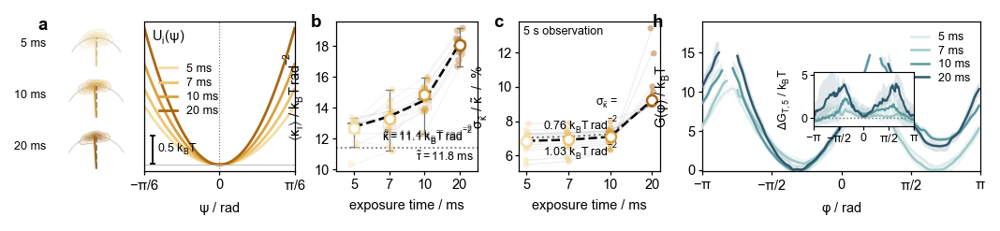

In [74]:
# fig_main, exposure_result = plot_fig3_exposure_time_first_three(
#     m_list=m_list,
#     result=exposure_result,

#     calibration_example_particle=78,
#     representative_window_deg=0,
#     target_particles=selected_target_rotors,
#     representative_target_particle=144,

#     fig_width_mm=180,
#     fig_height_mm=38,

#     target_reconstruction_mode="fixed_window_duration",
#     # target_reconstruction_mode="equal_sample_number",
#     # target_sample_mode="first_n",

#     target_show_bootstrap_bands=True,
#     target_bootstrap_mode="full",
#     target_bootstrap_alpha=0.16,

#     target_inset_bbox=(0.4, 0.3, 0.6, 0.60),
#     target_display_shift_rad=-1,

#     save_dir=save_dir,
#     save_prefix="Fig3_exposure_time_panels",

#     calibration_exposure_time_colors=calibration_exposure_time_colors,
#     target_exposure_time_colors=target_exposure_time_colors,
#     C=CK_colors,
# )

In [78]:
def plot_fig3_exposure_time_first_three(
    m_list,
    result,
    calibration_exposure_time_colors,
    calibration_example_particle=None,
    representative_window_deg=None,
    show_localization_exposure_ms=(5, 10, 20),
    potential_xlim_rad=(-np.pi / 6, np.pi / 6),
    potential_ylim=None,
    potential_scalebar_kBT=0.5,
    localization_exposure_name_map=None,
    localization_phi_cmd_offset_rad=-np.pi / 2,
    localization_min_locs=30,
    contour_bins=180,
    contour_sigma_bins=5.0,
    fig_width_mm=180,
    fig_height_mm=58,
    fontsize=7,
    axis_label_size=7,
    tick_label_size=7,
    annotation_size=6,
    panel_label_size=9,
    panel_labels=("a", "b", "c", "h"),
    sigma_rel_label=r"$\sigma_{{\tilde{\kappa}}}$ / $\tilde{\kappa}$  /  $\%$",
    target_exposure_time_colors=None,
    target_reconstruction_mode="fixed_window_duration",  # "fixed_window_duration" or "equal_sample_number"
    target_sample_mode="first_n",
    target_particles=None,
    representative_target_particle=None,
    target_reference_exposure_ms=5.0,
    target_show_exposures=(5, 7, 10, 20),
    target_delta_exposures=(7, 10, 20),
    target_selection_quantile=0.80,
    target_smooth_bins=3,
    target_delta_smooth_bins=5,  # NEW: display-only smoothing for panel c
    target_energy_zero_mode="per_curve_min",
    target_panel_title=None,
    target_display_shift_rad=0.0,
    target_show_bootstrap_bands=True,
    target_bootstrap_mode="full",
    target_bootstrap_alpha=0.16,
    target_inset_bbox=(0.52, 0.50, 0.44, 0.43),
    target_inset_show_iqr=True,
    target_inset_alpha=0.14,
    target_example_lw_ref=1.35,
    target_example_lw=1.20,
    target_delta_lw=1.05,
    target_ylim=None,
    target_inset_ylim=None,
    C=None,
    save_dir=None,
    save_prefix="Fig3_exposure_time_first_three",
    stator_variant=None,
    dpi=300,
):
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from scipy.stats import norm

    ctx = _exp_prepare_context(
        result=result,
        calibration_exposure_time_colors=calibration_exposure_time_colors,
        calibration_example_particle=calibration_example_particle,
        representative_window_deg=representative_window_deg,
        C=C,
    )

    colors = ctx["colors"]
    black = ctx["black"]
    grey = ctx["grey"]
    midgrey = ctx["midgrey"]
    lightgrey = ctx["lightgrey"]
    exposure_order_ms = ctx["exposure_order_ms"]
    particles = ctx["particles"]
    summary_df = ctx["summary_df"]
    fit_df = ctx["fit_df"]
    fisher_df = ctx["fisher_df"]
    representative_window_deg = ctx["representative_window_deg"]
    calibration_example_particle = ctx["calibration_example_particle"]
    selected_fit_summary = ctx["selected_fit_summary"]
    available_map = ctx["available_map"]

    if target_exposure_time_colors is None:
        target_exposure_time_colors = calibration_exposure_time_colors

    def _rgb(value):
        value = np.asarray(value, float).ravel()[:3]
        return tuple(value / 255 if np.nanmax(value) > 1 else value)

    target_colors = {float(k): _rgb(v) for k, v in target_exposure_time_colors.items()}
    black = _rgb(black)
    grey = _rgb(grey)
    midgrey = _rgb(midgrey)
    lightgrey = _rgb(lightgrey)

    def _flatten(obj):
        if obj is None:
            return []
        if isinstance(obj, (list, tuple)):
            return [item for sub in obj for item in _flatten(sub)]
        return [obj]

    def _wrap(phi):
        return (np.asarray(phi, float) + np.pi) % (2 * np.pi) - np.pi

    def _mm(value):
        return float(value) / 25.4

    def _zero_min(values):
        values = np.asarray(values, float).copy()
        finite = np.isfinite(values)
        if np.any(finite):
            values[finite] -= np.nanmin(values[finite])
        return values

    def _circ_smooth(values, width):
        values = np.asarray(values, float)
        width = int(width)
        if width <= 1:
            return values.copy()
        valid = np.isfinite(values).astype(float)
        filled = np.where(np.isfinite(values), values, 0.0)
        kernel = np.ones(width, float) / width
        pad = width // 2
        num = np.convolve(np.r_[filled[-pad:], filled, filled[:pad]], kernel, mode="same")[pad:-pad]
        den = np.convolve(np.r_[valid[-pad:], valid, valid[:pad]], kernel, mode="same")[pad:-pad]
        return np.divide(num, den, out=np.full_like(num, np.nan), where=den > 0)

    def _periodic_interp(x_new, x, y):
        x = _wrap(x)
        y = np.asarray(y, float)
        order = np.argsort(x)
        x = x[order]
        y = y[order]
        return np.interp(_wrap(x_new), np.r_[x - 2 * np.pi, x, x + 2 * np.pi], np.tile(y, 3))

    def _display_shift_curve(phi_grid, curve, shift_rad):
        phi_grid = np.asarray(phi_grid, float)
        curve = np.asarray(curve, float)
        shift_rad = float(shift_rad)
        if not np.isfinite(shift_rad) or abs(shift_rad) < 1e-15:
            return curve.copy()
        return _periodic_interp(phi_grid - shift_rad, phi_grid, curve)

    def _read_target_bootstrap_band(m, particle):
        particle = int(particle)
        uncertainty = getattr(m, "mbar_statistical_uncertainty_blocks", None)
        if not isinstance(uncertainty, dict):
            raise KeyError(f"{_measurement_name(m)} has no mbar_statistical_uncertainty_blocks.")

        evals = uncertainty.get("evals", {})
        if target_bootstrap_mode not in evals:
            raise KeyError(f"{_measurement_name(m)} has no bootstrap mode {target_bootstrap_mode!r}.")

        curves = evals[target_bootstrap_mode].get("curves", {})
        if particle not in curves:
            raise KeyError(f"{_measurement_name(m)} has no bootstrap result for particle {particle} in mode {target_bootstrap_mode!r}.")

        landscape_df = curves[particle]["landscape_df"]
        required = {"phi", "U_MBAR_point", "U_boot_low", "U_boot_high"}
        missing = required.difference(landscape_df.columns)
        if missing:
            raise KeyError(f"Bootstrap landscape for particle {particle} is missing columns {sorted(missing)}.")

        phi = _wrap(landscape_df["phi"].to_numpy(float))
        point = landscape_df["U_MBAR_point"].to_numpy(float)
        low = landscape_df["U_boot_low"].to_numpy(float)
        high = landscape_df["U_boot_high"].to_numpy(float)
        order = np.argsort(phi)
        return phi[order], point[order], low[order], high[order]

    def _measurement_name(m):
        for attr in ("path", "filename", "file", "name"):
            value = getattr(m, attr, None)
            if value is not None:
                return Path(str(value)).name
        return "measurement"

    def _infer_exposure_ms(m):
        for attr in ("exposure_time_ms", "frame_time_ms", "camera_frame_time_ms"):
            try:
                value = float(getattr(m, attr))
                if np.isfinite(value) and value > 0:
                    return value
            except Exception:
                pass
        for attr in ("_average_tpf", "average_tpf"):
            try:
                value = 1000.0 * float(getattr(m, attr))
                if np.isfinite(value) and value > 0:
                    return value
            except Exception:
                pass
        match = re.search(r"(?<!\d)(\d+(?:\.\d+)?)\s*ms", _measurement_name(m), flags=re.I)
        return float(match.group(1)) if match else np.nan

    def _match_requested_exposure(value, requested):
        if not np.isfinite(value):
            return None
        requested = np.asarray(requested, float)
        candidate = float(requested[np.argmin(np.abs(requested - value))])
        return candidate if np.isclose(candidate, value, atol=0.06, rtol=0.01) else None

    def _style_target_axis(ax):
        ax.grid(False)
        ax.tick_params(length=2, width=0.6, direction="out", pad=1.5, labelsize=tick_label_size)
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)

    if target_reconstruction_mode not in {"fixed_window_duration", "equal_sample_number"}:
        raise ValueError("target_reconstruction_mode must be 'fixed_window_duration' or 'equal_sample_number'.")

    def _get_target_measurements_by_exposure(m_list, exposures):
        out = {}
        for m in _flatten(m_list):
            try:
                exp = _match_requested_exposure(_infer_exposure_ms(m), exposures)
            except Exception:
                exp = None
            if exp is None or exp in out:
                continue
            if target_reconstruction_mode == "fixed_window_duration":
                landscapes = getattr(m, "energy_landscapes", None)
                if isinstance(landscapes, dict) and len(landscapes):
                    out[exp] = m
            else:
                recon = getattr(m, "mbar_reconstructions", None)
                if isinstance(recon, dict) and target_sample_mode in recon:
                    out[exp] = m
        return out

    def _read_target_curve(m, particle):
        particle = int(particle)

        if target_reconstruction_mode == "fixed_window_duration":
            energy_landscapes = getattr(m, "energy_landscapes", {})
            if particle not in energy_landscapes:
                raise KeyError(f"{_measurement_name(m)} has no default target reconstruction for particle {particle}.")

            entry = energy_landscapes[particle]
            if hasattr(entry, "columns"):
                phi_col = "phi" if "phi" in entry.columns else "phi_rad"
                energy_col = next((col for col in ("U_mbar", "U_MBAR", "U_wham", "E", "energy") if col in entry.columns), None)
                if energy_col is None:
                    raise KeyError(f"No energy column found for particle {particle}.")
                phi = entry[phi_col].to_numpy(float)
                energy = entry[energy_col].to_numpy(float)
            elif isinstance(entry, dict):
                phi = entry.get("phi", entry.get("phi_rad", entry.get("centers")))
                energy = entry.get("U_mbar", entry.get("U_MBAR", entry.get("E", entry.get("energy"))))
                if phi is None or energy is None:
                    raise KeyError(f"Incomplete default reconstruction for particle {particle}.")
                phi = np.asarray(phi, float)
                energy = np.asarray(energy, float)
            else:
                raise TypeError(f"Unsupported default reconstruction format for particle {particle}.")
        else:
            recon = getattr(m, "mbar_reconstructions", {})
            if target_sample_mode not in recon:
                raise KeyError(f"{_measurement_name(m)} has no sample mode {target_sample_mode!r}.")
            energy_landscapes = recon[target_sample_mode].get("energy_landscapes", {})
            if particle not in energy_landscapes:
                raise KeyError(f"{_measurement_name(m)} has no {target_sample_mode} target reconstruction for particle {particle}.")
            entry = energy_landscapes[particle]
            phi = np.asarray(entry["centers"], float)
            energy = np.asarray(entry["E"], float)

        order = np.argsort(_wrap(phi))
        return _wrap(phi)[order], np.asarray(energy, float)[order]

    def _collect_target_landscapes():
        requested_exposures = tuple(float(v) for v in target_show_exposures)
        exposure_to_m = _get_target_measurements_by_exposure(m_list, requested_exposures)
        missing = [exp for exp in requested_exposures if exp not in exposure_to_m]
        if missing:
            raise ValueError(f"Missing target reconstructions for exposure times {missing} ms in target_reconstruction_mode={target_reconstruction_mode!r}.")

        if target_particles is None:
            particle_sets = []
            for exp in requested_exposures:
                m = exposure_to_m[exp]
                local = getattr(m, "target_rotors", None)
                if local is not None:
                    particle_sets.append(set(int(v) for v in local))
                else:
                    if target_reconstruction_mode == "fixed_window_duration":
                        energy_landscapes = getattr(m, "energy_landscapes", {})
                        particle_sets.append(set(int(pid) for pid in energy_landscapes))
                    else:
                        energy_landscapes = m.mbar_reconstructions[target_sample_mode].get("energy_landscapes", {})
                        particle_sets.append(set(int(pid) for pid, entry in energy_landscapes.items() if str(entry.get("rotor_class", "")).lower() == "target"))
            particle_pool = sorted(set.intersection(*particle_sets)) if particle_sets else []
        else:
            particle_pool = sorted(set(int(v) for v in target_particles))

        if not particle_pool:
            raise ValueError("No target rotors available for the requested reconstruction comparison.")

        common_phi = np.linspace(-np.pi, np.pi, 181, endpoint=False)
        aligned = {}
        alignment_phi0 = {}
        valid_particles = []

        for particle in particle_pool:
            raw = {}
            ok = True
            for exp in requested_exposures:
                try:
                    raw[exp] = _read_target_curve(exposure_to_m[exp], particle)
                except Exception:
                    ok = False
                    break
            if not ok:
                continue

            phi_ref, energy_ref = raw[float(target_reference_exposure_ms)]
            smooth_ref = _circ_smooth(energy_ref, target_smooth_bins)
            idx0 = int(np.nanargmin(smooth_ref))
            phi0 = float(phi_ref[idx0])

            curves = {}
            for exp in requested_exposures:
                phi, energy = raw[exp]
                aligned_phi = _wrap(phi - phi0)
                order = np.argsort(aligned_phi)
                curve = _periodic_interp(common_phi, aligned_phi[order], np.asarray(energy, float)[order])
                if target_energy_zero_mode == "per_curve_min":
                    curve = _zero_min(curve)
                curves[exp] = curve

            aligned[int(particle)] = curves
            alignment_phi0[int(particle)] = float(phi0)
            valid_particles.append(int(particle))

        if not valid_particles:
            raise ValueError("No target rotors contain reconstructions at all requested exposure times.")

        return exposure_to_m, valid_particles, common_phi, aligned, alignment_phi0

    def _select_representative_target(valid_particles, aligned, exposures):
        if representative_target_particle is not None and int(representative_target_particle) in valid_particles:
            return int(representative_target_particle)
        last_exp = float(max(target_delta_exposures))
        scores = []
        for particle in valid_particles:
            ref = aligned[particle][float(target_reference_exposure_ms)]
            cur = aligned[particle][last_exp]
            finite = np.isfinite(ref) & np.isfinite(cur)
            if finite.sum() < 8:
                scores.append(np.nan)
            else:
                scores.append(float(np.sqrt(np.nanmean((cur[finite] - ref[finite]) ** 2))))
        scores = np.asarray(scores, float)
        target_score = np.nanquantile(scores[np.isfinite(scores)], float(target_selection_quantile))
        return int(valid_particles[int(np.nanargmin(np.abs(scores - target_score)))])

    def _build_target_delta_stats(valid_particles, aligned, common_phi):
        delta_exposures = tuple(float(v) for v in target_delta_exposures if float(v) != float(target_reference_exposure_ms))
        stats = {}
        for exp in delta_exposures:
            stack = []
            for particle in valid_particles:
                ref = aligned[particle][float(target_reference_exposure_ms)]
                cur = aligned[particle][exp]
                stack.append(cur - ref)
            stack = np.asarray(stack, float)
            stats[exp] = {
                "median": np.nanmedian(stack, axis=0),
                "q25": np.nanpercentile(stack, 25, axis=0),
                "q75": np.nanpercentile(stack, 75, axis=0),
            }
        return stats

    visible_loc_exposures = [float(value) for value in show_localization_exposure_ms if float(value) in exposure_order_ms]

    localization_rows = {
        exposure_ms: _exp_get_localization_example(
            m_list=m_list,
            exposure_ms=exposure_ms,
            particle=calibration_example_particle,
            representative_window_deg=representative_window_deg,
            exposure_name_map=localization_exposure_name_map,
            phi_cmd_offset_rad=localization_phi_cmd_offset_rad,
            min_locs=localization_min_locs,
        )
        for exposure_ms in visible_loc_exposures
    }

    print(
        f"Selected calibration rotor {calibration_example_particle}\n"
        f"  kappa_tilde = {selected_fit_summary['kappa_tilde']:.3f} kBT rad^-2\n"
        f"  tau_tilde   = {selected_fit_summary['tau_tilde_ms']:.3f} ms"
    )

    if np.isfinite(selected_fit_summary["tau_ci_low_ms"]) and np.isfinite(selected_fit_summary["tau_ci_high_ms"]):
        print(
            f"  tau_tilde 95% CI = "
            f"[{selected_fit_summary['tau_ci_low_ms']:.3f}, "
            f"{selected_fit_summary['tau_ci_high_ms']:.3f}] ms"
        )

    if np.isfinite(selected_fit_summary["r2"]):
        print(f"  R^2              = {selected_fit_summary['r2']:.4f}")

    exposure_to_m_target, valid_target_particles, common_phi_target, aligned_target, target_alignment_phi0 = _collect_target_landscapes()

    selected_target_particle = _select_representative_target(
        valid_target_particles,
        aligned_target,
        target_show_exposures,
    )

    target_delta_stats = _build_target_delta_stats(
        valid_target_particles,
        aligned_target,
        common_phi_target,
    )

    target_bootstrap_bands = {}
    if target_show_bootstrap_bands:
        if target_reconstruction_mode != "fixed_window_duration":
            print(
                "Bootstrap bands are only shown for "
                "target_reconstruction_mode='fixed_window_duration'; "
                "skipping bands for the equal-sample-number control."
            )
        else:
            phi0 = target_alignment_phi0[selected_target_particle]
            for exp in map(float, target_show_exposures):
                m = exposure_to_m_target[exp]
                phi, point, low, high = _read_target_bootstrap_band(m, selected_target_particle)

                aligned_phi = _wrap(phi - phi0)
                order = np.argsort(aligned_phi)
                aligned_phi = aligned_phi[order]
                point = point[order]
                low = low[order]
                high = high[order]

                point_i = _periodic_interp(common_phi_target, aligned_phi, point)
                low_i = _periodic_interp(common_phi_target, aligned_phi, low)
                high_i = _periodic_interp(common_phi_target, aligned_phi, high)

                if target_energy_zero_mode == "per_curve_min":
                    finite = np.isfinite(point_i)
                    offset = np.nanmin(point_i[finite]) if np.any(finite) else 0.0
                    low_i = low_i - offset
                    high_i = high_i - offset

                target_bootstrap_bands[exp] = {"low": low_i, "high": high_i}

    plt.rcParams.update({
        "font.size": fontsize,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.linewidth": 0.6,
        "axes.labelsize": axis_label_size,
        "xtick.labelsize": tick_label_size,
        "ytick.labelsize": tick_label_size,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    fig = plt.figure(figsize=(_mm(fig_width_mm), _mm(fig_height_mm)))

    outer = fig.add_gridspec(
        1,
        4,
        left=0.028,
        right=0.992,
        bottom=0.185,
        top=0.900,
        width_ratios=(1.55, 0.8, 0.8, 1.58),
        wspace=0.20,
    )

    gs_a = outer[0, 0].subgridspec(1, 2, width_ratios=(1.0, 1.0), wspace=-0.18)
    gs_locs = gs_a[0, 0].subgridspec(len(visible_loc_exposures), 1, hspace=0.08)

    ax_locs = [fig.add_subplot(gs_locs[index, 0]) for index in range(len(visible_loc_exposures))]
    ax_a = fig.add_subplot(gs_a[0, 1])
    ax_b = fig.add_subplot(outer[0, 1])
    ax_c = fig.add_subplot(outer[0, 2])
    ax_h = fig.add_subplot(outer[0, 3])

    x_potential = np.linspace(float(potential_xlim_rad[0]), float(potential_xlim_rad[1]), 500)
    fit_rows = []

    for exposure_ms in exposure_order_ms:
        _, window_deg, psi = available_map[exposure_ms]
        psi = psi[np.isfinite(psi)]
        gaussian_mu, gaussian_sigma = norm.fit(psi)
        gaussian_kappa = 1 / gaussian_sigma**2
        color = colors.get(exposure_ms, grey)

        ax_a.plot(
            x_potential,
            0.5 * gaussian_kappa * x_potential**2,
            color=color,
            lw=1.35,
            label=f"{exposure_ms:g} ms",
        )

        fit_rows.append({
            "tpf": exposure_ms,
            "particle": calibration_example_particle,
            "window_deg": window_deg,
            "gaussian_mu_rad": gaussian_mu,
            "gaussian_sigma_rad": gaussian_sigma,
            "gaussian_kappa": gaussian_kappa,
        })

    ax_a.axvline(0, color=midgrey, lw=0.55, ls=":")
    ax_a.axhline(0, color=lightgrey, lw=0.45)
    ax_a.set_xlim(*potential_xlim_rad)

    if potential_ylim is not None:
        ax_a.set_ylim(*potential_ylim)

    ax_a.set_xticks([-np.pi / 6, 0, np.pi / 6])
    ax_a.set_xticklabels([r"$-\pi/6$", "0", r"$\pi/6$"])
    ax_a.set_xlabel(r"$\psi$ / rad")
    ax_a.set_ylabel("")
    ax_a.set_yticks([])
    ax_a.tick_params(axis="y", length=0)
    ax_a.text(0.05, 0.95, r"$U_{i}(\psi)$", transform=ax_a.transAxes, ha="left", va="top", fontsize=7, color=black)
    ax_a.legend(frameon=False, fontsize=annotation_size, loc="upper left", bbox_to_anchor=(0.03, 0.79), handlelength=1.5, labelspacing=0.25)

    y0, y1 = ax_a.get_ylim()
    x0, x1 = ax_a.get_xlim()
    xspan = x1 - x0
    yspan = y1 - y0
    sb_x = x0 + 0.055 * xspan
    sb_y0 = y0 + 0.055 * yspan
    sb_y1 = min(sb_y0 + float(potential_scalebar_kBT), y1 - 0.06 * yspan)

    ax_a.plot([sb_x, sb_x], [sb_y0, sb_y1], color=black, lw=0.9, solid_capstyle="butt", zorder=10)
    ax_a.plot([sb_x - 0.012 * xspan, sb_x + 0.012 * xspan], [sb_y0, sb_y0], color=black, lw=0.9, zorder=10)
    ax_a.plot([sb_x - 0.012 * xspan, sb_x + 0.012 * xspan], [sb_y1, sb_y1], color=black, lw=0.9, zorder=10)
    ax_a.text(sb_x + 0.03 * xspan, 0.5 * (sb_y0 + sb_y1), rf"{potential_scalebar_kBT:g} $k_\mathrm{{B}}T$", ha="left", va="center", fontsize=annotation_size, color=black)
    _exp_style_axis(ax_a, black)

    for axis, exposure_ms in zip(ax_locs, visible_loc_exposures):
        _exp_style_localization_axis(axis, rlim=0.82)
        row = localization_rows[exposure_ms]
        color = colors.get(exposure_ms, grey)
        x = np.asarray(row["x"], float)
        y = np.asarray(row["y"], float)
        valid = np.isfinite(x) & np.isfinite(y)
        x, y = x[valid], y[valid]

        xedges = np.linspace(-0.82, 0.82, int(contour_bins) + 1)
        yedges = np.linspace(-0.08 * 0.82, 0.82, int(contour_bins) + 1)
        density = np.histogram2d(x, y, bins=[xedges, yedges])[0].T
        density = _exp_smooth_2d(density, contour_sigma_bins)
        positive = density[density > 0]
        clip_value = np.percentile(positive, 99.6) if positive.size else 1.0
        density = np.clip(density / clip_value, 0, 1) ** 0.86

        xc = 0.5 * (xedges[:-1] + xedges[1:])
        yc = 0.5 * (yedges[:-1] + yedges[1:])
        X, Y = np.meshgrid(xc, yc)

        axis.contourf(
            X, Y, density,
            levels=(0.06, 0.12, 0.22, 0.36, 0.54, 0.74, 1.00),
            cmap=_exp_density_cmap(color),
            antialiased=True,
            zorder=2,
        )

        axis.contour(
            X, Y, density,
            levels=(0.18, 0.38, 0.62),
            colors=[_exp_blend(color, midgrey, 0.10)],
            linewidths=0.36,
            alpha=0.42,
            zorder=3,
        )

        theta = np.linspace(np.pi / 2 - np.deg2rad(60), np.pi / 2 + np.deg2rad(60), 240)
        axis.plot(row["R_plot"] * np.cos(theta), row["R_plot"] * np.sin(theta), color=lightgrey, lw=0.70, alpha=0.50, zorder=4)
        axis.plot([0, row["x_cmd"]], [0, row["y_cmd"]], color=midgrey, lw=0.85, ls="--", zorder=5)
        axis.plot([0, row["x_mean"]], [0, row["y_mean"]], color=_exp_blend(color, midgrey, 0.08), lw=1.05, zorder=6)
        axis.text(-0.07, 0.52, f"{exposure_ms:g} ms", transform=axis.transAxes, ha="right", va="center", fontsize=annotation_size, color=black, clip_on=False)

    x_positions = np.arange(len(exposure_order_ms), dtype=float)
    exposure_fine = np.linspace(min(exposure_order_ms), max(exposure_order_ms), 300)
    x_fine = np.interp(exposure_fine, exposure_order_ms, x_positions)

    wide_kappa = (
        summary_df[summary_df["particle"].isin(particles)]
        .pivot(index="particle", columns="tpf", values="kappa")
        .reindex(index=particles, columns=exposure_order_ms)
    )

    rng = np.random.default_rng(4)

    for particle in particles:
        if particle == calibration_example_particle:
            continue
        ax_b.plot(x_positions, wide_kappa.loc[particle].to_numpy(float), color=lightgrey, lw=0.45, alpha=0.20, zorder=1)

    box_data = [wide_kappa[exposure_ms].dropna().to_numpy(float) for exposure_ms in exposure_order_ms]
    boxplot = ax_b.boxplot(
        box_data,
        positions=x_positions,
        widths=0.34,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": midgrey, "linewidth": 0.8},
        boxprops={"linewidth": 0.6, "color": midgrey},
        whiskerprops={"linewidth": 0.6, "color": midgrey},
        capprops={"linewidth": 0.6, "color": midgrey},
    )

    for patch, exposure_ms in zip(boxplot["boxes"], exposure_order_ms):
        patch.set_facecolor(colors.get(exposure_ms, grey))
        patch.set_alpha(0.13)

    for index, exposure_ms in enumerate(exposure_order_ms):
        values = wide_kappa[exposure_ms].drop(index=calibration_example_particle, errors="ignore").dropna().to_numpy(float)
        jitter = rng.uniform(-0.10, 0.10, len(values))
        ax_b.scatter(np.full(len(values), index) + jitter, values, s=13, color=colors.get(exposure_ms, grey), alpha=0.36, edgecolor="none", zorder=3)

    selected_observed = wide_kappa.loc[calibration_example_particle].to_numpy(float)

    for index, (exposure_ms, value) in enumerate(zip(exposure_order_ms, selected_observed)):
        if np.isfinite(value):
            ax_b.scatter([index], [value], s=28, facecolor="white", edgecolor=colors.get(exposure_ms, grey), linewidth=1.15, zorder=9)

    selected_prediction = _exp_kappa_model(exposure_fine, selected_fit_summary["kappa_tilde"], selected_fit_summary["tau_tilde_ms"])
    ax_b.plot(x_fine, selected_prediction, color=black, lw=1.25, ls="--", zorder=8)

    median_kappa_tilde = float(np.nanmedian(fit_df["kappa_tilde"].to_numpy(float)))
    ax_b.axhline(median_kappa_tilde, color=midgrey, lw=0.85, ls=":", zorder=0)
    ax_b.text(
        0.97,
        median_kappa_tilde + 0.13,
        rf"$\tilde{{\kappa}}={median_kappa_tilde:.1f}\;" rf"k_\mathrm{{B}}T\,\mathrm{{rad}}^{{-2}}$",
        transform=ax_b.get_yaxis_transform(),
        ha="right",
        va="bottom",
        fontsize=annotation_size,
        color=midgrey,
    )
    ax_b.text(
        0.97,
        0.055,
        rf"$\tilde{{\kappa}}={selected_fit_summary['kappa_tilde']:.1f}" rf"\;k_\mathrm{{B}}T\,\mathrm{{rad}}^{{-2}}$"
        + "\n"
        + rf"$\tilde{{\tau}}={selected_fit_summary['tau_tilde_ms']:.1f}\;\mathrm{{ms}}$",
        transform=ax_b.transAxes,
        ha="right",
        va="bottom",
        fontsize=annotation_size,
        color=black,
    )
    ax_b.set_xticks(x_positions)
    ax_b.set_xticklabels([f"{value:g}" for value in exposure_order_ms])
    ax_b.set_xlabel("exposure time / ms")
    ax_b.set_ylabel(r"$\langle\kappa_i\rangle$ / $k_\mathrm{B}T\,\mathrm{rad}^{-2}$")
    _exp_style_axis(ax_b, black)

    # Panel c: former inset moved here, with display-only smoothing
    ref_exp = float(target_reference_exposure_ms)
    delta_exposures = [float(v) for v in target_delta_exposures if float(v) != ref_exp]

    for exp in delta_exposures:
        stats = target_delta_stats[exp]
        color = target_colors.get(exp, grey)

        median_plot = _circ_smooth(stats["median"], target_delta_smooth_bins)
        q25_plot = _circ_smooth(stats["q25"], target_delta_smooth_bins)
        q75_plot = _circ_smooth(stats["q75"], target_delta_smooth_bins)

        if target_inset_show_iqr:
            ax_c.fill_between(common_phi_target, q25_plot, q75_plot, color=color, alpha=target_inset_alpha, lw=0)

        ax_c.plot(common_phi_target, median_plot, color=color, lw=target_delta_lw, label=f"{exp:g} ms - {ref_exp:g} ms")

    ax_c.axhline(0, color=midgrey, lw=0.7, ls=":")
    ax_c.set_xlim(-np.pi, np.pi)
    ax_c.set_ylim(*target_inset_ylim if target_inset_ylim is not None else (-1, 5.3))
    ax_c.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
    ax_c.set_xticklabels([r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"])
    ax_c.set_xlabel(r"$\varphi$ / rad")
    ax_c.set_ylabel(r"$\Delta G_{T,5}$ / $k_\mathrm{B}T$")
    ax_c.tick_params(length=2, width=0.55, direction="out", pad=1.0, labelsize=annotation_size)
    for spine in ax_c.spines.values():
        spine.set_linewidth(0.55)

    # Panel h: main target curves only, no inset
    show_exposures = [float(v) for v in target_show_exposures]
    example_curves = aligned_target[selected_target_particle]
    display_shift = float(target_display_shift_rad)

    for exp in show_exposures:
        color = target_colors.get(exp, grey)

        if exp in target_bootstrap_bands:
            low = _display_shift_curve(common_phi_target, target_bootstrap_bands[exp]["low"], display_shift)
            high = _display_shift_curve(common_phi_target, target_bootstrap_bands[exp]["high"], display_shift)
            ax_h.fill_between(common_phi_target, low, high, color=color, alpha=target_bootstrap_alpha, lw=0, zorder=1)

        ax_h.plot(
            common_phi_target,
            _display_shift_curve(common_phi_target, example_curves[exp], display_shift),
            color=color,
            lw=target_example_lw,
            label=f"{exp:g} ms",
            zorder=3,
        )

    ax_h.set_xlim(-np.pi, np.pi)
    ax_h.set_ylim(*target_ylim if target_ylim is not None else (-0.18, 19))
    ax_h.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
    ax_h.set_xticklabels([r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"])
    ax_h.set_xlabel(r"$\varphi$ / rad")
    ax_h.set_ylabel(r"$G(\varphi)$ / $k_\mathrm{B}T$")
    ax_h.legend(frameon=False, fontsize=annotation_size, loc="upper right", handlelength=1.5, labelspacing=0.20)
    _style_target_axis(ax_h)

    # Panel labels
    ax_locs[0].text(-0.16, 1.10, panel_labels[0], transform=ax_locs[0].transAxes, fontsize=panel_label_size, fontweight="bold", va="top", color=black)
    ax_b.text(-0.18, 1.05, panel_labels[1], transform=ax_b.transAxes, fontsize=panel_label_size, fontweight="bold", va="top", color=black)
    ax_c.text(-0.18, 1.05, panel_labels[2], transform=ax_c.transAxes, fontsize=panel_label_size, fontweight="bold", va="top", color=black)
    ax_h.text(-0.18, 1.05, panel_labels[3], transform=ax_h.transAxes, fontsize=panel_label_size, fontweight="bold", va="top", color=black)

    result["example_distribution_fits"] = pd.DataFrame(fit_rows)
    result["selected_example_fit"] = selected_fit_summary
    result["target_first_n_panel"] = {
        "reconstruction_mode": str(target_reconstruction_mode),
        "sample_mode": str(target_sample_mode) if target_reconstruction_mode == "equal_sample_number" else None,
        "reference_exposure_ms": float(target_reference_exposure_ms),
        "display_shift_rad": float(target_display_shift_rad),
        "show_bootstrap_bands": bool(target_show_bootstrap_bands),
        "bootstrap_mode": (
            str(target_bootstrap_mode)
            if target_show_bootstrap_bands and target_reconstruction_mode == "fixed_window_duration"
            else None
        ),
        "bootstrap_alpha": float(target_bootstrap_alpha),
        "representative_target_particle": int(selected_target_particle),
        "n_target_particles": int(len(valid_target_particles)),
        "available_target_particles": list(map(int, valid_target_particles)),
        "delta_stats": {
            float(exp): {
                "phi": common_phi_target.copy(),
                "median_delta": target_delta_stats[exp]["median"].copy(),
                "q25_delta": target_delta_stats[exp]["q25"].copy(),
                "q75_delta": target_delta_stats[exp]["q75"].copy(),
            }
            for exp in delta_exposures
        },
        "target_delta_smooth_bins": int(target_delta_smooth_bins),
    }

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        prefix = f"{stator_variant}__{save_prefix}" if stator_variant else save_prefix
        fig.savefig(save_dir / f"{prefix}.png", dpi=dpi, bbox_inches="tight")
        fig.savefig(save_dir / f"{prefix}.svg", bbox_inches="tight")

    plt.show()
    plt.close(fig)
    return fig, result

Selected calibration rotor 78
  kappa_tilde = 11.119 kBT rad^-2
  tau_tilde   = 11.791 ms
  tau_tilde 95% CI = [9.201, 15.868] ms
  R^2              = 0.9892


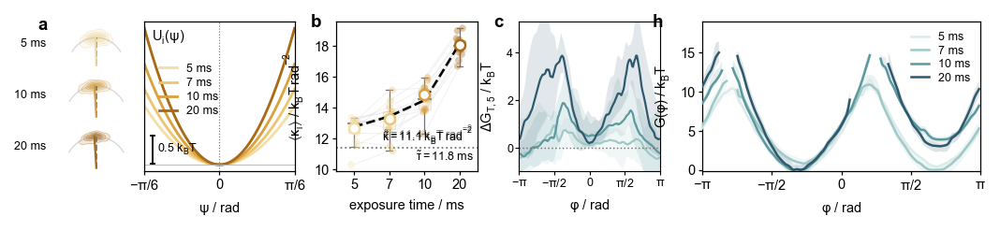

In [123]:
fig_main, exposure_result = plot_fig3_exposure_time_first_three(
    m_list=m_list,
    result=exposure_result,

    calibration_example_particle=78,
    representative_window_deg=0,
    target_particles=selected_target_rotors,
    representative_target_particle=144,

    fig_width_mm=180,
    fig_height_mm=38,

    target_reconstruction_mode="fixed_window_duration",
    # target_reconstruction_mode="equal_sample_number",
    # target_sample_mode="first_n",

    target_show_bootstrap_bands=True,
    target_bootstrap_mode="full",
    target_bootstrap_alpha=0.16,

    target_inset_bbox=(0.4, 0.3, 0.6, 0.60),
    target_display_shift_rad=-1,

    save_dir=r"R:\_06_Umbrella_Sampling\02_Figures\Figure_3\effect_sampling_time",
    save_prefix="Fig3_exposure_time_panels",

    calibration_exposure_time_colors=calibration_exposure_time_colors,
    target_exposure_time_colors=target_exposure_time_colors,
    C=CK_colors,
)

#### iv. SI | Plot effect exposure time on target rotors

In [52]:
def compute_MBAR_equal_sample_uncertainty_blocks(
    m_list,
    particles=None,
    sample_mode="first_n",
    uncertainty_mode="target_only",
    n_bootstrap=500,
    block_s_target=0.25,
    ci=(2.5, 97.5),
    seed=1,
    min_keep=200,
    mbar_tol=1e-7,
    mbar_max_iter=1000,
    mbar_damp=0.8,
):
    """
    Block-bootstrap uncertainty for equal-sample-number MBAR reconstructions.

    The point reconstruction is read from

        m.mbar_reconstructions[sample_mode]

    and the bootstrap uses exactly the same post-trim samples and phases stored
    by run_MBAR_sampling_controls(...).

    Only sample_mode="first_n" is supported because block bootstrapping requires
    a contiguous time series. "spaced_n" is a useful reconstruction control,
    but its evenly spaced observations are not a contiguous trajectory.

    The calibration centers and stiffness values are kept fixed at those used
    in the equal-sample point reconstruction. This is therefore a target-only
    statistical uncertainty analysis.

    Stores
    ------
    m.mbar_sampling_control_uncertainty_blocks[sample_mode] = {
        "evals": {
            "target_only": {
                "curves": {
                    particle: {
                        "landscape_df": ...,
                        "U_boot_curves": ...,
                        "phase_list": ...,
                    }
                },
                "summary_df": ...,
            }
        },
        "summary_long": ...,
        "meta": ...,
    }

    Nothing is returned.
    """
    import numpy as np
    import pandas as pd
    from pathlib import Path
    from tqdm.auto import tqdm

    sample_mode = str(sample_mode).lower().strip()
    uncertainty_mode = str(uncertainty_mode).lower().replace("-", "_").strip()

    if sample_mode != "first_n":
        raise ValueError(
            "compute_MBAR_equal_sample_uncertainty_blocks currently supports "
            "sample_mode='first_n' only. Block bootstrap is not appropriate "
            "for the non-contiguous 'spaced_n' sample sequence."
        )

    if uncertainty_mode != "target_only":
        raise ValueError(
            "uncertainty_mode must be 'target_only'. Calibration parameters "
            "are kept fixed at the values used for the equal-sample point "
            "reconstruction."
        )

    def flatten(values):
        if values is None:
            return []
        if isinstance(values, (list, tuple)):
            return [item for sub in values for item in flatten(sub)]
        return [values]

    def measurement_name(m):
        return Path(str(getattr(m, "path", "UMB measurement"))).name

    def wrap_pi(phi):
        return (np.asarray(phi, dtype=float) + np.pi) % (2 * np.pi) - np.pi

    def zero_min(U):
        U = np.asarray(U, dtype=float).copy()
        finite = np.isfinite(U)
        if np.any(finite):
            U[finite] -= np.nanmin(U[finite])
        return U

    def align_to_reference(U, U_ref):
        U = np.asarray(U, dtype=float).copy()
        U_ref = np.asarray(U_ref, dtype=float)
        finite = np.isfinite(U) & np.isfinite(U_ref)
        if np.sum(finite) >= 3:
            U -= np.nanmedian(U[finite] - U_ref[finite])
        else:
            U = zero_min(U)
        return U

    def logsumexp(a, axis=None):
        a = np.asarray(a, dtype=float)
        amax = np.max(a, axis=axis, keepdims=True)
        out = amax + np.log(np.sum(np.exp(a - amax), axis=axis, keepdims=True))
        return np.squeeze(out) if axis is None else np.squeeze(out, axis=axis)

    def ensure_time(m):
        if "t" in m.locs.columns:
            return
        m.locs = m.locs.copy()
        if "averagetime" in m.locs.columns:
            m.locs["t"] = m.locs["averagetime"].astype(float)
        elif "time" in m.locs.columns:
            m.locs["t"] = m.locs["time"].astype(float)
        elif "time_s" in m.locs.columns:
            m.locs["t"] = m.locs["time_s"].astype(float)
        elif "frame" in m.locs.columns:
            dt = float(getattr(m, "_average_tpf", 0.005))
            m.locs["t"] = m.locs["frame"].astype(float) * dt
        else:
            raise KeyError(
                "m.locs needs 't', 'averagetime', 'time', 'time_s', or 'frame'."
            )

    def lag1(values):
        values = np.asarray(values, dtype=float)
        if values.size < 3:
            return 0.0
        a = values[:-1] - np.mean(values[:-1])
        b = values[1:] - np.mean(values[1:])
        denominator = np.sqrt(np.sum(a * a) * np.sum(b * b)) + 1e-30
        return float(np.sum(a * b) / denominator)

    def circular_lag1(phi):
        rho = 0.5 * (lag1(np.cos(phi)) + lag1(np.sin(phi)))
        return float(np.clip(rho, -0.99, 0.99))

    def block_bootstrap(phi, t, block_s, rng):
        phi = np.asarray(phi, dtype=float)
        t = np.asarray(t, dtype=float)

        if phi.size == 0:
            return phi.copy()

        if phi.size < 3 or block_s is None or float(block_s) <= 0:
            return wrap_pi(phi[rng.integers(0, phi.size, size=phi.size)])

        dt = np.nanmedian(np.diff(t)) if t.size > 1 else np.nan
        block_n = (
            max(1, int(round(float(block_s) / dt)))
            if np.isfinite(dt) and dt > 0
            else max(1, int(round(phi.size / 10)))
        )
        block_n = min(block_n, phi.size)

        starts = np.arange(0, phi.size, block_n, dtype=int)
        blocks = [phi[start:min(start + block_n, phi.size)] for start in starts]

        if len(blocks) == 1:
            return wrap_pi(phi[rng.integers(0, phi.size, size=phi.size)])

        n_blocks = int(np.ceil(phi.size / block_n))
        selected = rng.integers(0, len(blocks), size=n_blocks)
        return wrap_pi(np.concatenate([blocks[i] for i in selected])[:phi.size])

    def run_mbar(samples, centers, kappa, bias_potential, nbins, pmin_nan):
        counts = np.asarray([len(sample) for sample in samples], dtype=float)

        if len(samples) < 3 or np.any(counts <= 0):
            raise ValueError("MBAR needs at least three non-empty umbrella windows.")

        phi = wrap_pi(np.concatenate(samples))
        centers = np.asarray(centers, dtype=float)
        kappa = np.asarray(kappa, dtype=float)

        if centers.size != len(samples) or kappa.size != len(samples):
            raise ValueError("MBAR sample, center, and kappa sizes do not match.")

        if not np.all(np.isfinite(centers)):
            raise ValueError("Non-finite umbrella center encountered.")

        if not np.all(np.isfinite(kappa) & (kappa > 0)):
            raise ValueError("Non-finite or non-positive kappa encountered.")

        delta = wrap_pi(phi[None, :] - centers[:, None])

        if bias_potential == "cosine":
            u_kn = kappa[:, None] * (1 - np.cos(delta))
        elif bias_potential == "harmonic":
            u_kn = 0.5 * kappa[:, None] * delta**2
        else:
            raise ValueError("bias_potential must be 'cosine' or 'harmonic'.")

        log_counts = np.log(counts)
        f_k = np.zeros(len(samples), dtype=float)
        converged = False
        max_delta = np.nan

        for iteration in range(int(mbar_max_iter)):
            log_denominator = logsumexp(
                log_counts[:, None] + f_k[:, None] - u_kn,
                axis=0,
            )
            f_new = np.asarray([
                -logsumexp(-u_kn[i] - log_denominator)
                for i in range(len(f_k))
            ])
            f_new -= f_new[0]
            f_next = (1 - float(mbar_damp)) * f_k + float(mbar_damp) * f_new
            max_delta = float(np.max(np.abs(f_next - f_k)))
            f_k = f_next

            if max_delta < float(mbar_tol):
                converged = True
                break

        log_denominator = logsumexp(
            log_counts[:, None] + f_k[:, None] - u_kn,
            axis=0,
        )
        log_weights = -log_denominator
        log_weights -= logsumexp(log_weights)
        weights = np.exp(log_weights)

        edges = np.linspace(-np.pi, np.pi, int(nbins) + 1)
        phi_grid = 0.5 * (edges[:-1] + edges[1:])
        dphi = float(edges[1] - edges[0])

        probability, _ = np.histogram(phi, bins=edges, weights=weights)
        probability = probability.astype(float) / dphi
        normalization = probability.sum() * dphi

        if normalization > 0:
            probability /= normalization

        energy = np.full(probability.size, np.nan)
        positive = probability > 0
        energy[positive] = -np.log(probability[positive])

        if pmin_nan is not None and float(pmin_nan) > 0:
            energy[probability < float(pmin_nan)] = np.nan

        weight_square_sum = np.sum(weights**2)

        return {
            "phi": phi_grid,
            "P": probability,
            "U": zero_min(energy),
            "converged": bool(converged),
            "n_iter": int(iteration + 1),
            "max_delta": float(max_delta),
            "ess": (
                float(1 / weight_square_sum)
                if weight_square_sum > 0
                else np.nan
            ),
        }

    def stored_point_curve(recon, particle):
        primary = recon.get("reconstructed", {})
        if int(particle) in primary:
            table = primary[int(particle)]
            return (
                table["phi"].to_numpy(float),
                table["U_mbar"].to_numpy(float),
                table["P_mbar"].to_numpy(float),
            )

        entry = recon.get("energy_landscapes", {}).get(int(particle))
        if entry is None:
            raise KeyError(f"No equal-sample point reconstruction for particle {particle}.")

        phi = np.asarray(entry["centers"], float)
        U = np.asarray(entry["E"], float)
        return phi, U, np.full_like(U, np.nan)

    def phase_parameters(recon, phases):
        center_bias = recon["center_bias"]
        kappa_bias = recon["kappa_bias"]

        center_mode = str(center_bias.get("primary_center", center_bias.get("mode", "ensemble")))
        center_df = center_bias["by_window"]

        center_column = (
            "ensemble_phi0"
            if center_mode == "ensemble"
            else "command_phi0"
        )
        center_map = dict(
            zip(
                center_df["phase"].astype(str),
                center_df[center_column].astype(float),
            )
        )

        kappa_mode = str(kappa_bias["mode"])
        if kappa_mode == "global":
            kappa_value = float(kappa_bias["global_target"])
            kappa = np.full(len(phases), kappa_value, dtype=float)
        elif kappa_mode == "by_angle":
            kappa_df = kappa_bias["by_angle"]
            kappa_map = dict(
                zip(
                    kappa_df["phase"].astype(str),
                    kappa_df["kappa_mean_used_target"].astype(float),
                )
            )
            kappa = np.asarray([kappa_map[str(phase)] for phase in phases], float)
        else:
            raise ValueError("Stored kappa mode must be 'global' or 'by_angle'.")

        centers = np.asarray([center_map[str(phase)] for phase in phases], float)
        return wrap_pi(centers), kappa

    def collect_exact_first_n_traces(m, recon, particle):
        ensure_time(m)

        sampling_df = recon.get("sampling_df")
        if not isinstance(sampling_df, pd.DataFrame) or sampling_df.empty:
            raise ValueError("Stored equal-sample reconstruction has no sampling_df.")

        rows = (
            sampling_df[
                sampling_df["particle"].astype(int).eq(int(particle))
            ]
            .sort_values("phase_start_s", kind="mergesort")
            .copy()
        )

        if rows.empty:
            raise ValueError(
                f"Particle {particle}: no stored first_n sampling rows."
            )

        if "group" not in m.locs.columns or "phi" not in m.locs.columns:
            raise KeyError("m.locs needs 'group' and 'phi'.")

        data = (
            m.locs.loc[
                m.locs["group"].astype(int).eq(int(particle)),
                ["phi", "t"],
            ]
            .sort_values("t", kind="mergesort")
            .copy()
        )

        if data.empty:
            raise ValueError(f"Particle {particle}: no localizations.")

        data["phi"] = wrap_pi(data["phi"].to_numpy(float))
        traces = []

        for row in rows.itertuples():
            phase = str(row.phase)
            start = float(row.phase_start_s)
            stop = float(row.selected_phase_stop_s)
            n_trim = int(row.n_trim)
            n_used = int(row.n_used)

            selected = (data["t"] >= start) & (data["t"] < stop)
            phi = data.loc[selected, "phi"].to_numpy(float)
            t = data.loc[selected, "t"].to_numpy(float)

            if n_trim > 0:
                phi = phi[n_trim:]
                t = t[n_trim:]

            phi = phi[:n_used]
            t = t[:n_used]

            finite = np.isfinite(phi) & np.isfinite(t)
            phi = wrap_pi(phi[finite])
            t = t[finite]

            if phi.size < int(min_keep):
                raise ValueError(
                    f"Particle {particle}, phase {phase}: only {phi.size} "
                    f"stored first_n samples remain."
                )

            rho = circular_lag1(phi)
            denominator = 1 + rho
            ess = (
                phi.size * (1 - rho) / denominator
                if denominator > 1e-12
                else float(phi.size)
            )

            if ess < 10:
                raise ValueError(
                    f"Particle {particle}, phase {phase}: ESS={ess:.2f} < 10."
                )

            traces.append({
                "phase": phase,
                "phi": phi,
                "t": t,
            })

        if len(traces) < 3:
            raise ValueError(
                f"Particle {particle}: fewer than three usable first_n windows."
            )

        return traces

    measurements = []
    for m in flatten(m_list):
        recon_all = getattr(m, "mbar_reconstructions", None)
        if isinstance(recon_all, dict) and sample_mode in recon_all:
            measurements.append(m)

    if not measurements:
        raise ValueError(
            f"No measurements contain m.mbar_reconstructions[{sample_mode!r}]. "
            "Run run_MBAR_sampling_controls(...) first."
        )

    for m in tqdm(
        measurements,
        desc=f"equal-sample bootstrap | {sample_mode}",
        total=len(measurements),
        dynamic_ncols=True,
    ):
        recon = m.mbar_reconstructions[sample_mode]
        meta = recon.get("meta", {})

        stored_sample_mode = str(meta.get("sample_mode", sample_mode))
        if stored_sample_mode != sample_mode:
            raise ValueError(
                f"{measurement_name(m)}: stored sample_mode={stored_sample_mode!r}, "
                f"requested {sample_mode!r}."
            )

        bias_potential = str(meta.get("primary_bias", "cosine"))
        nbins = int(meta.get("nbins", 72))
        pmin_nan = float(meta.get("pmin_nan", 1e-12)) if meta.get("pmin_nan") is not None else None

        available_target = set(map(int, meta.get("target_rotors", getattr(m, "target_rotors", []))))
        available_point = set(map(int, recon.get("energy_landscapes", {}).keys()))

        particles_to_compute = sorted(available_target & available_point)
        if particles is not None:
            selected = set(map(int, particles))
            particles_to_compute = [
                particle for particle in particles_to_compute
                if particle in selected
            ]

        if not particles_to_compute:
            raise ValueError(
                f"{measurement_name(m)}: no selected target rotors have a "
                f"stored {sample_mode} reconstruction."
            )

        curves = {}
        rows = []

        for particle in tqdm(
            particles_to_compute,
            desc="target rotors",
            total=len(particles_to_compute),
            leave=False,
            dynamic_ncols=True,
        ):
            try:
                phi_ref, U_ref, P_ref = stored_point_curve(recon, particle)
                U_ref = zero_min(U_ref)

                traces = collect_exact_first_n_traces(
                    m=m,
                    recon=recon,
                    particle=particle,
                )

                phases = [trace["phase"] for trace in traces]
                centers, kappa = phase_parameters(recon, phases)

                U_boot = []
                ess_boot = []
                n_iter_boot = []
                n_failed = 0
                first_error = None

                rng = np.random.default_rng(int(seed) + int(particle))

                for _ in tqdm(
                    range(int(n_bootstrap)),
                    desc=f"particle {particle}",
                    total=int(n_bootstrap),
                    leave=False,
                    dynamic_ncols=True,
                ):
                    try:
                        samples = [
                            block_bootstrap(
                                trace["phi"],
                                trace["t"],
                                block_s_target,
                                rng,
                            )
                            for trace in traces
                        ]

                        result = run_mbar(
                            samples=samples,
                            centers=centers,
                            kappa=kappa,
                            bias_potential=bias_potential,
                            nbins=nbins,
                            pmin_nan=pmin_nan,
                        )

                        U_boot.append(
                            align_to_reference(result["U"], U_ref)
                        )
                        ess_boot.append(result["ess"])
                        n_iter_boot.append(result["n_iter"])

                    except Exception as error:
                        n_failed += 1
                        if first_error is None:
                            first_error = f"{type(error).__name__}: {error}"

                if not U_boot:
                    raise RuntimeError(
                        f"All bootstrap replicates failed. First error: {first_error}"
                    )

                U_boot = np.asarray(U_boot, dtype=float)
                q_low, q_high = map(float, ci)

                U_median, U_low, U_high = np.nanpercentile(
                    U_boot,
                    [50, q_low, q_high],
                    axis=0,
                )
                U_std = np.nanstd(U_boot, axis=0, ddof=1)

                finite = np.isfinite(U_ref)
                G_range = (
                    float(np.nanmax(U_ref[finite]) - np.nanmin(U_ref[finite]))
                    if np.any(finite)
                    else np.nan
                )

                sigma_mean = float(np.nanmean(U_std))
                sigma_p90 = float(np.nanpercentile(U_std, 90))
                ci_width_mean = float(np.nanmean(U_high - U_low))

                landscape_df = pd.DataFrame({
                    "particle": int(particle),
                    "phi": np.asarray(phi_ref, float),
                    "U_MBAR_point": U_ref,
                    "P_MBAR_point": np.asarray(P_ref, float),
                    "U_boot_median": U_median,
                    "U_boot_low": U_low,
                    "U_boot_high": U_high,
                    "U_boot_std": U_std,
                })

                curves[int(particle)] = {
                    "landscape_df": landscape_df,
                    "U_boot_curves": U_boot,
                    "phase_list": phases,
                }

                rows.append({
                    "particle": int(particle),
                    "sample_mode": sample_mode,
                    "uncertainty_mode": "target_only",
                    "status": "ok",
                    "error": "",
                    "n_bootstrap_requested": int(n_bootstrap),
                    "n_bootstrap_success": int(len(U_boot)),
                    "n_bootstrap_failed": int(n_failed),
                    "G_range_MBAR_kBT": G_range,
                    "sigma_G_mean_kBT": sigma_mean,
                    "sigma_G_p90_kBT": sigma_p90,
                    "CI_width_G_mean_kBT": ci_width_mean,
                    "relative_sigma_G_mean": (
                        sigma_mean / G_range
                        if np.isfinite(G_range) and G_range > 0
                        else np.nan
                    ),
                    "bootstrap_ESS_median": float(np.nanmedian(ess_boot)),
                    "bootstrap_n_iter_median": float(np.nanmedian(n_iter_boot)),
                    "n_target_locs_total": int(
                        sum(len(trace["phi"]) for trace in traces)
                    ),
                    "n_windows": int(len(phases)),
                })

            except Exception as error:
                rows.append({
                    "particle": int(particle),
                    "sample_mode": sample_mode,
                    "uncertainty_mode": "target_only",
                    "status": "failed",
                    "error": f"{type(error).__name__}: {error}",
                })

        summary_df = pd.DataFrame(rows)
        stored = getattr(m, "mbar_sampling_control_uncertainty_blocks", None)

        if not isinstance(stored, dict):
            stored = {}

        stored[sample_mode] = {
            "evals": {
                "target_only": {
                    "curves": curves,
                    "summary_df": summary_df,
                }
            },
            "summary_long": summary_df.copy(),
            "meta": {
                "sample_mode": sample_mode,
                "uncertainty_mode": "target_only",
                "reference_tpf_ms": float(meta.get("reference_tpf_ms", np.nan)),
                "n_bootstrap": int(n_bootstrap),
                "block_s_target": float(block_s_target),
                "ci": tuple(map(float, ci)),
                "seed": int(seed),
                "point_reconstruction_source": (
                    f"m.mbar_reconstructions[{sample_mode!r}]"
                ),
            },
        }

        m.mbar_sampling_control_uncertainty_blocks = stored

    return None

In [124]:
compute_MBAR_equal_sample_uncertainty_blocks(
    m_list=m_list,
    particles=selected_target_rotors,

    sample_mode="first_n",
    uncertainty_mode="target_only",

    n_bootstrap=5,
    block_s_target=0.25,
    ci=(2.5, 97.5),
    seed=1,

    min_keep=200,
    mbar_tol=1e-5,
    mbar_max_iter=300,
    mbar_damp=0.8,
)

equal-sample bootstrap | first_n:   0%|                                                          | 0/4 [00:00<…

target rotors:   0%|                                                                            | 0/22 [00:00<…

particle 0:   0%|                                                                                | 0/5 [00:00<…

C:\Users\ga78vok\.conda\envs\analysis\lib\site-packages\numpy\lib\nanfunctions.py:1583: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,
C:\Users\ga78vok\.conda\envs\analysis\lib\site-packages\numpy\lib\nanfunctions.py:1878: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


particle 1:   0%|                                                                                | 0/5 [00:00<…

C:\Users\ga78vok\.conda\envs\analysis\lib\site-packages\numpy\lib\nanfunctions.py:1583: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,
C:\Users\ga78vok\.conda\envs\analysis\lib\site-packages\numpy\lib\nanfunctions.py:1878: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


... (146 outputs left out)

C:\Users\ga78vok\.conda\envs\analysis\lib\site-packages\numpy\lib\nanfunctions.py:1583: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,
C:\Users\ga78vok\.conda\envs\analysis\lib\site-packages\numpy\lib\nanfunctions.py:1878: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


particle 155:   0%|                                                                              | 0/5 [00:00<…

C:\Users\ga78vok\.conda\envs\analysis\lib\site-packages\numpy\lib\nanfunctions.py:1583: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,
C:\Users\ga78vok\.conda\envs\analysis\lib\site-packages\numpy\lib\nanfunctions.py:1878: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


particle 158:   0%|                                                                              | 0/5 [00:00<…

In [140]:
def plot_SI_target_exposure_summary(
    m_list,
    target_particles,
    exposure_time_colors,
    exposures_ms=(5, 7, 10, 20),
    reference_exposure_ms=5,
    equal_sample_mode="spaced_n",  # retained for backward compatibility; panels b/c compare first_n + spaced_n
    comparison_sample_modes=("first_n", "spaced_n"),
    uncertainty_sample_mode="first_n",
    equal_sample_uncertainty_mode="target_only",
    fixed_window_uncertainty_mode="target_only",
    barrier_quantile=0.75,
    barrier_halfwidth_deg=30.0,
    min_locs_per_window=30,
    smooth_bins=3,
    feature_min_separation_deg=70,
    feature_match_tolerance_deg=55,
    min_valid_bins=8,
    fig_width_mm=180,
    fig_height_mm=46,
    fontsize=7,
    axis_label_size=7,
    tick_label_size=7,
    annotation_size=6,
    panel_label_size=10,
    panel_labels=("a", "b", "c", "d"),
    C=None,
    save_dir=None,
    save_prefix="SI_target_exposure_summary",
    stator_variant=None,
    dpi=300,
    verbose=False,
):
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path
    from scipy.signal import find_peaks

    if C is None:
        raise ValueError("Pass C=CK_colors.")

    C = C() if callable(C) else dict(C)

    def rgb(v):
        v = np.asarray(v, float).ravel()[:3]
        return tuple(v/255 if np.nanmax(v) > 1 else v)

    def wrap(phi):
        return (np.asarray(phi, float)+np.pi) % (2*np.pi)-np.pi

    def flatten(x):
        if x is None:
            return []
        if isinstance(x, (list, tuple)):
            return [y for z in x for y in flatten(z)]
        return [x]

    def measurement_name(m):
        for attr in ("path", "filename", "file", "name"):
            value = getattr(m, attr, None)
            if value is not None:
                return Path(str(value)).name
        return "measurement"

    def is_diff(m):
        name = measurement_name(m).upper()
        return "DIFF" in name and "PSEUDO_DIFF" not in name

    def is_umb(m):
        protocol = getattr(m, "protocol", None)
        return (
            not is_diff(m)
            and (
                "UMB" in measurement_name(m).upper()
                or (
                    isinstance(protocol, dict)
                    and any(str(k).startswith("deg-") for k in protocol)
                )
            )
        )

    def infer_exposure_ms(m):
        for attr in ("exposure_time_ms", "frame_time_ms", "camera_frame_time_ms"):
            try:
                value = float(getattr(m, attr))
                if np.isfinite(value) and value > 0:
                    return value
            except Exception:
                pass

        for attr in ("_average_tpf", "average_tpf"):
            try:
                value = 1000.0*float(getattr(m, attr))
                if np.isfinite(value) and value > 0:
                    return value
            except Exception:
                pass

        match = re.search(
            r"(?<!\d)(\d+(?:\.\d+)?)\s*ms",
            measurement_name(m),
            flags=re.I,
        )

        return float(match.group(1)) if match else np.nan

    exposures = tuple(float(v) for v in exposures_ms)
    reference_exposure_ms = float(reference_exposure_ms)
    target_particles = sorted(set(map(int, target_particles)))
    uncertainty_sample_mode = str(uncertainty_sample_mode)

    if uncertainty_sample_mode != "first_n":
        raise ValueError(
            "uncertainty_sample_mode must be 'first_n' because the block bootstrap "
            "requires a contiguous trajectory; spaced_n is non-contiguous."
        )

    def match_exposure(value):
        if not np.isfinite(value):
            return None

        arr = np.asarray(exposures, float)
        nearest = float(arr[np.argmin(np.abs(arr-value))])

        return (
            nearest
            if np.isclose(nearest, value, atol=0.06, rtol=0.01)
            else None
        )

    def smooth_nan_segments(values, width):
        """
        Smooth only inside contiguous finite regions.

        NaN bins:
        - remain NaN
        - are never filled
        - are never bridged
        """
        values = np.asarray(values, float)
        width = max(1, int(width))

        if width <= 1:
            return values.copy()

        if width % 2 == 0:
            width += 1

        out = values.copy()
        finite = np.isfinite(values)

        d = np.diff(
            np.r_[
                False,
                finite,
                False,
            ].astype(int)
        )

        starts = np.flatnonzero(d == 1)
        stops = np.flatnonzero(d == -1)

        half = width//2
        kernel = np.ones(width, float)/width

        for i0, i1 in zip(starts, stops):
            segment = values[i0:i1]

            if len(segment) < 2:
                continue

            padded = np.pad(
                segment,
                (half, half),
                mode="edge",
            )

            smoothed = np.convolve(
                padded,
                kernel,
                mode="valid",
            )

            out[i0:i1] = smoothed[:len(segment)]

        # explicit safeguard
        out[~finite] = np.nan

        return out

    def periodic_interp_no_gaps(x_new, x, y):
        """
        Periodic interpolation WITHOUT interpolation across NaN regions.

        Each contiguous finite segment is treated independently.
        Periodic copies are used only to handle the -pi/pi seam.
        """
        x_new = wrap(np.asarray(x_new, float))
        x = wrap(np.asarray(x, float))
        y = np.asarray(y, float)

        keep_x = np.isfinite(x)

        x = x[keep_x]
        y = y[keep_x]

        if x.size < 2:
            return np.full_like(x_new, np.nan)

        order = np.argsort(x)
        x = x[order]
        y = y[order]

        out = np.full_like(x_new, np.nan)

        finite = np.isfinite(y)

        d = np.diff(
            np.r_[
                False,
                finite,
                False,
            ].astype(int)
        )

        starts = np.flatnonzero(d == 1)
        stops = np.flatnonzero(d == -1)

        for i0, i1 in zip(starts, stops):
            xs = x[i0:i1]
            ys = y[i0:i1]

            if len(xs) < 2:
                continue

            for shift in (-2*np.pi, 0.0, 2*np.pi):
                xs_shift = xs+shift

                inside = (
                    (x_new >= xs_shift[0])
                    & (x_new <= xs_shift[-1])
                )

                if np.any(inside):
                    out[inside] = np.interp(
                        x_new[inside],
                        xs_shift,
                        ys,
                    )

        return out

    def zero_min(values):
        values = np.asarray(values, float).copy()
        finite = np.isfinite(values)

        if finite.any():
            values[finite] -= np.nanmin(values[finite])

        return values

    def read_curve(m, particle, mode):
        particle = int(particle)

        if mode == "fixed_window_duration":
            entry = getattr(
                m,
                "energy_landscapes",
                {},
            ).get(particle)

            if entry is None:
                entry = getattr(
                    m,
                    "reconstructed_energy_landscapes",
                    {},
                ).get(particle)

            if entry is None:
                raise KeyError(
                    f"{measurement_name(m)} has no fixed-duration "
                    f"reconstruction for particle {particle}."
                )

            if hasattr(entry, "columns"):
                phi_col = next(
                    (
                        c
                        for c in ("phi", "phi_rad", "centers")
                        if c in entry.columns
                    ),
                    None,
                )

                energy_col = next(
                    (
                        c
                        for c in (
                            "U_mbar",
                            "U_MBAR",
                            "U_wham",
                            "E",
                            "energy",
                        )
                        if c in entry.columns
                    ),
                    None,
                )

                if phi_col is None or energy_col is None:
                    raise KeyError(
                        f"Could not identify phi/energy columns "
                        f"for particle {particle}."
                    )

                phi = entry[phi_col].to_numpy(float)
                energy = entry[energy_col].to_numpy(float)

            elif isinstance(entry, dict):
                phi = entry.get(
                    "phi",
                    entry.get(
                        "phi_rad",
                        entry.get("centers"),
                    ),
                )

                energy = entry.get(
                    "U_mbar",
                    entry.get(
                        "U_MBAR",
                        entry.get(
                            "U_wham",
                            entry.get(
                                "E",
                                entry.get("energy"),
                            ),
                        ),
                    ),
                )

                if phi is None or energy is None:
                    raise KeyError(
                        f"Incomplete fixed-duration reconstruction "
                        f"for particle {particle}."
                    )

            else:
                raise TypeError(
                    f"Unsupported fixed-duration format "
                    f"for particle {particle}."
                )

        elif mode in tuple(map(str, comparison_sample_modes)):
            entry = (
                getattr(m, "mbar_reconstructions", {})
                .get(str(mode), {})
                .get("energy_landscapes", {})
                .get(particle)
            )

            if entry is None:
                raise KeyError(
                    f"{measurement_name(m)} has no "
                    f"{str(mode)!r} reconstruction "
                    f"for particle {particle}."
                )

            phi = entry["centers"]
            energy = entry["E"]

        else:
            raise ValueError(
                "mode must be 'fixed_window_duration' or one of "
                f"{tuple(map(str, comparison_sample_modes))}."
            )

        phi = wrap(phi)
        energy = np.asarray(energy, float)

        if len(phi) != len(energy):
            raise ValueError(
                f"Particle {particle}: phi and energy lengths differ."
            )

        order = np.argsort(phi)

        return (
            phi[order],
            energy[order],
        )

    def protocol_bounds(value):
        while (
            isinstance(value, (list, tuple))
            and len(value) == 1
            and isinstance(value[0], (list, tuple, dict))
        ):
            value = value[0]

        if isinstance(value, dict):
            start = value.get(
                "start",
                value.get(
                    "start_time",
                    value.get(
                        "t_start",
                        value.get("t0"),
                    ),
                ),
            )

            stop = value.get(
                "end",
                value.get(
                    "end_time",
                    value.get(
                        "t_end",
                        value.get(
                            "t1",
                            value.get("stop"),
                        ),
                    ),
                ),
            )

            if start is None or stop is None:
                raise ValueError(
                    f"Cannot parse protocol bounds from {value}."
                )

            return float(start), float(stop)

        if isinstance(value, (list, tuple)) and len(value) >= 2:
            return float(value[0]), float(value[1])

        raise ValueError(
            f"Cannot parse protocol bounds from {value}."
        )

    def degree_windows(m):
        protocol = getattr(m, "protocol", None)

        if not isinstance(protocol, dict):
            return []

        windows = []

        for key in protocol:
            match = re.match(
                r"^deg-(-?\d+(?:\.\d+)?)$",
                str(key),
            )

            if match:
                windows.append(
                    (
                        float(match.group(1)),
                        str(key),
                    )
                )

        return sorted(
            windows,
            key=lambda item: item[0],
        )

    def ensure_time(m):
        if not hasattr(m, "locs") or not isinstance(m.locs, pd.DataFrame):
            raise ValueError(
                f"{measurement_name(m)} has no m.locs DataFrame."
            )

        if "t" in m.locs.columns:
            return

        m.locs = m.locs.copy()

        if "averagetime" in m.locs.columns:
            m.locs["t"] = m.locs["averagetime"].astype(float)

        elif "time" in m.locs.columns:
            m.locs["t"] = m.locs["time"].astype(float)

        elif "time_s" in m.locs.columns:
            m.locs["t"] = m.locs["time_s"].astype(float)

        elif "frame" in m.locs.columns:
            dt = float(
                getattr(
                    m,
                    "_average_tpf",
                    0.005,
                )
            )

            m.locs["t"] = (
                m.locs["frame"].astype(float)
                * dt
            )

        else:
            raise KeyError(
                f"{measurement_name(m)} needs t, averagetime, "
                f"time, time_s, or frame."
            )

    def integrated_autocorrelation(phi):
        phi = np.asarray(phi, float)
        phi = phi[np.isfinite(phi)]

        if phi.size < 10:
            return np.nan

        mean_angle = np.angle(
            np.mean(
                np.exp(1j*phi)
            )
        )

        values = wrap(phi-mean_angle)
        values -= np.mean(values)

        n = values.size
        fft_n = 1 << int(
            np.ceil(
                np.log2(2*n)
            )
        )

        acf = np.fft.irfft(
            np.abs(
                np.fft.rfft(
                    values,
                    fft_n,
                )
            )**2,
            fft_n,
        )[:n]

        if not np.isfinite(acf[0]) or acf[0] <= 0:
            return np.nan

        acf /= acf[0]

        max_lag = max(
            2,
            int(0.25*n),
        )

        nonpositive = np.where(
            acf[1:max_lag] <= 0
        )[0]

        cutoff = (
            int(nonpositive[0]+1)
            if nonpositive.size
            else max_lag
        )

        tau_frames = max(
            0.5,
            0.5+np.sum(
                acf[1:cutoff]
            ),
        )

        return float(
            max(
                1.0,
                2.0*tau_frames,
            )
        )

    def feature_indices(phi, energy):
        """
        Identify reference barriers from the fixed-duration 5-ms landscape.

        Barrier detection is performed only within contiguous finite regions.
        Candidate maxima must lie above ``barrier_quantile`` of the finite,
        smoothed reference landscape. If no candidate satisfies the threshold,
        the highest finite point is used as a conservative fallback.
        """
        phi = np.asarray(phi, float)
        energy = np.asarray(energy, float)

        smooth = smooth_nan_segments(energy, smooth_bins)
        finite = np.isfinite(smooth)

        if finite.sum() < 5:
            return np.array([], dtype=int)

        spacing = np.nanmedian(np.abs(np.diff(phi)))
        distance = max(
            1,
            int(
                np.round(
                    np.deg2rad(feature_min_separation_deg)
                    / max(spacing, 1e-12)
                )
            ),
        )

        q = float(np.clip(barrier_quantile, 0.0, 1.0))
        height_threshold = float(np.nanquantile(smooth[finite], q))

        peaks_all = []
        d = np.diff(np.r_[False, finite, False].astype(int))
        starts = np.flatnonzero(d == 1)
        stops = np.flatnonzero(d == -1)

        for i0, i1 in zip(starts, stops):
            segment = smooth[i0:i1]
            if len(segment) < 3:
                continue

            peaks, props = find_peaks(
                segment,
                distance=distance,
                height=height_threshold,
            )
            peaks_all.extend((peaks + i0).tolist())

        if len(peaks_all) == 0:
            finite_idx = np.flatnonzero(finite)
            if finite_idx.size:
                peaks_all = [
                    int(finite_idx[np.nanargmax(smooth[finite_idx])])
                ]

        return np.asarray(sorted(set(peaks_all)), dtype=int)

    def barrier_difference_at_reference_positions(
        reference,
        test,
        barrier_indices,
    ):
        """
        Compare test and reference at exactly the SAME barrier positions.

        Reference is always the fixed-window-duration 5 ms landscape.

        No test-specific peak finding.
        No interpolation across missing regions.
        """
        reference = np.asarray(reference, float)
        test = np.asarray(test, float)

        differences = []

        for index in barrier_indices:
            index = int(index)

            if (
                index < 0
                or index >= len(reference)
                or index >= len(test)
            ):
                continue

            if (
                not np.isfinite(reference[index])
                or not np.isfinite(test[index])
            ):
                continue

            differences.append(
                float(
                    test[index]
                    - reference[index]
                )
            )

        if not differences:
            return np.nan

        return float(
            np.nanmedian(
                differences
            )
        )

    def finite_summary(values):
        values = np.asarray(values, float)
        values = values[np.isfinite(values)]

        if values.size == 0:
            return np.nan, np.nan, np.nan

        return (
            float(np.median(values)),
            float(np.percentile(values, 25)),
            float(np.percentile(values, 75)),
        )

    def style_axis(ax):
        ax.grid(False)

        ax.tick_params(
            length=2,
            width=0.6,
            direction="out",
            pad=1.5,
        )

        for spine in ax.spines.values():
            spine.set_linewidth(0.6)

    def plot_population_panel(
        axis,
        df,
        value_col,
        group_col,
        styles,
        exposures,
        ylabel,
        ylim=None,
        reference_line=None,
        show_legend=False,
        dot_alpha=0.60,
    ):
        x = np.arange(
            len(exposures),
            dtype=float,
        )

        offsets = (
            np.linspace(
                -0.12,
                0.12,
                len(styles),
            )
            if len(styles) > 1
            else np.array([0.0])
        )

        for offset, key in zip(offsets, styles):
            style = styles[key]

            local = df[
                df[group_col].eq(key)
            ].copy()

            wide = (
                local
                .pivot_table(
                    index="particle",
                    columns="exposure_ms",
                    values=value_col,
                    aggfunc="first",
                )
                .reindex(
                    columns=exposures
                )
            )

            for _, row in wide.iterrows():
                axis.plot(
                    x+offset,
                    row.to_numpy(float),
                    color=lightgrey,
                    lw=0.45,
                    alpha=0.25,
                    zorder=1,
                )

            med = []
            q25 = []
            q75 = []

            for j, exposure in enumerate(exposures):
                values = wide[exposure].to_numpy(float)
                values = values[np.isfinite(values)]

                if values.size:
                    axis.scatter(
                        np.full(
                            values.size,
                            x[j]+offset,
                        ),
                        values,
                        s=14,
                        facecolor=colors.get(
                            float(exposure),
                            grey,
                        ),
                        edgecolor="none",
                        alpha=dot_alpha,
                        zorder=2,
                    )

                m, lo, hi = finite_summary(
                    values
                )

                med.append(m)
                q25.append(lo)
                q75.append(hi)

            axis.fill_between(
                x+offset,
                q25,
                q75,
                color=style["color"],
                alpha=0.08,
                lw=0,
                zorder=2,
            )

            axis.plot(
                x+offset,
                med,
                color=style["color"],
                lw=1.1,
                ls=style["ls"],
                marker=style["marker"],
                ms=3.4,
                mfc="white",
                mec=style["color"],
                mew=0.7,
                label=style["label"],
                zorder=4,
            )

        if reference_line is not None:
            axis.axhline(
                reference_line,
                color=midgrey,
                lw=0.65,
                ls=":",
                zorder=0,
            )

        if ylim is not None:
            axis.set_ylim(*ylim)

        axis.set_xticks(x)
        axis.set_xticklabels(
            [
                f"{e:g}"
                for e in exposures
            ]
        )

        axis.set_xlabel(
            "exposure time / ms"
        )

        axis.set_ylabel(
            ylabel
        )

        if show_legend:
            axis.legend(
                frameon=False,
                fontsize=annotation_size,
                loc="best",
                handlelength=1.5,
                labelspacing=0.25,
            )

        style_axis(axis)

    # ------------------------------------------------------------------
    # Measurement lookup
    # ------------------------------------------------------------------
    measurements = {}

    for m in flatten(m_list):
        if not is_umb(m):
            continue

        exposure = match_exposure(
            infer_exposure_ms(m)
        )

        if (
            exposure is not None
            and exposure not in measurements
        ):
            measurements[exposure] = m

    missing = [
        e
        for e in exposures
        if e not in measurements
    ]

    if missing:
        raise ValueError(
            f"Missing UMB measurements for exposure times "
            f"{missing} ms."
        )

    if reference_exposure_ms not in measurements:
        raise ValueError(
            f"Reference exposure "
            f"{reference_exposure_ms:g} ms is missing."
        )

    comparison_sample_modes = tuple(map(str, comparison_sample_modes))
    if set(comparison_sample_modes) != {"first_n", "spaced_n"}:
        raise ValueError(
            "comparison_sample_modes must contain exactly ('first_n', 'spaced_n')."
        )

    modes = (
        "fixed_window_duration",
        "first_n",
        "spaced_n",
    )

    mode_styles = {
        "fixed_window_duration": {
            "label": "fixed window duration",
            "ls": "-",
            "marker": "o",
            "color": rgb(C["black"]),
        },
        "first_n": {
            "label": r"first $N$",
            "ls": "--",
            "marker": "s",
            "color": rgb(C["midgrey"]),
        },
        "spaced_n": {
            "label": r"spaced $N$",
            "ls": ":",
            "marker": "^",
            "color": rgb(C["grey"]),
        },
    }

    barrier_style = {
        "barrier": {
            "label": r"$N_{\mathrm{eff},b}$",
            "ls": "-",
            "marker": "o",
            "color": rgb(C["black"]),
        },
    }

    colors = {
        float(k): rgb(v)
        for k, v in exposure_time_colors.items()
    }

    black = rgb(C["black"])
    grey = rgb(C["grey"])
    midgrey = rgb(C["midgrey"])
    lightgrey = rgb(C["lightgrey"])

    # ------------------------------------------------------------------
    # Align landscapes to ONE common angular coordinate.
    #
    # The only mandatory per-particle reference for panels a-c is the
    # fixed-window-duration reconstruction at reference_exposure_ms.
    # Every other (mode, exposure) condition is handled independently:
    # if it is missing or invalid, only that point is omitted.
    # ------------------------------------------------------------------
    common_phi = np.linspace(-np.pi, np.pi, 181, endpoint=False)

    aligned = {mode: {} for mode in modes}
    original_coverage = {mode: {} for mode in modes}
    reference_barrier_indices = {}
    reference_phi0 = {}
    reference_particles = []

    diagnostics = {
        "reference_failures": {},
        "condition_failures": {},
        "panel_a_failures": {},
    }

    for particle in target_particles:
        particle = int(particle)

        # --------------------------------------------------------------
        # Establish the universal fixed-duration 5-ms reference.
        # A particle without this reference cannot contribute to a-c,
        # but it remains eligible for panel d.
        # --------------------------------------------------------------
        try:
            phi_ref, energy_ref = read_curve(
                measurements[reference_exposure_ms],
                particle,
                "fixed_window_duration",
            )

            smooth_ref = smooth_nan_segments(energy_ref, smooth_bins)
            finite_ref = np.isfinite(smooth_ref)

            if finite_ref.sum() < int(min_valid_bins):
                raise ValueError(
                    f"reference has only {finite_ref.sum()} finite bins "
                    f"(< min_valid_bins={int(min_valid_bins)})"
                )

            finite_idx = np.flatnonzero(finite_ref)
            min_index = int(
                finite_idx[np.nanargmin(smooth_ref[finite_idx])]
            )
            phi0 = float(phi_ref[min_index])

            reference_curve = periodic_interp_no_gaps(
                common_phi,
                wrap(phi_ref - phi0),
                energy_ref,
            )
            reference_curve = zero_min(reference_curve)

            if np.sum(np.isfinite(reference_curve)) < int(min_valid_bins):
                raise ValueError(
                    "aligned reference has too few finite bins"
                )

            barrier_idx = feature_indices(common_phi, reference_curve)
            if len(barrier_idx) == 0:
                raise ValueError("no reference barrier could be identified")

            reference_phi0[particle] = phi0
            reference_barrier_indices[particle] = barrier_idx
            reference_particles.append(particle)

            aligned["fixed_window_duration"].setdefault(particle, {})[
                reference_exposure_ms
            ] = reference_curve
            original_coverage["fixed_window_duration"].setdefault(particle, {})[
                reference_exposure_ms
            ] = float(100.0 * np.mean(np.isfinite(np.asarray(energy_ref, float))))

        except Exception as error:
            diagnostics["reference_failures"][particle] = (
                f"{type(error).__name__}: {error}"
            )
            continue

        # --------------------------------------------------------------
        # Read every other condition independently. Failure of one
        # condition does NOT remove the particle from any other condition.
        # --------------------------------------------------------------
        for mode in modes:
            for exposure in exposures:
                if (
                    mode == "fixed_window_duration"
                    and np.isclose(exposure, reference_exposure_ms)
                ):
                    continue

                key = (particle, mode, float(exposure))

                try:
                    phi, energy = read_curve(
                        measurements[exposure],
                        particle,
                        mode,
                    )

                    coverage = float(
                        100.0 * np.mean(np.isfinite(np.asarray(energy, float)))
                    )

                    curve = periodic_interp_no_gaps(
                        common_phi,
                        wrap(phi - phi0),
                        energy,
                    )
                    curve = zero_min(curve)

                    if np.sum(np.isfinite(curve)) < int(min_valid_bins):
                        raise ValueError(
                            f"only {np.sum(np.isfinite(curve))} finite aligned bins "
                            f"(< min_valid_bins={int(min_valid_bins)})"
                        )

                    aligned[mode].setdefault(particle, {})[exposure] = curve
                    original_coverage[mode].setdefault(particle, {})[exposure] = coverage

                except Exception as error:
                    diagnostics["condition_failures"][key] = (
                        f"{type(error).__name__}: {error}"
                    )
                    continue

    if len(reference_particles) == 0:
        raise RuntimeError(
            "None of the selected target rotors has a usable fixed-window-duration "
            f"reference reconstruction at {reference_exposure_ms:g} ms."
        )

    if verbose:
        n_conditions_total = len(reference_particles) * len(modes) * len(exposures)
        n_conditions_missing = len(diagnostics["condition_failures"])
        print(
            f"Reference available for {len(reference_particles)} / "
            f"{len(target_particles)} target rotors; "
            f"{n_conditions_missing} individual reconstruction conditions omitted."
        )

    # ------------------------------------------------------------------
    # Panel a:
    # barrier-local effective sample number
    #
    # Barrier positions come ONLY from fixed-duration 5 ms.
    # ------------------------------------------------------------------
    barrier_halfwidth = np.deg2rad(
        float(
            barrier_halfwidth_deg
        )
    )

    barrier_positions = {}

    for particle in reference_particles:
        indices = reference_barrier_indices[
            particle
        ]

        barrier_positions[
            particle
        ] = [
            float(
                common_phi[index]
            )
            for index in indices
            if np.isfinite(
                aligned[
                    "fixed_window_duration"
                ][
                    particle
                ][
                    reference_exposure_ms
                ][
                    index
                ]
            )
        ]

    neff_rows = []

    for exposure in exposures:
        measurement = measurements[
            exposure
        ]

        try:
            ensure_time(measurement)
        except Exception as error:
            diagnostics["panel_a_failures"][(float(exposure), "time")] = (
                f"{type(error).__name__}: {error}"
            )
            continue

        locs = measurement.locs

        particle_col = (
            "group_int"
            if "group_int" in locs.columns
            else "group"
            if "group" in locs.columns
            else None
        )

        if particle_col is None or "phi" not in locs.columns:
            diagnostics["panel_a_failures"][(float(exposure), "columns")] = (
                f"{measurement_name(measurement)} needs group/group_int and phi."
            )
            continue

        windows = degree_windows(
            measurement
        )

        if not windows:
            diagnostics["panel_a_failures"][(float(exposure), "protocol")] = (
                f"{measurement_name(measurement)} has no deg-* umbrella windows."
            )
            continue

        for particle in reference_particles:
            positions = barrier_positions.get(
                particle,
                [],
            )

            if not positions:
                continue

            phi0 = reference_phi0[
                particle
            ]

            effective_by_barrier = []
            raw_by_barrier = []

            for barrier_phi in positions:
                effective_total = 0.0
                raw_total = 0.0
                usable_windows = 0

                for _, phase in windows:
                    start_time, stop_time = protocol_bounds(
                        measurement.protocol[
                            phase
                        ]
                    )

                    sample = locs.loc[
                        (locs["t"] >= start_time)
                        & (locs["t"] < stop_time)
                        & locs[
                            particle_col
                        ].astype(int).eq(
                            int(particle)
                        ),
                        "phi",
                    ].to_numpy(float)

                    sample = sample[
                        np.isfinite(sample)
                    ]

                    if (
                        sample.size
                        < int(min_locs_per_window)
                    ):
                        continue

                    sample_aligned = wrap(
                        sample-phi0
                    )

                    g = integrated_autocorrelation(
                        sample_aligned
                    )

                    if (
                        not np.isfinite(g)
                        or g <= 0
                    ):
                        g = 1.0

                    count = int(
                        np.sum(
                            np.abs(
                                wrap(
                                    sample_aligned
                                    - barrier_phi
                                )
                            )
                            <= barrier_halfwidth
                        )
                    )

                    raw_total += count
                    effective_total += count/g
                    usable_windows += 1

                if usable_windows:
                    raw_by_barrier.append(
                        float(
                            raw_total
                        )
                    )

                    effective_by_barrier.append(
                        float(
                            effective_total
                        )
                    )

            if effective_by_barrier:
                neff_rows.append({
                    "particle": int(particle),
                    "exposure_ms": float(exposure),
                    "metric": "barrier",
                    "raw_barrier_samples": float(
                        np.nanmin(
                            raw_by_barrier
                        )
                    ),
                    "neff_barrier": float(
                        np.nanmin(
                            effective_by_barrier
                        )
                    ),
                    "n_barriers": int(
                        len(
                            effective_by_barrier
                        )
                    ),
                })

    # ------------------------------------------------------------------
    # Panels b/c:
    # compare fixed duration, first N, and spaced N.
    #
    # Every available condition is plotted independently. Missing/failed
    # conditions are simply absent; they do not remove the particle from
    # other exposure times or sampling strategies.
    #
    # Universal reference for Delta G:
    # fixed-window-duration reconstruction at reference_exposure_ms.
    # ------------------------------------------------------------------
    reconstruction_rows = []

    for particle in reference_particles:
        reference = aligned["fixed_window_duration"][particle][
            reference_exposure_ms
        ]
        barrier_indices = reference_barrier_indices[particle]

        for mode in modes:
            for exposure in exposures:
                curve = aligned.get(mode, {}).get(particle, {}).get(exposure)
                coverage = (
                    original_coverage
                    .get(mode, {})
                    .get(particle, {})
                    .get(exposure, np.nan)
                )

                # If this particular reconstruction is unavailable, omit only
                # this condition. Do not exclude the rotor globally.
                if curve is None:
                    continue

                is_reference_itself = (
                    mode == "fixed_window_duration"
                    and np.isclose(exposure, reference_exposure_ms)
                )

                if is_reference_itself:
                    barrier_difference = np.nan
                else:
                    barrier_difference = barrier_difference_at_reference_positions(
                        reference,
                        curve,
                        barrier_indices,
                    )

                reconstruction_rows.append({
                    "particle": int(particle),
                    "exposure_ms": float(exposure),
                    "mode": mode,
                    "barrier_difference": barrier_difference,
                    "coverage_percent": coverage,
                })

    # ------------------------------------------------------------------
    # Panel d:
    # bootstrap uncertainty for
    #   1) fixed window duration (untruncated data)
    #   2) first N samples per window
    #
    # spaced_n is deliberately excluded because its observations are
    # non-contiguous and therefore not suitable for the block bootstrap.
    # ------------------------------------------------------------------
    bootstrap_rows = []

    for exposure in exposures:
        measurement = measurements[exposure]

        # Full, untruncated fixed-window-duration reconstruction.
        fixed_summary = (
            getattr(measurement, "mbar_statistical_uncertainty_blocks", {})
            .get("evals", {})
            .get(fixed_window_uncertainty_mode, {})
            .get("summary_df")
        )

        if isinstance(fixed_summary, pd.DataFrame) and not fixed_summary.empty:
            local = fixed_summary[fixed_summary["particle"].astype(int).isin(target_particles)].copy()

            if "status" in local.columns:
                local = local[local["status"].astype(str).eq("ok")]

            if "CI_width_G_mean_kBT" in local.columns:
                for _, row in local.iterrows():
                    bootstrap_rows.append({
                        "particle": int(row["particle"]),
                        "exposure_ms": float(exposure),
                        "mode": "fixed_window_duration",
                        "ci_width": 0.5 * float(row["CI_width_G_mean_kBT"]),
                    })

        # Equal-sample-number first-N reconstruction.
        first_n_summary = (
            getattr(measurement, "mbar_sampling_control_uncertainty_blocks", {})
            .get(uncertainty_sample_mode, {})
            .get("evals", {})
            .get(equal_sample_uncertainty_mode, {})
            .get("summary_df")
        )

        if isinstance(first_n_summary, pd.DataFrame) and not first_n_summary.empty:
            local = first_n_summary[first_n_summary["particle"].astype(int).isin(target_particles)].copy()

            if "status" in local.columns:
                local = local[local["status"].astype(str).eq("ok")]

            if "CI_width_G_mean_kBT" in local.columns:
                for _, row in local.iterrows():
                    bootstrap_rows.append({
                        "particle": int(row["particle"]),
                        "exposure_ms": float(exposure),
                        "mode": "first_n",
                        "ci_width": 0.5 * float(row["CI_width_G_mean_kBT"]),
                    })

    neff_df = pd.DataFrame(
        neff_rows,
        columns=[
            "particle", "exposure_ms", "metric",
            "raw_barrier_samples", "neff_barrier", "n_barriers",
        ],
    )

    reconstruction_df = pd.DataFrame(
        reconstruction_rows,
        columns=[
            "particle", "exposure_ms", "mode",
            "barrier_difference", "coverage_percent",
        ],
    )

    bootstrap_df = pd.DataFrame(
        bootstrap_rows,
        columns=["particle", "exposure_ms", "mode", "ci_width"],
    )

    # ------------------------------------------------------------------
    # Plot style
    # ------------------------------------------------------------------
    plt.rcParams.update({
        "font.size": fontsize,
        "font.family": "sans-serif",
        "font.sans-serif": [
            "Arial",
            "DejaVu Sans",
        ],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.linewidth": 0.6,
        "axes.labelsize": axis_label_size,
        "xtick.labelsize": tick_label_size,
        "ytick.labelsize": tick_label_size,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(
            fig_width_mm/25.4,
            fig_height_mm/25.4,
        ),
        gridspec_kw={
            "wspace": 0.42,
        },
    )

    # a
    plot_population_panel(
        axis=axes[0],
        df=neff_df,
        value_col="neff_barrier",
        group_col="metric",
        styles=barrier_style,
        exposures=exposures,
        ylabel=r"$N_{\mathrm{eff},b}$",
        ylim=None,
        reference_line=None,
        show_legend=False,
        dot_alpha=0.60,
    )

    # b
    plot_population_panel(
        axis=axes[1],
        df=reconstruction_df,
        value_col="coverage_percent",
        group_col="mode",
        styles=mode_styles,
        exposures=exposures,
        ylabel=r"reconstructed angular coverage / $\%$",
        ylim=(70, 102),
        reference_line=None,
        show_legend=False,
        dot_alpha=0.60,
    )

    # c
    plot_population_panel(
        axis=axes[2],
        df=reconstruction_df,
        value_col="barrier_difference",
        group_col="mode",
        styles=mode_styles,
        exposures=exposures,
        ylabel=r"$\Delta G_{b,5}$ / $k_\mathrm{B}T$",
        ylim=None,
        reference_line=0.0,
        show_legend=True,
        dot_alpha=0.60,
    )

    # d
    uncertainty_styles = {
        "fixed_window_duration": mode_styles["fixed_window_duration"],
        "first_n": mode_styles["first_n"],
    }

    if bootstrap_df.empty:
        axes[3].text(
            0.5,
            0.5,
            "no bootstrap uncertainty data",
            transform=axes[3].transAxes,
            ha="center",
            va="center",
            fontsize=annotation_size,
            color=grey,
        )
        axes[3].set_xticks(np.arange(len(exposures), dtype=float))
        axes[3].set_xticklabels([f"{e:g}" for e in exposures])
        axes[3].set_xlabel("exposure time / ms")
        axes[3].set_ylabel(r"$\delta G_{95}$ / $k_\mathrm{B}T$")
        style_axis(axes[3])
    else:
        plot_population_panel(
            axis=axes[3],
            df=bootstrap_df,
            value_col="ci_width",
            group_col="mode",
            styles=uncertainty_styles,
            exposures=exposures,
            ylabel=r"$\delta G_{95}$ / $k_\mathrm{B}T$",
            ylim=None,
            reference_line=None,
            show_legend=True,
            dot_alpha=0.60,
        )

    for ax, label in zip(
        axes,
        panel_labels,
    ):
        ax.text(
            -0.20,
            1.05,
            label,
            transform=ax.transAxes,
            fontsize=panel_label_size,
            fontweight="bold",
            va="top",
            color=black,
        )

    if save_dir is not None:
        save_dir = Path(
            save_dir
        )

        save_dir.mkdir(
            parents=True,
            exist_ok=True,
        )

        prefix = (
            f"{stator_variant}__{save_prefix}"
            if stator_variant
            else save_prefix
        )

        fig.savefig(
            save_dir/f"{prefix}.png",
            dpi=dpi,
            bbox_inches="tight",
        )

        fig.savefig(
            save_dir/f"{prefix}.svg",
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)

    return fig

Reference available for 24 / 24 target rotors; 16 individual reconstruction conditions omitted.


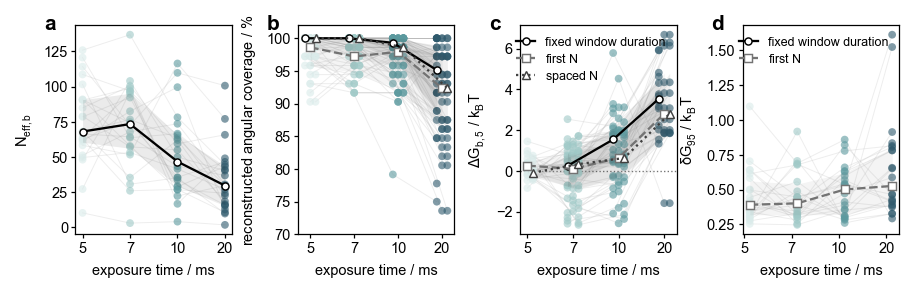

In [143]:
fig = plot_SI_target_exposure_summary(
    m_list=m_list,
    target_particles=selected_target_rotors,
    exposure_time_colors=target_exposure_time_colors,

    exposures_ms=(5, 7, 10, 20),
    reference_exposure_ms=5,

    comparison_sample_modes=("first_n", "spaced_n"),
    uncertainty_sample_mode="first_n",

    equal_sample_uncertainty_mode="target_only",
    fixed_window_uncertainty_mode="target_only",

    barrier_quantile=0.75,
    barrier_halfwidth_deg=30,
    min_locs_per_window=30,

    smooth_bins=3,
    feature_min_separation_deg=70,
    min_valid_bins=8,

    fig_width_mm=180,
    fig_height_mm=46,

    C=CK_colors,
    save_dir=save_dir_SI,
    save_prefix="SI_toFig3_exposure_time__target_rotors_stats",
    stator_variant=stator_variant,

    verbose=True,
)

#### v. SI | Rotor gallery for normal reconstruction

In [90]:
def plot_MBAR_sampling_time_target_gallery(
    m_list,
    particles=None,
    n_rotors=24,
    sampling_time_order_ms=(5, 7, 10, 20),
    sampling_time_colors=None,
    center_mode="ensemble",
    bias_potential="cosine",
    show_diff=True,
    smoothing_bins=3,
    ncols=4,
    panel_width_mm=36,
    panel_height_mm=28,
    shared_ylim=False,
    energy_ylim=None,
    energy_tick_spacing_kBT=4.0,
    fixed_lw=1.25,
    reference_lw=1.0,
    fontsize=7,
    tick_fontsize=5.8,
    axis_label_size=7,
    legend_fontsize=5.8,
    diff_pmin=1e-12,
    diff_hist_bins=None,
    C=CK_colors,
    save_dir=None,
    save_prefix="SI_toFig3_sampling_time__reconstruction_gallery",
    stator_variant=None,
    dpi=300,
):
    import math
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path

    C = C() if callable(C) else dict(C)
    black = C.get("black", (0, 0, 0))

    if sampling_time_colors is None:
        sampling_time_colors = {
            5:  (190/255, 220/255, 218/255),
            7:  (137/255, 188/255, 188/255),
            10: (82/255, 143/255, 153/255),
            20: (46/255, 89/255, 108/255),
        }

    sampling_time_order_ms = tuple(float(x) for x in sampling_time_order_ms)
    sampling_time_colors = {float(k): tuple(v) for k, v in sampling_time_colors.items()}

    def flatten(values):
        if values is None:
            return []
        if isinstance(values, (list, tuple)):
            return [item for value in values for item in flatten(value)]
        return [values]

    def mm(value):
        return float(value)/25.4

    def wrap_pi(values):
        values = np.asarray(values, float)
        return (values + np.pi) % (2*np.pi) - np.pi

    def zero_min(values):
        values = np.asarray(values, float).copy()
        finite = np.isfinite(values)
        if np.any(finite):
            values[finite] -= np.nanmin(values[finite])
        return values

    def smooth_nan_segments(values, width):
        """
        Smooth only within contiguous finite regions.

        NaN bins remain NaN and smoothing never bridges a gap.
        """
        values = np.asarray(values, float)
        width = int(width)

        if width <= 1:
            return values.copy()
        if width % 2 == 0:
            width += 1

        out = values.copy()
        finite = np.isfinite(values)

        d = np.diff(np.r_[False, finite, False].astype(int))
        starts = np.flatnonzero(d == 1)
        stops = np.flatnonzero(d == -1)

        half = width//2
        kernel = np.ones(width, float)/width

        for i0, i1 in zip(starts, stops):
            segment = values[i0:i1]

            if len(segment) < 2:
                continue

            padded = np.pad(segment, (half, half), mode="edge")
            out[i0:i1] = np.convolve(padded, kernel, mode="valid")[:len(segment)]

        return out

    def measurement_name(m):
        return Path(str(getattr(m, "path", "measurement"))).name

    def is_diff_measurement(m):
        return "DIFF" in measurement_name(m).upper()

    def is_umb_measurement(m):
        name = measurement_name(m).upper()
        return "UMB" in name and "DIFF" not in name

    def parse_sampling_time_ms(m):
        tpf = getattr(m, "_average_tpf", None)

        if tpf is not None:
            try:
                tpf = float(tpf)
                if np.isfinite(tpf) and tpf > 0:
                    return 1000.0*tpf
            except (TypeError, ValueError):
                pass

        match = re.search(r"(\d+(?:\.\d+)?)\s*ms", measurement_name(m), flags=re.IGNORECASE)
        return float(match.group(1)) if match else None

    def matching_time(value):
        if value is None or not np.isfinite(value):
            return None

        allowed = np.asarray(sampling_time_order_ms, float)
        nearest = float(allowed[np.argmin(np.abs(allowed-float(value)))])

        if np.isclose(nearest, float(value), atol=0.08, rtol=0.015):
            return nearest

        return None

    def measurement_fov_key(m):
        """
        Extract a FOV identifier such as:
            260718-fov02
        from the filename/path.

        Falls back to plain fovXX if no leading date is found.
        """
        name = measurement_name(m)

        match = re.search(r"(\d{6,8}[-_]?fov\d+)", name, flags=re.IGNORECASE)
        if match:
            return match.group(1).lower().replace("_", "-")

        match = re.search(r"(fov\d+)", name, flags=re.IGNORECASE)
        if match:
            return match.group(1).lower()

        return None

    def get_landscape(entry):
        if entry is None:
            return None

        if isinstance(entry, dict):
            phi = entry.get("phi", entry.get("centers", entry.get("phi_rad")))
            energy = entry.get(
                "U_mbar",
                entry.get(
                    "U_MBAR",
                    entry.get(
                        "U_wham",
                        entry.get("U", entry.get("E", entry.get("energy_kBT"))),
                    ),
                ),
            )

        elif isinstance(entry, pd.DataFrame):
            if "phi" in entry.columns:
                phi = entry["phi"].to_numpy(float)
            elif "centers" in entry.columns:
                phi = entry["centers"].to_numpy(float)
            else:
                return None

            if "U_mbar" in entry.columns:
                energy = entry["U_mbar"].to_numpy(float)
            elif "U_MBAR" in entry.columns:
                energy = entry["U_MBAR"].to_numpy(float)
            elif "U_wham" in entry.columns:
                energy = entry["U_wham"].to_numpy(float)
            elif "E" in entry.columns:
                energy = entry["E"].to_numpy(float)
            else:
                return None

        else:
            return None

        if phi is None or energy is None:
            return None

        phi = np.asarray(phi, float)
        energy = np.asarray(energy, float)

        if phi.size != energy.size:
            return None

        keep = np.isfinite(phi)
        phi = wrap_pi(phi[keep])
        energy = energy[keep]

        order = np.argsort(phi)
        phi = phi[order]
        energy = energy[order]

        energy = smooth_nan_segments(energy, smoothing_bins)
        energy = zero_min(energy)

        return phi, energy

    def read_reconstructions(m):
        try:
            stored = m.reconstructed_energy_landscapes_by_center[center_mode][bias_potential]
        except Exception:
            return {}

        output = {}

        for particle, entry in stored.items():
            landscape = get_landscape(entry)
            if landscape is not None:
                output[int(particle)] = landscape

        return output

    def find_matching_diff(umb_measurements, diff_measurements):
        """
        Find the DIFF measurement belonging to the same FOV as the UMB
        measurements contributing to this rotor panel.
        """
        umb_keys = [
            measurement_fov_key(m)
            for m in umb_measurements
            if measurement_fov_key(m) is not None
        ]

        if not umb_keys:
            return None

        # All sampling-time measurements for one rotor should normally
        # belong to the same FOV.
        unique_keys = list(dict.fromkeys(umb_keys))

        for key in unique_keys:
            matches = [
                m_diff
                for m_diff in diff_measurements
                if measurement_fov_key(m_diff) == key
            ]

            if matches:
                return matches[0]

        return None

    def diff_boltzmann_curve(m_diff, particle, n_bins):
        """
        Boltzmann landscape from ONE matching DIFF measurement.

        Critically:
        counts == 0 -> energy == NaN

        Those NaNs are retained after smoothing.
        """
        if m_diff is None:
            return None

        locs = getattr(m_diff, "locs", None)

        if not isinstance(locs, pd.DataFrame) or "phi" not in locs.columns:
            return None

        if "group_int" in locs.columns:
            particle_column = "group_int"
        elif "group" in locs.columns:
            particle_column = "group"
        else:
            return None

        phi = locs.loc[
            locs[particle_column].astype(int) == int(particle),
            "phi",
        ].to_numpy(float)

        phi = wrap_pi(phi[np.isfinite(phi)])

        if phi.size == 0:
            return None

        if diff_hist_bins is not None:
            n_bins = int(diff_hist_bins)

        edges = np.linspace(-np.pi, np.pi, int(n_bins)+1)
        centers = 0.5*(edges[:-1] + edges[1:])

        counts, _ = np.histogram(phi, bins=edges)
        counts = counts.astype(float)

        energy = np.full(counts.size, np.nan, dtype=float)
        sampled = counts > 0

        if not np.any(sampled):
            return None

        # Probability density; normalization constant does not affect G
        bin_width = float(edges[1] - edges[0])
        probability = counts/(np.sum(counts)*bin_width)

        energy[sampled] = -np.log(
            np.maximum(probability[sampled], float(diff_pmin))
        )

        # Smooth only within sampled contiguous regions.
        energy = smooth_nan_segments(energy, smoothing_bins)

        # Absolute safeguard: unsampled raw bins MUST remain NaN.
        energy[~sampled] = np.nan

        energy = zero_min(energy)

        return {
            "phi": centers,
            "energy": energy,
            "counts": counts,
            "n_locs": int(phi.size),
            "measurement": m_diff,
        }

    def style_axis(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color(black)

        ax.tick_params(
            length=2,
            width=0.6,
            direction="out",
            pad=1.4,
            labelsize=tick_fontsize,
        )

        ax.grid(False)

    # ------------------------------------------------------------------
    # Measurements grouped by sampling time
    # ------------------------------------------------------------------
    measurements = flatten(m_list)
    diff_measurements = [m for m in measurements if is_diff_measurement(m)]

    by_time = {time_ms: [] for time_ms in sampling_time_order_ms}

    for m in measurements:
        if not is_umb_measurement(m):
            continue

        sampling_time_ms = matching_time(parse_sampling_time_ms(m))

        if sampling_time_ms is None:
            continue

        reconstructions = read_reconstructions(m)

        if not reconstructions:
            continue

        by_time[sampling_time_ms].append({
            "measurement": m,
            "reconstructions": reconstructions,
        })

    missing = [t for t in sampling_time_order_ms if not by_time[t]]

    if missing:
        print(f"Warning: missing sampling times: {[f'{x:g} ms' for x in missing]}")

    # ------------------------------------------------------------------
    # Common target rotors
    # ------------------------------------------------------------------
    available_sets = []

    for time_ms in sampling_time_order_ms:
        records = by_time[time_ms]

        if not records:
            continue

        particles_this_time = set()

        for record in records:
            target = set(map(int, getattr(record["measurement"], "target_rotors", [])))
            reconstructed = set(map(int, record["reconstructions"].keys()))

            if target:
                reconstructed &= target

            particles_this_time |= reconstructed

        available_sets.append(particles_this_time)

    if not available_sets:
        raise ValueError("No valid target-rotor reconstructions found.")

    available = sorted(set.intersection(*available_sets))

    if particles is not None:
        requested = [int(particle) for particle in particles]
        available_set = set(available)
        available = [particle for particle in requested if particle in available_set]

    if n_rotors is not None:
        available = available[:int(n_rotors)]

    if not available:
        raise ValueError(
            "No common target rotors were found across the requested sampling times."
        )

    # ------------------------------------------------------------------
    # Prepare curves and associate each rotor with its actual UMB/FOV
    # ------------------------------------------------------------------
    plot_data = {}
    all_curves = []

    for particle in available:
        sampling_curves = {}
        source_measurements = []

        for time_ms in sampling_time_order_ms:
            for record in by_time[time_ms]:
                if particle not in record["reconstructions"]:
                    continue

                sampling_curves[time_ms] = record["reconstructions"][particle]
                source_measurements.append(record["measurement"])
                all_curves.append(record["reconstructions"][particle][1])
                break

        reference = next(iter(sampling_curves.values()), None)

        matching_diff = (
            find_matching_diff(source_measurements, diff_measurements)
            if show_diff
            else None
        )

        diff = (
            diff_boltzmann_curve(
                matching_diff,
                particle,
                len(reference[0]),
            )
            if reference is not None and matching_diff is not None
            else None
        )

        if diff is not None:
            all_curves.append(diff["energy"])

        plot_data[particle] = {
            "sampling_times": sampling_curves,
            "source_measurements": source_measurements,
            "diff": diff,
        }

    # ------------------------------------------------------------------
    # Figure layout
    # ------------------------------------------------------------------
    ncols = min(max(1, int(ncols)), len(available))
    nrows = math.ceil(len(available)/ncols)

    if shared_ylim and energy_ylim is None:
        finite_values = [
            curve[np.isfinite(curve)]
            for curve in all_curves
            if np.any(np.isfinite(curve))
        ]

        if finite_values:
            finite_values = np.concatenate(finite_values)
            ymax = max(np.nanmax(finite_values), energy_tick_spacing_kBT)

            shared_energy_ylim = (
                -0.45,
                math.ceil(ymax/energy_tick_spacing_kBT)*energy_tick_spacing_kBT,
            )
        else:
            shared_energy_ylim = None
    else:
        shared_energy_ylim = energy_ylim

    plt.rcParams.update({
        "font.size": fontsize,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.linewidth": 0.6,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(mm(panel_width_mm*ncols), mm(panel_height_mm*nrows)),
        squeeze=False,
    )

    # ------------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------------
    for index, (ax, particle) in enumerate(zip(axes.flat, available)):
        row = index//ncols
        col = index%ncols
        curves_here = []

        for zorder, time_ms in enumerate(sampling_time_order_ms):
            landscape = plot_data[particle]["sampling_times"].get(time_ms)

            if landscape is None:
                continue

            phi, energy = landscape

            ax.plot(
                phi,
                energy,
                color=sampling_time_colors.get(time_ms, (0.5, 0.5, 0.5)),
                lw=fixed_lw,
                label=f"{time_ms:g} ms",
                zorder=3+zorder,
            )

            curves_here.append(energy)

        diff = plot_data[particle]["diff"]

        if diff is not None:
            ax.plot(
                diff["phi"],
                diff["energy"],
                color=black,
                lw=reference_lw,
                ls="--",
                label="diffusion",
                zorder=10,
            )

            curves_here.append(diff["energy"])

        ax.set_xlim(-np.pi, np.pi)
        ax.set_xticks([-np.pi, 0, np.pi])

        if row == nrows-1:
            ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"])
            ax.set_xlabel(r"$\varphi$ / rad", fontsize=axis_label_size)
        else:
            ax.set_xticklabels([])

        if col == 0:
            ax.set_ylabel(
                r"$G(\varphi)$ / $k_\mathrm{B}T$",
                fontsize=axis_label_size,
            )
        else:
            ax.set_yticklabels([])

        if shared_energy_ylim is not None:
            ax.set_ylim(*shared_energy_ylim)

        elif curves_here:
            finite_here = [
                curve[np.isfinite(curve)]
                for curve in curves_here
                if np.any(np.isfinite(curve))
            ]

            if finite_here:
                finite_here = np.concatenate(finite_here)
                ymax = max(np.nanmax(finite_here), energy_tick_spacing_kBT)

                ax.set_ylim(
                    -0.45,
                    math.ceil(ymax/energy_tick_spacing_kBT)*energy_tick_spacing_kBT,
                )

        y0, y1 = ax.get_ylim()

        yticks = np.arange(
            0,
            y1 + 0.5*energy_tick_spacing_kBT,
            energy_tick_spacing_kBT,
        )

        ax.set_yticks(
            yticks[(yticks >= y0) & (yticks <= y1)]
        )

        style_axis(ax)

    for ax in axes.flat[len(available):]:
        ax.axis("off")

    # ------------------------------------------------------------------
    # Legend
    # ------------------------------------------------------------------
    handles = []

    for time_ms in sampling_time_order_ms:
        if not by_time[time_ms]:
            continue

        handles.append(
            plt.Line2D(
                [],
                [],
                color=sampling_time_colors.get(time_ms, (0.5, 0.5, 0.5)),
                lw=fixed_lw,
                label=f"{time_ms:g} ms",
            )
        )

    if show_diff and diff_measurements:
        handles.append(
            plt.Line2D(
                [],
                [],
                color=black,
                lw=reference_lw,
                ls="--",
                label="diffusion",
            )
        )

    if handles:
        axes.flat[0].legend(
            handles=handles,
            frameon=False,
            fontsize=legend_fontsize,
            handlelength=1.7,
            labelspacing=0.22,
            loc="upper left",
        )

    fig.subplots_adjust(
        left=0.07,
        right=0.99,
        bottom=0.06,
        top=0.98,
        wspace=0.20,
        hspace=0.28,
    )

    # ------------------------------------------------------------------
    # Save
    # ------------------------------------------------------------------
    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        prefix = (
            f"{stator_variant}__{save_prefix}"
            if stator_variant
            else save_prefix
        )

        fig.savefig(
            save_dir/f"{prefix}.png",
            dpi=dpi,
            bbox_inches="tight",
        )

        fig.savefig(
            save_dir/f"{prefix}.svg",
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)

    return available

In [118]:
# selected_target_rotors = [4,0,1,5,7,12,11,16,27,28,35,37,39,44,56,67,68,93,96,101,113,135,178,158,175]
# selected_target_rotors = [0,1,7,27,28,35,37,39,44,52,56,61,67,68,93,96,101,113,137,144,155,158,4,175]

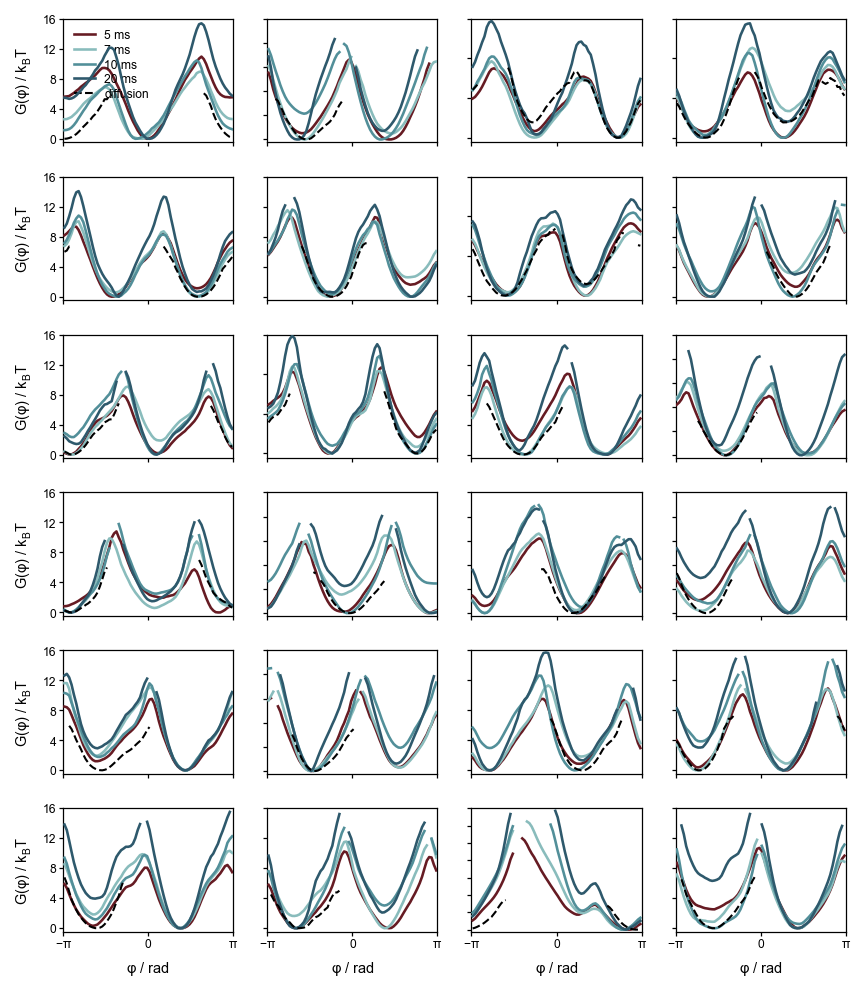

In [139]:
gallery_particles = plot_MBAR_sampling_time_target_gallery(
    m_list=m_list,
    particles=selected_target_rotors,
    n_rotors=24,
    sampling_time_order_ms=(5, 7, 10, 20),
    sampling_time_colors={
        5:  (102 / 255, 27 / 255, 35 / 255),
        7:  (137 / 255, 188 / 255, 188 / 255),
        10: (82 / 255, 143 / 255, 153 / 255),
        20: (46 / 255, 89 / 255, 108 / 255),
    },
    center_mode="ensemble",
    bias_potential="cosine",
    show_diff=True,
    smoothing_bins=3,
    ncols=4,
    panel_width_mm=36,
    panel_height_mm=28,
    shared_ylim=False,
    energy_ylim=None,
    energy_tick_spacing_kBT=4.0,
    fixed_lw=1.25,
    reference_lw=1.0,
    save_dir=save_dir_SI,
    stator_variant=None,
    save_prefix="SI_toFig3_exposure_time__reconstruction_gallery",
)

#### v. SI | Rotor gallery for reconstruction based on same number of datapoints

In [136]:
def plot_MBAR_sampling_time_target_gallery__equal_datapoints(
    m_list,
    particles=None,
    n_rotors=24,
    sample_mode="spaced_n",
    sampling_time_order_ms=(5, 7, 10, 20),
    reference_sampling_time_ms=5,
    sampling_time_colors=None,
    center_mode="ensemble",
    bias_potential="cosine",
    show_diff=True,
    smoothing_bins=3,
    ncols=4,
    panel_width_mm=36,
    panel_height_mm=28,
    shared_ylim=False,
    energy_ylim=None,
    energy_tick_spacing_kBT=4.0,
    fixed_lw=1.25,
    equal_sample_lw=1.10,
    reference_lw=1.0,
    fontsize=7,
    tick_fontsize=5.8,
    axis_label_size=7,
    legend_fontsize=5.8,
    diff_pmin=1e-12,
    diff_hist_bins=None,
    C=CK_colors,
    save_dir=None,
    save_prefix="SI_toFig3_sampling_time__reconstruction_gallery_equal_datapoints",
    stator_variant=None,
    dpi=300,
):
    import math
    import re
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pathlib import Path

    C = C() if callable(C) else dict(C)
    black = C.get("black", (0, 0, 0))
    reference_color = (102 / 255, 27 / 255, 35 / 255)
    grey = C.get("grey", (0.5, 0.5, 0.5))
    midgrey = C.get("midgrey", (0.65, 0.65, 0.65))

    if sampling_time_colors is None:
        sampling_time_colors = {
            5:  (190/255, 220/255, 218/255),
            7:  (137/255, 188/255, 188/255),
            10: (82/255, 143/255, 153/255),
            20: (46/255, 89/255, 108/255),
        }

    def rgb(value):
        value = np.asarray(value, float).ravel()[:3]
        return tuple(value / 255 if np.nanmax(value) > 1 else value)

    black = rgb(black)
    reference_color = rgb(reference_color)
    grey = rgb(grey)
    midgrey = rgb(midgrey)

    sample_mode = str(sample_mode).lower()
    if sample_mode not in {"first_n", "spaced_n"}:
        raise ValueError("sample_mode must be 'first_n' or 'spaced_n'.")

    sampling_time_order_ms = tuple(float(x) for x in sampling_time_order_ms)
    reference_sampling_time_ms = float(reference_sampling_time_ms)
    sampling_time_colors = {float(k): rgb(v) for k, v in sampling_time_colors.items()}

    if reference_sampling_time_ms not in sampling_time_order_ms:
        raise ValueError(
            f"reference_sampling_time_ms={reference_sampling_time_ms:g} must be present "
            f"in sampling_time_order_ms={sampling_time_order_ms}."
        )

    def flatten(values):
        if values is None:
            return []
        if isinstance(values, (list, tuple)):
            return [item for value in values for item in flatten(value)]
        return [values]

    def mm(value):
        return float(value) / 25.4

    def wrap_pi(values):
        values = np.asarray(values, float)
        return (values + np.pi) % (2 * np.pi) - np.pi

    def zero_min(values):
        values = np.asarray(values, float).copy()
        finite = np.isfinite(values)
        if np.any(finite):
            values[finite] -= np.nanmin(values[finite])
        return values

    def smooth_nan_segments(values, width):
        values = np.asarray(values, float)
        width = int(width)

        if width <= 1:
            return values.copy()

        if width % 2 == 0:
            width += 1

        out = values.copy()
        finite = np.isfinite(values)
        d = np.diff(np.r_[False, finite, False].astype(int))
        starts = np.flatnonzero(d == 1)
        stops = np.flatnonzero(d == -1)

        half = width // 2
        kernel = np.ones(width, float) / width

        for i0, i1 in zip(starts, stops):
            segment = values[i0:i1]
            if len(segment) < 2:
                continue

            padded = np.pad(segment, (half, half), mode="edge")
            out[i0:i1] = np.convolve(padded, kernel, mode="valid")[:len(segment)]

        out[~finite] = np.nan
        return out

    def measurement_name(m):
        return Path(str(getattr(m, "path", "measurement"))).name

    def is_diff_measurement(m):
        name = measurement_name(m).upper()
        return "DIFF" in name and "PSEUDO_DIFF" not in name

    def is_umb_measurement(m):
        name = measurement_name(m).upper()
        protocol = getattr(m, "protocol", None)
        return (
            not is_diff_measurement(m)
            and (
                "UMB" in name
                or (
                    isinstance(protocol, dict)
                    and any(str(key).startswith("deg-") for key in protocol)
                )
            )
        )

    def parse_sampling_time_ms(m):
        tpf = getattr(m, "_average_tpf", None)

        if tpf is not None:
            try:
                tpf = float(tpf)
                if np.isfinite(tpf) and tpf > 0:
                    return 1000.0 * tpf
            except (TypeError, ValueError):
                pass

        match = re.search(
            r"(\d+(?:\.\d+)?)\s*ms",
            measurement_name(m),
            flags=re.IGNORECASE,
        )

        return float(match.group(1)) if match else None

    def matching_time(value):
        if value is None or not np.isfinite(value):
            return None

        allowed = np.asarray(sampling_time_order_ms, float)
        nearest = float(allowed[np.argmin(np.abs(allowed - float(value)))])

        return nearest if np.isclose(nearest, float(value), atol=0.08, rtol=0.015) else None

    def measurement_fov_key(m):
        name = measurement_name(m)

        match = re.search(
            r"(\d{6,8}[-_]?fov\d+)",
            name,
            flags=re.IGNORECASE,
        )

        if match:
            return match.group(1).lower().replace("_", "-")

        match = re.search(
            r"(fov\d+)",
            name,
            flags=re.IGNORECASE,
        )

        return match.group(1).lower() if match else None

    def get_landscape(entry):
        if entry is None:
            return None

        if isinstance(entry, pd.DataFrame):
            phi_col = next(
                (col for col in ("phi", "phi_rad", "centers") if col in entry.columns),
                None,
            )
            energy_col = next(
                (
                    col
                    for col in (
                        "U_mbar",
                        "U_MBAR",
                        "U_wham",
                        "U",
                        "E",
                        "energy",
                        "energy_kBT",
                    )
                    if col in entry.columns
                ),
                None,
            )

            if phi_col is None or energy_col is None:
                return None

            phi = entry[phi_col].to_numpy(float)
            energy = entry[energy_col].to_numpy(float)

        elif isinstance(entry, dict):
            phi = entry.get(
                "phi",
                entry.get(
                    "centers",
                    entry.get("phi_rad"),
                ),
            )

            energy = entry.get(
                "U_mbar",
                entry.get(
                    "U_MBAR",
                    entry.get(
                        "U_wham",
                        entry.get(
                            "U",
                            entry.get(
                                "E",
                                entry.get(
                                    "energy",
                                    entry.get("energy_kBT"),
                                ),
                            ),
                        ),
                    ),
                ),
            )

        else:
            return None

        if phi is None or energy is None:
            return None

        phi = np.asarray(phi, float)
        energy = np.asarray(energy, float)

        if phi.size != energy.size:
            return None

        keep = np.isfinite(phi)
        phi = wrap_pi(phi[keep])
        energy = energy[keep]

        order = np.argsort(phi)
        phi = phi[order]
        energy = energy[order]

        energy = smooth_nan_segments(energy, smoothing_bins)
        energy = zero_min(energy)

        return phi, energy

    def read_equal_sample_reconstructions(m):
        store = getattr(m, "mbar_reconstructions", None)

        if not isinstance(store, dict) or sample_mode not in store:
            return {}

        mode_store = store[sample_mode]

        # Preferred stored hierarchy.
        try:
            stored = mode_store["by_center"][center_mode][bias_potential]
        except Exception:
            stored = None

        # Fallback used by newer lean storage.
        if not isinstance(stored, dict):
            stored = mode_store.get("energy_landscapes", {})

        if not isinstance(stored, dict):
            return {}

        output = {}

        for particle, entry in stored.items():
            landscape = get_landscape(entry)

            if landscape is not None:
                output[int(particle)] = landscape

        return output

    def read_fixed_window_reconstructions(m):
        stores = [
            getattr(m, "energy_landscapes", None),
            getattr(m, "reconstructed_energy_landscapes", None),
        ]

        for store in stores:
            if not isinstance(store, dict) or not store:
                continue

            output = {}

            for particle, entry in store.items():
                landscape = get_landscape(entry)

                if landscape is not None:
                    output[int(particle)] = landscape

            if output:
                return output

        return {}

    def find_matching_diff(umb_measurements, diff_measurements):
        umb_keys = [
            measurement_fov_key(m)
            for m in umb_measurements
            if measurement_fov_key(m) is not None
        ]

        for key in dict.fromkeys(umb_keys):
            matches = [
                m_diff
                for m_diff in diff_measurements
                if measurement_fov_key(m_diff) == key
            ]

            if matches:
                return matches[0]

        return None

    def diff_boltzmann_curve(m_diff, particle, n_bins):
        if m_diff is None:
            return None

        locs = getattr(m_diff, "locs", None)

        if not isinstance(locs, pd.DataFrame) or "phi" not in locs.columns:
            return None

        if "group_int" in locs.columns:
            particle_column = "group_int"
        elif "group" in locs.columns:
            particle_column = "group"
        else:
            return None

        phi = locs.loc[
            locs[particle_column].astype(int) == int(particle),
            "phi",
        ].to_numpy(float)

        phi = wrap_pi(phi[np.isfinite(phi)])

        if phi.size == 0:
            return None

        if diff_hist_bins is not None:
            n_bins = int(diff_hist_bins)

        edges = np.linspace(-np.pi, np.pi, int(n_bins) + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])
        counts, _ = np.histogram(phi, bins=edges)
        counts = counts.astype(float)

        energy = np.full(counts.size, np.nan)
        sampled = counts > 0

        if not np.any(sampled):
            return None

        bin_width = float(edges[1] - edges[0])
        probability = counts / (np.sum(counts) * bin_width)

        energy[sampled] = -np.log(
            np.maximum(
                probability[sampled],
                float(diff_pmin),
            )
        )

        energy = smooth_nan_segments(
            energy,
            smoothing_bins,
        )

        energy[~sampled] = np.nan
        energy = zero_min(energy)

        return {
            "phi": centers,
            "energy": energy,
            "counts": counts,
            "n_locs": int(phi.size),
            "measurement": m_diff,
        }

    def style_axis(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color(black)

        ax.tick_params(
            length=2,
            width=0.6,
            direction="out",
            pad=1.4,
            labelsize=tick_fontsize,
        )

        ax.grid(False)

    # ------------------------------------------------------------------
    # Collect measurements
    # ------------------------------------------------------------------
    measurements = flatten(m_list)

    diff_measurements = [
        m
        for m in measurements
        if is_diff_measurement(m)
    ]

    by_time = {
        time_ms: []
        for time_ms in sampling_time_order_ms
    }

    for m in measurements:
        if not is_umb_measurement(m):
            continue

        sampling_time_ms = matching_time(
            parse_sampling_time_ms(m)
        )

        if sampling_time_ms is None:
            continue

        equal_reconstructions = read_equal_sample_reconstructions(m)
        fixed_reconstructions = read_fixed_window_reconstructions(m)

        by_time[sampling_time_ms].append({
            "measurement": m,
            "equal_reconstructions": equal_reconstructions,
            "fixed_reconstructions": fixed_reconstructions,
        })

    missing = [
        time_ms
        for time_ms in sampling_time_order_ms
        if not any(
            record["equal_reconstructions"]
            for record in by_time[time_ms]
        )
    ]

    if missing:
        print(
            "Warning: missing equal-datapoint reconstructions: "
            f"{[f'{x:g} ms' for x in missing]}"
        )

    if not by_time[reference_sampling_time_ms]:
        raise ValueError(
            f"No {reference_sampling_time_ms:g} ms UMB measurement found."
        )

    # ------------------------------------------------------------------
    # Determine particles for which equal-N data exist.
    # Use UNION as in the original function.
    # ------------------------------------------------------------------
    available_sets = []

    for time_ms in sampling_time_order_ms:
        records = by_time[time_ms]

        particles_this_time = set()

        for record in records:
            reconstructed = set(
                map(
                    int,
                    record["equal_reconstructions"].keys(),
                )
            )

            target = set(
                map(
                    int,
                    getattr(
                        record["measurement"],
                        "target_rotors",
                        [],
                    ),
                )
            )

            if target:
                reconstructed &= target

            particles_this_time |= reconstructed

        if particles_this_time:
            available_sets.append(
                particles_this_time
            )

    if not available_sets:
        raise ValueError(
            f"No target-rotor reconstructions found in "
            f"m.mbar_reconstructions[{sample_mode!r}]."
        )

    available = sorted(
        set.union(*available_sets)
    )

    if particles is not None:
        requested = [
            int(particle)
            for particle in particles
        ]

        available_set = set(available)

        available = [
            particle
            for particle in requested
            if particle in available_set
        ]

    # Require a genuine 5-ms full-window reference.
    reference_available = set()

    for record in by_time[reference_sampling_time_ms]:
        reference_available |= set(
            map(
                int,
                record["fixed_reconstructions"].keys(),
            )
        )

    available = [
        particle
        for particle in available
        if particle in reference_available
    ]

    if n_rotors is not None:
        available = available[
            :int(n_rotors)
        ]

    if not available:
        raise ValueError(
            "None of the requested target rotors has both an "
            f"{sample_mode!r} reconstruction and a "
            f"{reference_sampling_time_ms:g} ms full-window reconstruction."
        )

    # ------------------------------------------------------------------
    # Gather:
    #
    # reference:
    #   5 ms FULL WINDOW
    #
    # controls:
    #   5 ms spaced-N
    #   7 ms spaced-N
    #   10 ms spaced-N
    #   20 ms spaced-N
    #
    # optional:
    #   DIFF
    # ------------------------------------------------------------------
    plot_data = {}
    all_curves = []

    for particle in available:
        equal_sample_curves = {}
        source_measurements = []

        # Equal-N / spaced-N curves for every exposure time.
        for time_ms in sampling_time_order_ms:
            for record in by_time[time_ms]:
                landscape = record[
                    "equal_reconstructions"
                ].get(
                    particle
                )

                if landscape is None:
                    continue

                equal_sample_curves[
                    time_ms
                ] = landscape

                source_measurements.append(
                    record["measurement"]
                )

                all_curves.append(
                    landscape[1]
                )

                break

        # FULL 5-ms reference.
        fixed_reference = None
        reference_measurement = None

        for record in by_time[
            reference_sampling_time_ms
        ]:
            landscape = record[
                "fixed_reconstructions"
            ].get(
                particle
            )

            if landscape is None:
                continue

            fixed_reference = landscape
            reference_measurement = record[
                "measurement"
            ]

            all_curves.append(
                landscape[1]
            )

            break

        if fixed_reference is None:
            continue

        if reference_measurement is not None:
            source_measurements.append(
                reference_measurement
            )

        matching_diff = (
            find_matching_diff(
                source_measurements,
                diff_measurements,
            )
            if show_diff
            else None
        )

        diff = (
            diff_boltzmann_curve(
                matching_diff,
                particle,
                len(fixed_reference[0]),
            )
            if matching_diff is not None
            else None
        )

        if diff is not None:
            all_curves.append(
                diff["energy"]
            )

        plot_data[particle] = {
            "fixed_reference": fixed_reference,
            "sampling_times": equal_sample_curves,
            "diff": diff,
        }

    available = [
        particle
        for particle in available
        if particle in plot_data
    ]

    if not available:
        raise ValueError(
            f"No particle has a valid "
            f"{reference_sampling_time_ms:g} ms full-window reference."
        )

    # ------------------------------------------------------------------
    # Figure setup
    # ------------------------------------------------------------------
    ncols = min(
        max(
            1,
            int(ncols),
        ),
        len(available),
    )

    nrows = math.ceil(
        len(available) / ncols
    )

    if shared_ylim and energy_ylim is None:
        finite_values = [
            curve[np.isfinite(curve)]
            for curve in all_curves
            if np.any(np.isfinite(curve))
        ]

        if finite_values:
            finite_values = np.concatenate(
                finite_values
            )

            ymax = max(
                np.nanmax(finite_values),
                energy_tick_spacing_kBT,
            )

            shared_energy_ylim = (
                -0.45,
                math.ceil(
                    ymax / energy_tick_spacing_kBT
                ) * energy_tick_spacing_kBT,
            )

        else:
            shared_energy_ylim = None

    else:
        shared_energy_ylim = energy_ylim

    plt.rcParams.update({
        "font.size": fontsize,
        "font.family": "sans-serif",
        "font.sans-serif": [
            "Arial",
            "DejaVu Sans",
        ],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Arial",
        "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold",
        "axes.linewidth": 0.6,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(
            mm(panel_width_mm * ncols),
            mm(panel_height_mm * nrows),
        ),
        squeeze=False,
    )

    # ------------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------------
    for index, (ax, particle) in enumerate(
        zip(
            axes.flat,
            available,
        )
    ):
        row = index // ncols
        col = index % ncols
        curves_here = []

        # --------------------------------------------------------------
        # 5-ms FULL-WINDOW reference
        # --------------------------------------------------------------
        phi_ref, energy_ref = plot_data[
            particle
        ][
            "fixed_reference"
        ]

        ax.plot(
            phi_ref,
            energy_ref,
            color=reference_color,
            lw=fixed_lw,
            ls="-",
            label=f"{reference_sampling_time_ms:g} ms full window",
            zorder=20,
        )

        curves_here.append(
            energy_ref
        )

        # --------------------------------------------------------------
        # Equal-datapoint reconstructions:
        # 5 ms spaced N, 7 ms spaced N, ...
        # --------------------------------------------------------------
        for zorder, time_ms in enumerate(
            sampling_time_order_ms
        ):
            landscape = plot_data[
                particle
            ][
                "sampling_times"
            ].get(
                time_ms
            )

            if landscape is None:
                continue

            phi, energy = landscape

            ax.plot(
                phi,
                energy,
                color=sampling_time_colors.get(
                    time_ms,
                    grey,
                ),
                lw=equal_sample_lw,
                ls="-",
                label=f"{time_ms:g} ms {sample_mode.replace('_', ' ')}",
                zorder=3 + zorder,
            )

            curves_here.append(
                energy
            )

        # --------------------------------------------------------------
        # Independent diffusion reference
        # --------------------------------------------------------------
        diff = plot_data[
            particle
        ][
            "diff"
        ]

        if diff is not None:
            ax.plot(
                diff["phi"],
                diff["energy"],
                color=midgrey,
                lw=reference_lw,
                ls="--",
                label="diffusion",
                zorder=25,
            )

            curves_here.append(
                diff["energy"]
            )

        ax.set_xlim(
            -np.pi,
            np.pi,
        )

        ax.set_xticks([
            -np.pi,
            0,
            np.pi,
        ])

        if row == nrows - 1:
            ax.set_xticklabels([
                r"$-\pi$",
                "0",
                r"$\pi$",
            ])

            ax.set_xlabel(
                r"$\varphi$ / rad",
                fontsize=axis_label_size,
            )

        else:
            ax.set_xticklabels([])

        if col == 0:
            ax.set_ylabel(
                r"$G(\varphi)$ / $k_\mathrm{B}T$",
                fontsize=axis_label_size,
            )

        else:
            ax.set_yticklabels([])

        if shared_energy_ylim is not None:
            ax.set_ylim(
                *shared_energy_ylim
            )

        elif curves_here:
            finite_here = [
                curve[np.isfinite(curve)]
                for curve in curves_here
                if np.any(np.isfinite(curve))
            ]

            if finite_here:
                finite_here = np.concatenate(
                    finite_here
                )

                ymax = max(
                    np.nanmax(finite_here),
                    energy_tick_spacing_kBT,
                )

                ax.set_ylim(
                    -0.45,
                    math.ceil(
                        ymax / energy_tick_spacing_kBT
                    ) * energy_tick_spacing_kBT,
                )

        y0, y1 = ax.get_ylim()

        yticks = np.arange(
            0,
            y1 + 0.5 * energy_tick_spacing_kBT,
            energy_tick_spacing_kBT,
        )

        ax.set_yticks(
            yticks[
                (yticks >= y0)
                & (yticks <= y1)
            ]
        )

        style_axis(ax)

    for ax in axes.flat[
        len(available):
    ]:
        ax.axis("off")

    # ------------------------------------------------------------------
    # Legend:
    #
    # 5 ms full window
    # 5 ms spaced N
    # 7 ms spaced N
    # 10 ms spaced N
    # 20 ms spaced N
    # diffusion
    # ------------------------------------------------------------------
    handles = [
        plt.Line2D(
            [],
            [],
            color=reference_color,
            lw=fixed_lw,
            ls="-",
            label=f"{reference_sampling_time_ms:g} ms full window",
        )
    ]

    for time_ms in sampling_time_order_ms:
        has_data = any(
            time_ms
            in plot_data[
                particle
            ][
                "sampling_times"
            ]
            for particle in available
        )

        if not has_data:
            continue

        handles.append(
            plt.Line2D(
                [],
                [],
                color=sampling_time_colors.get(
                    time_ms,
                    grey,
                ),
                lw=equal_sample_lw,
                ls="-",
                label=f"{time_ms:g} ms {sample_mode.replace('_', ' ')}",
            )
        )

    if show_diff and any(
        plot_data[particle]["diff"] is not None
        for particle in available
    ):
        handles.append(
            plt.Line2D(
                [],
                [],
                color=midgrey,
                lw=reference_lw,
                ls="--",
                label="diffusion",
            )
        )

    if handles:
        axes.flat[0].legend(
            handles=handles,
            frameon=False,
            fontsize=legend_fontsize,
            handlelength=1.7,
            labelspacing=0.22,
            loc="upper left",
        )

    # Center an incomplete final row while keeping all panel sizes unchanged.
    n_last = len(available) % ncols
    if nrows > 1 and n_last:
        last_axes = list(axes.flat[(nrows - 1) * ncols:(nrows - 1) * ncols + n_last])
        first_row_positions = [axes[0, j].get_position() for j in range(ncols)]
        panel_w = first_row_positions[0].width
        cell_step = first_row_positions[1].x0 - first_row_positions[0].x0 if ncols > 1 else panel_w
        shift = 0.5 * (ncols - n_last) * cell_step
        for ax in last_axes:
            pos = ax.get_position()
            ax.set_position([pos.x0 + shift, pos.y0, pos.width, pos.height])

    fig.subplots_adjust(
        left=0.07,
        right=0.99,
        bottom=0.06,
        top=0.98,
        wspace=0.20,
        hspace=0.28,
    )

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(
            parents=True,
            exist_ok=True,
        )

        prefix = (
            f"{stator_variant}__{save_prefix}"
            if stator_variant
            else save_prefix
        )

        fig.savefig(
            save_dir / f"{prefix}.png",
            dpi=dpi,
            bbox_inches="tight",
        )

        fig.savefig(
            save_dir / f"{prefix}.svg",
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)

    return available

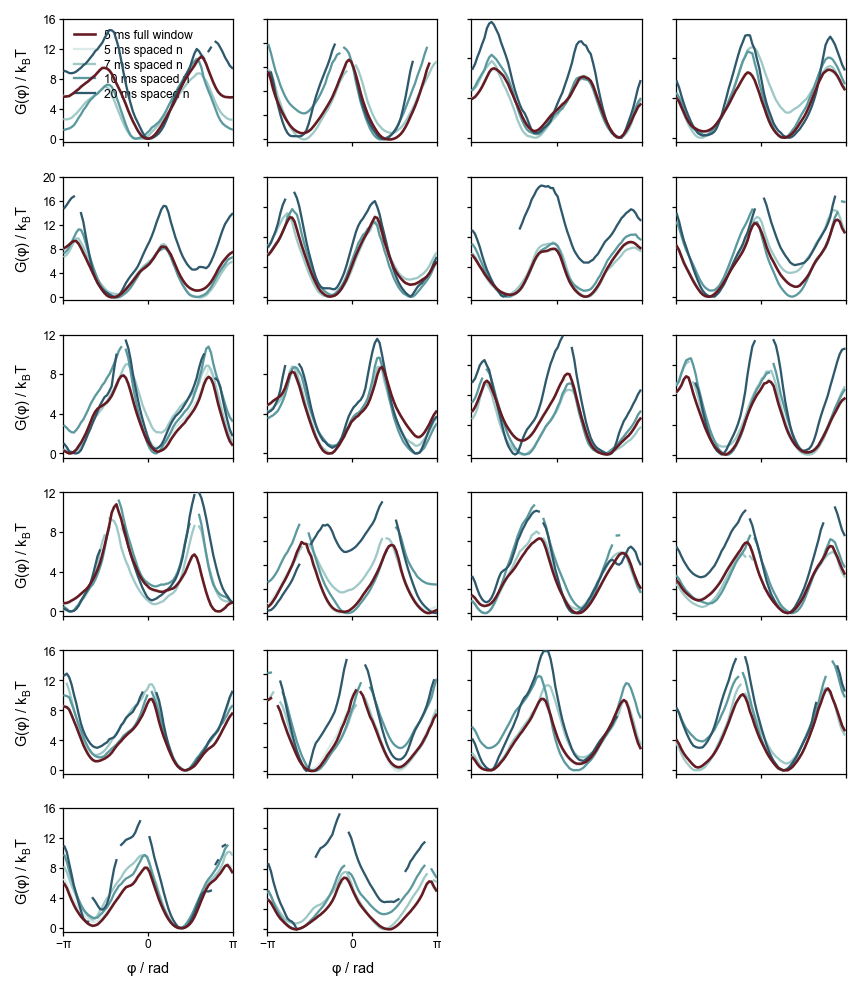

In [138]:
available = plot_MBAR_sampling_time_target_gallery__equal_datapoints(
    m_list=m_list,
    particles=selected_target_rotors,
    n_rotors=24,

    sample_mode="spaced_n",
    sampling_time_order_ms=(5, 7, 10, 20),
    reference_sampling_time_ms=5,
    sampling_time_colors=target_exposure_time_colors,

    show_diff=False,
    smoothing_bins=3,

    ncols=4,
    panel_width_mm=36,
    panel_height_mm=28,

    shared_ylim=False,
    energy_tick_spacing_kBT=4,

    C=CK_colors,
    save_dir=save_dir_SI,
    save_prefix="SI_toFig3_exposure_time__spacedN_vs_5ms_full",
    stator_variant=stator_variant,
)